# A Quadratic Horizon and a Doubling Barrier: Distribution-Free Limits on Extrapolating pass@k from Repeated Samples

Executable study notebook for Kaggle and Google Colab. All attempts were drawn in earlier sessions on one T4 GPU (ten streams, 300 problems each, 256 attempts per problem; 1,024 per problem for E8), and they travel with the results zip. This revision needs no GPU and no Internet: attach the results zip of the last run (it holds the attempts, the Monkey Business label caches and every finished analysis) as an input dataset and use Save & Run All on a CPU machine. Analyses whose checkpoints are in the zip are loaded, not recomputed; only the stages new in this revision run. Every number in the figures and tables is produced by this notebook. Two opt-in smoke-test switches exist for CPU debugging (`PASSK_DRY_RUN`, `PASSK_SMOKE`); both are off by default and are stamped into every output if used.

## Section 0: What the Data Show, and the Theorem Behind It

### The argument of this revision

With $n$ attempts on each of $m$ problems, the success counts carry two kinds of information about pass@$k$ for $k>n$, and the study is organised around the difference between them.

**Population level ($m\to\infty$): the quadratic horizon.** The count law identifies only the first $n$ moments of the success-rate distribution $D$, so pass@$k$ is not identified for $k>n$; Singh and Singh (2026) prove this in general. Theorem 1(A) gives the rate. Two populations with the same count law differ in pass@$k$ by at most $2E_n(x^k)$, which stays below $\varepsilon$ until $k$ is of order $n^2/\ln(4/\varepsilon)$ and reaches 0.34 at $k=8n^2$. This is the most that infinitely many problems could reveal. It is not what a benchmark reveals: identification below the horizon is unstable, since a small error in the count law can move pass@$k$ far more than $2E_n(x^k)$. E10 turns this into a statement about every estimator at the benchmark sizes in use. On real count laws (Llama-3, Gemma, Pythia and Qwen models on GSM8K, MATH and CodeContests), Le Cam's two-point method with a Hellinger constraint gives, for a benchmark of $m$ problems, an error floor: every estimator of pass@$tn$ errs by at least that much with probability at least $1/4$ under some distribution near the real one (a local minimax lower bound). It is reported at $m=1{,}319$, the size of the GSM8K test set. Read the other way, the same bound gives the number of problems below which no estimator is within $\pm0.05$ with probability above $3/4$. That figure is kept as an order of magnitude: it is read where a nearly flat curve crosses a threshold, and it moves by orders of magnitude when the benchmark's problems are resampled, while the floor moves much less. A profile likelihood-ratio interval, the natural likelihood-based construction, shows how close the bound comes to what a procedure attains, in its best case and on drawn benchmarks.

**Finite benchmarks ($m$ from a few hundred to 1,319): the limits that bind.**
- C1, with its scope stated. For linear estimators of the count histogram with range-based (Hoeffding) certificates, a class that contains the unbiased estimator of Chen et al. (2021) and the doubling estimator of Theorem 1(B), a certified error of 0.1 stops near $k=2n$. The LP of M2 finds the best certificate in that class, so the barrier is exact for the class. It is not shown for all estimators: the worst-case two-point bound M5 binds only much later (E7 locates where), so for the worst case it is open whether any estimator certifies beyond $2n$ at these $m$. E10 makes the corresponding statement for every estimator locally, around each real count law, as an error floor at $m=1{,}319$.
- C2. Beyond $2n$ the counts give an interval, the band M3. At realistic $m$ its width is mostly sampling width; the extra width from extrapolating is reported separately (T12b).
- C5. Inside the band the forecast is set by the parametric family. With ground truth far beyond $2n$ (1,024 attempts per MATH-500 problem in E8; about 10,000 per problem in the Monkey Business release in E9), two questions are tested: does the most accurate family change with $k$, and could a practitioner find it by validating the families inside the sampled range? C5e (exploratory, added after those results) repeats the comparison in relative terms, as fold errors of the failure rate.
- E5 is reduced to one point. A reversal between a base model and its RL-tuned counterpart that starts beyond $2n$ is not identified from $n$ attempts. It is reported under both graders, because the grader moves the crossing.

Section 9 lists every claim with its status (pre-registered, exploratory, descriptive, retired), writes a draft abstract whose numbers come from this run (`abstract_draft.txt`), and proposes which results go in the main text and which in the appendix (`paper_outline.md`).

### Position relative to recent work

- Singh and Singh (2026, arXiv:2609.09245) show that fixed-$n$ counts identify $n$ moments and that pass@$k$ beyond $n$ is not identified in general, compute sharp identified intervals on the 10,000-sample release of Brown et al. (2024), and argue that Beta-binomial forecasts rest on their mixing assumption. These results are not restated here as findings. This study adds the rate of identification (the quadratic horizon), a lower bound for every estimator at finite $m$ on real count laws (E10), finite-sample limits (Theorem 1(B)–(C), the LP certificate, and a band valid at finite $m$, which they name as an open extension), and ground-truth tests of the family choice.
- Yang, Zhang and Chen (2026, arXiv:2609.22547) build simultaneous bands for paired pass@$k$ comparisons over 13 RLVR pairs and find that visible crossings are often not statistically established. E5 is therefore one pair and one point, not a study of RL training.
- Kazdan et al. (2025) predict pass@$k$ with a Beta-binomial framework; B3 is a two-parameter version of that idea and of the distributional estimator of Schaeffer et al. (2025).
- The $n^2$ scale of $E_n(x^k)$ is classical (Newman and Rivlin, 1976), and the doubling barrier is the pass@$k$ counterpart of the Good–Toulmin barrier for unseen species (Efron and Thisted, 1976; Orlitsky, Suresh and Wu, 2016). The contribution is their use as identification and certification limits for pass@$k$, the finite-sample statements built on them, and the evidence.

### Core insight (verbatim from the selected idea)

With $n$ attempts per problem, the success counts identify the distribution $D$ of per-problem success probabilities only through its first $n$ moments. So pass@$k$ for $k>n$ is a moment-extrapolation problem, and its worst-case ambiguity is exactly $2E_n(x^k;[0,1])$, twice the best degree-$n$ uniform approximation error of $x^k$. That quantity is at most $4e^{-n^2/k}$ and at least $0.339$ once $k\ge 8n^2$.

At finite benchmark size $m$ the picture is harsher. A closed-form bounded estimator, $h(c)=(1-k/n)^c$, attains the parametric rate for every $k<2n$. Every estimator, however, has worst-case error at least $\min\{0.158,\ 0.0479\,k/(n\sqrt m)\}$.

### Formal setup (verbatim)

**Notation.** Problems are indexed $i=1,\dots,m$. Problem $i$ has single-attempt success probability $p_i\in[0,1]$ under a fixed model, prompt and decoding configuration. $c_i\in\{0,\dots,n\}$ is the number of successes among $n$ attempts. $\mathcal P_n$ is the set of real polynomials of degree at most $n$, and $\|\cdot\|$ is the sup-norm on $[0,1]$. $B_{j,n}(p)=\binom nj p^j(1-p)^{n-j}$ are the Bernstein basis polynomials. $t:=k/n$.

**Estimands.** Benchmark-conditional failure rate $F_k^{\mathrm{bench}}=\frac1m\sum_i(1-p_i)^k$; population failure rate $F_k(D)=\mathbb E_{p\sim D}(1-p)^k$; in both cases pass@$k=1-F_k$.

**Definitions.** (D1) Count law $\pi_D(j)=\int B_{j,n}\,dD$. (D2) Observational class $\mathcal D_n(D)=\{D':\pi_{D'}=\pi_D\}$. (D3) $E_n(f)=\min_{P\in\mathcal P_n}\|f-P\|$. (D4) Linear count estimators $\hat F_h=\frac1m\sum_i h(c_i)$ with $g_h(p)=\sum_j h(j)B_{j,n}(p)$ and $\operatorname{range}(h)=\max h-\min h$. (D5) Doubling estimator $h_t(c)=(1-t)^c$.

**Assumptions.** No smoothness, tail or parametric assumption is placed on $D$.
- **(A1) Conditionally i.i.d. attempts.** Given problem $i$, the $n$ attempt outcomes are i.i.d. Bernoulli$(p_i)$. Check: within-problem permutation tests (first half vs second half; lag-1 dependence; block homogeneity), Holm-corrected across models.
- **(A2) Exchangeable problems.** $p_i\overset{iid}{\sim}D$; used only for the population statements, Theorem 1(A) and 1(C). Check: split-half stability of the empirical count histogram.
- **(A3) Fixed binary verifier.** Correctness is a deterministic function of the output. Check: regrade with a second grader and report the disagreement rate; if A3 fails, $p_i$ is the probability that the verifier accepts.

### Theorem 1 (Extrapolation limits for pass@$k$), verbatim

Let $n\ge 2$, $k\ge 1$ and $t=k/n$.

**(A) Population horizon.** For every $D$ on $[0,1]$: $\sup_{D',D''\in\mathcal D_n(D)}|F_k(D')-F_k(D'')|\le 2E_n(x^k)\le 4e^{-n^2/k}$. The bound is attained. If $k\ge 8n^2$, then $2E_n(x^k)\ge 0.3396$, so there exist $D',D''$ inducing the same law of $(c_1,\dots,c_m)$ for every $m$ with $|F_k(D')-F_k(D'')|\ge 0.3396$. For every $\varepsilon\in(0,0.3396)$ the horizon $K_\varepsilon(n):=\min\{k:2E_n(x^k)>\varepsilon\}-1$ satisfies $\lfloor n^2/\ln(4/\varepsilon)\rfloor\le K_\varepsilon(n)<8n^2$.

**(B) Doubling estimator.** If $1<t\le 2-\eta$ for some $\eta\in(0,1)$ and $k=tn$ is an integer, then for every fixed $(p_1,\dots,p_m)$ and $\delta\in(0,1)$, with probability at least $1-\delta$,
$$|\hat F_{h_t}-F_k^{\mathrm{bench}}|\le t\sqrt{\tfrac{\ln(2/\delta)}{2m}}+B_n(t),\qquad B_n(t)=\frac{4n(t-1)}{e^2t(n-1)^2}+2^{-n}+e^{-\eta n}.$$
Under (A2) the same holds with $F_k(D)$ in place of $F_k^{\mathrm{bench}}$.

**(C) Finite-sample lower bound.** If $k\ge n$ and (A1)–(A2) hold, then for every $m\ge1$ and every estimator $\hat F$ of the $mn$ outcomes,
$\sup_D\mathbb P_D\big(|\hat F-F_k(D)|\ge\min\{0.158,\,0.0479\,t/\sqrt m\}\big)\ge\tfrac14.$

### Falsifiable numerical corollaries (verbatim)

**Corollary 1 (bias).** Take $n=32$, $k=48$ ($t=1.5$, $\eta=0.5$): $B_{32}(1.5)=\frac{64}{e^2\cdot1.5\cdot961}+2^{-32}+e^{-16}\approx0.00601$. Draw $N=256$ attempts per problem, split them into 8 disjoint blocks of 32; for each block compute $\hat F^{(b)}_{48}$ and a reference $\tilde F^{(-b)}_{48}$ from the other 224 attempts with Chen et al.'s unbiased estimator. The block-averaged difference, with a problem-level bootstrap 95% CI, must lie inside $[-0.00601,0.00601]$ widened by that CI. An excursion falsifies Lemma 5 or (A1); the (A1) check is run first to tell the two apart.

**Corollary 2 (deviation).** At $m=500$, $\delta=0.05$: $|\hat F_{48}-F_{48}|\le1.5\sqrt{\ln40/1000}+0.00601\approx0.0971$. The sharper check compares the across-block variance with the plug-in bound $m^{-2}\sum_i\mathrm{Var}(h_t(c_i)\mid\tilde p_i)$.

**Corollary 3 (non-identifiability).** At $(n,k)=(16,2048)$: the Remez pair $(\mu^*,\nu^*)$ must produce count laws agreeing to within $10^{-12}$ with pass@2048 differing by at least 0.339. On the Lemma 6 pair with $m=500$ and $t\in\{4,16,64\}$, every estimator must err by at least $0.0086$, $0.0343$, $0.137$ on one hypothesis in at least a quarter of replicates.

### Comparison targets for this run

- Distribution-free guarantees: the unbiased estimator of Chen et al. (2021) is exact only for $k\le n$ (error 0.0607 at $m=500,\delta=0.05$). Any $W_1$-transfer guarantee (Tian, Kong and Valiant, 2017; Vinayak et al., 2019) has a floor at $k=48$ that is recomputed here from $E_{32}(|x-\tfrac12|)$; their constants are UNVERIFIED.
- Forecast baselines: the power law of Brown et al. (2024), $-\log \text{pass@}k = a\,k^{b}$ fitted by least squares in log-log space, as described by Schaeffer et al. (2025); a two-parameter Beta-binomial maximum-likelihood fit, a simplification of the distributional estimator of Schaeffer et al. (2025) and close to the framework of Kazdan et al. (2025); the NPMLE of Vinayak et al. (2019); and moment matching (Tian, Kong and Valiant, 2017). No point estimator is reported, or claimed to be accurate, beyond $t=2$.
- Ground truth beyond $2n$: our 1,024 attempts per MATH-500 problem (E8), and the public Monkey Business release of Brown et al. (2024), about 10,000 labelled samples per problem for Llama-3 (8B and 70B Instruct), Gemma-7B and Pythia-12B on GSM8K, MATH and CodeContests (E9; only the correctness labels are read).

### Revision 7 (this version): the error floor as the headline reading of E10, its stability, and the likelihood-ratio interval on drawn benchmarks

Revision 6 was run to completion. Its resampling check (T18) showed that the problems needed at $k=16n$ moves by up to three orders of magnitude between resamples of the benchmark: the certified separation is nearly flat in $m$ there, so the point where it crosses 0.1 is fragile. Revision 7 changes what E10 leads with and adds two checks. Nothing is sampled or downloaded, and the E10 pieces of revisions 5 and 6 are loaded from their checkpoints.

1. The error floor (Section 7.14e, T19, F27a). The certified pairs of E10 are read at a fixed benchmark size. With $m$ problems, every estimator errs by at least half the certified separation at $h(m)$, with probability at least $1/4$ under one of the two distributions. T19 gives this floor at $m=1{,}319$ (the GSM8K test set) for every count law and $t$, and at $m=500$ (MATH-500) for $t=16$. The floors come from marches that pass through every level near $h(m)$ without the early stop of 7.14b. An early-stopped march could end before $h(1{,}319)$, and its floor was then a conservative chord to the origin; the floor columns of T15 are removed for that reason. T15 and F24(b) stay, as order-of-magnitude figures.
2. How stable the floor is (T20, F27b). The floor is recomputed on the 20 resamples of T18, replayed from the same seeds; the cell checks that the first resample reproduces its stored problems needed. The spread of the floor and the spread of the problems needed are therefore measured on the same draws.
3. The likelihood-ratio interval on drawn benchmarks (Section 7.14f, T21, F28). T17 took the profile likelihood-ratio interval in its best case: count histogram equal to the count law, chi-square calibration taken on trust. Here the histograms are drawn. For each count law and $t$ at which T17 has both numbers (pairs with $m$ above $10^9$ are left out), 100 benchmarks of $m_{LR}$ problems are drawn from the real distribution, where $m_{LR}$ is the size at which the best-case interval at level $3/4$ narrows to width 0.1. On each draw the interval $\{D':2m[\mathrm{KL}(\hat\pi\,\|\,\pi_{D'})-\min\mathrm{KL}]\le\chi^2_1(0.75)\}$ is computed on the support grid. The minimum is a grid NPMLE (constrained Newton method; the Lindsay gap bounds its distance from the optimum), and the endpoints come from the cutting-plane solver with KL cuts written around the NPMLE. The LP relaxation gives an interval that contains the exact one, and the certified points one inside it. T21 reports the realised width, the coverage of the true pass@$k$, and how often the midpoint is within $\pm0.05$ of it.
4. Section 9 leads the claims ledger, the draft abstract and the paper plan with the floor. The problems needed stays as a secondary figure, and so does the comparison of attempts against problems at fixed $k$ (T15c).
5. The error bracket (Section 7.14g, T22, F29). T17 and T21 measure the gap between the bound and the likelihood-ratio interval in problems needed, the reading that item 1 replaces. At $m=1{,}319$ the same comparison is made in units of error: the floor of T19 against the half-width of the likelihood-ratio interval at level $3/4$ at the same $m$, in its best case (solved at exactly the KL radius $\chi^2_1(0.75)/(2m)$) and on 100 benchmarks of $m$ problems drawn from the real distribution, together with the interval's coverage. The floor holds for every estimator under some distribution near the real one, while the interval is judged at the real distribution, so the two sides are not the same kind of statement; their ratio says how much room is left at this $m$.

### Revision 6: how tight and how stable the E10 bound is, and a plan for the paper

Revision 5 was run to completion. Revision 6 adds three computations to E10 and a paper plan. All of them read what is already in the results zip; nothing is sampled or downloaded, and the 30 E10 pieces of revision 5 are loaded from their checkpoints.

1. How tight the bound is (Section 7.14c, T17, F26a). A lower bound says how many problems are too few, not how many are enough. The matching construction is the profile likelihood-ratio interval for pass@$k$: the range of $F_k$ over all distributions whose count law $\pi$ satisfies $2m\,\mathrm{KL}(\hat\pi\,\|\,\pi)\le q$, where $2m\,\mathrm{KL}$ is the multinomial likelihood-ratio statistic and $q$ a $\chi^2_1$ quantile. It is computed the way E10a computed the DKW band: in the best case, with the count histogram equal to the real count law, on the same support grid, with the width taken from the LP relaxation (an upper bound on the width over the grid). The cutting-plane solver of E10 is reused with KL cuts in place of Hellinger cuts. Because the KL radius is $q/(2m)$, one width curve gives every calibration: level $3/4$, the probability level of the lower bound; 95%; and the simultaneous 95% set for the whole count law ($\chi^2_n$). T17 reports the problems at which the level-3/4 interval narrows to width 0.1, next to the lower bound and to the DKW band of E10a. The calibration is asymptotic, and the best case ignores sampling noise in the histogram; both caveats are stated with the numbers.
2. E10 at $\pm0.1$ (T15d). The certified pairs stored in revision 5 already cover the accuracy at which C1 and E7 state certification (error 0.1), so this table needs no new solves.
3. How stable the bound is (Section 7.14d, T18, F26b). The bound is computed around one empirical distribution of per-problem rates, from 128 problems for Monkey Business. For three count laws (MATH and CodeContests with Llama-3), the benchmark is resampled 20 times: the problems are drawn with replacement and each problem's attempts are redrawn from its own rate, with the same number of attempts as in the data. The bound is recomputed for every resample at $k=4n$ and $16n$. T18 gives the median, the 10%–90% range, and the number of resamples in which more than 1,319 problems are needed.
4. Paper plan. Section 9 writes `paper_outline.md`. The main text holds Theorem 1, certification near $2n$ (C1, E7), E10 with the fixed-$k$ result, its tightness and stability, and the Monkey Business validation. E5, the ablations, the stress tests, the Qwen streams, E8 and C5e go to the appendix. The limitations listed there are taken from this run's outputs. The draft abstract now gives the Monkey Business coverage, the tightness of the bound and its stability under resampling.

### Revision 5: a lower bound for any estimator, and relative errors

Revision 4 was run to completion on a CPU. Revision 5 adds two analyses. Both read only what is already in the results zip (attempt labels, Monkey Business label caches, E8 and E9 results), sample nothing and download nothing; every other stage is loaded from its checkpoint.

1. E10 now bounds what any estimator can do (Section 7.14b, T15, T15c, F24). Revision 4 asked how fast the identification interval narrows when the count CDF is known to a DKW tolerance. That describes one confidence construction, not the problem. The new E10 uses Le Cam's two-point method with a Hellinger constraint. Write $H^2(\pi,\pi')=\sum_j(\sqrt{\pi_j}-\sqrt{\pi'_j})^2$ for two count laws. If $H^2\le h(m)=2\{1-(3/4)^{1/(2m)}\}$, the samples of $m$ problems have affinity $(1-H^2/2)^m\ge(3/4)^{1/2}$, so their total variation is at most $1/2$, and every estimator errs by at least half the difference in pass@$k$ with probability at least $1/4$ under one of the two. For each real count law $D$ (E8 and every Monkey Business configuration) the notebook finds, on a support grid, the distributions $D^+$ and $D^-$ that raise and lower pass@$k$ the most while keeping their count laws within a given $H^2$ of $D$'s. The certified pairs are $(D,D^+)$, $(D^-,D)$ and $(D^-,D^+)$; mixtures of certified pairs are certified as well, because $H^2$ is jointly convex. For accuracy $\pm0.05$, the problems needed is the largest $m$ at which the certified separation still exceeds 0.1: below it, no estimator is within $\pm0.05$ of the population pass@$k$ (the estimand of Theorem 1(C)) with probability above $3/4$ at every distribution whose count law lies within $h(m)$ of $D$'s. The bound is local in that sense. It covers every estimator that has to work for all distributions near $D$; it does not cover an estimator that may assume a parametric family.
   - Certification. Every alternative is an explicit distribution, and its Hellinger distance to $D$ is recomputed in closed form after the solver returns; a solution slightly over budget is shrunk towards $D$ until it fits. The grid can only make the separation smaller. The optimisation is convex (linear objective, convex constraint) and is solved by cutting planes with the LP solver used elsewhere in the notebook. The cell prints how close the certified value comes to the LP relaxation on the same grid, how many LPs failed, and, when cvxpy is installed, a re-solve of four instances by a conic solver.
   - Why not $\chi^2$. Some count laws put probabilities as small as $10^{-45}$ on high counts (Pythia-12B on MATH). A $\chi^2$ ball around such a law admits almost no movement into those cells, and with solver tolerances near $10^{-9}$ an exact $\chi^2$ check fails for any computed alternative. Hellinger has neither problem, and at the same $m$ its ball is larger (locally $H^2\approx\chi^2/4$, and $h(m)\approx 0.29/m$ against the $\chi^2\le 1/(2m)$ used by M5).
   - Fixed $k$ (T15c). The same bound for $n=16$ and $64$ attempts per problem at $k=128$, 512 and 2,048, beside $n=32$: what more attempts per problem buy compared with more problems.
   - The DKW computation of revision 4 is kept as E10a (T15b) and drawn for comparison in F24(a). E10 is descriptive: it is a bound, not a test, and carries no verdict.
2. C5e (exploratory, Section 7.15, T16, F25): the family comparison of E8 and E9 in relative terms. An absolute error in pass@$k$ is small whenever the failure rate $F_k=1-\text{pass@}k$ is small, so on easy tasks such as GSM8K it can hide large relative errors; Singh and Singh (2026) measure forecast errors in relative terms. T16 gives the fold error $\max(\hat F/F,F/\hat F)$ of each family and of the backtest choice at $k=4n$ and at the largest $k$ whose held-out reference is itself known within a factor of 2 (a parametric bootstrap of the reference, attempts redrawn from each problem's own rate). Where the reference is not resolved, no relative error is reported. This analysis was defined after the C5c and C5d results were known, so it is exploratory and has no criterion.

### Revision 4: repositioning, a second ground truth, and an analysis-only run

Revision 3 was run to completion (ten streams, 300 problems each). Two papers that appeared in September 2026 cover part of the earlier framing (Singh and Singh; Yang, Zhang and Chen), and the review of revision 3 found four weak points. This revision samples nothing new; it runs on a CPU from the results zip.

1. Repositioning. The study is organised around the quadratic horizon (population level) and the finite-sample limits. Statements that Singh and Singh (2026) already make are no longer presented as findings; C3 is retired (its pre-registered verdict stays in the ledger). E5 is reduced to the beyond-$n$ point.
2. E10 (new): from the quadratic horizon to finite benchmarks. For each real success-rate distribution $D$ (E8 and every Monkey Business configuration) and $n\in\{16,32,64\}$, an LP gives the width of the set of values of pass@$k$, $k=tn$, over distributions whose count CDF lies within $\eta$ of $D$'s, for $\eta$ from 0.1 down to $10^{-6}$ (about 180 to $1.8\cdot10^{12}$ problems); $\eta\to0$ is the population limit, at most $2E_n(x^k)$. Through the DKW inequality a tolerance $\eta$ corresponds to a benchmark of $m(\eta)=\ln(2/\delta)/(2\eta^2)$ problems, so the result reads as the number of problems needed. A first version computed the $\eta=0$ set directly in double precision and was dropped: its equality constraints held only to about $10^{-8}$, and the ill-conditioned problem turned that into widths far above $2E_n(x^k)$. That instability is what E10 now measures.
3. E9 (new): a second ground truth from the public Monkey Business release (Brown et al., 2024): Llama-3-8B/70B-Instruct on GSM8K, MATH and CodeContests, Gemma-7B on MATH and CodeContests, Pythia-12B on MATH, about 10,000 labelled samples per problem. Only the correctness labels are read from each file (a pattern scan over a memory map), cached as compressed arrays in the checkpoint folder, and archived with the results, so a later run does not download them again.
4. Family choice (E8, E9). The family index is reported with and without moment matching, whose plug-in forecast is flat beyond $2n$ and inflated the index in revision 3 (3.7 with it at $k=992$ in E8). Two checks are added: an in-window backtest (fit each family on the first half of a block, score it on pass@$k$ for $k$ in the second half) and the family flip (is the most accurate family at $k=4n$ still the most accurate at the largest $k$?). Both were found on E8 and are therefore exploratory there; their criteria were fixed before the Monkey Business labels were analysed, so E9 tests them.
5. E7: the two-point bound M5 is scanned up to $t=1024$ and the first $t$ at which it reaches $\varepsilon$ is located by bisection on $k$. The old grid stopped at $t=6$, below that point at every realistic $m$, so the necessary horizon was censored. The scope of the doubling barrier is stated in Section 0 and in the draft abstract.
6. E5 under both graders. With the abel template, 14.8% of the base model's attempts are accepted only by the lenient grader, which moves the crossing; T11 and F6 report G1 and G2 side by side.
7. Smaller fixes: Kaggle is detected before Colab (Kaggle images ship the `google.colab` package); without a GPU, `PASSK_MODE=auto` switches to analysis-only instead of stopping; T12a adds the A1 p-value with a Bonferroni factor for the number of streams; the Colab download call runs only on Colab; the archive states the run mode; Section 9 writes a draft abstract from this run's numbers.

Criteria fixed in revision 4, before the Monkey Business labels were analysed (n = 32, the three standard families: power law, Beta-binomial, NPMLE). A ground-truth stream is informative if the worst family's mean error at the largest $k$ is at least 0.02. With best = the smallest mean far error and threshold = max(2 × best, best + 0.01): the backtest fails on a stream if the far error of the family it picks (per block) reaches the threshold; the family flips if the family that is best at $k=4n$ is not best at the largest $k$ and its far error reaches the threshold. C5c and C5d are SUPPORTED on Monkey Business if this happens in at least half of the informative configurations (at least three needed). C5b on Monkey Business: the band from 32 attempts holds the held-out truth at every computed $k$ in all but at most one block, for every configuration. E10 (now E10a) is descriptive and carries no verdict.

### Revision 3: fixes and extensions after the first full analysis

1. Identification band M3 now intersects the DKW band on the count CDF with per-cell Clopper–Pearson boxes, each at $\delta/2$ (the per-cell boxes were tighter for $n\le128$, the DKW band for larger $n$). Ab4 compares all three constructions.
2. E5 uses a paired simultaneous band for $k\le n$, where the difference is point-identified; the unpaired difference of two identification bands is used only beyond $n$. The first full run identified the sign only at $k=2$ for every $n$, which reflected the unpaired band, not the data.
3. C2 is reported in two parts: band width at $k=n$ (sampling width) and the extra width at $k=4n$ (extrapolation width).
4. C1 is stated for the class it covers (certificates of the form sup-bias + Hoeffding over linear estimators), and the gap to the two-point lower bound is reported.
5. New experiment E8: three more independent 256-attempt streams for MATH-500 with the base model (1,024 attempts per problem), so that forecasts and bands from 32 attempts are scored against held-out truth up to $k=992$.
6. New stream: MATH-500 with the instruct model and a 1,024-token cap; 48.5% of its attempts hit the 512-token cap before. The 512-token stream stays in the tables, marked as superseded, and is left out of the claim summaries.
7. Baseline forms were checked: B2 is the power law of Brown et al. (2024) in the form and fit described by Schaeffer et al. (2025); B3 is labelled as a simplification of their distributional estimator.
8. Resuming: on Colab, outputs live on Google Drive by default, so a restart or a new machine continues from the last finished problem; the resume zip is rewritten every 15 minutes; every session prints what it found before and after merging earlier results.
9. Minor: F14 log-axis labels no longer overlap.

### Revision log (what changed since the first run, and why)

The first run reached only $m=77$ problems per model and showed four defects. This revision fixes them and widens the evidence.

1. Sampling speed. The first run took 75 s per base problem and 63 s per instruct problem, about 0.25 to 0.29 s per decoding step. Section 6.1b profiles one problem with the first-run sampler and then removes one suspected cause at a time: deterministic algorithms, the stop check that decoded every live sequence every 8 steps, attention through the stock grouped-query path, and the batch that kept finished attempts. The sampler used afterwards switches deterministic algorithms off during sampling only, checks the stop rule on a window of the last 48 tokens, uses a decode-step attention that reads the KV cache once, drops finished attempts from the batch, and synchronises with the host every 8 steps. Each shortcut is checked against the plain computation before use. Sampling has no fixed budget: it runs until every stream has $m\ge 300$ and stops only before the 12-hour session limit, resuming from the checkpoints in the next session if needed.
2. Instruct prompt. The first prompt asked for "The answer is N." without an example; outputs averaged about 230 of 256 tokens and the two graders disagreed on 29% of them. The prompt now shows a concrete example ("The answer is 42."), the graders also read the last `\boxed{}`, and the instruct cap is 512 new tokens.
3. Identification band (M3). Per-cell Clopper–Pearson boxes with a Bonferroni split over the $n+1$ cells widened as $n$ grew (the 256-attempt band was wider than the 32-attempt band in F5). M3 now uses a DKW band on the empirical CDF of the counts, whose half-width $\sqrt{\ln(2/\delta)/2m}$ does not depend on $n$. Ab4 shows both constructions side by side.
4. Moment matching (B5). The first fit was an unconverged exponentiated-gradient run whose uniform start left spurious mass near $p=0$ (error near 0.2 at every $k$). It is now the linear programme of Tian, Kong and Valiant (2017) with standardised moments, and it must reproduce Chen et al. for $k\le 16$ within 0.01 or it is dropped automatically.
5. LP estimator. Reported only for $t\le 2$. Beyond that, the identification band is reported instead.
6. Wider evidence. A second task (MATH-500), a second size (1.5B) and a replacement for the E5 pair: Qwen2.5-1.5B against its zero-RL counterpart from SimpleRL-Zoo, both run with the same prompt template.
7. Framing. Section 0 and Section 9 now state what the data support (C1 to C4) instead of a state-of-the-art comparison.

### Self-selected implementation decisions (rule 2: decided, logged, not left open)

- Self-selected: ten sampling streams. Revision 3 adds three more MATH-500 base-model streams with new seeds (E8) and MATH-500 instruct at a 1,024-token cap. GSM8K with `Qwen/Qwen2.5-0.5B` (2-shot) and `Qwen/Qwen2.5-0.5B-Instruct` (chat) is the main pair and drives F1 to F17 exactly as before. GSM8K with `Qwen/Qwen2.5-1.5B` and `hkust-nlp/Qwen-2.5-1.5B-SimpleRL-Zoo` is the E5 pair. MATH-500 with the two 0.5B models is the second task. All are Apache-2.0 or MIT and need no login.
- Self-selected: the E5 pair is the 1.5B SimpleRL-Zoo model because a 7B pair, where Yue et al. (2025) document the crossing, does not fit 256 attempts per problem on a T4. The crossing is therefore tested, not assumed.
- Self-selected: the SimpleRL-Zoo model cards do not state the training prompt. Both formats of that release (qwen-boxed, abel) are scored with the RL model on 16 GSM8K training problems, which are disjoint from the evaluation set; the better one is used for both members of the pair, and a gap under 5 points keeps qwen-boxed.
- Self-selected: GSM8K test split (MIT licence), the same seeded subset of 500 problems as the first run, sampled in the same order; the first 300 are used. MATH-500 (MIT) in a seeded random order.
- Self-selected: the 77 first-run base problems are reused. Prompt, temperature, token cap, stop rule and graders are unchanged for that stream, and the faster sampler draws from the same distribution. The first-run instruct samples used the old prompt and are not used.
- Self-selected: temperature 0.7 with no top-p, top-k or repetition penalty (Gumbel-max sampling) for every stream, so that the attempts are i.i.d. given the prompt (A1).
- Self-selected: new-token caps of 256 for the 2-shot GSM8K base stream (unchanged) and 512 for every other stream. Attempts that hit the cap are graded as they stand and their share is reported per stream.
- Self-selected: all attempts of a problem in one batch with a per-problem seeded `torch.Generator` (seed = SEED + 100003 x stream index + problem index), split into sub-batches only on CUDA out-of-memory.
- Self-selected: finished attempts are removed from the batch once at most 75% of the rows are still running. The noise for each live row stays i.i.d. uniform; the only coupling between rows is the fp16 kernel choice for the batch size, which does not depend on the content of other rows. The A1 tests would detect any real dependence.
- Self-selected: graders by answer format. GSM8K 2-shot keeps the first-run graders: G1 = numeric equivalence of the last "The answer is N" (last number if none), G2 = strict normalised string of that answer. Other GSM8K streams use the later of "The answer is N" and `\boxed{}` as the final answer. MATH-500: G1 = equivalence after a Hendrycks-style normalisation (re-implemented), G2 = exact string up to spaces. Extracted answers are stored per attempt and every stream is re-graded at analysis time.
- Self-selected: the 8 disjoint 32-attempt blocks are the "seeds" for real-data metrics (i.i.d. replicates under A1 at no extra sampling cost); simulations use fixed-seed replicates.
- Self-selected: one problem-level multinomial bootstrap matrix (B = 10,000) per value of $m$, shared by all analyses at that $m$. Analyses that refit every estimator use its first 2,000 rows, so they stay paired with everything else.
- Self-selected: A1 permutation nulls are drawn exactly by permuting each problem's attempts (grouped by success count); lag-1 dependence uses the excess count of adjacent success pairs.
- Self-selected: the block-homogeneity test is two-sided, because duplicated seeds produce underdispersion that an upper-tail test misses.
- Self-selected: A2 split-half check is a chi-square homogeneity test on block-1 histograms of two random halves of problems, with sparse cells merged to expected count ≥ 5.
- Self-selected: A3 is judged on all outputs with a Clopper–Pearson interval and a 2% disagreement threshold.
- Self-selected: baselines B1 Chen et al. (2021) unbiased (k ≤ n only); B2 exponentiated power law in k fitted to Chen pass@j, j ≤ n (Brown et al., 2024 form); B3 Beta-binomial MLE (Schaeffer et al., 2025 style); B4 NPMLE plug-in by EM on a 241-point grid (Vinayak et al., 2019); B5 moment matching by the linear programme of Tian, Kong and Valiant (2017), with each moment standardised by an upper bound on its standard error.
- Self-selected: point estimates are clipped to [0, 1] in comparisons; the bias analysis of E2 uses the raw linear estimators.
- Self-selected: the LP estimator (M2) is solved on 10^4 uniform plus 10^4 geometric points (2,500 each for sweeps), its certificate re-evaluated on a 2.5 × 10^5-point grid with an explicit derivative slack, and it is reported only for $t\le 2$.
- Self-selected: M3 intersects a DKW band (Massart's constant) on the CDF of the counts with per-cell Clopper–Pearson boxes, each at δ/2, solved as an LP over a support grid clustered at both ends, with explicit discretisation slack on every constraint and on the objective; δ/2 per model beyond n in E5.
- Self-selected: M4 solves the minimax problem by LP in the Chebyshev basis; the upper bracket comes from a dense evaluation and the lower bracket from de la Vallée Poussin alternation. Lemma 2(ii) pairs use the alternation points with divided-difference weights in mpmath at 60 digits.
- Self-selected: M5 searches pairs $(1-w)\delta_q+w\delta_{p_j}$ on a 31 × 12 × 62 grid that always contains Lemma 6's pair, with w set by bisection to $\chi^2\le1/(2m)$.
- Self-selected: the paired problem-level bootstrap with Benjamini–Hochberg (q = 0.05) is the primary estimator comparison; an exact sign-flip test over the 8 blocks with Holm correction is secondary. Bootstrap p-values are two-sided percentile p-values, floored at 1/B.
- Self-selected: the E3 PASS threshold for failure fractions is the exact one-sided 99% binomial bound under q = 1/4. LP and doubling estimators are evaluated outside their certified ranges only in these lower-bound checks.
- Self-selected: claim criteria are fixed in advance: C1 holds if the LP-certified horizon at ε = 0.1 is at most t = 2.5 for every n at m ≤ 1,319; C2 if the band width at k = 4n from 32 attempts is at least max(0.1, 10 × 2E_n(x^k)) in every stream; C3 if the median family index (spread across families divided by mean within-family bootstrap SD) at k = 10^4 is at least 3 and at least 75% of in-sample fits are within twice the Chen half-width; C4 if the 256-attempt curves cross significantly and the crossing is not identified from 32 attempts (restated in revision 3 with the paired band); C5a if, at the largest k of E8, the best and worst forecast families differ in error by at least 0.05 and the family index is at least 3; C5b if the band from 32 attempts holds the held-out truth at every k in all but at most one block (C5 fixed before the E8 attempts were sampled).
- Self-selected: PI coverage is checked on 200 datasets drawn from the instruct model's empirical success-rate distribution, at k ∈ {48, 128, 512, 2048}.
- Self-selected: Adv1 power curves use z-tests built from exact permutation moments; Adv2 mixes the Lemma 2(ii) pair at weight 0.5 and the M5 pair at k = 512 at the largest weight with $\chi^2\le1/(2m)$; Adv3 selects problems whose rate on attempts 129–256 lies in $[p^*/2,2p^*]$.
- Self-selected: Ab3 recomputes the A1 tests, the E2 checks and the E4 headline comparison (k = 48 and 64, where the LP estimator is reported) with G2.
- Self-selected: figure sizes follow the INPUT override (single panel at most 3.0 in wide; panel figures 5.5 × 2.0 in); panel labels are left-aligned titles in normal weight, each with a brief subcaption.
- Self-selected: the given six-colour palette is extended with the two remaining Dark2 colours plus two model colours, assigned once and reused everywhere.

### Outputs

Figures F1–F29 (PDF + 300-dpi PNG + data JSON each), tables T1–T22 (booktabs `.tex` + `.csv`), a paper plan (`paper_outline.md`), raw per-seed CSVs, a run manifest, a key-results summary, and the results archives. Figure families: theorem verification (F1, F2, F8), certified horizon (F20), baseline comparison (F9), per-seed distributions (F10), data breakdown (F13), robustness (F7a, F7b, F12), sensitivity and ablations (F3, F4, F11, F21), efficiency (F14), mechanism (F15), coverage (F16), assumption checks (F17), bands and forecasts (F5, F18, F19), model comparison (F6), ground truth beyond $2n$ (F22, F23), what any estimator can achieve on real count laws (F24, F27, F29), how tight and how stable that bound is (F26, F27, F28), relative errors (F25).

## Section 1: Setup

Installs only what is missing or too old, pins execution to one GPU, fixes every seed, defines `OUTPUT_DIR` and `ZIP_PATH` once, and merges any checkpoints left by an earlier session.

On Kaggle, a sampling session needs the notebook's Internet setting on for the model and dataset downloads. The analysis-only run of this revision does not.

How to run revision 7 (analysis only; no GPU and no Internet needed):
1. Create a Kaggle notebook from this file with the accelerator set to None (CPU). Internet can stay off.
2. Add the results zip of the revision-6 run as an input dataset (Add Input, then upload the zip as a new private dataset). Kaggle may keep it as a zip or unpack it; both work. Use the newest archive: it holds the Monkey Business label caches and every E10 piece of revisions 5 and 6 (the bound, the likelihood-ratio band and the bootstrap), so none of them is recomputed. With an older archive the notebook still runs, but it recomputes whatever is missing (up to about an hour more).
3. Save & Run All. Without a GPU the notebook switches to analysis-only by itself (`PASSK_MODE=analyze`). It samples nothing, loads every finished analysis from the zip, and computes only the stages new in revision 7: the error floor of E10 (about 3 minutes on a CPU), the floor on the 20 resamples (about 5 minutes), the likelihood-ratio interval on drawn benchmarks (about 10 minutes) and the error bracket at $m=1{,}319$ (about 15 to 20 minutes). All four are checkpointed one count law at a time, so an interrupted run resumes where it stopped.
4. Download the master archive from the Output tab when the run ends. Section 9 also writes `paper_outline.md` and `abstract_draft.txt` there.

If the label caches are missing from the attached zip, E9 downloads the labels when Internet is on and is skipped with a message otherwise; everything else still runs. The Monkey Business files can also be attached as a Kaggle dataset, or placed in a folder named by `PASSK_MB_DIR`; `PASSK_MB=0` switches E9 off.

How resuming works:
- Every finished problem is appended to a checkpoint file at once, and a resume zip of every checkpoint is rewritten every 15 minutes. Sampling never redraws a problem that is already in a checkpoint.
- Colab: outputs live on Google Drive by default (`/content/drive/MyDrive/passk_extrapolation/`; the notebook asks once for access). A restart, a disconnection or a new machine therefore continues from the last finished problem. `PASSK_USE_DRIVE=0` keeps everything on the machine instead, which is lost when the machine is recycled.
- Kaggle: a restart inside the same interactive session keeps everything. A new session, and every Save & Run All (which runs on a fresh machine), starts only from what is attached as input. Attach the latest results zip or resume zip as a dataset; for long runs use Save & Run All, so that its output (with the zips) is kept even if the browser closes.
- Section 1.2 merges every earlier source problem by problem and prints what it found before and after merging; cell 1.4 checks the result and stops the run if a continuing run finds nothing.

Time limit: there is no fixed sampling budget. Sampling stops only 150 min before the session limit of 11.5 h (counted from the start of the notebook), so the analysis and the archive still fit. `PASSK_SESSION_MIN` caps the sampling minutes if you want a shorter session. `PASSK_MODE=analyze` analyses whatever is on disk (stamped PARTIAL); `PASSK_MODE=sample` only samples.

Anonymity: the location of an attached dataset or resume zip is never printed or written to any output; resume sources appear only as "source 1 (attached input dataset)" and data sources only by a short label.

In [1]:
# 1.1 Dependencies (install only when missing or too old), smoke-test switches and session switches
import os, sys, subprocess, time, datetime, platform, json, random, warnings, math, pickle, re, gzip, shutil, glob, hashlib, zipfile

# Pin execution to ONE GPU before torch initialises CUDA (Kaggle "GPU T4 x2" exposes two devices).
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

# Opt-in CPU smoke-test switches. Both are OFF by default and are stamped into every output file.
DRY_RUN = os.environ.get("PASSK_DRY_RUN", "0") == "1"  # simulate attempts instead of sampling the LLMs
SMOKE = os.environ.get("PASSK_SMOKE", "0") == "1"      # shrink replicate counts for a fast smoke test

# Session switches. Sampling is checkpointed per problem and resumes across sessions.
#   PASSK_MODE=auto     sample until the session budget is used; run the analysis only once every stream is complete
#   PASSK_MODE=sample   sample only (the analysis cells are skipped)
#   PASSK_MODE=analyze  skip sampling and analyse whatever is on disk (outputs are stamped PARTIAL if m < target)
SESSION_MODE = os.environ.get("PASSK_MODE", "auto").strip().lower()
assert SESSION_MODE in ("auto", "sample", "analyze"), f"PASSK_MODE must be auto, sample or analyze, not {SESSION_MODE!r}"
# Revision 4: once every stream is sampled (attach the results zip as an input dataset), the analysis runs on a CPU
# machine. Without a GPU, auto mode switches to analysis-only instead of stopping.
if SESSION_MODE == "auto" and not DRY_RUN and not os.path.exists("/dev/nvidia0"):
    SESSION_MODE = "analyze"
    print("[setup] no GPU found: PASSK_MODE=auto switches to analyze (nothing is sampled; the analysis reads the attached results)")
SESSION_MIN_OVERRIDE = os.environ.get("PASSK_SESSION_MIN")     # optional cap on sampling minutes (default: the whole session)
RESUME_FROM = os.environ.get("PASSK_RESUME_FROM", "").strip()  # results zip or folder from an earlier session (never printed)
USE_DRIVE_ENV = os.environ.get("PASSK_USE_DRIVE", "").strip()   # Colab: Google Drive is used unless this is "0"
# Revision 4: second ground truth from the public Monkey Business release (Brown et al., 2024). Only the correctness
# labels are kept. PASSK_MB=0 skips it; PASSK_MB_DIR points to a folder that already holds the JSON files.
MB_ENABLED = os.environ.get("PASSK_MB", "1").strip() != "0"
MB_LOCAL_DIR = os.environ.get("PASSK_MB_DIR", "").strip()   # never printed (it may contain an account name)
RUN_START = time.time()
RUN_START_ISO = datetime.datetime.now().isoformat(timespec="seconds")


def _version(pkg):
    try:
        from importlib.metadata import version
        return version(pkg)
    except Exception:
        return None


def _vtuple(v):
    parts = []
    for piece in str(v).split(".")[:3]:
        digits = "".join(ch for ch in piece if ch.isdigit())
        parts.append(int(digits) if digits else 0)
    return tuple(parts)


def _ensure(pkg, min_version, spec):
    found = _version(pkg)
    if found is None or _vtuple(found) < _vtuple(min_version):
        print(f"[setup] installing {spec} (found {found})")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec], check=False)
        found = _version(pkg)
    return found


REQUIREMENTS = [
    ("numpy", "1.23", "numpy>=1.23"),
    ("scipy", "1.10", "scipy>=1.10,<2"),
    ("pandas", "1.5", "pandas>=1.5"),
    ("matplotlib", "3.7", "matplotlib>=3.7,<4"),
    ("mpmath", "1.3", "mpmath>=1.3,<2"),
]
if not DRY_RUN and SESSION_MODE != "analyze":   # analysis-only sessions need no model code
    REQUIREMENTS += [("transformers", "4.48", "transformers>=4.48"),
                     ("safetensors", "0.4", "safetensors>=0.4")]
PKG_VERSIONS = {pkg: _ensure(pkg, min_v, spec) for pkg, min_v, spec in REQUIREMENTS}
print("[setup] package versions:", PKG_VERSIONS)
print(f"[setup] DRY_RUN={DRY_RUN}  SMOKE={SMOKE}  PASSK_MODE={SESSION_MODE}  "
      f"PASSK_SESSION_MIN={SESSION_MIN_OVERRIDE or 'default'}  PASSK_RESUME_FROM={'set' if RESUME_FROM else '-'}  PASSK_USE_DRIVE={USE_DRIVE_ENV or 'default'}  "
      f"PASSK_MB={'1' if MB_ENABLED else '0'}  PASSK_MB_DIR={'set' if MB_LOCAL_DIR else '-'}")

[setup] no GPU found: PASSK_MODE=auto switches to analyze (nothing is sampled; the analysis reads the attached results)
[setup] package versions: {'numpy': '2.1.3', 'scipy': '1.16.3', 'pandas': '2.3.3', 'matplotlib': '3.10.0', 'mpmath': '1.3.0'}
[setup] DRY_RUN=False  SMOKE=False  PASSK_MODE=analyze  PASSK_SESSION_MIN=default  PASSK_RESUME_FROM=-  PASSK_USE_DRIVE=default  PASSK_MB=1  PASSK_MB_DIR=-


In [2]:
# 1.2 Environment detection, output paths (single source of truth), seeds, GPU pinning, resume from earlier sessions
import os
if os.path.exists("/kaggle/working"):   # Kaggle images also ship the google.colab package, so Kaggle is checked first
    ENV_NAME = "kaggle"
else:
    try:
        import google.colab  # noqa: F401
        ENV_NAME = "colab"
    except ImportError:
        ENV_NAME = "local"
USE_DRIVE = (USE_DRIVE_ENV or ("1" if ENV_NAME == "colab" else "0")) == "1"
if ENV_NAME == "colab" and USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUTPUT_DIR = "/content/drive/MyDrive/passk_extrapolation/outputs"   # survives restarts, disconnections and new machines
    except Exception as exc:
        USE_DRIVE = False
        OUTPUT_DIR = os.path.abspath("./outputs")
        print(f"[setup] Google Drive was not mounted ({type(exc).__name__}); outputs stay on this machine and are lost with it. "
              "Download the resume zip before the session ends.")
elif ENV_NAME == "kaggle":
    OUTPUT_DIR = "/kaggle/working/outputs"
else:
    OUTPUT_DIR = os.path.abspath("./outputs")
ZIP_PATH = os.path.join(os.path.dirname(os.path.normpath(OUTPUT_DIR)) or ".", "outputs.zip")
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Detected environment: {ENV_NAME}. Outputs: {OUTPUT_DIR}. Zip target: {ZIP_PATH}")

FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
TAB_DIR = os.path.join(OUTPUT_DIR, "tables")
LOG_DIR = os.path.join(OUTPUT_DIR, "logs")
CKPT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
for _d in (FIG_DIR, TAB_DIR, LOG_DIR, CKPT_DIR, os.path.join(CKPT_DIR, "samples")):
    os.makedirs(_d, exist_ok=True)

import numpy as np
import scipy
import pandas as pd
import matplotlib
import mpmath

SEED = 20261005
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        # Default for every torch op outside sampling. The sampler switches it off while it runs (its cost is measured
        # in 6.1b); the analysis is numpy/scipy and its determinism is checked separately in 4.2.
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception as exc:  # older torch
        print("[setup] deterministic algorithms unavailable:", exc)

if DRY_RUN:
    device = None
    print("PASSK_DRY_RUN=1: GPU check skipped ON PURPOSE; attempts will be SIMULATED, not sampled from an LLM.")
elif SESSION_MODE == "analyze":
    device = torch.device("cuda:0") if (torch is not None and torch.cuda.is_available()) else None
    print(f"PASSK_MODE=analyze: no sampling in this session (device {device}).")
else:
    if torch is not None and torch.cuda.is_available():
        torch.cuda.set_device(0)
        device = torch.device("cuda:0")
        print(f"Using device: {device} ({torch.cuda.get_device_name(0)})")
    elif SESSION_MODE == "auto":
        SESSION_MODE = "analyze"
        device = None
        print("No GPU detected: PASSK_MODE=auto switches to analyze; nothing is sampled in this session.")
    else:
        raise RuntimeError("No GPU detected. Sampling needs a single T4-class GPU (PASSK_MODE=analyze runs without one).")

ENV_INFO = {
    "timestamp": RUN_START_ISO,
    "env_name": ENV_NAME,
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__, "scipy": scipy.__version__, "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__, "mpmath": mpmath.__version__,
    "torch": getattr(torch, "__version__", None),
    "cuda": (torch.version.cuda if torch is not None else None),
    "gpu": (torch.cuda.get_device_name(0) if (torch is not None and torch.cuda.is_available()) else None),
    "visible_gpus": (torch.cuda.device_count() if (torch is not None and torch.cuda.is_available()) else 0),
    "transformers": PKG_VERSIONS.get("transformers"),
    "dry_run": DRY_RUN, "smoke": SMOKE, "session_mode": SESSION_MODE,
}
for key, val in ENV_INFO.items():
    print(f"  {key:>12}: {val}")
if ENV_NAME == "kaggle":
    print("Reminder (Kaggle): enable 'Internet' in the notebook settings; the model, dataset and Monkey Business downloads need it.")


# ---------- resume: merge checkpoints left by earlier sessions (results zip, Kaggle input, or a folder) ----------
def _merge_sample_records(lines, dst):
    """Union of per-problem sample records keyed by problem index 'i'; records already on disk win."""
    have = set()
    if os.path.exists(dst):
        with open(dst) as f:
            for line in f:
                try:
                    have.add(json.loads(line)["i"])
                except Exception:
                    pass
    added = 0
    with open(dst, "a") as f:
        for line in lines:
            try:
                rec = json.loads(line)
            except Exception:
                continue
            if isinstance(rec, dict) and "i" in rec and rec["i"] not in have:
                f.write(json.dumps(rec) + "\n")
                have.add(rec["i"])
                added += 1
    return added


def _ckpt_target(rel):
    """Map a path inside an archive or folder to its place under CKPT_DIR (None if it is not a checkpoint file)."""
    rel = "/" + rel.replace("\\", "/").lstrip("/")
    for marker in ("/04_checkpoints/", "/checkpoints/"):
        if marker in rel:
            sub = rel.split(marker, 1)[1]
            if sub and not sub.endswith("/") and not sub.endswith(".tmp"):
                return os.path.join(CKPT_DIR, *sub.split("/"))
    return None


def restore_checkpoints(src, _depth=0):
    """Copy checkpoints from an earlier session. Sample files are merged problem by problem; any other checkpoint
    file is copied only when it is absent here (data-dependent caches carry a fingerprint of the data in their name).
    A results zip found inside a folder is opened too (a Kaggle dataset may keep the archive unextracted)."""
    items, n_rec, n_files = [], 0, 0
    if os.path.isdir(src):
        for root, _dirs, files in os.walk(src):
            for fn in files:
                path = os.path.join(root, fn)
                if fn.lower().endswith(".zip") and _depth < 2 and zipfile.is_zipfile(path):
                    r_, f_ = restore_checkpoints(path, _depth + 1)
                    n_rec, n_files = n_rec + r_, n_files + f_
                    continue
                items.append((os.path.relpath(path, src), (lambda p=path: open(p, "rb").read())))
    elif os.path.isfile(src) and zipfile.is_zipfile(src):
        zf = zipfile.ZipFile(src)
        items = [(nm, (lambda z=zf, n=nm: z.read(n))) for nm in zf.namelist() if not nm.endswith("/")]
    for rel, reader in items:
        dst = _ckpt_target(rel)
        if dst is None:
            continue
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        if dst.endswith(".jsonl") and os.sep + "samples" + os.sep in dst:
            n_rec += _merge_sample_records(reader().decode("utf-8", "replace").splitlines(), dst)
        elif not os.path.exists(dst):
            with open(dst, "wb") as f:
                f.write(reader())
            n_files += 1
    return n_rec, n_files


def _resume_candidates():
    cands = [RESUME_FROM] if RESUME_FROM else []
    cands += sorted(d for d in glob.glob("/kaggle/input/*") if os.path.isdir(d))       # earlier Kaggle version attached as input
    for d in sorted({".", "/content", os.path.dirname(os.path.abspath(os.path.normpath(OUTPUT_DIR)))}):
        cands += sorted(glob.glob(os.path.join(d, "DoublingBarrier-QuadraticHorizon_passk-extrapolation_results_*.zip")),
                        key=os.path.getmtime)
    seen, out = set(), []
    for c in cands:
        if c and os.path.exists(c) and os.path.abspath(c) not in seen and os.path.abspath(c) != os.path.abspath(ZIP_PATH):
            seen.add(os.path.abspath(c))
            out.append(c)
    return out


def _source_kind(src):
    """Anonymous description of a resume source: paths of attached datasets can carry an account name, so they are
    never printed or written to any output file."""
    kind = ("PASSK_RESUME_FROM" if src == RESUME_FROM else "attached input dataset" if src.startswith("/kaggle/input")
            else "results zip next to the notebook")
    return f"{kind} ({'folder' if os.path.isdir(src) else 'zip'})"


def _local_counts():
    """Sample records per stream already in this run's checkpoint folder."""
    sd, out = os.path.join(CKPT_DIR, "samples"), {}
    if os.path.isdir(sd):
        for fn in sorted(os.listdir(sd)):
            if fn.endswith(".jsonl"):
                with open(os.path.join(sd, fn)) as fh:
                    out[fn[:-6].replace("__", ":")] = sum(1 for line in fh if line.strip())
    return out


_LOCAL_BEFORE = _local_counts()
print("[resume] already in the checkpoint folder before merging (earlier runs on this machine"
      + (" or on Drive" if USE_DRIVE else "") + "): " + (", ".join(f"{k} {v}" for k, v in _LOCAL_BEFORE.items()) or "nothing"))
if ENV_NAME == "kaggle":
    print("[resume] Kaggle: a restart keeps this session's files; a new session or Save & Run All starts only from the attached inputs.")
RESUME_LOG = []
for _j, _src in enumerate(_resume_candidates()):
    try:
        _nr, _nf = restore_checkpoints(_src)
    except Exception as exc:
        print(f"[resume] source {_j + 1} ({_source_kind(_src)}) could not be read: {type(exc).__name__}")
        continue
    if _nr or _nf:
        RESUME_LOG.append({"source": f"source {_j + 1}: {_source_kind(_src)}", "sample_records": _nr, "files": _nf})
        print(f"[resume] source {_j + 1} ({_source_kind(_src)}): merged {_nr} problem record(s) and {_nf} checkpoint file(s)")
print("[resume] sample records available after merging: " + (", ".join(f"{k} {v}" for k, v in _local_counts().items()) or "none"))
existing = sorted(os.listdir(CKPT_DIR))
if existing:
    print(f"[resume] {len(existing)} checkpoint entr(ies) in the checkpoint folder; completed work will be reused:")
    for fname in existing:
        print("   -", fname)
else:
    print("[resume] no checkpoints yet; starting from scratch.")

# ---------- analysis gating: cells whose first line carries "[analysis]" are skipped while ANALYSIS_READY is False ----------
ANALYSIS_READY = True   # Section 6 sets it from PASSK_MODE and the sampling progress


def _gate_analysis_cells(lines):
    if lines and "[analysis]" in lines[0] and not globals().get("ANALYSIS_READY", True):
        title = lines[0].strip().lstrip("#").replace("[analysis]", "").strip()
        msg = f"[skipped: sampling is not complete; run the notebook again to resume] {title}"
        return [f"print({msg!r})\n"]
    return lines


try:
    _ip = get_ipython()  # noqa: F821 (defined inside IPython kernels)
    _ip.input_transformers_post[:] = [f for f in _ip.input_transformers_post
                                      if getattr(f, "__name__", "") != "_gate_analysis_cells"] + [_gate_analysis_cells]
    print("[setup] analysis gating active (Section 6 decides whether the analysis runs in this session)")
except Exception:
    print("[setup] not running under IPython: analysis gating disabled, every cell runs")

Detected environment: kaggle. Outputs: /kaggle/working/outputs. Zip target: /kaggle/working/outputs.zip
PASSK_MODE=analyze: no sampling in this session (device None).
     timestamp: 2026-10-09T20:53:10
      env_name: kaggle
        python: 3.13.15
      platform: Linux-6.18.48+-x86_64-with-glibc2.39
         numpy: 2.1.3
         scipy: 1.16.3
        pandas: 2.3.3
    matplotlib: 3.10.0
        mpmath: 1.3.0
         torch: 2.11.0+cpu
          cuda: None
           gpu: None
  visible_gpus: 0
  transformers: None
       dry_run: False
         smoke: False
  session_mode: analyze
Reminder (Kaggle): enable 'Internet' in the notebook settings; the model, dataset and Monkey Business downloads need it.
[resume] already in the checkpoint folder before merging (earlier runs on this machine): nothing
[resume] Kaggle: a restart keeps this session's files; a new session or Save & Run All starts only from the attached inputs.
[resume] source 1 (attached input dataset (folder)): merged 3000 p

In [3]:
# 1.3 Global figure style (set once, used everywhere) + figure/table/statistics/checkpoint helpers + config
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

# Dark2 palette: the six prescribed colours plus the remaining two Dark2 colours and two model colours.
PALETTE = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#a6761d", "#666666", "#1f1f1f", "#2c7fb8"]
METHOD_COLORS = {}
plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.04,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.3,
    "lines.markersize": 3.5,
    "legend.frameon": False,
    "mathtext.fontset": "dejavusans",
})
METHOD_ORDER = ["Doubling (ours)", "LP-cert (ours)", "Chen et al.", "Power law", "Beta-binomial", "NPMLE", "Moment matching"]
for _i, _name in enumerate(METHOD_ORDER):
    METHOD_COLORS[_name] = PALETTE[_i]
METHOD_COLORS["Bound / envelope"] = PALETTE[7]
METHOD_COLORS["Base model"] = PALETTE[8]
METHOD_COLORS["Instruct model"] = PALETTE[9]
METHOD_MARKERS = {"Doubling (ours)": "o", "LP-cert (ours)": "D", "Chen et al.": "^", "Power law": "v",
                  "Beta-binomial": "s", "NPMLE": "P", "Moment matching": "X"}
MODEL_KEYS = ["base", "instruct"]
MODEL_COLORS = {"base": METHOD_COLORS["Base model"], "instruct": METHOD_COLORS["Instruct model"]}
MODEL_LABELS = {"base": "Base", "instruct": "Instruct"}
MODEL_MARKERS = {"base": "o", "instruct": "s"}
BOUND_COLOR = METHOD_COLORS["Bound / envelope"]
# Sequential ramps for non-method categories (n, m, epsilon, test type); never reused for methods.
SEQUENTIAL = ["#9ecae1", "#4292c6", "#2171b5", "#08306b"]
ORANGES = ["#fdae6b", "#fd8d3c", "#e6550d", "#a63603"]
GREYS = ["#bdbdbd", "#969696", "#636363", "#252525"]

CODE2 = {"Doubling (ours)": "Dbl", "LP-cert (ours)": "LP", "Chen et al.": "Chen", "Power law": "PL", "Beta-binomial": "BB",
         "NPMLE": "NP", "Moment matching": "MM"}   # 2-3 letter codes for crowded category axes (defined in each caption)
CODE2_NOTE = "Estimator codes: Dbl doubling (ours), LP LP-cert (ours), PL power law, BB Beta-binomial, NP NPMLE, MM moment matching."


def tidy_symlog(ax, linthresh=1e-3, max_per_side=2):
    """Thin symlog y-ticks to at most `max_per_side` decades per sign (plus 0) so tick labels never collide."""
    import matplotlib.ticker as mticker
    lo, hi = ax.get_ylim()
    top = max(abs(lo), abs(hi), linthresh)
    decades = list(range(int(np.floor(np.log10(linthresh))), int(np.floor(np.log10(top))) + 1))
    if len(decades) > 1:
        decades = decades[1:]          # the +-linthresh ticks sit too close to 0 on a compressed symlog axis
    if len(decades) > max_per_side:
        step = int(np.ceil(len(decades) / max_per_side))
        decades = decades[::-1][::step][::-1]
    ticks = [0.0] + [10.0 ** e for e in decades if 10.0 ** e <= hi] + [-(10.0 ** e) for e in decades if -(10.0 ** e) >= lo]
    ax.yaxis.set_major_locator(mticker.FixedLocator(sorted(ticks)))
    ax.yaxis.set_minor_locator(mticker.NullLocator())


FIG_SINGLE = (2.92, 1.92)  # INPUT override: single panel <= 3.0 in wide; the 0.04 in save padding keeps it <= 3.0 x 2.0
FIG_PANEL = (5.42, 1.92)  # INPUT override: panel figures <= 5.5 x 2.0 in after the 0.04 in save padding
FIGURES, TABLES = [], []


def _jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return _jsonable(obj.tolist())
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        val = float(obj)
        return None if (math.isnan(val) or math.isinf(val)) else val
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    return obj


def save_figure_data(name: str, data: dict):
    path = os.path.join(OUTPUT_DIR, "logs", f"{name}_data.json")
    with open(path, "w") as f:
        json.dump(_jsonable(data), f, indent=2)


def panel_label(ax, label):
    """Panel label plus a brief subcaption, e.g. "(a) base model", as a left-aligned title in normal weight
    (not bold), so the constrained layout reserves space for it."""
    ax.set_title(label, loc="left", fontsize=10, fontweight="normal")


def shared_legend(fig, handles, labels, ncol):
    try:
        return fig.legend(handles, labels, loc="outside upper center", ncol=ncol, frameon=False,
                          handlelength=1.5, columnspacing=0.9, handletextpad=0.4, borderaxespad=0.1)
    except Exception:  # matplotlib < 3.7 fallback
        return fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=ncol,
                          frameon=False, handlelength=1.5, columnspacing=0.9)


def _drawn_ticklabels(axis):
    """Tick labels that are actually drawn (non-empty, visible, tick inside the view interval)."""
    lo, hi = sorted(axis.get_view_interval())
    tol = 1e-9 * max(1.0, abs(lo), abs(hi))
    out = []
    for lab in axis.get_ticklabels(which="both"):
        if not (lab.get_visible() and lab.get_text().strip()):
            continue
        v = lab.get_position()[0] if axis.axis_name == "x" else lab.get_position()[1]
        if lo - tol <= v <= hi + tol:
            out.append(lab)
    return out


def audit_layout(fig):
    """Detect overlapping drawn text, text outside the canvas, and legends covering an axes."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    items = []
    for ax in fig.axes:
        cands = _drawn_ticklabels(ax.xaxis) + _drawn_ticklabels(ax.yaxis) + [ax.xaxis.label, ax.yaxis.label, ax.title]
        cands += [getattr(ax, "_left_title", None), getattr(ax, "_right_title", None)] + list(ax.texts)
        for t in cands:
            if t is not None and t.get_visible() and t.get_text().strip():
                items.append((t.get_text().strip()[:24], t.get_window_extent(renderer)))
    legends = list(fig.legends) + [ax.get_legend() for ax in fig.axes if ax.get_legend() is not None]
    for leg in legends:
        for t in leg.get_texts():
            items.append(("legend:" + t.get_text()[:18], t.get_window_extent(renderer)))
    pairs = []
    for i in range(len(items)):
        for j in range(i + 1, len(items)):
            a, b = items[i][1], items[j][1]
            if min(a.x1, b.x1) - max(a.x0, b.x0) > 1.0 and min(a.y1, b.y1) - max(a.y0, b.y0) > 1.0:
                pairs.append(f"{items[i][0]} | {items[j][0]}")
    fb = fig.bbox
    outside = [nm for nm, bb in items if bb.x0 < fb.x0 - 1 or bb.x1 > fb.x1 + 1 or bb.y0 < fb.y0 - 1 or bb.y1 > fb.y1 + 1]
    cover = 0
    for leg in legends:
        lb = leg.get_window_extent(renderer)
        for ax in fig.axes:
            ab = ax.get_window_extent(renderer)
            if min(lb.x1, ab.x1) - max(lb.x0, ab.x0) > 2.0 and min(lb.y1, ab.y1) - max(lb.y0, ab.y0) > 2.0:
                cover += 1
    return {"n_text": len(items), "text_overlaps": len(pairs), "text_outside_canvas": len(outside), "legend_over_axes": cover,
            "overlap_examples": pairs[:6], "outside_examples": outside[:6]}


def finish_figure(fig, name, data, caption=""):
    """Save PDF + 300-dpi PNG + data JSON, audit the layout, and DISPLAY the figure in this same cell."""
    audit = audit_layout(fig)
    pdf_path = os.path.join(FIG_DIR, f"{name}.pdf")
    png_path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    payload = {"figure": name, "figsize": [float(v) for v in fig.get_size_inches()], "palette": PALETTE,
               "method_colors": METHOD_COLORS, "model_colors": MODEL_COLORS, "layout_audit": audit,
               "caption": caption, "dry_run": DRY_RUN, "smoke": SMOKE, "data": data}
    save_figure_data(name, payload)
    flag = "OK" if (audit["text_overlaps"] == 0 and audit["legend_over_axes"] == 0 and audit["text_outside_canvas"] == 0) else "CHECK"
    print(f"[figure] {name}: layout audit {flag} " + json.dumps({k: v for k, v in audit.items() if v not in ([], 0) or k == 'text_overlaps'}))
    display(fig)
    plt.close(fig)
    FIGURES.append(name)


def _tex_escape(s):
    s = str(s)
    for a, b in (("&", r"\&"), ("%", r"\%"), ("#", r"\#"), ("_", r"\_")):
        s = s.replace(a, b)
    return s


def save_table(df, name, caption, col_format=None, width_in=None):
    """Booktabs LaTeX (+ CSV). Width is estimated (or declared via width_in for p{} columns) to stay within 5.5 in."""
    df = df.copy()
    df.to_csv(os.path.join(TAB_DIR, f"{name}.csv"), index=False)
    cols = [str(c) for c in df.columns]
    fmt = col_format or ("l" + "r" * (len(cols) - 1))
    body = [[str(v) for v in row] for row in df.astype(object).values.tolist()]
    widths = [max([len(re.sub(r"[\\${}^]", "", c))] + [len(r[i]) for r in body]) for i, c in enumerate(cols)]
    est_in = float(width_in) if width_in is not None else sum(0.068 * w + 0.17 for w in widths)
    env = "table*" if est_in > 3.0 else "table"
    lines = [rf"\begin{{{env}}}[t]", r"\centering", r"\small", rf"\begin{{tabular}}{{{fmt}}}", r"\toprule",
             " & ".join(_tex_escape(c) for c in cols) + r" \\", r"\midrule"]
    for r in body:
        lines.append(" & ".join(_tex_escape(v) for v in r) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{_tex_escape(caption)}}}", rf"\label{{tab:{name}}}", rf"\end{{{env}}}"]
    with open(os.path.join(TAB_DIR, f"{name}.tex"), "w") as f:
        f.write("\n".join(lines) + "\n")
    TABLES.append(name)
    warn = "  WARNING: wider than 5.5 in" if est_in > 5.5 else ""
    print(f"[table] {name}: {len(df)} rows, estimated width {est_in:.2f} in ({env}){warn}")


# ---------- statistics helpers ----------
def holm(pvals):
    p = np.asarray(pvals, float)
    out = np.full(p.shape, np.nan)
    ok = np.flatnonzero(np.isfinite(p))
    if ok.size == 0:
        return out
    q = p[ok]; order = np.argsort(q); m = len(q); running = 0.0; adj = np.empty(m)
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (m - rank) * q[idx]))
        adj[idx] = running
    out[ok] = adj
    return out


def bh(pvals):
    p = np.asarray(pvals, float)
    out = np.full(p.shape, np.nan)
    ok = np.flatnonzero(np.isfinite(p))
    if ok.size == 0:
        return out
    q = p[ok]; m = len(q); order = np.argsort(q)
    ranked = q[order] * m / np.arange(1, m + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    adj = np.empty(m); adj[order] = np.minimum(ranked, 1.0)
    out[ok] = adj
    return out


def cp_interval(x, nobs, alpha=0.05):
    """Clopper-Pearson interval (vectorised)."""
    from scipy import stats as _st
    x = np.asarray(x, float); nobs = np.asarray(nobs, float)
    with np.errstate(all="ignore"):
        lo = np.where(x > 0, _st.beta.ppf(alpha / 2, x, nobs - x + 1), 0.0)
        hi = np.where(x < nobs, _st.beta.ppf(1 - alpha / 2, x + 1, nobs - x), 1.0)
    return np.nan_to_num(lo, nan=0.0), np.nan_to_num(hi, nan=1.0)


def pct_ci(samples, level=0.95, axis=0):
    a = (1 - level) / 2
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)   # all-NaN columns (estimator undefined at that k) stay NaN
        return np.nanquantile(samples, a, axis=axis), np.nanquantile(samples, 1 - a, axis=axis)


def boot_p_two_sided(diffs):
    """Two-sided percentile bootstrap p-value for H0: parameter = 0, floored at 1/B."""
    d = np.asarray(diffs, float); d = d[np.isfinite(d)]
    if d.size == 0:
        return float("nan")
    p = 2.0 * min(np.mean(d <= 0), np.mean(d >= 0))
    return float(min(1.0, max(p, 1.0 / d.size)))


def bca_ci(theta_hat, boot, jack, level=0.95):
    """BCa interval from bootstrap replicates and jackknife (leave-one-problem-out) replicates."""
    from scipy import stats as _st
    boot = np.asarray(boot, float); boot = boot[np.isfinite(boot)]
    z0 = _st.norm.ppf(np.clip(np.mean(boot < theta_hat), 1e-6, 1 - 1e-6))
    jm = np.mean(jack); num = np.sum((jm - jack) ** 3); den = 6.0 * (np.sum((jm - jack) ** 2) ** 1.5)
    acc = num / den if den > 0 else 0.0
    out = []
    for q in ((1 - level) / 2, 1 - (1 - level) / 2):
        z = _st.norm.ppf(q)
        adj = _st.norm.cdf(z0 + (z0 + z) / (1 - acc * (z0 + z)))
        out.append(np.quantile(boot, np.clip(adj, 0, 1)))
    return float(out[0]), float(out[1])


def fmt(x, nd=4):
    if x is None or (isinstance(x, float) and not np.isfinite(x)):
        return "--"
    ax = abs(x)
    if ax != 0 and (ax < 10 ** (-nd + 1) or ax >= 1e5):
        return f"{x:.2e}"
    return f"{x:.{nd}f}"


def fmt_ci(mean, lo, hi, nd=4):
    return f"{fmt(mean, nd)} [{fmt(lo, nd)}, {fmt(hi, nd)}]"


# ---------- checkpoint helpers (atomic writes, resume on restart) ----------
def ckpt_path(name):
    return os.path.join(CKPT_DIR, f"{name}.pkl")


def ckpt_load(name):
    path = ckpt_path(name)
    if os.path.exists(path):
        try:
            with open(path, "rb") as f:
                return pickle.load(f)
        except Exception as exc:
            print(f"[resume] could not read {path}: {exc}; recomputing")
    return None


def ckpt_save(name, obj):
    path = ckpt_path(name); tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(obj, f)
    os.replace(tmp, path)


RUN_LOG = {"stages": {}, "notes": []}


def cached(name, fn):
    """Return a checkpointed result if present, else compute, checkpoint and return it."""
    name = ("smoke_" + name) if SMOKE else name   # a smoke test never reads or overwrites the caches of a full run
    obj = ckpt_load(name)
    if obj is not None:
        print(f"[resume] {name}: loaded from checkpoint")
        RUN_LOG["stages"][name] = {"status": "resumed"}
        return obj
    t0 = time.time()
    obj = fn()
    ckpt_save(name, obj)
    RUN_LOG["stages"][name] = {"status": "computed", "seconds": round(time.time() - t0, 1)}
    print(f"[stage] {name}: done in {time.time() - t0:.1f}s")
    return obj


# ---------- configuration ----------
STUDY_TITLE = "A Quadratic Horizon and a Doubling Barrier: Distribution-Free Limits on Extrapolating pass@k from Repeated Samples"
# Models and sampling streams (task x model x prompt). The main pair (GSM8K, Qwen2.5-0.5B base and instruct) drives the
# figures F1-F17 exactly as in the first run; the other streams broaden the evidence (new size, RL pair, new task).
MODEL_REG = {
    "base": {"hf": "Qwen/Qwen2.5-0.5B", "label": "Qwen2.5-0.5B", "batch": 256},
    "instruct": {"hf": "Qwen/Qwen2.5-0.5B-Instruct", "label": "Qwen2.5-0.5B-Instruct", "batch": 256},
    "base15": {"hf": "Qwen/Qwen2.5-1.5B", "label": "Qwen2.5-1.5B", "batch": 256},
    "rl15": {"hf": "hkust-nlp/Qwen-2.5-1.5B-SimpleRL-Zoo", "label": "Qwen2.5-1.5B-SimpleRL-Zoo", "batch": 256},
}
STREAM_REG = {
    "gsm8k:base": dict(task="gsm8k", model="base", prompt="fewshot", max_new=256, tier=1, seed_index=1, code="G-B0.5"),
    "gsm8k:instruct": dict(task="gsm8k", model="instruct", prompt="chat", max_new=512, tier=1, seed_index=2, code="G-I0.5"),
    "gsm8k:base15": dict(task="gsm8k", model="base15", prompt="rl", max_new=512, tier=2, seed_index=3, code="G-B1.5"),
    "gsm8k:rl15": dict(task="gsm8k", model="rl15", prompt="rl", max_new=512, tier=2, seed_index=4, code="G-RL1.5"),
    "math500:base": dict(task="math500", model="base", prompt="fewshot", max_new=512, tier=3, seed_index=5, code="M-B0.5"),
    "math500:instruct": dict(task="math500", model="instruct", prompt="chat", max_new=512, tier=3, seed_index=6, code="M-I0.5"),
    # revision 3: three more independent 256-attempt streams of math500:base (E8, 1,024 attempts per problem) ...
    "math500:base_x2": dict(task="math500", model="base", prompt="fewshot", max_new=512, tier=4, seed_index=7, code="M-B0.5x2", group="math500:base"),
    "math500:base_x3": dict(task="math500", model="base", prompt="fewshot", max_new=512, tier=4, seed_index=8, code="M-B0.5x3", group="math500:base"),
    "math500:base_x4": dict(task="math500", model="base", prompt="fewshot", max_new=512, tier=4, seed_index=9, code="M-B0.5x4", group="math500:base"),
    # ... and the instruct model on MATH-500 with a 1,024-token cap (48.5% of attempts hit the 512-token cap before)
    "math500:instruct1k": dict(task="math500", model="instruct", prompt="chat", max_new=1024, tier=5, seed_index=10, code="M-I0.5L"),
}
STREAMS = list(STREAM_REG)
MAIN_STREAM = {"base": "gsm8k:base", "instruct": "gsm8k:instruct"}   # MODEL_KEYS below index this main pair
E5_PAIR = ("gsm8k:base15", "gsm8k:rl15")                               # base and its zero-RL counterpart (E5)
TASK_LABELS = {"gsm8k": "GSM8K", "math500": "MATH-500"}
STREAM_LABELS = {s: f"{TASK_LABELS[v['task']]} / {MODEL_REG[v['model']]['label']}" for s, v in STREAM_REG.items()}
STREAM_CODES = {s: v["code"] for s, v in STREAM_REG.items()}
STREAM_CODE_NOTE = ("Stream codes: G GSM8K, M MATH-500; B0.5 Qwen2.5-0.5B (base), I0.5 Qwen2.5-0.5B-Instruct, "
                    "B1.5 Qwen2.5-1.5B (base), RL1.5 Qwen2.5-1.5B-SimpleRL-Zoo; I0.5L the instruct model with a 1,024-token cap.")

CFG = dict(
    SEED=SEED,
    MODELS={k: v["hf"] for k, v in MODEL_REG.items()},
    STREAMS={s: dict(v, hf=MODEL_REG[v["model"]]["hf"]) for s, v in STREAM_REG.items()},
    M_PROBLEMS=500, M_TARGET=300, M_MIN_ANALYSIS=50, N_ATTEMPTS=256, N_BLOCK=32, N_BLOCKS=8,
    TEMPERATURE=0.7, MAX_NEW_TOKENS=256, MAX_NEW_TOKENS_CHAT=512,
    SAMPLING_BUDGET_MIN=None,           # None: sample as long as the session allows (see SESSION_LIMIT_MIN)
    SESSION_LIMIT_MIN=690.0,            # session limit used by this notebook: 11.5 h, 30 min inside Kaggle's 12 h hard limit
    ANALYSIS_RESERVE_MIN=150.0,         # sampling stops this long before the limit, so the analysis and the archive still fit
    ANALYSIS_MIN_NEEDED=110.0,          # the analysis starts only if at least this much session time is left
    CHUNK_PROBLEMS=100, AUDIT_TEXT_FRACTION=0.02,
    STOP_CHECK_EVERY=8, STOP_WINDOW_TOKENS=48, NAN_CHECK_EVERY=16, COMPACT_KEEP=0.75,
    RL_PROBE_PROBLEMS=16, RL_PROBE_ATTEMPTS=16,
    DELTA=0.05, B_BOOT=10000, B_REFIT=2000, N_PERM=10000,
    R_LEMMA6=2000, R_COV=200, R_POWER=200, R_ADV2=500, R_ADV2_BAND=40, M_SEMI=500, B_E6=400,
    LP_G_MAIN=10000, LP_G_SWEEP=2500, LP_G_E7=2000, PI_G=1500, CERT_FINE=100000,
    LP_T_MAX=2.0,                       # the LP estimator is reported only for t = k/n <= 2; bands beyond
    E2_KS=list(range(33, 64)), E4_KS=[40, 48, 56, 64, 96, 128, 192, 224],
    E5_NS=[8, 16, 32, 64, 128], LEMMA6_TS=[4, 16, 64],
    E6_KS=[16, 32, 48, 64, 128, 256, 512, 2048, 10000],
    E7_NS=[16, 32, 64], E7_MS=[164, 300, 500, 1319, 10000], E7_TS=[1.125, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0, 4.0, 6.0],
    REALISTIC_M_MAX=1319,
    M3_METHOD="dkw+cp",                 # M3 band: DKW band on the count CDF and per-cell Clopper-Pearson boxes, each at delta/2
    E8_GROUP=["math500:base", "math500:base_x2", "math500:base_x3", "math500:base_x4"], E8_NS=[32, 128],
    E8_KS=[48, 64, 96, 128, 192, 256, 384, 512, 768, 992],
    SUPERSEDED={"math500:instruct": "math500:instruct1k"},
    # ---- revision 4 ----
    # E7: the two-point bound M5 is scanned far beyond t = 6 (the old grid's top) to find where it first reaches eps
    E7_TS_LB=[1.125, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0, 4.0, 6.0, 8.0, 12.0, 16.0, 24.0, 32.0, 48.0, 64.0, 96.0, 128.0, 192.0,
              256.0, 384.0, 512.0, 768.0, 1024.0],
    # E9: second ground truth, the public Monkey Business release (Brown et al., 2024; about 10,000 labelled samples per problem)
    MB_REPO="ScalingIntelligence/monkey_business",
    MB_CONFIGS=["GSM8K_Llama-3-8B-Instruct", "GSM8K_Llama-3-70B-Instruct", "MATH_Llama-3-8B-Instruct", "MATH_Llama-3-70B-Instruct",
                "CodeContests_Llama-3-8B-Instruct", "CodeContests_Llama-3-70B-Instruct", "MATH_Gemma-7B", "CodeContests_Gemma-7B",
                "MATH_Pythia-12B"],
    MB_NS=[32, 128], MB_KS=[48, 64, 96, 128, 192, 256, 512, 1024, 2048, 4096, 8192], MB_A1_ATTEMPTS=256,
    # E10: on real count laws, the identification interval for pass@(t n) against the count-CDF tolerance eta, i.e. against
    # the number of problems m(eta) that pins the count CDF down that far (DKW); eta -> 0 is the population limit 2E_n(x^k)
    E10_NS=[16, 32, 64], E10_TS=[2, 4, 16, 64], E10_ETAS=[0.1, 0.05, 3e-2, 1e-2, 3e-3, 1e-3, 1e-4, 1e-5, 1e-6], E10_G=600,
    # C5c / C5d (fixed before the Monkey Business labels were analysed): in-window backtest and family flip, three standard
    # families (moment matching is reported but left out: its plug-in forecast is flat beyond 2n)
    C5_FAMILIES=["Power law", "Beta-binomial", "NPMLE"], BT_FIT_FRACS=[0.5, 0.25],
    C5_RATIO=2.0, C5_ABS=0.01, C5_INFORMATIVE=0.02,
    # ---- revision 5 ----
    # E10, any estimator: Le Cam's two-point method with a Hellinger constraint, at each real count law. Problems needed for
    # accuracy +-E10H_ACC at n = E10H_N attempts and k = t n, and at fixed k for n in E10H_FIXED_NS (what more attempts buy)
    E10H_N=32, E10H_TS=[2, 4, 8, 16, 32, 64], E10H_FIXED_K=[128, 512, 2048], E10H_FIXED_NS=[16, 64], E10H_ACC=0.05,
    E10H_G=200, E10H_PER_DECADE=3, E10H_M_RANGE=[10.0, 1e12],
    # C5e (exploratory, defined after the C5c and C5d results had been seen): relative failure-rate errors
    C5E_REF_FOLD_MAX=2.0, C5E_BOOT=200,
    # ---- revision 6 ----
    # E10 at +-0.1 (the accuracy of C1), a profile likelihood-ratio band as the matching upper construction, and the bound
    # recomputed on resamples of the problems for three count laws
    E10H_ACC_WIDE=0.1, E10_LR_TS=[4, 8, 16], E10_BOOT_DISTS=["MATH L3-8B-I", "CC L3-70B-I", "MATH L3-70B-I"],
    E10_BOOT_B=20, E10_BOOT_TS=[4, 16],
    # ---- revision 7 ----
    # E10 read at fixed benchmark sizes: the error floor of every estimator at m in E10_FLOOR_MS (headline at REALISTIC_M_MAX),
    # recomputed on the resamples of T18; and the likelihood-ratio interval on E10_LRSIM_R drawn benchmarks at the m where its
    # best case reaches width 0.1 (pairs with m above E10_LRSIM_M_MAX are left out; E10_LRSIM_DISTS=None means every count law)
    E10_FLOOR_MS=[500, 1319], E10_LRSIM_R=100, E10_LRSIM_M_MAX=1e9, E10_LRSIM_DISTS=None,
)
if SESSION_MIN_OVERRIDE:
    CFG["SAMPLING_BUDGET_MIN"] = float(SESSION_MIN_OVERRIDE)
if SMOKE:
    CFG.update(B_BOOT=300, B_REFIT=300, N_PERM=300, R_LEMMA6=200, R_COV=12, R_POWER=20, R_ADV2=60, R_ADV2_BAND=4, B_E6=60,
               LP_G_MAIN=2500, LP_G_SWEEP=1000, LP_G_E7=800, PI_G=600, CERT_FINE=20000, M_TARGET=150,
               E6_KS=[32, 48, 128, 512, 10000], E7_NS=[16, 32], E7_MS=[300, 1319, 10000], E7_TS=[1.25, 1.5, 2.0, 3.0, 4.0],
               E8_KS=[48, 128, 512, 992], E7_TS_LB=[1.5, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0, 128.0, 256.0, 512.0, 1024.0],
               MB_CONFIGS=["MATH_Llama-3-8B-Instruct", "CodeContests_Llama-3-70B-Instruct"], MB_NS=[32],
               MB_KS=[48, 128, 512, 2048, 8192], E10_NS=[16, 32], E10_ETAS=[1e-2, 1e-3, 1e-4], E10_G=300,
               E10H_TS=[4, 16], E10H_FIXED_K=[512], E10H_FIXED_NS=[64], E10H_PER_DECADE=2, E10H_M_RANGE=[10.0, 1e9],
               C5E_BOOT=50, E10_LR_TS=[4, 16], E10_BOOT_DISTS=["MATH L3-8B-I"], E10_BOOT_B=3, E10_BOOT_TS=[4],
               E10_LRSIM_R=4, E10_LRSIM_DISTS=["MATH L3-8B-I"])
CFG["B_REFIT"] = min(CFG["B_REFIT"], CFG["B_BOOT"])
print(json.dumps({k: v for k, v in CFG.items() if k not in ("E2_KS", "STREAMS")}, indent=None, default=str))

SEQ_COLORS = ["#9ecae1", "#6baed6", "#2171b5", "#08306b"]   # ordered quantities (m, n, epsilon): Blues
TEST_STYLES = {"half": dict(color="#252525", marker="o", ls="-"),
               "lag1": dict(color="#737373", marker="s", ls="--"),
               "blocks": dict(color="#a8a8a8", marker="^", ls=":")}
ABBREV = {"Doubling (ours)": "Doubl.", "LP-cert (ours)": "LP", "Chen et al.": "Chen", "Power law": "Power",
          "Beta-binomial": "BetaBin", "NPMLE": "NPMLE", "Moment matching": "Moment"}

{"SEED": 20261005, "MODELS": {"base": "Qwen/Qwen2.5-0.5B", "instruct": "Qwen/Qwen2.5-0.5B-Instruct", "base15": "Qwen/Qwen2.5-1.5B", "rl15": "hkust-nlp/Qwen-2.5-1.5B-SimpleRL-Zoo"}, "M_PROBLEMS": 500, "M_TARGET": 300, "M_MIN_ANALYSIS": 50, "N_ATTEMPTS": 256, "N_BLOCK": 32, "N_BLOCKS": 8, "TEMPERATURE": 0.7, "MAX_NEW_TOKENS": 256, "MAX_NEW_TOKENS_CHAT": 512, "SAMPLING_BUDGET_MIN": null, "SESSION_LIMIT_MIN": 690.0, "ANALYSIS_RESERVE_MIN": 150.0, "ANALYSIS_MIN_NEEDED": 110.0, "CHUNK_PROBLEMS": 100, "AUDIT_TEXT_FRACTION": 0.02, "STOP_CHECK_EVERY": 8, "STOP_WINDOW_TOKENS": 48, "NAN_CHECK_EVERY": 16, "COMPACT_KEEP": 0.75, "RL_PROBE_PROBLEMS": 16, "RL_PROBE_ATTEMPTS": 16, "DELTA": 0.05, "B_BOOT": 10000, "B_REFIT": 2000, "N_PERM": 10000, "R_LEMMA6": 2000, "R_COV": 200, "R_POWER": 200, "R_ADV2": 500, "R_ADV2_BAND": 40, "M_SEMI": 500, "B_E6": 400, "LP_G_MAIN": 10000, "LP_G_SWEEP": 2500, "LP_G_E7": 2000, "PI_G": 1500, "CERT_FINE": 100000, "LP_T_MAX": 2.0, "E4_KS": [40, 48, 56, 64, 96, 128, 192, 22

In [4]:
# 1.4 Resume check: confirm the earlier results were loaded and will not be sampled again (read-only, writes no file)
# SHOW_SOURCE_PATHS = True prints the folder of the attached dataset, whose name can carry your account name. Use it only
# for a private interactive check and set it back to False (or clear this cell's output) before Save & Run All.
SHOW_SOURCE_PATHS = False
REQUIRE_RESUME = True    # stop here if no earlier samples are found, so a continuing run never starts from scratch by mistake


def _items_of(src):
    """(path, reader) for every file of a resume source; zips are opened, also when they sit inside a folder."""
    out = []
    def _add_zip(zpath, prefix):
        zf = zipfile.ZipFile(zpath)
        out.extend((prefix + "/" + nm, (lambda z=zf, n=nm: z.read(n))) for nm in zf.namelist() if not nm.endswith("/"))
    if os.path.isdir(src):
        for root, _d, files in os.walk(src):
            for fn in files:
                p = os.path.join(root, fn)
                rel = os.path.relpath(p, src).replace(os.sep, "/")
                if fn.lower().endswith(".zip") and zipfile.is_zipfile(p):
                    _add_zip(p, rel)
                else:
                    out.append((rel, (lambda q=p: open(q, "rb").read())))
    elif zipfile.is_zipfile(src):
        _add_zip(src, os.path.basename(src))
    return out


def _archives_in(src):
    """Group the files of a source by archive root: the folder that holds 04_checkpoints/ (master zip) or checkpoints/ (outputs.zip)."""
    items = [("/" + p.lstrip("/"), r) for p, r in _items_of(src)]
    roots = set()
    for p, _ in items:
        for marker in ("/04_checkpoints/", "/checkpoints/"):
            if marker in p:
                roots.add((p.split(marker, 1)[0], marker.strip("/")))
                break
    archives = []
    for root, ck in sorted(roots):
        members = {p[len(root) + 1:]: r for p, r in items if p.startswith(root + "/")}
        archives.append({"root": root, "ckpt": ck, "members": members})
    return archives


def _archive_name(root):
    name = root.rstrip("/").split("/")[-1].replace(".zip", "")
    if SHOW_SOURCE_PATHS or name.startswith("DoublingBarrier-QuadraticHorizon") or name in ("outputs", ""):
        return name or "(top level)"
    return "<renamed archive>"


def _expected_fp(skey, rl_name):
    spec = STREAM_REG[skey]
    tmpl = rl_name if spec["prompt"] == "rl" else spec["prompt"]
    return f"{spec['task']}|{MODEL_REG[spec['model']]['hf']}|{tmpl}|T={CFG['TEMPERATURE']}|max={spec['max_new']}"


def _records(lines):
    recs = {}
    for line in lines:
        line = line.strip()
        if not line:
            continue
        try:
            r = json.loads(line)
        except json.JSONDecodeError:
            continue
        if isinstance(r, dict) and "i" in r:
            recs.setdefault(r["i"], r)
    return recs


def _prefix(recs):
    L = 0
    while L in recs:
        L += 1
    return L


_target = CFG["M_TARGET"]
_rl_path = os.path.join(CKPT_DIR, "rl_template.json")
_rl_name = json.load(open(_rl_path))["name"] if os.path.exists(_rl_path) else "qwen-boxed"
print("=" * 100)
print("RESUME CHECK (read-only)")
print("=" * 100)

# ---- 1. what was found among the inputs
_sources = _resume_candidates()
_arch_recs = {}
if not _sources:
    print("No earlier results found (no attached input dataset, no results zip next to the notebook, PASSK_RESUME_FROM not set).")
for _j, _src in enumerate(_sources):
    _where = _src if SHOW_SOURCE_PATHS else f"source {_j + 1}: {_source_kind(_src)}"
    print(f"\n[{_where}]")
    for _a in _archives_in(_src):
        _m = _a["members"]
        print(f"  archive: {_archive_name(_a['root'])}   (checkpoint folder: {_a['ckpt']}/, {len(_m)} files)")
        if "run_manifest.json" in _m:
            _man = json.loads(_m["run_manifest.json"]())
            print(f"  produced by: environment {_man.get('env_name')}, GPU {(_man.get('env_info') or {}).get('gpu')}, "
                  f"started {_man.get('started')}, finished {_man.get('finished')}, {_man.get('runtime_minutes')} min; "
                  f"analysis ran: {_man.get('analysis_ran')}")
        if "SHA256SUMS.txt" in _m:
            _ok = _bad = 0
            for _line in _m["SHA256SUMS.txt"]().decode().splitlines():
                _parts = _line.split(None, 1)
                if len(_parts) == 2 and _parts[1].strip().startswith(_a["ckpt"] + "/") and _parts[1].strip() in _m:
                    if hashlib.sha256(_m[_parts[1].strip()]()).hexdigest() == _parts[0]:
                        _ok += 1
                    else:
                        _bad += 1
            print(f"  integrity (SHA256SUMS.txt, checkpoint files): {_ok} match, {_bad} differ" + ("" if _bad == 0 else "  <-- CORRUPTED UPLOAD"))
        _other = sorted(k.split("/", 1)[1] for k in _m if k.startswith(_a["ckpt"] + "/") and "/samples/" not in "/" + k)
        print(f"  other checkpoint files: {', '.join(_other) if _other else '-'}")
        for _k in sorted(_m):
            if _k.startswith(_a["ckpt"] + "/samples/") and _k.endswith(".jsonl"):
                _s = os.path.basename(_k)[:-6].replace("__", ":")
                _r = _records(_m[_k]().decode("utf-8", "replace").splitlines())
                _arch_recs.setdefault(_s, {}).update({i: r for i, r in _r.items() if i not in _arch_recs.get(_s, {})})
                print(f"  samples {_s:<17}: {len(_r):>4} problem records (contiguous 0..{_prefix(_r) - 1})")

# ---- 2. what is now in the working checkpoint folder, and what the sampler will do with it
print(f"\nRL prompt template: {_rl_name} "
      + ("(restored; the template probe will NOT run again)" if os.path.exists(_rl_path) else "(not restored; the probe will run)"))
print("Sampler profile: " + ("restored; it will NOT run again" if os.path.exists(os.path.join(CKPT_DIR, "profile_sampler.json"))
                             else "not found; it will run once (~10 min)"))
for _f in ("gsm8k_subset.pkl", "math500_order.pkl"):
    print(f"Problem list {_f}: " + ("restored (same problems in the same order as the earlier session)"
                                    if os.path.exists(os.path.join(CKPT_DIR, _f)) else "not restored (it will be rebuilt from the same seed)"))
_rows, _total_done, _total_left_s = [], 0, 0.0
for _s in STREAMS:
    _p = os.path.join(CKPT_DIR, "samples", _s.replace(":", "__") + ".jsonl")
    _r = _records(open(_p).read().splitlines()) if os.path.exists(_p) else {}
    _fp = _expected_fp(_s, _rl_name)
    _ok_recs = {i: r for i, r in _r.items() if r.get("fp", _fp) == _fp}
    _m_done = _prefix(_ok_recs)
    _missing = [i for i in range(_target) if i not in _ok_recs]
    _arch = _arch_recs.get(_s, {})
    _same = sum(1 for i, r in _arch.items() if i in _ok_recs and _ok_recs[i].get("g1") == r.get("g1"))
    _secs = [r["sec"] for r in _ok_recs.values() if r.get("sv") == "v2" and "sec" in r]
    _sp = float(np.mean(_secs)) if _secs else float("nan")
    _left_s = len(_missing) * _sp if np.isfinite(_sp) else float("nan")
    _total_done += len(_ok_recs)
    _total_left_s += _left_s if np.isfinite(_left_s) else 0.0
    _rows.append({"stream": _s, "in archive": len(_arch), "loaded now": len(_ok_recs), "identical to archive": f"{_same}/{len(_arch)}",
                  "rejected (other prompt)": len(_r) - len(_ok_recs), "done (0..m-1)": _m_done,
                  "still to sample": len(_missing), "next problem": (_missing[0] if _missing else "-"),
                  "s/problem": (f"{_sp:.1f}" if np.isfinite(_sp) else "not measured"),
                  "est. time left": (f"{_left_s / 3600:.1f} h" if np.isfinite(_left_s) else "unknown")})
_df = pd.DataFrame(_rows)
print("\nPer stream (target m = %d problems x %d attempts):" % (_target, CFG["N_ATTEMPTS"]))
print(_df.to_string(index=False))
print(f"\nTotal problems already sampled and kept: {_total_done}. Each of them is skipped by the sampler: it only draws the "
      "problem indices listed as 'still to sample', with the same per-problem seeds as before.")
print(f"Estimated sampling time left for the measured streams: {_total_left_s / 3600:.1f} h "
      "(MATH-500 streams are not measured yet and come on top).")

# ---- 3. verdict
_problems = []
if REQUIRE_RESUME and _total_done == 0 and not DRY_RUN:   # a dry run simulates its attempts and needs no checkpoints
    _problems.append("no earlier samples were loaded")
if any(r["rejected (other prompt)"] for r in _rows):
    _problems.append("some records do not match the current prompt or model settings and will be resampled")
if any(int(r["identical to archive"].split("/")[0]) < int(r["identical to archive"].split("/")[1]) for r in _rows):
    _problems.append("some archive records differ from what is in the checkpoint folder")
if _problems:
    print("\nRESUME CHECK: ATTENTION -> " + "; ".join(_problems))
    if REQUIRE_RESUME and _total_done == 0 and not DRY_RUN:
        raise RuntimeError("No earlier results were loaded. Attach the results zip as an input dataset (Kaggle) or upload it "
                           "next to the notebook (Colab), then restart. Set REQUIRE_RESUME = False to start from scratch on purpose.")
else:
    print("\nRESUME CHECK: OK. The earlier results are loaded, intact, and will not be sampled again.")
# ---- 4. analysis-only sessions (no GPU) and the second ground truth
if SESSION_MODE == "analyze":
    _incomplete = [r["stream"] for r in _rows if r["still to sample"] > 0]
    print("\nAnalysis-only session: nothing is sampled. "
          + ("Every stream is complete, so the analysis uses all 300 problems per stream."
             if not _incomplete else f"INCOMPLETE streams {_incomplete}: their results are stamped PARTIAL."))
    _stage_files = sorted(f[:-4] for f in os.listdir(CKPT_DIR) if f.endswith(".pkl"))
    _new7 = [f for f in _stage_files if f.startswith(("e10f_", "e10fb_", "e10ls_"))]
    print(f"Analysis checkpoints found: {len(_stage_files)}. Stages whose name matches are loaded, not recomputed; the stages new in "
          "revision 7 (the error floor of E10, its bootstrap and the likelihood-ratio simulation) are computed in this session"
          + (f" ({len(_new7)} of their pieces are already on disk)." if _new7 else ".")
          + " E10 pieces of revisions 5 and 6 on disk: %d bound, %d likelihood-ratio band, %d bootstrap." % (
              len([f for f in _stage_files if f.startswith("e10h_")]), len([f for f in _stage_files if f.startswith("e10lr_")]),
              len([f for f in _stage_files if f.startswith("e10bs_")])))
_mb_cache = os.path.join(CKPT_DIR, "monkey_business")
_mb_have = sorted(f[:-4] for f in os.listdir(_mb_cache) if f.endswith(".npz")) if os.path.isdir(_mb_cache) else []
print(f"Monkey Business label caches already present: {len(_mb_have)} of {len(CFG['MB_CONFIGS'])} configurations"
      + ("" if len(_mb_have) >= len(CFG["MB_CONFIGS"]) else
         ("; the rest are downloaded in Section 7.13 (Internet must be on)" if MB_ENABLED else "; E9 is switched off (PASSK_MB=0)")))

RESUME CHECK (read-only)

[source 1: attached input dataset (folder)]
  archive: DoublingBarrier-QuadraticHorizon_passk-extrapolation_results_kaggle_20261009-173424   (checkpoint folder: 04_checkpoints/, 293 files)
  produced by: environment kaggle, GPU None, started 2026-10-09T16:19:23, finished 2026-10-09T17:34:21, 75.0 min; analysis ran: True
  integrity (SHA256SUMS.txt, checkpoint files): 122 match, 0 differ
  other checkpoint files: a1_real_g1_1e894fd9be.pkl, ab1_lp_design.pkl, ab2_1e894fd9be.pkl, ab3_G2_1e894fd9be_7.pkl, ab4_1e894fd9be.pkl, ab4_1e894fd9be_dkwcp.pkl, adv1_1e894fd9be.pkl, adv2_1e894fd9be_6.pkl, adv2_1e894fd9be_6_dkwcp.pkl, adv3_1e894fd9be.pkl, c5e_356037b5_200_0.5_0.25.pkl, e10_eta_widths_5a8dc701b0.pkl, e10bs_06eb24bfec43.pkl, e10bs_91389f96b342.pkl, e10bs_d95c51575375.pkl, e10h_041dcf8e8350.pkl, e10h_078df8afdff9.pkl, e10h_0a48d87b35e8.pkl, e10h_0e8c27e0aa02.pkl, e10h_1b4e7029c87f.pkl, e10h_1fcce56344f4.pkl, e10h_29fd2c1ed689.pkl, e10h_2a4f87ad6896.pkl, e10h_31f6

## Section 2: Problem Definition

The code below mirrors the theorem's objects one-to-one:
- $B_{j,n}(p)$ → `bernstein_matrix(n, p)`;
- $(1-p)^k$ → `fail_k(p, k)`;
- the bias $\beta(p)=(1-tp)^n-(1-p)^{tn}$ of the doubling estimator → `doubling_bias(p, n, k)`;
- the signed envelope M1 → `signed_envelope(n, k)`;
- the constants of Theorem 1 → `B_n`, `thm1b_bound` and `thm1c_lb`.

The printed table recomputes the INPUT's numeric constants as a transcription check.

The second cell implements the three assumption checks.
- **(A1)**: three within-problem permutation tests.
- **(A2)**: a split-half histogram test.
- **(A3)**: the disagreement rate between the two graders.

It then validates the A1 machinery on controlled synthetic data, once with i.i.d. attempts and once with dependence injected. The same checks run on the real samples at the start of Section 7, because the samples are created in Section 6.

In [5]:
# 2.1 Formal objects of Theorem 1 (variable names mirror the theorem)
from scipy import special, stats, optimize, sparse

N_ATT, N_BLK, NB = CFG["N_ATTEMPTS"], CFG["N_BLOCK"], CFG["N_BLOCKS"]
DELTA = CFG["DELTA"]
assert N_ATT == N_BLK * NB


def bernstein_matrix(n, p):
    """B[g, j] = C(n, j) p_g^j (1 - p_g)^(n - j), shape (len(p), n + 1); log-space for stability."""
    p = np.clip(np.asarray(p, dtype=float).ravel(), 0.0, 1.0)
    j = np.arange(n + 1, dtype=float)
    logc = special.gammaln(n + 1) - special.gammaln(j + 1) - special.gammaln(n - j + 1)
    with np.errstate(divide="ignore", invalid="ignore"):
        lb = logc[None, :] + special.xlogy(j[None, :], p[:, None]) + special.xlogy(n - j[None, :], 1.0 - p[:, None])
    out = np.exp(lb)
    assert out.shape == (p.size, n + 1)
    return out


def fail_k(p, k):
    """(1 - p)^k: per-problem failure probability of k i.i.d. attempts."""
    return np.power(1.0 - np.asarray(p, dtype=float), k)


def count_law_atoms(atoms, n):
    """pi_D(j) for a finitely supported D given as [(p, weight), ...]."""
    ps = np.array([a[0] for a in atoms], float); ws = np.array([a[1] for a in atoms], float)
    return ws @ bernstein_matrix(n, ps)


def F_atoms(atoms, k):
    return float(sum(w * (1.0 - p) ** k for p, w in atoms))


def hoeffding_term(m, delta, width=1.0):
    return width * math.sqrt(math.log(2.0 / delta) / (2.0 * m))


def B_n(n, t):
    """Theorem 1(B) bias constant with the best admissible eta = 2 - t."""
    eta = 2.0 - t
    return 4.0 * n * (t - 1) / (math.e ** 2 * t * (n - 1) ** 2) + 2.0 ** (-n) + math.exp(-eta * n)


def thm1b_bound(n, k, m, delta):
    t = k / n
    return t * math.sqrt(math.log(2.0 / delta) / (2.0 * m)) + B_n(n, t)


def thm1c_lb(n, k, m):
    """Theorem 1(C): error level that every estimator exceeds with probability >= 1/4 under some D."""
    return min(0.158, 0.0479 * (k / n) / math.sqrt(m)) if k >= n else 0.0


def lemma3_upper_2E(n, k):
    return 4.0 * math.exp(-n * n / k)


LEMMA4_2E = 2.0 * (6.0 - 8.0 / math.e) / 18.0   # 2 E_n(x^k) >= 0.3396 for k >= 8 n^2


def signed_envelope(n, k):
    """M1: [lower, upper] bounds on the bias beta(p) = (1 - t p)^n - (1 - p)^k for 1 < t < 2 (Lemma 5 regions)."""
    t = k / n
    first = 4.0 * n * (t - 1) / (math.e ** 2 * t * (n - 1) ** 2)
    if n % 2 == 0:
        return -(first + 2.0 ** (-n)), (t - 1) ** n
    return -(first + 2.0 ** (-n) + (t - 1) ** n), 0.0


def doubling_bias(p, n, k):
    t = k / n
    p = np.asarray(p, float)
    return np.power(1.0 - t * p, int(n)) - np.power(1.0 - p, k)


def exact_bias_extrema(n, k):
    grid = np.unique(np.concatenate([np.linspace(0, 1, 200001), np.geomspace(1e-9, 1, 20001)]))
    b = doubling_bias(grid, n, k)
    i_lo, i_hi = int(np.argmin(b)), int(np.argmax(b))
    return dict(min=float(b[i_lo]), p_min=float(grid[i_lo]), max=float(b[i_hi]), p_max=float(grid[i_hi]))


# Transcription check of every numeric constant quoted in the INPUT at (n, k, m, delta) = (32, 48, 500, 0.05)
_const = {
    "B_32(1.5)": (B_n(32, 1.5), 0.00601),
    "Corollary 2 bound": (thm1b_bound(32, 48, 500, 0.05), 0.0971),
    "Thm 1(C) at k=48": (thm1c_lb(32, 48, 500), 0.0032),
    "Lemma 3 at (32,48)": (lemma3_upper_2E(32, 48), 2.2e-9),
    "Lemma 4: 2E_n >=": (LEMMA4_2E, 0.3396),
    "Chen et al. Hoeffding": (hoeffding_term(500, 0.05), 0.0607),
    "Lemma 6 thr t=4": (thm1c_lb(32, 128, 500), 0.0086),
    "Lemma 6 thr t=16": (thm1c_lb(32, 512, 500), 0.0343),
    "Lemma 6 thr t=64": (thm1c_lb(32, 2048, 500), 0.137),
}
_rows = []
for _name, (_val, _quoted) in _const.items():
    _ok = abs(_val - _quoted) <= 0.02 * abs(_quoted) + 1e-4 * (_quoted < 1e-3)
    _rows.append((_name, _val, _quoted, "PASS" if _ok else "FAIL"))
print(pd.DataFrame(_rows, columns=["constant", "recomputed", "quoted in INPUT", "check"]).to_string(index=False))
_env = signed_envelope(32, 48)
print(f"Signed envelope M1 at (32,48): [{_env[0]:.5f}, {_env[1]:.2e}]   exact bias extrema: {exact_bias_extrema(32, 48)}")
assert all(r[3] == "PASS" for r in _rows), "a quoted constant does not match its formula"

             constant   recomputed  quoted in INPUT check
            B_32(1.5) 6.008755e-03     6.010000e-03  PASS
    Corollary 2 bound 9.711297e-02     9.710000e-02  PASS
     Thm 1(C) at k=48 3.213230e-03     3.200000e-03  PASS
   Lemma 3 at (32,48) 2.173257e-09     2.200000e-09  PASS
     Lemma 4: 2E_n >= 3.396627e-01     3.396000e-01  PASS
Chen et al. Hoeffding 6.073615e-02     6.070000e-02  PASS
      Lemma 6 thr t=4 8.568612e-03     8.600000e-03  PASS
     Lemma 6 thr t=16 3.427445e-02     3.430000e-02  PASS
     Lemma 6 thr t=64 1.370978e-01     1.370000e-01  PASS
Signed envelope M1 at (32,48): [-0.00601, 2.33e-10]   exact bias extrema: {'min': -0.00286929961734822, 'p_min': 0.04095, 'max': 2.3283064365386963e-10, 'p_max': 1.0}


In [6]:
# 2.2 Assumption checks (A1, A2, A3) + a calibration self-test of the A1 machinery on controlled data
A1_TEST_NAMES = {"half": "First vs second half", "lag1": "Lag-1 adjacent pairs", "blocks": "8-block homogeneity"}


def a1_observed(Y, block):
    """Per-problem statistics: successes C, first-half successes H, adjacent success pairs A, block chi-square X2."""
    Y = np.asarray(Y, dtype=np.uint8)
    m, N = Y.shape
    C = Y.sum(1).astype(int)
    H = Y[:, :N // 2].sum(1).astype(float)
    A = (Y[:, :-1] & Y[:, 1:]).sum(1).astype(float)
    cb = Y.reshape(m, N // block, block).sum(2).astype(float)
    X2 = np.zeros(m)
    inf = (C > 0) & (C < N)
    if inf.any():
        ee = (C[inf] * block / N)[:, None]
        X2[inf] = ((cb[inf] - ee) ** 2 * (1.0 / ee + 1.0 / (block - ee))).sum(1)
    return C, H, A, X2


def perm_null_tables(C_values, N, block, n_perm, rng):
    """Exact within-problem permutation nulls (one table per success count C)."""
    tables = {}
    nb = N // block
    for C in np.unique(np.asarray(C_values, dtype=int)):
        C = int(C)
        if C == 0 or C == N:
            tables[C] = {"H": np.full(n_perm, C / 2.0), "A": np.full(n_perm, float(max(C - 1, 0))), "X2": np.zeros(n_perm)}
            continue
        base = np.zeros((n_perm, N), dtype=bool)
        base[:, :C] = True
        ones = rng.permuted(base, axis=1)
        e = C * block / N
        cb = ones.reshape(n_perm, nb, block).sum(2).astype(float)
        tables[C] = {"H": ones[:, :N // 2].sum(1).astype(float),
                     "A": (ones[:, :-1] & ones[:, 1:]).sum(1).astype(float),
                     "X2": ((cb - e) ** 2 * (1.0 / e + 1.0 / (block - e))).sum(1)}
    return tables


def pooled_null(C, tables, key, n_perm, rng):
    total = np.zeros(n_perm)
    for c in np.unique(C):
        idx = np.flatnonzero(C == c)
        arr = tables[int(c)][key]
        total += arr[rng.integers(0, arr.size, size=(n_perm, idx.size))].sum(1)
    return total


def a1_tests(Y, block, n_perm, seed):
    """Three exact within-problem permutation tests of (A1), pooled over problems (two-sided)."""
    rng = np.random.default_rng(seed)
    Y = np.asarray(Y, dtype=np.uint8)
    m, N = Y.shape
    C, H, A, X2 = a1_observed(Y, block)
    tables = perm_null_tables(C, N, block, n_perm, rng)
    scale = m * N / 2.0
    eA = C * (C - 1) / N
    obs = {"half": float((2 * H - C).sum() / scale), "lag1": float((A - eA).sum() / m), "blocks": float(X2.sum())}
    nul = {"half": (2 * pooled_null(C, tables, "H", n_perm, rng) - C.sum()) / scale,
           "lag1": (pooled_null(C, tables, "A", n_perm, rng) - eA.sum()) / m,
           "blocks": pooled_null(C, tables, "X2", n_perm, rng)}
    pv, z = {}, {}
    for key in ("half", "lag1", "blocks"):
        s, d = obs[key], nul[key]
        center = float(d.mean())
        if key == "blocks":  # two-sided: over- AND under-dispersion (duplicated blocks)
            up = (1 + np.sum(d >= s - 1e-12)) / (1 + n_perm)
            lo = (1 + np.sum(d <= s + 1e-12)) / (1 + n_perm)
            pv[key] = float(min(1.0, 2 * min(up, lo)))
        else:
            pv[key] = float((1 + np.sum(np.abs(d - center) >= abs(s - center) - 1e-15)) / (1 + n_perm))
        z[key] = float((s - center) / (d.std() + 1e-15))
    null_z = {key: ((nul[key] - nul[key].mean()) / (nul[key].std() + 1e-15))[:2000] for key in nul}
    return {"stat": obs, "p": pv, "z": z, "null_z": null_z, "n_perm": int(n_perm)}


def copy_model(Y, rho, rng):
    """Markov copy model: attempt j repeats attempt j-1 with probability rho, else keeps its own outcome."""
    Y = np.asarray(Y, dtype=np.uint8)
    out = Y.copy()
    if rho <= 0:
        return out
    cp = rng.random(Y.shape) < rho
    for j in range(1, Y.shape[1]):
        out[:, j] = np.where(cp[:, j], out[:, j - 1], Y[:, j])
    return out


def split_half_check(c_block, n, seed):
    """(A2) chi-square homogeneity of the count histogram across two random halves of the problems."""
    rng = np.random.default_rng(seed)
    c_block = np.asarray(c_block, int)
    perm = rng.permutation(c_block.size)
    half = c_block.size // 2
    ha = np.bincount(c_block[perm[:half]], minlength=n + 1)
    hb = np.bincount(c_block[perm[half:]], minlength=n + 1)
    cols, cur = [], np.zeros(2)
    for j in range(n + 1):
        cur = cur + np.array([ha[j], hb[j]], float)
        if cur.sum() >= 10:
            cols.append(cur)
            cur = np.zeros(2)
    if cur.sum() > 0:
        if cols:
            cols[-1] = cols[-1] + cur
        else:
            cols.append(cur)
    table = np.array(cols).T
    if table.shape[1] < 2:
        return {"chi2": 0.0, "dof": 0, "p": 1.0, "hist_a": ha, "hist_b": hb}
    chi2, p, dof, _ = stats.chi2_contingency(table, correction=False)
    return {"chi2": float(chi2), "dof": int(dof), "p": float(p), "hist_a": ha, "hist_b": hb}


def a3_check(Y1, Y2):
    """(A3) disagreement between grader G1 and grader G2 over every graded output."""
    dis = np.asarray(Y1) != np.asarray(Y2)
    lo, hi = cp_interval(dis.sum(), dis.size, 0.05)
    return {"rate": float(dis.mean()), "lo": float(lo), "hi": float(hi), "n": int(dis.size)}


# Calibration self-test of the A1 machinery: no false alarm on i.i.d. attempts, detection of injected dependence.
_rng = np.random.default_rng(SEED + 1)
_p = _rng.beta(0.6, 0.9, size=300)
_Yc = (_rng.random((300, N_ATT)) < _p[:, None]).astype(np.uint8)
_nperm = min(2000, CFG["N_PERM"])
_iid = a1_tests(_Yc, N_BLK, _nperm, SEED + 2)
_dep = a1_tests(copy_model(_Yc, 0.3, _rng), N_BLK, _nperm, SEED + 3)
print(pd.DataFrame([(A1_TEST_NAMES[k], _iid["p"][k], _dep["p"][k]) for k in A1_TEST_NAMES],
                   columns=["test", "p (i.i.d. control)", "p (copy model, rho=0.3)"]).to_string(index=False))
_ok_size = min(_iid["p"].values()) > 0.001
_ok_power = min(_dep["p"].values()) < 0.01
print(f"A1 machinery: no false alarm on i.i.d. data -> {'PASS' if _ok_size else 'FAIL'}; "
      f"detects injected dependence -> {'PASS' if _ok_power else 'FAIL'}")
print("The real-data checks of (A1), (A2) and (A3) run at the start of Section 7, after the samples exist.")

                test  p (i.i.d. control)  p (copy model, rho=0.3)
First vs second half            1.000000                 0.588706
Lag-1 adjacent pairs            0.471764                 0.000500
 8-block homogeneity            0.219890                 0.001000
A1 machinery: no false alarm on i.i.d. data -> PASS; detects injected dependence -> PASS
The real-data checks of (A1), (A2) and (A3) run at the start of Section 7, after the samples exist.


## Section 3: Method

The method is training-free; every component acts on success counts.

- **M1** `signed_envelope`: the signed bias envelope from Lemma 5's three regions.
- **M2** `lp_estimator`: the LP-optimised linear estimator $h^*$, which minimises $\|g_h-x^k\|+\lambda\,\mathrm{range}(h)$ with $\lambda=\sqrt{\ln(2/\delta)/2m}$, so the objective is the certificate itself (sup-bias plus Hoeffding deviation) and $h^*$ is the best such certificate over all linear estimators of the count histogram, up to the grid. Its certificate is re-evaluated on a dense grid with explicit derivative slack, so it holds on all of $[0,1]$. It is reported only for $t=k/n\le 2$; beyond that the identification band is reported instead.
- **M3** `pi_band`: the partial-identification band for pass@$k$. The count law must lie in a DKW band of half-width $\sqrt{\ln(4/\delta)/2m}$ around the empirical count CDF and in per-cell Clopper–Pearson boxes at level $\delta/(2(n+1))$; an LP over a support grid then gives the smallest and largest $F_k(D)$ consistent with both. The DKW part keeps the band from widening as $n$ grows; the per-cell part is tighter for moderate $n$. Ab4 compares both parts with their intersection.
- **M4** `twoE`, `horizon_K`, `extremal_pair`: brackets for $2E_n(x^k)$, the horizon $K_\varepsilon(n)$, and the Lemma 2(ii) extremal pair.
- **M5** `m5_lower_bound`: the optimised two-point (Le Cam) lower bound under $\chi^2\le1/(2m)$.
- **M6** `m6_contrast_values`: the Rao–Blackwellised doubling estimator minus Chen et al.'s unbiased estimator, both computed from all $N=256$ attempts. Its expectation is exactly the bias $\beta(p_i)$.

In [7]:
# 3.1 Doubling estimator (D5), Chen et al.'s unbiased estimator, and the M6 contrast
def doubling_h(n, k):
    """h_t(c) = (1 - t)^c with t = k / n (Definition D5)."""
    return np.power(1.0 - k / n, np.arange(n + 1))


_CHEN = {}
def chen_fail_table(N, k):
    """Unbiased estimate of (1 - p)^k from c successes in N attempts: C(N - c, k) / C(N, k)."""
    key = (int(N), int(k))
    if key not in _CHEN:
        C = np.arange(N + 1)
        out = np.zeros(N + 1)
        ok = (N - C) >= k
        Cc = C[ok]
        out[ok] = np.exp(special.gammaln(N - Cc + 1) - special.gammaln(N - Cc - k + 1)
                         - special.gammaln(N + 1) + special.gammaln(N - k + 1))
        _CHEN[key] = out
    return _CHEN[key]


_USTAT = {}
def ustat_doubling_table(N, n, k):
    """U[C]: mean of h_t(c_S) over all n-subsets S of N attempts with C successes (Rao-Blackwellised doubling)."""
    key = (int(N), int(n), int(k))
    if key not in _USTAT:
        j = np.arange(n + 1)
        C = np.arange(N + 1)
        Hy = np.nan_to_num(stats.hypergeom.pmf(j[None, :], N, C[:, None], n))
        _USTAT[key] = Hy @ doubling_h(n, k)
    return _USTAT[key]


def m6_contrast_values(C_all, N, n, k):
    """Per-problem M6 contrast; its expectation is exactly beta(p_i) = (1 - t p_i)^n - (1 - p_i)^k."""
    C_all = np.asarray(C_all, int)
    return ustat_doubling_table(N, n, k)[C_all] - chen_fail_table(N, k)[C_all]


for _pp in (0.01, 0.04, 0.3, 0.8):  # unit test: exact unbiasedness of both pieces
    _w = stats.binom.pmf(np.arange(N_ATT + 1), N_ATT, _pp)
    assert abs(float(_w @ ustat_doubling_table(N_ATT, N_BLK, 48)) - (1 - 1.5 * _pp) ** N_BLK) < 1e-9
    assert abs(float(_w @ chen_fail_table(N_ATT, 48)) - (1 - _pp) ** 48) < 1e-9
print("M6 unit test PASS: E[U] = (1 - t p)^n and E[Chen] = (1 - p)^k exactly (p in {0.01, 0.04, 0.3, 0.8}).")

M6 unit test PASS: E[U] = (1 - t p)^n and E[Chen] = (1 - p)^k exactly (p in {0.01, 0.04, 0.3, 0.8}).


In [8]:
# 3.2 M2: LP-optimised linear estimator h* and its certificate (valid on all of [0, 1])
def lp_grid(G):
    G = int(G)
    return np.unique(np.concatenate([np.linspace(0.0, 1.0, G), np.geomspace(1e-9, 1.0, G),
                                     1.0 - np.geomspace(1e-9, 0.5, max(G // 2, 2)), [0.0, 1.0]]))


CERT_GRID = lp_grid(CFG["CERT_FINE"])


def certificate(h, n, k, m, delta, chunk=40000):
    """cert(h) = sup-bias on a dense grid + derivative slack between grid points + range(h) * Hoeffding term."""
    h = np.asarray(h, float)
    p = CERT_GRID
    err_max = 0.0
    for s in range(0, p.size, chunk):
        pp = p[s:s + chunk]
        err_max = max(err_max, float(np.max(np.abs(bernstein_matrix(n, pp) @ h - fail_k(pp, k)))))
    lip = n * float(np.max(np.abs(np.diff(h)))) + k * np.power(1.0 - p[:-1], max(k - 1, 0))
    slack = float(np.max(0.5 * np.diff(p) * lip))
    R = float(h.max() - h.min())
    var = R * math.sqrt(math.log(2.0 / delta) / (2.0 * m))
    return {"cert": err_max + slack + var, "bias": err_max, "slack": slack, "range": R, "var_term": var}


LP_CACHE = ckpt_load("lp_cache") or {}


def lp_estimator(n, k, m, delta=None, lam_mult=1.0, G=None, hmax=1e6):
    """Minimise ||g_h - (1-p)^k||_grid + lambda * range(h), lambda = lam_mult * sqrt(ln(2/delta) / 2m)."""
    delta = DELTA if delta is None else float(delta)
    G = int(G or CFG["LP_G_MAIN"])
    key = (int(n), int(k), int(m), round(delta, 6), float(lam_mult), G)
    if key in LP_CACHE:
        return LP_CACHE[key]
    p = lp_grid(G)
    Bm = bernstein_matrix(n, p)
    f = fail_k(p, k)
    lam = lam_mult * math.sqrt(math.log(2.0 / delta) / (2.0 * m))
    n1 = n + 1
    c = np.zeros(n1 + 3)
    c[n1], c[n1 + 1], c[n1 + 2] = 1.0, lam, -lam
    Gp = p.size
    col_e, z2 = -np.ones((Gp, 1)), np.zeros((Gp, 2))
    I, zc, oc = np.eye(n1), np.zeros((n1, 1)), np.ones((n1, 1))
    A = np.vstack([np.hstack([Bm, col_e, z2]), np.hstack([-Bm, col_e, z2]),
                   np.hstack([I, zc, -oc, zc]), np.hstack([-I, zc, zc, oc])])
    b = np.concatenate([f, -f, np.zeros(2 * n1)])
    bounds = [(-hmax, hmax)] * n1 + [(0, None), (-hmax, hmax), (-hmax, hmax)]
    t0 = time.time()
    res = optimize.linprog(c, A_ub=A, b_ub=b, bounds=bounds, method="highs")
    if res.status != 0:
        raise RuntimeError(f"LP failed for {key}: {res.message}")
    h = res.x[:n1]
    out = {"h": h, "lam": lam, "lp_obj": float(res.fun), "lp_seconds": time.time() - t0,
           "n": n, "k": k, "m": m, "delta": delta, "G": G, "lam_mult": lam_mult}
    out.update(certificate(h, n, k, m, delta))
    LP_CACHE[key] = out
    return out


def lp_cache_flush():
    ckpt_save("lp_cache", LP_CACHE)


_lp = lp_estimator(N_BLK, 48, 500, DELTA)
_cd = certificate(doubling_h(N_BLK, 48), N_BLK, 48, 500, DELTA)
print(f"(n,k,m)=(32,48,500): LP-cert {_lp['cert']:.5f} (bias {_lp['bias']:.5f}, slack {_lp['slack']:.1e}, "
      f"range {_lp['range']:.3f}, {_lp['lp_seconds']:.1f}s); doubling certificate {_cd['cert']:.5f}; "
      f"Theorem 1(B) bound {thm1b_bound(32, 48, 500, DELTA):.5f}")
lp_cache_flush()

(n,k,m)=(32,48,500): LP-cert 0.09072 (bias 0.00346, slack 2.5e-04, range 1.433, 4.5s); doubling certificate 0.09424; Theorem 1(B) bound 0.09711


In [9]:
# 3.3 M4: brackets for 2E_n(f), the horizon K_eps(n), and the Lemma 2(ii) extremal pair
_F = 30000 if SMOKE else 150000
FINE_X = np.unique(np.concatenate([np.linspace(0, 1, _F), 1 - np.geomspace(1e-13, 1, _F), np.geomspace(1e-13, 1, _F // 4),
                                   0.5 + np.geomspace(1e-9, 0.5, _F // 4), 0.5 - np.geomspace(1e-9, 0.5, _F // 4)]))
FINE_X = FINE_X[(FINE_X >= 0) & (FINE_X <= 1)]


def _minimax_grid(G, extra=None):
    parts = [0.5 * (1.0 - np.cos(np.linspace(0.0, np.pi, G))), 1.0 - np.geomspace(1e-10, 1.0, G), [0.0, 1.0]]
    if extra is not None:
        parts.append(np.asarray(extra, float))
    x = np.concatenate(parts)
    return np.unique(x[(x >= 0) & (x <= 1)])


def alternation_points(x, err, need):
    """de la Vallee Poussin: `need` consecutive sign-alternating extrema of the error with the largest minimum."""
    thr = 1e-3 * float(np.max(np.abs(err)))
    mask = np.abs(err) > thr
    xs, es = x[mask], err[mask]
    if es.size == 0:
        return None, None
    change = np.flatnonzero(np.diff(np.sign(es)) != 0) + 1
    starts, ends = np.concatenate([[0], change]), np.concatenate([change, [es.size]])
    ex = np.array([xs[a + int(np.argmax(np.abs(es[a:b])))] for a, b in zip(starts, ends)])
    ee = np.array([es[a + int(np.argmax(np.abs(es[a:b])))] for a, b in zip(starts, ends)])
    if ee.size < need:
        return None, None
    mins = [float(np.min(np.abs(ee[s:s + need]))) for s in range(ee.size - need + 1)]
    s0 = int(np.argmax(mins))
    return ex[s0:s0 + need], ee[s0:s0 + need]


def minimax_f(f, n, G=None, extra=None):
    """Best uniform degree-n approximation of f on [0,1] (LP, Chebyshev basis) with lower/upper brackets for E_n(f)."""
    G = int(G or (1000 if SMOKE else 3000))
    x = _minimax_grid(G, extra)
    T = np.polynomial.chebyshev.chebvander(2 * x - 1, n)
    fx = f(x)
    ones = np.ones((x.size, 1))
    A = np.vstack([np.hstack([T, -ones]), np.hstack([-T, -ones])])
    b = np.concatenate([fx, -fx])
    c = np.zeros(n + 2)
    c[-1] = 1.0
    res = optimize.linprog(c, A_ub=A, b_ub=b, bounds=[(None, None)] * (n + 1) + [(0, None)], method="highs",
                           options={"primal_feasibility_tolerance": 1e-10, "dual_feasibility_tolerance": 1e-10})
    if res.status != 0:
        raise RuntimeError(f"minimax LP failed (n={n}): {res.message}")
    coef = res.x[:n + 1]
    err = np.polynomial.chebyshev.chebval(2 * FINE_X - 1, coef) - f(FINE_X)
    ax_, ae_ = alternation_points(FINE_X, err, n + 2)
    lower = float(np.min(np.abs(ae_))) if ax_ is not None else float("nan")
    return {"lower": lower, "upper": float(np.max(np.abs(err))), "alt_x": ax_, "alt_e": ae_, "coef": coef}


E_CACHE = ckpt_load("e1_cache") or {}


def twoE(n, k):
    """Bracket [lower, upper] for 2 E_n(x^k; [0,1]) (the exact population ambiguity, Lemma 2)."""
    key = (int(n), int(k))
    if key not in E_CACHE:
        if k <= n:
            E_CACHE[key] = {"lower": 0.0, "upper": 0.0, "alt_x": None}
        else:
            r = minimax_f(lambda x, kk=int(k): np.power(x, kk), int(n))
            E_CACHE[key] = {"lower": 2 * r["lower"], "upper": 2 * r["upper"], "alt_x": r["alt_x"]}
    return E_CACHE[key]


def horizon_K(n, eps):
    """K_eps(n) = min{k : 2E_n(x^k) > eps} - 1 by bisection on k in (n, 8 n^2]."""
    lo, hi = n, 8 * n * n
    assert twoE(n, hi)["upper"] > eps
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if twoE(n, mid)["upper"] > eps:
            hi = mid
        else:
            lo = mid
    return lo


def extremal_pair(n, k, dps=60):
    """Lemma 2(ii): measures with equal moments 0..n (hence equal count laws) maximally separated in E[x^k]."""
    alt = twoE(n, k)["alt_x"]
    with mpmath.workdps(dps):
        X = [mpmath.mpf(float(v)) for v in alt]
        w = []
        for i, xi in enumerate(X):
            prod = mpmath.mpf(1)
            for j, xj in enumerate(X):
                if j != i:
                    prod *= (xi - xj)
            w.append(1 / prod)
        S = mpmath.fsum([abs(v) for v in w])
        v = [2 * wi / S for wi in w]
        sep = mpmath.fsum([vi * xi ** k for vi, xi in zip(v, X)])
        if sep < 0:
            v, sep = [-vi for vi in v], -sep
        mom = max(abs(mpmath.fsum([vi * xi ** r for vi, xi in zip(v, X)])) for r in range(n + 1))
        mu = [(1 - xi, vi) for xi, vi in zip(X, v) if vi > 0]   # atoms in p = 1 - x coordinates
        nu = [(1 - xi, -vi) for xi, vi in zip(X, v) if vi < 0]

        def law(atoms):
            return [mpmath.fsum([wt * mpmath.binomial(n, j) * p ** j * (1 - p) ** (n - j) for p, wt in atoms]) for j in range(n + 1)]

        maxdiff = max(abs(a - b) for a, b in zip(law(mu), law(nu)))
        out = {"n": n, "k": k, "sep": float(sep), "moment_maxdiff": float(mom), "count_law_maxdiff": float(maxdiff),
               "atoms_mu": [(float(p), float(wt)) for p, wt in mu], "atoms_nu": [(float(p), float(wt)) for p, wt in nu],
               "F_mu": float(mpmath.fsum([wt * (1 - p) ** k for p, wt in mu])),
               "F_nu": float(mpmath.fsum([wt * (1 - p) ** k for p, wt in nu])),
               "twoE_lower": twoE(n, k)["lower"], "twoE_upper": twoE(n, k)["upper"]}
    return out


_e = twoE(4, 5)
assert abs(_e["upper"] - 2 * 2.0 ** -9) < 1e-6, _e
print(f"M4 check: 2E_4(x^5) in [{_e['lower']:.6f}, {_e['upper']:.6f}] (exact 2*2^-9 = {2 * 2.0 ** -9:.6f}); "
      f"2E_8(x^512) in [{twoE(8, 512)['lower']:.4f}, {twoE(8, 512)['upper']:.4f}] (Lemma 4 floor {LEMMA4_2E:.4f})")

M4 check: 2E_4(x^5) in [0.003906, 0.003906] (exact 2*2^-9 = 0.003906); 2E_8(x^512) in [0.6685, 0.6685] (Lemma 4 floor 0.3397)


In [10]:
# 3.4 M5: optimised two-point lower bound, and the Lemma 6 pair used by Theorem 1(C)
def m5_lower_bound(n, k, m, n_q=30, n_p0=12, n_p1=60, iters=40):
    """max Delta/2 over pairs (1-w) delta_q + w delta_{p_j} with chi^2(pi_1 || pi_0) <= 1/(2m); P(error >= LB) >= 1/4."""
    pmin = min(1e-6, 0.01 / max(k, 1))
    p1g = np.unique(np.concatenate([np.geomspace(pmin, 1.0, n_p1), [1.0 / max(k, 1), 1.0 / n]]))
    p0g = np.unique(np.concatenate([[0.0], np.geomspace(pmin, 0.5, n_p0 - 1)]))
    qg = np.unique(np.concatenate([np.geomspace(1e-4, 1.0, n_q), [1.0 / n]]))
    A = bernstein_matrix(n, qg)
    B0, B1 = bernstein_matrix(n, p0g), bernstein_matrix(n, p1g)
    D2 = (B1[None, :, :] - B0[:, None, :]) ** 2
    sep = np.abs(fail_k(p0g, k)[:, None] - fail_k(p1g, k)[None, :])
    target = 1.0 / (2.0 * m)
    best = {"lb": 0.0, "q": float("nan"), "p0": float("nan"), "p1": float("nan"), "w": 0.0}
    for iq, q in enumerate(qg):
        a = A[iq]
        lo, hi = np.zeros(sep.shape), np.full(sep.shape, 0.999)
        for _ in range(iters):
            w = 0.5 * (lo + hi)
            den = (1.0 - w)[..., None] * a + w[..., None] * B0[:, None, :]
            with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
                terms = np.where(D2 > 0, D2 / den, 0.0)
            ok = w ** 2 * terms.sum(-1) <= target
            lo, hi = np.where(ok, w, lo), np.where(ok, hi, w)
        val = 0.5 * lo * sep
        j = np.unravel_index(int(np.argmax(val)), val.shape)
        if val[j] > best["lb"]:
            best = {"lb": float(val[j]), "q": float(q), "p0": float(p0g[j[0]]), "p1": float(p1g[j[1]]), "w": float(lo[j])}
    return best


def lemma6_pair(n, k, m):
    """Lemma 6: D0 = (1-w) delta_{1/n} + w delta_0, D1 = (1-w) delta_{1/n} + w delta_{1/k}, w = min(1/2, t / (4 sqrt(e m)))."""
    t = k / n
    w = min(0.5, t / (4.0 * math.sqrt(math.e * m)))
    return w, [(1.0 / n, 1 - w), (0.0, w)], [(1.0 / n, 1 - w), (1.0 / k, w)]


_m5 = m5_lower_bound(N_BLK, 128, 500)
print(f"M5 at (32,128,500): lower bound {_m5['lb']:.4f} (pair q={_m5['q']:.4g}, p0={_m5['p0']:.3g}, p1={_m5['p1']:.3g}, "
      f"w={_m5['w']:.3f}) >= Theorem 1(C) analytic {thm1c_lb(32, 128, 500):.4f}: {_m5['lb'] >= thm1c_lb(32, 128, 500)}")

M5 at (32,128,500): lower bound 0.0255 (pair q=0.02212, p0=0.00263, p1=1e-06, w=0.179) >= Theorem 1(C) analytic 0.0086: True


In [11]:
# 3.5 M3: partial-identification band for F_k from a count histogram. The count law must pass a DKW band on its CDF and
#     per-cell Clopper-Pearson boxes, each at delta/2; an LP over a support grid then gives the range of F_k(D)
def pi_grid(G):
    G = int(G)
    return np.unique(np.concatenate([np.linspace(0, 1, G), np.geomspace(1e-8, 1, G), 1 - np.geomspace(1e-8, 0.5, max(G // 2, 2)), [0.0, 1.0]]))


def dkw_eps(m, delta):
    """Dvoretzky-Kiefer-Wolfowitz with Massart's (1990) constant: P(sup_j |F_m(j) - F(j)| > eps) <= 2 exp(-2 m eps^2).
    The bound holds for every distribution on the line, discrete ones included (where it is conservative), and does not
    depend on the number of attempts n."""
    return math.sqrt(math.log(2.0 / delta) / (2.0 * float(m)))


M3_TAG = CFG["M3_METHOD"].replace("+", "")   # enters every cache key that depends on the band construction
_PI_SETUP = {}


def _pi_setup(n, G):
    key = (int(n), int(G))
    if key not in _PI_SETUP:
        p = pi_grid(G)
        Bm = bernstein_matrix(n, p)                              # (grid, n + 1): count law of each support point
        B1 = bernstein_matrix(n - 1, p)                          # (grid, n): B_{j,n-1}, unimodal with mode j/(n-1)
        jj = np.arange(n)
        mode = jj / max(n - 1, 1)
        at = np.clip(np.searchsorted(p, mode) - 1, 0, p.size - 2)
        peak = bernstein_matrix(n - 1, mode)[jj, jj]
        B1int = np.maximum(B1[:-1], B1[1:])                      # max over each grid interval: larger endpoint ...
        B1int[at, jj] = np.maximum(B1int[at, jj], peak)          # ... or the mode when it lies inside the interval
        half = 0.5 * np.diff(p)[:, None]
        # count CDF: |d/dp P(Bin(n, p) <= j)| = n B_{j,n-1}(p), thresholds j = 0..n-1
        s_cdf = 1.05 * np.max(half * n * B1int, axis=0) + 1e-12
        # cells: |d/dp B_{j,n}(p)| = n |B_{j-1,n-1}(p) - B_{j,n-1}(p)| <= n max(B_{j-1,n-1}(p), B_{j,n-1}(p))
        cellint = np.zeros((p.size - 1, n + 1))
        cellint[:, :n] = B1int
        cellint[:, 1:] = np.maximum(cellint[:, 1:], B1int)
        s_pi = 1.05 * np.max(half * n * cellint, axis=0) + 1e-12
        Asp = sparse.csr_matrix(np.where(Bm > 1e-15, Bm, 0.0).T)                    # (n + 1, grid)
        Gp, n1 = p.size, n + 1
        A_eq = sparse.vstack([sparse.hstack([-Asp, sparse.identity(n1, format="csr")]),
                              sparse.hstack([sparse.csr_matrix(np.ones((1, Gp))), sparse.csr_matrix((1, n1))])]).tocsr()
        cum = sparse.csr_matrix(np.tril(np.ones((n, n1))))     # row j sums the cell probabilities 0..j (the count CDF)
        A_ub = sparse.vstack([sparse.hstack([sparse.csr_matrix((n, Gp)), cum]),
                              sparse.hstack([sparse.csr_matrix((n, Gp)), -cum])]).tocsr()
        _PI_SETUP[key] = (p, s_cdf, s_pi, A_eq, A_ub)
    return _PI_SETUP[key]


def _lp_solve(c, A_ub, b_ub, A_eq, b_eq, bounds=(0, None)):
    for method in ("highs-ds", "highs-ipm", "highs"):
        res = optimize.linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method=method)
        if res.status == 0:
            return res
    return res


PI_INFEASIBLE = []   # (n, m, method) of histograms whose constraints had to be widened (the 1 - delta event failed)


def pi_band(hist, n, ks, delta, G=None, method=None):
    """[min, max] of F_k(D) over every D whose count law passes the M3 constraints:
      "dkw"     the count CDF lies in the DKW band (level delta);
      "cp"      every cell frequency lies in its Clopper-Pearson box (level delta/(n+1) per cell; the first run's M3);
      "dkw+cp"  both, each at delta/2, so the joint level is still 1 - delta (union bound). This is the M3 used.
    Variables: weights w on the support grid and the cell probabilities pi = B^T w. Discretisation slack for support
    off the grid is added to every constraint and to the objective."""
    method = (method or CFG["M3_METHOD"]).lower()
    use_dkw, use_cp = "dkw" in method, "cp" in method
    G = int(G or CFG["PI_G"])
    p, s_cdf, s_pi, A_eq, A_ub = _pi_setup(n, G)
    hist = np.asarray(hist, float).ravel()
    assert hist.size == n + 1
    m = hist.sum()
    d_part = delta / 2.0 if (use_dkw and use_cp) else delta
    Fhat = np.cumsum(hist)[:-1] / m
    eps = dkw_eps(m, d_part)
    lo_cp, hi_cp = cp_interval(hist, m, d_part / (n + 1))
    Gp, n1 = p.size, n + 1
    b_eq = np.concatenate([np.zeros(n1), [1.0]])

    def _solve(c, widen, dkw_on, cp_on):
        if cp_on:
            bnd = [(0, None)] * Gp + list(zip(np.clip(lo_cp - widen * s_pi, 0.0, 1.0), np.clip(hi_cp + widen * s_pi, 0.0, 1.0)))
        else:
            bnd = [(0, None)] * Gp + [(0, 1)] * n1
        if dkw_on:
            b_ub = np.concatenate([Fhat + widen * eps + s_cdf, -(Fhat - widen * eps - s_cdf)])
            return _lp_solve(c, A_ub, b_ub, A_eq, b_eq, bnd)
        return _lp_solve(c, None, None, A_eq, b_eq, bnd)

    out = []
    for k in ks:
        f = fail_k(p, k)
        sF = float(np.max(0.5 * np.diff(p) * k * np.power(1 - p[:-1], max(int(k) - 1, 0))))
        c = np.concatenate([f, np.zeros(n1)])
        vals = []
        for sign in (1.0, -1.0):
            res, widen = None, 1.0
            for _ in range(5):
                res = _solve(sign * c, widen, use_dkw, use_cp)
                if res.status == 0:
                    break
                widen *= 1.5
            if res.status != 0 and use_dkw and use_cp:      # boxes and band incompatible: fall back to the DKW part
                res = _solve(sign * c, widen, True, False)
            if widen > 1.0 or res.status != 0:
                PI_INFEASIBLE.append((int(n), int(m), method))
            vals.append(sign * res.fun if res.status == 0 else (0.0 if sign > 0 else 1.0))
        out.append((max(0.0, vals[0] - sF), min(1.0, vals[1] + sF)))
    return np.array(out)


def pi_band_cp(hist, n, ks, delta, G=None):
    """The first run's M3 (per-cell Clopper-Pearson boxes only), kept for Ab4."""
    return pi_band(hist, n, ks, delta, G, method="cp")


_rng = np.random.default_rng(SEED + 5)
_pt = np.concatenate([np.zeros(100), _rng.beta(0.6, 1.2, 350), _rng.beta(20, 1, 50)])
_Y = (_rng.random((_pt.size, 256)) < _pt[:, None]).astype(np.uint8)
for _n in (32, 256):
    _h = np.bincount(_Y[:, :_n].sum(1, dtype=np.int64), minlength=_n + 1)   # int64 sum: bincount rejects uint64 input
    _w = {nm: pi_band(_h, _n, [48, 512], DELTA, method=mt) for nm, mt in (("DKW+CP (used)", "dkw+cp"), ("DKW", "dkw"), ("CP cells", "cp"))}
    for _j, _k in enumerate([48, 512]):
        _tr = float(np.mean(fail_k(_pt, _k)))
        _u = _w["DKW+CP (used)"][_j]
        print(f"M3 demo (simulated D, m=500, n={_n:>3}), k={_k:>3}: band widths "
              + ", ".join(f"{nm} {b[_j, 1] - b[_j, 0]:.3f}" for nm, b in _w.items())
              + f"; truth {_tr:.4f} inside the band used: {bool(_u[0] - 1e-9 <= _tr <= _u[1] + 1e-9)}")

M3 demo (simulated D, m=500, n= 32), k= 48: band widths DKW+CP (used) 0.178, DKW 0.199, CP cells 0.175; truth 0.2577 inside the band used: True
M3 demo (simulated D, m=500, n= 32), k=512: band widths DKW+CP (used) 0.365, DKW 0.363, CP cells 0.367; truth 0.2096 inside the band used: True
M3 demo (simulated D, m=500, n=256), k= 48: band widths DKW+CP (used) 0.143, DKW 0.132, CP cells 0.303; truth 0.2577 inside the band used: True
M3 demo (simulated D, m=500, n=256), k=512: band widths DKW+CP (used) 0.180, DKW 0.210, CP cells 0.184; truth 0.2096 inside the band used: True


## Section 4: Baselines

The estimator-comparison grid has five baselines and two methods. All seven act on count histograms and are vectorised over many histograms at once, so the problem-level bootstrap refits every baseline on each resample.

| Name | Role | Definition |
|---|---|---|
| Doubling (ours) | Method, Theorem 1(B) | mean of $(1-t)^{c}$; certified for $1<t<2$ |
| LP-cert (ours) | Method, M2 | LP-optimised linear estimator $h^*$ with an explicit certificate; reported for $t\le 2$ |
| Chen et al. | B1 | exactly unbiased, defined only for $k\le n$ |
| Power law | B2 | Brown et al. (2024): $-\log\text{pass@}k=a\,k^{b}$, least squares in log-log space on pass@$j$, $j\le n$ (the standard estimator described by Schaeffer et al., 2025) |
| Beta-binomial | B3 | Beta prior on the success rate fitted to the counts by maximum likelihood; a two-parameter simplification of the distributional estimator of Schaeffer et al. (2025), who fit a scaled three-parameter Beta (or Kumaraswamy) |
| NPMLE | B4 | Vinayak et al. (2019): nonparametric MLE of $D$ on a grid (EM), plug-in |
| Moment matching | B5 | Tian, Kong and Valiant (2017): LP that matches the $n$ unbiased moments in standardised $L_1$, plug-in |

The B2 form and fit were checked against Schaeffer et al. (2025, ICML), which restates the result of Brown et al. (2024). B3 is a simplification and is described as such everywhere. B5 must reproduce Chen et al. for $k\le 16$; the cell below checks this and drops B5 from every comparison if it fails.

In [12]:
# 4.1 Baselines B1-B5 and the two methods, vectorised over a batch of count histograms H (rows = datasets)
def hist_counts(c, n):
    return np.bincount(np.asarray(c, dtype=int), minlength=n + 1).astype(float)


M5_CACHE = ckpt_load("m5_cache") or {}


def m5_cached(n, k, m):
    key = (int(n), int(k), int(m))
    if key not in M5_CACHE:
        M5_CACHE[key] = m5_lower_bound(int(n), int(k), int(m))
    return M5_CACHE[key]


NPMLE_GRID = np.unique(np.concatenate([[0.0, 1.0], np.geomspace(1e-5, 0.5, 120), 1.0 - np.geomspace(1e-5, 0.5, 120)]))
_FAIL_GRID = {}


def _fail_on_grid(k):
    if k not in _FAIL_GRID:
        _FAIL_GRID[k] = fail_k(NPMLE_GRID, k)
    return _FAIL_GRID[k]


def est_chen(H, n, ks, **kw):
    """B1, Chen et al. (2021): exactly unbiased, defined only for k <= n."""
    H = np.atleast_2d(H).astype(float); m = H.sum(1)
    out = np.full((H.shape[0], len(ks)), np.nan)
    for i, k in enumerate(ks):
        if k <= n:
            out[:, i] = H @ chen_fail_table(n, k) / m
    return out


def est_doubling(H, n, ks, raw=False, any_t=False, **kw):
    """Method (Theorem 1(B)): mean of (1 - t)^c; certified for 1 < t < 2 (any_t=True evaluates it anyway)."""
    H = np.atleast_2d(H).astype(float); m = H.sum(1)
    out = np.full((H.shape[0], len(ks)), np.nan)
    for i, k in enumerate(ks):
        t = k / n
        if (1.0 < t < 2.0) or any_t:
            with np.errstate(all="ignore"):
                out[:, i] = H @ doubling_h(n, k) / m
    return out if raw else np.clip(out, 0.0, 1.0)


def est_lp(H, n, ks, m_cfg=None, delta=None, G=None, any_t=False, **kw):
    """Method M2: LP-certified linear estimator h*, solved once per (n, k, m). Reported only for t = k/n <= LP_T_MAX;
    any_t=True evaluates it beyond that range, which is done only in the lower-bound checks (E3, Adv2)."""
    H = np.atleast_2d(H).astype(float); m = H.sum(1)
    m_cfg = int(m_cfg if m_cfg is not None else round(float(m[0])))
    out = np.full((H.shape[0], len(ks)), np.nan)
    for i, k in enumerate(ks):
        if (k / n <= CFG["LP_T_MAX"] + 1e-12) or any_t:
            out[:, i] = H @ lp_estimator(n, k, m_cfg, delta, 1.0, G)["h"] / m
    return np.clip(out, 0.0, 1.0)


def est_powerlaw(H, n, ks, **kw):
    """B2 (Brown et al., 2024, in the form and fit described by Schaeffer et al., 2025): -log pass@k = a k^b,
    least squares of log(-log pass@j) on log j, j = 1..n."""
    H = np.atleast_2d(H).astype(float); m = H.sum(1)
    js = np.arange(1, n + 1)
    Fj = np.stack([H @ chen_fail_table(n, j) / m for j in js], 1)
    cov = 1.0 - Fj
    valid = (cov > 1e-9) & (cov < 1.0 - 1e-9)
    x = np.log(js)[None, :]
    with np.errstate(all="ignore"):
        y = np.where(valid, np.log(-np.log(np.where(valid, cov, 0.5))), 0.0)
    w = valid.astype(float); sw = w.sum(1)
    xm = (w * x).sum(1) / np.maximum(sw, 1.0); ym = (w * y).sum(1) / np.maximum(sw, 1.0)
    sxx = (w * (x - xm[:, None]) ** 2).sum(1); sxy = (w * (x - xm[:, None]) * (y - ym[:, None])).sum(1)
    b = np.where(sxx > 0, sxy / np.where(sxx > 0, sxx, 1.0), 0.0)
    a0 = ym - b * xm
    out = np.empty((H.shape[0], len(ks)))
    for i, k in enumerate(ks):
        cov_k = np.exp(-np.exp(a0 + b * np.log(k)))
        out[:, i] = np.where(sw >= 3, 1.0 - cov_k, Fj[:, -1])
    return np.clip(out, 0.0, 1.0)


def est_betabinom(H, n, ks, iters=30, **kw):
    """B3: Beta prior on the success rate fitted to the counts by maximum likelihood (Beta-binomial), plug-in F_k. A
    two-parameter simplification of the distributional estimator of Schaeffer et al. (2025), who fit a scaled
    three-parameter Beta (or Kumaraswamy) distribution to the per-problem success rates."""
    H = np.atleast_2d(H).astype(float); R = H.shape[0]; m = H.sum(1); c = np.arange(n + 1, dtype=float)
    lg = np.linspace(np.log(0.02), np.log(50.0), 25)
    LA, LB = np.meshgrid(lg, lg, indexing="ij")
    A0, B0 = np.exp(LA.ravel()), np.exp(LB.ravel())
    T = special.betaln(c[:, None] + A0[None, :], n - c[:, None] + B0[None, :]) - special.betaln(A0, B0)[None, :]
    g = np.argmax(H @ T, 1)
    u, v = np.log(A0[g]), np.log(B0[g])
    LO, HI = np.log(1e-3), np.log(1e4)

    def loglik(u_, v_):
        a_, b_ = np.exp(u_)[:, None], np.exp(v_)[:, None]
        return (H * (special.betaln(c[None, :] + a_, n - c[None, :] + b_) - special.betaln(a_, b_))).sum(1)

    ll = loglik(u, v)
    for _ in range(iters):
        a, b = np.exp(u), np.exp(v)
        ca, cb = c[None, :] + a[:, None], n - c[None, :] + b[:, None]
        dg_nab, dg_ab = special.digamma(n + a + b), special.digamma(a + b)
        ga = (H * special.digamma(ca)).sum(1) - m * dg_nab - m * (special.digamma(a) - dg_ab)
        gb = (H * special.digamma(cb)).sum(1) - m * dg_nab - m * (special.digamma(b) - dg_ab)
        t_nab, t_ab = special.polygamma(1, n + a + b), special.polygamma(1, a + b)
        haa = (H * special.polygamma(1, ca)).sum(1) - m * t_nab - m * (special.polygamma(1, a) - t_ab)
        hbb = (H * special.polygamma(1, cb)).sum(1) - m * t_nab - m * (special.polygamma(1, b) - t_ab)
        hab = -m * t_nab + m * t_ab
        gu, gv = a * ga, b * gb
        huu, hvv, huv = a * a * haa + gu, b * b * hbb + gv, a * b * hab
        det = huu * hvv - huv ** 2
        nd = (huu < 0) & (det > 0)
        with np.errstate(all="ignore"):
            du = np.nan_to_num(np.where(nd, -(hvv * gu - huv * gv) / det, 0.05 * np.sign(gu)))
            dv = np.nan_to_num(np.where(nd, -(huu * gv - huv * gu) / det, 0.05 * np.sign(gv)))
        lam = np.minimum(1.0, 1.0 / np.maximum(np.maximum(np.abs(du), np.abs(dv)), 1e-12))
        accepted = np.zeros(R, bool)
        un, vn, lln = u.copy(), v.copy(), ll.copy()
        for _bt in range(8):
            tu, tv = np.clip(u + lam * du, LO, HI), np.clip(v + lam * dv, LO, HI)
            lt = loglik(tu, tv)
            good = (lt >= ll - 1e-10) & ~accepted
            un[good], vn[good], lln[good] = tu[good], tv[good], lt[good]
            accepted |= good
            if accepted.all():
                break
            lam = np.where(accepted, lam, lam / 2.0)
        moved = float(np.max(np.abs(un - u))) if R else 0.0
        u, v, ll = un, vn, lln
        if moved < 1e-7:
            break
    a, b = np.exp(u), np.exp(v)
    out = np.stack([np.exp(special.betaln(a, b + k) - special.betaln(a, b)) for k in ks], 1)
    return np.clip(out, 0.0, 1.0)


def est_npmle(H, n, ks, iters=400, **kw):
    """B4 (Vinayak et al., 2019): nonparametric MLE of D on a fixed grid (EM), plug-in F_k."""
    H = np.atleast_2d(H).astype(float); m = H.sum(1, keepdims=True)
    L = bernstein_matrix(n, NPMLE_GRID)
    W = np.full((H.shape[0], NPMLE_GRID.size), 1.0 / NPMLE_GRID.size)
    for _ in range(iters):
        Q = W @ L
        W = W * (np.where(H > 0, H / np.maximum(Q, 1e-300), 0.0) @ L.T) / m
    return np.clip(np.stack([W @ _fail_on_grid(k) for k in ks], 1), 0.0, 1.0)


_MOM = {}


def _mom_setup(n):
    if n not in _MOM:
        r = np.arange(n + 1)
        Mc = special.comb(r[:, None], r[None, :]) / special.comb(n, r)[None, :]   # C(c, r) / C(n, r) is unbiased for p^r
        A = np.power(NPMLE_GRID[None, :], r[1:, None])                            # (n, grid): p^r for r = 1..n
        A[A < 1e-13] = 0.0
        _MOM[n] = (Mc, A)
    return _MOM[n]


def _mm_fit(alpha, sig, A):
    """Grid distribution minimising sum_r |E_D p^r - alpha_r| / sig_r (a linear programme); None if HiGHS fails."""
    s, G = A.shape
    A_eq = np.zeros((s + 1, G + 2 * s))
    A_eq[:s, :G] = A / sig[:, None]
    A_eq[:s, G:G + s] = -np.eye(s)
    A_eq[:s, G + s:] = np.eye(s)
    A_eq[s, :G] = 1.0
    b_eq = np.concatenate([alpha / sig, [1.0]])
    c = np.concatenate([np.zeros(G), np.ones(2 * s)])
    res = optimize.linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method="highs")
    if res.status != 0:
        return None
    w = np.clip(res.x[:G], 0.0, None)
    return w / w.sum()


def est_moments(H, n, ks, **kw):
    """B5 (Tian, Kong and Valiant, 2017 style; repaired): the n unbiased moment estimates alpha_r are matched by a grid
    distribution that minimises the L1 misfit, each moment standardised by sqrt(max(alpha_r, 1/m) / m) (an upper bound
    on its standard error, since the per-problem U-statistics lie in [0, 1]); plug-in F_k. The first run used an
    unconverged exponentiated-gradient fit whose uniform start left spurious mass near p = 0."""
    H = np.atleast_2d(H).astype(float); R = H.shape[0]; m = H.sum(1)
    Mc, A = _mom_setup(n)
    alpha = (H @ Mc)[:, 1:] / m[:, None]
    sig = np.sqrt(np.maximum(alpha, 1.0 / m[:, None]) / m[:, None])
    fails = np.stack([_fail_on_grid(k) for k in ks], 1)
    out = np.full((R, len(ks)), np.nan)
    memo = {}
    for i in range(R):
        key = H[i].tobytes()
        if key not in memo:
            w = _mm_fit(alpha[i], sig[i], A)
            memo[key] = (w @ fails) if w is not None else np.full(len(ks), np.nan)
        out[i] = memo[key]
    return np.clip(out, 0.0, 1.0)


EST_FUNCS = {"Doubling (ours)": est_doubling, "LP-cert (ours)": est_lp, "Chen et al.": est_chen, "Power law": est_powerlaw,
             "Beta-binomial": est_betabinom, "NPMLE": est_npmle, "Moment matching": est_moments}
SHORT = {"Doubling (ours)": "Doubling", "LP-cert (ours)": "LP-cert", "Chen et al.": "Chen", "Power law": "Power law",
         "Beta-binomial": "Beta-bin.", "NPMLE": "NPMLE", "Moment matching": "Moments"}
BASELINES = ["Chen et al.", "Power law", "Beta-binomial", "NPMLE", "Moment matching"]
FORECASTERS = ["Power law", "Beta-binomial", "NPMLE", "Moment matching"]


def estimate_all(H, n, ks, m_cfg, names=None, timings=None, any_t=False, G=None):
    """Run each requested estimator on a batch of histograms -> {name: array (rows, len(ks)) of failure rates}."""
    out = {}
    rows = np.atleast_2d(H).shape[0]
    for name in (names or METHOD_ORDER):
        t0 = time.time()
        out[name] = EST_FUNCS[name](H, n, list(ks), m_cfg=int(m_cfg), any_t=any_t, G=G)
        if timings is not None:
            timings.setdefault(name, []).append((time.time() - t0) / rows)
    return out


_rng = np.random.default_rng(SEED + 4)
_pt = np.concatenate([np.zeros(100), _rng.beta(0.6, 1.2, 350), _rng.beta(20, 1, 50)])
_H = hist_counts(_rng.binomial(N_BLK, _pt), N_BLK)
_ks = [16, 48, 128, 512]
_est = estimate_all(_H, N_BLK, _ks, 500)
_tab = pd.DataFrame({name: np.round(v[0], 4) for name, v in _est.items()}, index=[f"k={k}" for k in _ks]).T
_tab.loc["truth (simulated D)"] = [round(float(np.mean(fail_k(_pt, k))), 4) for k in _ks]
print("Smoke test of all estimators on one simulated histogram (failure rate F_k; Chen is undefined for k > n):")
print(_tab.to_string())
# Repair check for B5: for k <= n, F_k is a polynomial of degree k in p, so a moment fit must reproduce Chen et al.'s
# unbiased estimate; the first run's fit missed it by about 0.06 at k = 16. If the check fails, B5 is dropped everywhere.
def _mm_check():
    rng = np.random.default_rng(SEED + 7)
    p = np.concatenate([np.zeros(150), rng.beta(0.6, 1.2, 700), rng.beta(20, 1, 150)])
    H = hist_counts(rng.binomial(N_BLK, p), N_BLK)
    ks = [1, 2, 4, 8, 16]
    return float(np.nanmax(np.abs(est_moments(H, N_BLK, ks)[0] - est_chen(H, N_BLK, ks)[0])))


MM_CHECK = _mm_check()
MM_OK = bool(np.isfinite(MM_CHECK) and MM_CHECK <= 0.01)
RUN_LOG["mm_check"] = {"max_abs_diff_vs_chen_k<=16": MM_CHECK, "kept": MM_OK}
print(f"B5 moment-matching repair check: max |MM - Chen| over k <= 16 = {MM_CHECK:.5f} -> "
      + ("PASS (kept)" if MM_OK else "FAIL (dropped from every comparison)"))
if not MM_OK:
    for _lst in (METHOD_ORDER, BASELINES, FORECASTERS):
        if "Moment matching" in _lst:
            _lst.remove("Moment matching")

Smoke test of all estimators on one simulated histogram (failure rate F_k; Chen is undefined for k > n):
                       k=16    k=48   k=128   k=512
Doubling (ours)         NaN  0.2533     NaN     NaN
LP-cert (ours)       0.3215  0.2540     NaN     NaN
Chen et al.          0.3215     NaN     NaN     NaN
Power law            0.3260  0.2340  0.1712  0.1082
Beta-binomial        0.3261  0.2387  0.1804  0.1213
NPMLE                0.3216  0.2548  0.2269  0.1916
Moment matching      0.3217  0.2453  0.1514  0.0151
truth (simulated D)  0.3276  0.2656  0.2357  0.2166
B5 moment-matching repair check: max |MM - Chen| over k <= 16 = 0.00044 -> PASS (kept)


In [13]:
# 4.2 Reproducibility self-check: run a small piece of the pipeline twice with the same seed and compare
def _mini_pipeline(seed):
    rng = np.random.default_rng(seed)
    p = np.concatenate([np.zeros(60), rng.beta(0.6, 1.2, 160), rng.beta(20, 1, 30)])
    pi = bernstein_matrix(32, p).mean(0)
    H = rng.multinomial(250, pi / pi.sum(), size=6).astype(float)
    ests = estimate_all(H, 32, [48, 128], 250)
    W = rng.multinomial(250, np.full(250, 1 / 250), size=200).astype(float)
    boot = W @ rng.normal(size=250) / 250
    LP_CACHE.pop((32, 96, 250, round(DELTA, 6), 1.0, 1500), None)   # force a fresh LP solve
    h = lp_estimator(32, 96, 250, DELTA, 1.0, 1500)["h"]
    return np.concatenate([np.concatenate([e.ravel() for e in ests.values()]), boot, h])


_run1, _run2 = _mini_pipeline(SEED + 99), _mini_pipeline(SEED + 99)
_same = np.array_equal(np.nan_to_num(_run1, nan=-7.0), np.nan_to_num(_run2, nan=-7.0))
RUN_LOG["determinism_self_check"] = bool(_same)
print("Determinism self-check (identical output from two identical runs):", "PASS" if _same else "FAIL")
assert _same, "the analysis pipeline is not deterministic; stopping before the full run"

Determinism self-check (identical output from two identical runs): PASS


## Section 5: Datasets

- GSM8K test split (Cobbe et al., 2021; MIT licence; Hugging Face `openai/gsm8k`, fallback raw GitHub file). The seeded subset of 500 problems from the first run, sampled in the same order; the first 300 are used. The training split is used only for the RL template probe in Section 6.
- MATH-500 (Hendrycks et al., 2021; Lightman et al., 2023; MIT licence; Hugging Face `HuggingFaceH4/MATH-500`, fallback copy in the SimpleRL-Zoo repository), in a seeded random order.

Every source is retried three times.

Graders, per answer format. GSM8K: G1 is numeric equivalence of the final answer, G2 a strict normalised string match of the explicit final answer ("The answer is N" or `\boxed{N}`). MATH-500: G1 is equivalence after a Hendrycks-style normalisation, G2 an exact string match up to spaces. G2 is the verifier ablation (A3, Ab3).

In [14]:
# 5.1 Datasets: GSM8K test split (Cobbe et al., 2021; MIT) and MATH-500 (Hendrycks et al., 2021; Lightman et al., 2023; MIT)
GSM8K_URLS = ["https://raw.githubusercontent.com/openai/grade-school-math/master/grade_school_math/data/test.jsonl"]
GSM8K_TRAIN_URL = "https://raw.githubusercontent.com/openai/grade-school-math/master/grade_school_math/data/train.jsonl"
MATH500_URLS = ["https://huggingface.co/datasets/HuggingFaceH4/MATH-500/resolve/main/test.jsonl",
                "https://raw.githubusercontent.com/hkust-nlp/simpleRL-reason/v1/examples/simplelr_math_eval/data/math500/test.jsonl"]


def _fetch_jsonl(url, min_rows):
    import urllib.request
    with urllib.request.urlopen(url, timeout=60) as resp:
        text = resp.read().decode("utf-8")
    rows = [json.loads(line) for line in text.splitlines() if line.strip()]
    if len(rows) < min_rows:
        raise ValueError(f"only {len(rows)} rows")
    return rows


def _source_label(src):
    """Short label for a data source; URLs are kept out of every printed line and output file."""
    s = str(src).lower()
    if s.startswith("placeholder"):
        return str(src)
    return "Hugging Face Hub copy" if "huggingface" in s else ("public GitHub copy" if "github" in s else "local copy")


def _load_with_fallback(hf_name, hf_config, split, urls, min_rows, keymap):
    errors = []
    try:
        from datasets import load_dataset
        have_datasets = True
    except Exception as exc:
        have_datasets = False
        errors.append(f"datasets unavailable: {exc}")
    if have_datasets:
        for attempt in range(3):
            try:
                ds = load_dataset(hf_name, hf_config, split=split) if hf_config else load_dataset(hf_name, split=split)
                rows = [{k: r[k] for k in keymap} for r in ds]
                if len(rows) >= min_rows:
                    return rows, f"huggingface:{hf_name} ({hf_config or 'default'}, {split})"
            except Exception as exc:
                errors.append(f"HF attempt {attempt + 1}: {type(exc).__name__}")
                time.sleep(2 * (attempt + 1))
    for ui, url in enumerate(urls):
        for attempt in range(3):
            try:
                return _fetch_jsonl(url, min_rows), url
            except Exception as exc:
                errors.append(f"mirror {ui + 1} attempt {attempt + 1}: {type(exc).__name__}")
                time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"{hf_name} download failed (on Kaggle, switch Internet on). Errors: " + " | ".join(errors[-4:]))


def load_gsm8k_test():
    return _load_with_fallback("openai/gsm8k", "main", "test", GSM8K_URLS, 1000, ("question", "answer"))


def _gold(answer):
    s = answer.split("####")[-1].strip().replace(",", "")
    return s, float(s)


def _build_problems():
    try:
        rows, source = load_gsm8k_test()
    except Exception as exc:
        if not DRY_RUN:
            raise
        print("[data] DRY_RUN without internet: placeholder problems are used:", str(exc)[:200])
        rows = [{"question": f"Placeholder problem {i}", "answer": f"#### {i}"} for i in range(1319)]
        source = "placeholder (dry run, offline)"
    rng = np.random.default_rng(SEED)
    idx = np.sort(rng.choice(len(rows), size=min(CFG["M_PROBLEMS"], len(rows)), replace=False))
    probs = []
    for i in idx:
        gs, gv = _gold(rows[int(i)]["answer"])
        probs.append({"orig_index": int(i), "question": rows[int(i)]["question"], "gold_str": gs, "gold_val": gv})
    return {"problems": probs, "source": source, "n_total": len(rows)}


def _build_math500():
    try:
        rows, source = _load_with_fallback("HuggingFaceH4/MATH-500", None, "test", MATH500_URLS, 500,
                                           ("problem", "answer", "subject", "level", "unique_id"))
    except Exception as exc:
        if not DRY_RUN:
            raise
        print("[data] DRY_RUN without internet: placeholder MATH problems are used:", str(exc)[:200])
        rows = [{"problem": f"Placeholder MATH problem {i}", "answer": str(i), "subject": "placeholder", "level": 1 + i % 5,
                 "unique_id": f"placeholder/{i}"} for i in range(500)]
        source = "placeholder (dry run, offline)"
    order = np.random.default_rng(SEED + 17).permutation(len(rows))   # sampling order: a seeded random permutation
    probs = [{"orig_index": int(i), "question": rows[int(i)]["problem"], "gold_str": str(rows[int(i)]["answer"]).strip(),
              "gold_val": None, "subject": rows[int(i)].get("subject"), "level": rows[int(i)].get("level")} for i in order]
    return {"problems": probs, "source": source, "n_total": len(rows)}


DATASET = cached("gsm8k_subset", _build_problems)
PROBLEMS = DATASET["problems"]
MATH_DATA = cached("math500_order", _build_math500)
TASK_PROBLEMS = {"gsm8k": PROBLEMS, "math500": MATH_DATA["problems"]}
TASK_SOURCES = {"gsm8k": _source_label(DATASET["source"]), "math500": _source_label(MATH_DATA["source"])}
print(f"[data] GSM8K: {len(PROBLEMS)} problems ({TASK_SOURCES['gsm8k']}; test split size {DATASET['n_total']}); "
      f"first gold answers: {[p['gold_str'] for p in PROBLEMS[:6]]}")
print(f"[data] MATH-500: {len(MATH_DATA['problems'])} problems ({TASK_SOURCES['math500']}); "
      f"first gold answers (sampling order): {[p['gold_str'] for p in MATH_DATA['problems'][:6]]}")

[resume] gsm8k_subset: loaded from checkpoint
[resume] math500_order: loaded from checkpoint
[data] GSM8K: 500 problems (Hugging Face Hub copy; test split size 1319); first gold answers: ['18', '3', '70000', '20', '64', '260']
[data] MATH-500: 500 problems (Hugging Face Hub copy); first gold answers (sampling order): ['20', '\\frac{4}{9}', '13535', 'x^3+3x-6', '6', '\\left(\\frac{3}{5},\\frac{8}{3}\\right]']


In [15]:
# 5.2 Prompts, stop rules and the two graders per answer format (G1 lenient equivalence, G2 strict string match)
BASE_FEWSHOT = (
    "Question: A baker makes 12 muffins in each batch. She bakes 5 batches and gives away 17 muffins. "
    "How many muffins does she have left?\n"
    "Answer: She bakes 12 * 5 = 60 muffins. After giving away 17, she has 60 - 17 = 43 muffins left. The answer is 43.\n\n"
    "Question: Tom has 40 dollars. He buys 3 notebooks that cost 6 dollars each and a pen that costs 4 dollars. "
    "How much money does he have left?\n"
    "Answer: The notebooks cost 3 * 6 = 18 dollars. With the pen he spends 18 + 4 = 22 dollars. "
    "He has 40 - 22 = 18 dollars left. The answer is 18.\n\n")
INSTRUCT_SUFFIX_FIRST_RUN = "\nSolve the problem step by step. End your response with 'The answer is N.' where N is the final number."
INSTRUCT_SUFFIX = ("\nSolve the problem step by step. End your response with one line of the form 'The answer is N.', "
                   "where N is the final number. For example: The answer is 42.")
MATH_FEWSHOT = (
    "Problem: What is the value of $3^2 + 4^2$?\n"
    "Solution: We have $3^2 = 9$ and $4^2 = 16$, so the sum is $9 + 16 = 25$. The final answer is $\\boxed{25}$.\n\n"
    "Problem: Simplify $\\frac{6}{8}$.\n"
    "Solution: Both 6 and 8 are divisible by 2, so $\\frac{6}{8} = \\frac{3}{4}$. "
    "The final answer is $\\boxed{\\frac{3}{4}}$.\n\n")
MATH_CHAT_SUFFIX = "\nPlease reason step by step, and put your final answer within \\boxed{}."
RL_TEMPLATES = {   # the two prompt formats of the SimpleRL-Zoo release; 6.2 picks one by a probe on GSM8K train problems
    "qwen-boxed": ("<|im_start|>system\nYou are a helpful assistant.<|im_end|>\n<|im_start|>user\n{q}\n"
                   "Please reason step by step, and put your final answer within \\boxed{{}}.<|im_end|>\n<|im_start|>assistant\n"),
    "abel": "Question:\n{q}\nAnswer:\nLet's think step by step.\n",
}
RL_TEMPLATE = {"name": "qwen-boxed", "decided_by": "default"}

STRICT_RE = re.compile(r"[Tt]he (?:final )?answer is[:\s]*\$?\s*(-?[\d,]*\.?\d+)")
DONE_RE = re.compile(r"[Tt]he (?:final )?answer is[:\s]*\$?\s*-?[\d,]*\.?\d+\s*(?:\.\s|\n)")
NUM_RE = re.compile(r"-?\d[\d,]*\.?\d*")
BOXED_RE = re.compile(r"\\boxed\s*\{|\\fbox\s*\{")
MATH_FINAL_RE = re.compile(r"[Tt]he (?:final )?answer is[:\s]*\$?([^\n$]+?)\$?\s*(?:\.\s|\.$|\n|$)")


def build_prompt(spec, question, tok=None, suffix=None):
    task, style = spec["task"], spec["prompt"]
    if style == "fewshot":
        return BASE_FEWSHOT + f"Question: {question}\nAnswer:" if task == "gsm8k" else MATH_FEWSHOT + f"Problem: {question}\nSolution:"
    if style == "chat":
        sfx = suffix if suffix is not None else (INSTRUCT_SUFFIX if task == "gsm8k" else MATH_CHAT_SUFFIX)
        msgs = [{"role": "system", "content": "You are a helpful assistant."}, {"role": "user", "content": question + sfx}]
        return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    if style == "rl":
        return RL_TEMPLATES[RL_TEMPLATE["name"]].format(q=question)
    raise ValueError(style)


def stream_rules(spec):
    """Text stop rule, truncation rule and answer format of a stream (EOS always stops a row as well)."""
    task, style = spec["task"], spec["prompt"]
    if task == "gsm8k" and style == "fewshot":
        return dict(stop_re=DONE_RE, stop_strs=["\nQuestion:"], cut_strs=["\nQuestion:"], fmt="gsm_strict")
    if task == "gsm8k" and style == "chat":
        return dict(stop_re=DONE_RE, stop_strs=[], cut_strs=[], fmt="gsm_marker")
    if task == "gsm8k" and style == "rl":
        return dict(stop_re=None, stop_strs=["\nQuestion:"], cut_strs=["\nQuestion:"], fmt="gsm_marker")
    if task == "math500" and style == "fewshot":
        return dict(stop_re=None, stop_strs=["\nProblem:"], cut_strs=["\nProblem:"], fmt="math")
    if task == "math500" and style == "chat":
        return dict(stop_re=None, stop_strs=[], cut_strs=[], fmt="math")
    raise ValueError((task, style))


def truncate_response(text, rules):
    for s in rules["cut_strs"]:
        text = text.split(s)[0]
    hit = rules["stop_re"].search(text) if rules["stop_re"] is not None else None
    return text[: hit.end()] if hit else text


def extract_boxed(text):
    """Content of the last \\boxed{...} (brace-balanced) and its position, or (None, -1)."""
    starts = [mt.end() for mt in BOXED_RE.finditer(text)]
    if not starts:
        return None, -1
    st = starts[-1]
    depth, i = 1, st
    while i < len(text) and depth > 0:
        if text[i] == "{":
            depth += 1
        elif text[i] == "}":
            depth -= 1
        i += 1
    if depth != 0:
        return None, -1
    return text[st:i - 1].strip(), st


def extract_answers(text, fmt):
    """(final explicit answer or None, last number or None). gsm_strict: last 'The answer is N' (first-run graders);
    gsm_marker: whichever of 'The answer is N' and \\boxed{} comes last; math: last \\boxed{}, else a final-answer sentence."""
    nums = NUM_RE.findall(text)
    last = nums[-1] if nums else None
    strict = list(STRICT_RE.finditer(text))
    s_val, s_pos = (strict[-1].group(1), strict[-1].start()) if strict else (None, -1)
    if fmt == "gsm_strict":
        return s_val, last
    b_val, b_pos = extract_boxed(text)
    if fmt == "gsm_marker":
        return (b_val, last) if (b_val is not None and b_pos > s_pos) else (s_val, last)
    if b_val is not None:
        return b_val, last
    mt = list(MATH_FINAL_RE.finditer(text))
    return (mt[-1].group(1).strip() if mt else None), last


def _to_float(s):
    try:
        return float(s.replace(",", "").replace("$", "").strip().rstrip("."))
    except Exception:
        return None


def _norm_str(s):
    return s.replace(",", "").replace("$", "").replace(" ", "").rstrip(".")


def _gsm_num(s):
    """Numeric value of an extracted GSM8K answer (plain numbers as in the first run; LaTeX money, units and simple fractions)."""
    if s is None:
        return None
    v = _to_float(s)
    if v is not None:
        return v
    t = re.sub(r"\\text\{([^{}]*)\}", r"\1", str(s))
    for a in ("\\$", "$", "\\!", "\\,", ",", "\\%", "%"):
        t = t.replace(a, "")
    t = t.strip().rstrip(".").strip()
    mt = re.fullmatch(r"\\[dt]?frac\{(-?\d+(?:\.\d+)?)\}\{(-?\d+(?:\.\d+)?)\}", t)
    if mt:
        den = float(mt.group(2))
        return float(mt.group(1)) / den if den != 0 else None
    try:
        return float(t)
    except Exception:
        found = NUM_RE.findall(t)
        return _to_float(found[0]) if len(found) == 1 else None


def _fix_fracs(s):
    parts = s.split("\\frac")
    out = parts[0]
    for part in parts[1:]:
        out += "\\frac"
        if part.startswith("{") or len(part) < 2:
            out += part
            continue
        a, b, rest = part[0], part[1], part[2:]
        out += ("{" + a + "}{" + b + "}" + rest) if b != "{" else ("{" + a + "}" + b + rest)
    return out


def strip_math(s):
    """Normalisation in the spirit of Hendrycks et al. (2021) is_equiv (re-implemented; \\text{X} is unwrapped on both sides)."""
    s = str(s).strip().replace("\n", "").replace("\\!", "").replace("\\\\", "\\")
    s = s.replace("tfrac", "frac").replace("dfrac", "frac").replace("\\left", "").replace("\\right", "")
    s = s.replace("^{\\circ}", "").replace("^\\circ", "").replace("\\$", "").replace("$", "")
    s = re.sub(r"\\(?:text|mbox|mathrm|textbf)\{\s*([^{}]*?)\s*\}", r"\1", s)
    s = s.replace("\\%", "").replace("%", "")
    s = s.replace(" .", " 0.").replace("{.", "{0.")
    if s.startswith("."):
        s = "0" + s
    if s.count("=") == 1 and len(s.split("=")[0].strip()) <= 2:
        s = s.split("=")[1]
    s = re.sub(r"\\sqrt(\w)", r"\\sqrt{\1}", s)
    s = s.replace(" ", "")
    s = _fix_fracs(s)
    if s == "0.5":
        s = "\\frac{1}{2}"
    mt = re.fullmatch(r"(-?\d+)/(\d+)", s)
    if mt:
        s = "\\frac{" + mt.group(1) + "}{" + mt.group(2) + "}"
    return s.rstrip(".")


def _math_num(s):
    t = s.replace(",", "") if re.fullmatch(r"-?\d{1,3}(?:,\d{3})+(?:\.\d+)?", s) else s
    mt = re.fullmatch(r"(-?)\\frac\{(-?\d+)\}\{(\d+)\}", t)
    if mt:
        den = float(mt.group(3))
        return (-1.0 if mt.group(1) else 1.0) * float(mt.group(2)) / den if den != 0 else None
    try:
        return float(t)
    except Exception:
        return None


def math_equiv(pred, gold):
    if pred is None:
        return False
    try:
        a, b = strip_math(pred), strip_math(gold)
    except Exception:
        return pred.strip() == gold.strip()
    if a == b:
        return True
    va, vb = _math_num(a), _math_num(b)
    return va is not None and vb is not None and abs(va - vb) <= 1e-9 * max(1.0, abs(vb))


def grade_pair(final, last, gold_str, gold_val, fmt):
    """(G1, G2). GSM8K: G1 = numeric equivalence of the final answer (last number if none); G2 = exact normalised string
    of the explicit final answer. MATH-500: G1 = normalised equivalence; G2 = exact string up to spaces."""
    if fmt in ("gsm_strict", "gsm_marker"):
        cand = final if final is not None else last
        v = _gsm_num(cand) if cand is not None else None
        return int(v is not None and abs(v - gold_val) < 1e-6), int(final is not None and _norm_str(final) == _norm_str(gold_str))
    return int(final is not None and math_equiv(final, gold_str)), int(final is not None and final.replace(" ", "") == gold_str.replace(" ", ""))


def grade_text(text, rules, gold_str, gold_val):
    return grade_pair(*extract_answers(truncate_response(text, rules), rules["fmt"]), gold_str, gold_val, rules["fmt"])


_R = {k: stream_rules(STREAM_REG[s]) for k, s in (("few", "gsm8k:base"), ("chat", "gsm8k:instruct"), ("math", "math500:instruct"))}
_cases = [("few", "So 60 - 17 = 43. The answer is 43.", "43", 1, 1),
          ("few", "The answer is 43.00.", "43", 1, 0),
          ("few", "she has 43 muffins left", "43", 1, 0),
          ("few", "The answer is $1,250.", "1250", 1, 1),
          ("few", "The answer is 42.", "43", 0, 0),
          ("few", "The answer is 43.\n\nQuestion: next one ... The answer is 7.", "43", 1, 1),
          ("chat", "Step 1 ... so she has \\boxed{43} muffins.", "43", 1, 1),
          ("chat", "The total is \\boxed{\\$1,250}.", "1250", 1, 0),
          ("chat", "The answer is 42.\nWait, recheck: \\boxed{43}", "43", 0, 0),   # generation stops at the first full "The answer is N."
          ("chat", "So the answer is \\boxed{43}.", "43", 1, 1),
          ("chat", "Thus the answer is 18.\n", "18", 1, 1),
          ("math", "so $x = \\boxed{\\dfrac{14}{3}}$.", "\\frac{14}{3}", 1, 0),
          ("math", "\\boxed{\\frac{14}{3}}", "\\frac{14}{3}", 1, 1),
          ("math", "\\boxed{0.5}", "\\frac{1}{2}", 1, 0),
          ("math", "\\boxed{\\text{Evelyn}}", "\\text{Evelyn}", 1, 1),
          ("math", "\\boxed{90}", "90^\\circ", 1, 0),
          ("math", "\\boxed{5}", "x=5", 1, 0),
          ("math", "\\boxed{\\left( 3, \\frac{\\pi}{2} \\right)}", "\\left( 3, \\frac{\\pi}{2} \\right)", 1, 1),
          ("math", "\\boxed{7}", "8", 0, 0)]
for _fmt, _txt, _g, _e1, _e2 in _cases:
    _gv = float(_g) if _fmt != "math" else None
    _got = grade_text(_txt, _R[_fmt], _g, _gv)
    assert _got == (_e1, _e2), (_fmt, _txt, _got)
print(f"Grader unit tests PASS ({len(_cases)} cases: GSM8K first-run format, GSM8K explicit marker incl. \\boxed{{}}, MATH-500).")

Grader unit tests PASS (19 cases: GSM8K first-run format, GSM8K explicit marker incl. \boxed{}, MATH-500).


## Section 6: Inference (repeated sampling)

The method is training-free; the GPU is used only to draw the attempts.

Sampling setup:
- For each stream and problem, all $N=256$ attempts are drawn from one prompt; the prompt's KV cache is computed once and expanded to 256 rows.
- Sampling uses Gumbel-max at temperature 0.7, which is exact softmax sampling. A per-problem seed is derived from (stream, problem index), so a resumed run redraws the same attempts.
- 6.1b profiles one problem before the faster sampler is used, removing one suspected cause of the slowness at a time. Each shortcut of the faster sampler is checked against the plain computation when a model is loaded and is switched off if the check fails.
- Revision 3 adds four streams: three more independent 256-attempt streams for MATH-500 with the base model (new seeds, same prompt and cap; together 1,024 attempts per problem for E8), and MATH-500 with the instruct model at a 1,024-token cap.

Checkpointing and budget:
- Every finished problem is appended to a JSONL checkpoint per stream, with grades, lengths, whether the attempt hit the token cap, and the extracted answers. A resume zip of every checkpoint is rewritten every 15 minutes and when sampling stops for any reason.
- A session samples until every stream is complete or until 150 min before the 11.5-hour session limit, streams in priority order (main pair, E5 pair, MATH-500, E8 streams, MATH-500 instruct at 1,024 tokens), 100 problems at a time. Nothing is dropped when sampling stops; the next session continues.
- 2% of the completions are stored verbatim for the A3 audit.

With `PASSK_DRY_RUN=1`, attempts are simulated instead; this is for CPU smoke tests only.

Revisions 4 to 7 sample nothing. On a CPU machine this section only loads the attempts from the attached results and re-grades them.


In [16]:
# 6.1 Model loading, KV-cache utilities and the batched sampler (all attempts of one problem in one batch)
GQA_FAST = {"available": False, "on": False, "impl": "sdpa", "note": "", "hits": 0, "misses": 0}


def _register_gqa_decode():
    """Single-token decode steps without a mask fold the query heads of each KV group into the query axis, so SDPA reads
    the fp16 KV cache once. The stock path either repeats K/V once per query head or asks SDPA for enable_gqa, which the
    memory-efficient kernel does not accept, so on a T4 it can fall back to the fp32 math kernel. Every other call
    (prefill, masked calls) goes to the stock SDPA function. Checked against the stock path in validate_fast_paths()."""
    try:
        from transformers import AttentionInterface
        from transformers.integrations.sdpa_attention import sdpa_attention_forward
        import torch.nn.functional as F
    except Exception as exc:
        GQA_FAST["note"] = f"unavailable ({type(exc).__name__}: {str(exc)[:100]})"
        return "sdpa"

    def gqa_decode_attention(module, query, key, value, attention_mask, dropout=0.0, scaling=None, is_causal=None, **kwargs):
        B, H, q, D = query.shape
        Hkv = key.shape[1]
        if GQA_FAST["on"] and q == 1 and attention_mask is None and H != Hkv and H % Hkv == 0 and not module.training:
            GQA_FAST["hits"] += 1
            out = F.scaled_dot_product_attention(query.reshape(B, Hkv, H // Hkv, D), key, value,
                                                 dropout_p=0.0, is_causal=False, scale=scaling)
            return out.reshape(B, H, 1, D).transpose(1, 2).contiguous(), None
        if q == 1:
            GQA_FAST["misses"] += 1
        return sdpa_attention_forward(module, query, key, value, attention_mask, dropout=dropout, scaling=scaling,
                                      is_causal=is_causal, **kwargs)

    try:
        AttentionInterface.register("gqa_decode", gqa_decode_attention)
    except Exception as exc:
        GQA_FAST["note"] = f"registration failed ({type(exc).__name__})"
        return "sdpa"
    try:   # newer transformers build attention masks per implementation; reuse the SDPA mask builder
        from transformers.masking_utils import AttentionMaskInterface, sdpa_mask
        AttentionMaskInterface.register("gqa_decode", sdpa_mask)
    except Exception:
        pass
    GQA_FAST.update(available=True, impl="gqa_decode")
    return "gqa_decode"


if torch is not None and not DRY_RUN:
    _register_gqa_decode()
print(f"[sampler] GQA decode attention: {'registered' if GQA_FAST['available'] else 'not available ' + GQA_FAST['note']}")


def load_model(model_id):
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(model_id)
    new_api = _vtuple(PKG_VERSIONS.get("transformers") or "0") >= (4, 56, 0)
    dtype_kw = {"dtype": torch.float16} if new_api else {"torch_dtype": torch.float16}
    model = None
    for attn in ([GQA_FAST["impl"]] if GQA_FAST["available"] else []) + ["sdpa", None]:
        try:
            kw = dict(dtype_kw, low_cpu_mem_usage=True)
            if attn is not None:
                kw["attn_implementation"] = attn
            model = AutoModelForCausalLM.from_pretrained(model_id, **kw)
            break
        except Exception as exc:
            print(f"[model] loading with attn_implementation={attn} failed: {str(exc)[:200]}")
    model = model.to(device).eval()
    if next(model.parameters()).dtype != torch.float16:
        model = model.half()
    return tok, model


def stop_token_ids(tok, model):
    ids = set()
    for cand in (tok.eos_token_id, getattr(model.generation_config, "eos_token_id", None)):
        if isinstance(cand, int):
            ids.add(int(cand))
        elif isinstance(cand, (list, tuple)):
            ids.update(int(x) for x in cand)
    for s in ("<|im_end|>", "<|endoftext|>"):
        try:
            i = tok.convert_tokens_to_ids(s)
            if isinstance(i, int) and i >= 0 and i != tok.unk_token_id:
                ids.add(int(i))
        except Exception:
            pass
    return sorted(ids)


def _decoder(model):
    return model.get_decoder() if hasattr(model, "get_decoder") else model.model


def forward_last_logits(model, ids, past=None):
    """Decoder pass + projection of the last position only (never materialises full-sequence logits)."""
    out = _decoder(model)(input_ids=ids, past_key_values=past, use_cache=True)
    return out.past_key_values, model.lm_head(out.last_hidden_state[:, -1, :]).float()


def expand_cache(past, B):
    """Repeat a batch-1 KV cache to batch B (Cache API first, then the legacy tuple format)."""
    if hasattr(past, "batch_repeat_interleave"):
        past.batch_repeat_interleave(B)
        return past
    if isinstance(past, tuple):
        return tuple(tuple(t.repeat_interleave(B, dim=0) for t in layer) for layer in past)
    if hasattr(past, "to_legacy_cache"):
        from transformers import DynamicCache
        legacy = past.to_legacy_cache()
        return DynamicCache.from_legacy_cache(tuple(tuple(t.repeat_interleave(B, dim=0) for t in layer) for layer in legacy))
    raise RuntimeError(f"unsupported cache type {type(past)}")


def select_cache(past, idx):
    """Keep only the batch rows idx of a KV cache (used to drop finished attempts from the batch)."""
    if hasattr(past, "batch_select_indices"):
        past.batch_select_indices(idx)
        return past
    if hasattr(past, "reorder_cache"):
        past.reorder_cache(idx)
        return past
    if isinstance(past, tuple):
        return tuple(tuple(t.index_select(0, idx) for t in layer) for layer in past)
    raise RuntimeError(f"unsupported cache type {type(past)}")


def validate_fast_paths(model, tok, prompt):
    """Each shortcut must reproduce the plain computation: (a) a batch-1 prefill expanded to 3 rows, (b) dropping rows
    from the cache, (c) the GQA decode attention. fp16 kernels for different batch shapes differ by ~1e-2 in the logits;
    a wrong cache or head order differs by more than 1."""
    res = {"fast_prefill": False, "compaction": False, "gqa": False, "diffs": {}}
    try:
        with torch.inference_mode():
            GQA_FAST["on"] = False
            ids = tok(prompt, return_tensors="pt").input_ids.to(device)
            nxt = torch.tensor([[11], [13], [17]], device=device)
            nxt2 = torch.tensor([[19], [23], [29]], device=device)
            pr, _ = forward_last_logits(model, ids.repeat(3, 1))
            pr, l1_ref = forward_last_logits(model, nxt, pr)
            pr, l2_ref = forward_last_logits(model, nxt2, pr)
            pe, _ = forward_last_logits(model, ids)
            pe = expand_cache(pe, 3)
            pe, l1_fast = forward_last_logits(model, nxt, pe)
            res["diffs"]["fast_prefill"] = float((l1_fast - l1_ref).abs().max())
            res["fast_prefill"] = res["diffs"]["fast_prefill"] < 0.25
            keep = torch.tensor([0, 2], device=device)
            pe = select_cache(pe, keep)
            pe, l2_sel = forward_last_logits(model, nxt2.index_select(0, keep), pe)
            res["diffs"]["compaction"] = float((l2_sel - l2_ref.index_select(0, keep)).abs().max())
            res["compaction"] = res["diffs"]["compaction"] < 0.25
            if GQA_FAST["available"]:
                pg, _ = forward_last_logits(model, ids.repeat(3, 1))
                h0 = GQA_FAST["hits"]
                GQA_FAST["on"] = True
                pg, l1_g = forward_last_logits(model, nxt, pg)
                GQA_FAST["on"] = False
                res["diffs"]["gqa"] = float((l1_g - l1_ref).abs().max())
                res["gqa_triggered"] = GQA_FAST["hits"] > h0
                res["gqa"] = bool(res["gqa_triggered"] and res["diffs"]["gqa"] < 0.25)
    except Exception as exc:
        res["error"] = f"{type(exc).__name__}: {str(exc)[:200]}"
    finally:
        GQA_FAST["on"] = False
    return res


SAMPLER_FAST = dict(deterministic=False, stop="window", gqa=True, compact=True, sync_every=CFG["STOP_CHECK_EVERY"])
SAMPLER_FIRST_RUN = dict(deterministic=True, stop="full", gqa=False, compact=False, sync_every=1)


def _stop_hit(txt, rules):
    if rules["stop_re"] is not None and rules["stop_re"].search(txt):
        return True
    return any(s in txt for s in rules["stop_strs"])


def sample_batch(model, tok, ids, rules, B, max_new, seed, stop_ids, fast_prefill, opts, stats):
    """B i.i.d. completions of one prompt. Gumbel-max at temperature T is exact sampling from softmax(logits / T).
    opts: deterministic algorithms on/off, stop check on the full text or on the last STOP_WINDOW_TOKENS tokens,
    GQA decode attention, dropping finished rows from the batch (compaction), and how often the host synchronises."""
    T, W, every = CFG["TEMPERATURE"], CFG["STOP_WINDOW_TOKENS"], CFG["STOP_CHECK_EVERY"]
    gen = torch.Generator(device=device)
    gen.manual_seed(int(seed))
    if fast_prefill:
        past, logits = forward_last_logits(model, ids)
        past = expand_cache(past, B)
        logits = logits.repeat(B, 1)
    else:
        past, logits = forward_last_logits(model, ids.repeat(B, 1))
    stop_t = torch.tensor(stop_ids, device=device)
    pad = int(stop_ids[0])
    tokens = torch.full((B, max_new), pad, dtype=torch.long, device=device)
    lengths = torch.full((B,), max_new, dtype=torch.long, device=device)
    ended = torch.zeros(B, dtype=torch.bool, device=device)
    alive = torch.arange(B, device=device)                 # global row ids still in the batch
    done = torch.zeros(B, dtype=torch.bool, device=device) # per row of the current batch
    len_local = torch.full((B,), max_new, dtype=torch.long, device=device)
    text_rule = rules["stop_re"] is not None or bool(rules["stop_strs"])
    steps = 0
    for step in range(max_new):
        if opts["sync_every"] == 1 or step % CFG["NAN_CHECK_EVERY"] == 0:
            if bool(torch.isnan(logits).any()):
                raise FloatingPointError("NaN logits")
        u = torch.rand(logits.shape, generator=gen, device=device, dtype=torch.float32).clamp_(1e-12, 1.0 - 1e-7)
        nxt = torch.argmax(logits.div_(T).sub_(u.log_().neg_().log_()), dim=-1)
        nxt = torch.where(done, torch.full_like(nxt, pad), nxt)
        tokens[alive, step] = nxt
        hit = (~done) & torch.isin(nxt, stop_t)
        len_local = torch.where(hit, torch.full_like(len_local, step), len_local)
        done = done | hit
        steps = step + 1
        check = steps % every == 0
        if check and text_rule and not bool(done.all()):
            live = torch.nonzero(~done).flatten()
            rows = alive.index_select(0, live)
            seqs = tokens[rows, :steps] if opts["stop"] == "full" else tokens[rows, max(0, steps - W):steps]
            t0 = time.time()
            texts = tok.batch_decode(seqs.tolist(), skip_special_tokens=True)
            stats["check_s"] += time.time() - t0
            idx = [r for r, txt in zip(live.tolist(), texts) if _stop_hit(txt, rules)]
            if idx:
                ii = torch.tensor(idx, device=device)
                done[ii] = True
                len_local[ii] = steps
                stats["text_stops"] += len(idx)
        if (opts["sync_every"] == 1 or check) and bool(done.all()):
            break
        if steps == max_new:
            break
        if opts["compact"] and check:
            n_live = int((~done).sum())
            if n_live <= CFG["COMPACT_KEEP"] * done.numel():
                lengths[alive] = len_local
                ended[alive] = done
                keep = torch.nonzero(~done).flatten()
                past = select_cache(past, keep)
                alive, done, len_local, nxt = alive[keep], done[keep], len_local[keep], nxt[keep]
                stats["compactions"] += 1
        stats["row_steps"] += int(done.numel())
        past, logits = forward_last_logits(model, nxt[:, None], past)
    lengths[alive] = len_local
    ended[alive] = done
    stats["steps"] += steps
    return tokens[:, :steps].cpu().tolist(), lengths.cpu().tolist(), ended.cpu().tolist()


def sample_problem(model, tok, prompt, rules, n_samples, max_new, seed, stop_ids, fast_prefill, opts, batch=256, stats=None):
    """All n_samples attempts of one problem, in sub-batches of at most `batch` rows (halved on CUDA OOM). Sub-batch j
    uses seed + 7919 j, so the attempts stay i.i.d. and a rerun with the same batch size redraws them exactly."""
    stats = stats if stats is not None else {}
    for key in ("check_s", "text_stops", "compactions", "row_steps", "steps"):
        stats.setdefault(key, 0)
    prev = torch.are_deterministic_algorithms_enabled()
    torch.use_deterministic_algorithms(bool(opts["deterministic"]), warn_only=True)
    GQA_FAST["on"] = bool(opts["gqa"]) and GQA_FAST["available"]
    bs = int(min(batch, n_samples))
    try:
        with torch.inference_mode():
            ids = tok(prompt, return_tensors="pt").input_ids.to(device)
            while True:
                try:
                    texts, lens, ended = [], [], []
                    for j, start in enumerate(range(0, n_samples, bs)):
                        b = min(bs, n_samples - start)
                        toks, ln, en = sample_batch(model, tok, ids, rules, b, max_new, int(seed) + 7919 * j, stop_ids,
                                                    fast_prefill, opts, stats)
                        texts += tok.batch_decode([t[:L] for t, L in zip(toks, ln)], skip_special_tokens=True)
                        lens += ln
                        ended += en
                    break
                except torch.cuda.OutOfMemoryError:
                    torch.cuda.empty_cache()
                    if bs <= 16:
                        raise
                    bs //= 2
                    stats["oom_halvings"] = stats.get("oom_halvings", 0) + 1
    finally:
        torch.use_deterministic_algorithms(prev, warn_only=True)
        GQA_FAST["on"] = False
    stats["batch"] = bs
    return texts, lens, ended

[sampler] GQA decode attention: registered


In [17]:
# 6.1b Profile one problem before changing the sampler: switch the suspected culprits off one at a time -> T9
PROFILE_PATH = os.path.join(CKPT_DIR, "profile_sampler.json")
PROFILE_VARIANTS = [
    ("V0 first-run sampler", SAMPLER_FIRST_RUN),
    ("V1 deterministic algorithms off", dict(SAMPLER_FIRST_RUN, deterministic=False)),
    ("V2 + stop check on a token window", dict(SAMPLER_FIRST_RUN, deterministic=False, stop="window")),
    ("V3 + GQA decode attention", dict(SAMPLER_FIRST_RUN, deterministic=False, stop="window", gqa=True)),
    ("V4 + compaction, fewer syncs (used)", SAMPLER_FAST),
]


def run_profile():
    rows = []
    for skey in ("gsm8k:base", "gsm8k:instruct"):
        spec = STREAM_REG[skey]
        tok, model = load_model(MODEL_REG[spec["model"]]["hf"])
        stop_ids = stop_token_ids(tok, model)
        prob = TASK_PROBLEMS[spec["task"]][0]
        rules = stream_rules(spec)
        prompt = build_prompt(spec, prob["question"], tok)
        checks = validate_fast_paths(model, tok, prompt)
        print(f"[profile] {skey}: fast-path checks {checks}")
        runs = [(name, opts, prompt, spec["max_new"]) for name, opts in PROFILE_VARIANTS]
        if skey == "gsm8k:instruct":
            runs.append(("V4, first-run instruct prompt, 256 tok", SAMPLER_FAST,
                         build_prompt(spec, prob["question"], tok, suffix=INSTRUCT_SUFFIX_FIRST_RUN), 256))
        for name, opts, pr, cap in runs:
            if opts["gqa"] and not checks.get("gqa"):
                opts = dict(opts, gqa=False)
            if opts["compact"] and not checks.get("compaction"):
                opts = dict(opts, compact=False)
            st = {}
            torch.cuda.synchronize()
            t0 = time.time()
            texts, lens, ended = sample_problem(model, tok, pr, rules, N_ATT, cap, SEED + 4242, stop_ids,
                                                checks.get("fast_prefill", False), opts, MODEL_REG[spec["model"]]["batch"], st)
            torch.cuda.synchronize()
            sec = time.time() - t0
            g1 = [grade_text(t, rules, prob["gold_str"], prob["gold_val"])[0] for t in texts]
            n_end = int(np.sum(ended))
            rows.append({"stream": skey, "variant": name, "max_new": cap, "seconds": round(sec, 2), "steps": int(st["steps"]),
                         "ms_per_step": round(1000 * sec / max(st["steps"], 1), 1),
                         "mean_rows_per_step": round(st["row_steps"] / max(st["steps"], 1), 1),
                         "tokens": int(np.sum(lens)), "stop_text": int(st["text_stops"]), "stop_eos": n_end - int(st["text_stops"]),
                         "hit_cap": N_ATT - n_end, "stop_check_s": round(st["check_s"], 2), "pass@1": round(float(np.mean(g1)), 3),
                         "gqa": bool(opts["gqa"]), "compaction": bool(opts["compact"]), "deterministic": bool(opts["deterministic"])})
            print(f"[profile] {skey} | {name}: {sec:.1f} s, {st['steps']} steps, {rows[-1]['ms_per_step']} ms/step, "
                  f"stops text/EOS/cap = {rows[-1]['stop_text']}/{rows[-1]['stop_eos']}/{rows[-1]['hit_cap']}")
        del model
        torch.cuda.empty_cache()
    return {"rows": rows, "gpu": ENV_INFO.get("gpu"), "torch": ENV_INFO.get("torch"), "transformers": ENV_INFO.get("transformers")}


PROFILE = None
if DRY_RUN or SESSION_MODE == "analyze" or torch is None or device is None:
    print("[profile] skipped (dry run, analyze mode or no GPU)")
elif os.path.exists(PROFILE_PATH):
    PROFILE = json.load(open(PROFILE_PATH))
    print(f"[profile] loaded from {PROFILE_PATH} (measured in an earlier session)")
else:
    PROFILE = run_profile()
    with open(PROFILE_PATH, "w") as f:
        json.dump(PROFILE, f, indent=1)
if PROFILE is not None:
    T9 = pd.DataFrame(PROFILE["rows"])
    print(T9[["stream", "variant", "seconds", "steps", "ms_per_step", "mean_rows_per_step", "stop_text", "stop_eos", "hit_cap",
              "stop_check_s", "pass@1"]].to_string(index=False))
    _t9 = T9.assign(Model=T9["stream"].map(lambda s: "Base" if s.endswith("base") else "Instruct"))
    save_table(_t9[["Model", "variant", "seconds", "ms_per_step", "mean_rows_per_step", "stop_text", "stop_eos", "hit_cap"]].rename(
        columns={"variant": "Sampler", "seconds": "s", "ms_per_step": "ms/step", "mean_rows_per_step": "rows/step",
                 "stop_text": "text", "stop_eos": "EOS", "hit_cap": "cap"}),
        "T9_sampler_profile",
        f"Sampler profile on one GSM8K problem ({N_ATT} attempts, {ENV_INFO.get('gpu')}). One change per row; the last instruct row "
        "uses the first run's prompt and 256-token cap. text/EOS/cap: how the attempts ended.",
        col_format="llrrrrrr", width_in=5.45)

[profile] skipped (dry run, analyze mode or no GPU)


Table T9 (sampler profile). One GSM8K problem per model, 256 attempts, with the first-run sampler (V0) and then one change per row. The columns give wall-clock seconds, milliseconds per decoding step, the mean number of rows in the batch per step, and how the attempts ended (text stop rule, EOS, token cap). The last instruct row uses the first run's prompt and 256-token cap with the faster sampler, which isolates the prompt from the sampler.

In [18]:
# 6.2 Sampling driver: streams, per-problem checkpoints, crash-safe resume zip every 15 min, stop before the session limit
#     (safe to re-run at any time: finished problems are read from the checkpoints and never sampled again)
SAMPLE_DIR = os.path.join(CKPT_DIR, "samples")
os.makedirs(SAMPLE_DIR, exist_ok=True)
AUDIT_PATH = os.path.join(LOG_DIR, "audit_texts.jsonl")
RL_TEMPLATE_PATH = os.path.join(CKPT_DIR, "rl_template.json")
SAMPLING_LOG = globals().get("SAMPLING_LOG") or {"streams": {}, "models": {}, "decisions": []}   # kept across re-runs
SAMPLER_VERSION = "v2"
RESUME_ZIP_EVERY_MIN = 15.0   # a resume zip of every checkpoint is rewritten at least this often while sampling
RESUME_ZIP_ROOT = f"DoublingBarrier-QuadraticHorizon_passk-extrapolation_results_resume_{ENV_NAME}"
RESUME_ZIP_PATH = os.path.join(os.path.dirname(os.path.abspath(os.path.normpath(OUTPUT_DIR))), RESUME_ZIP_ROOT + ".zip")
_LAST_RESUME_ZIP = [0.0]
FORCE_ANALYSIS_THIS_SESSION = False   # True runs the analysis in this session even when the time left looks too short
PLATFORM_HARD_LIMIT_MIN = {"kaggle": 720.0}.get(ENV_NAME)   # Kaggle ends every session after 12 h, whatever CFG says
ARCHIVE_MARGIN_MIN = 15.0             # sampling always stops this long before the hard limit, so the zips get written


def _session_start():
    """Start of this machine session: start time of the container's process 1 if it can be read (the 12 h limit counts
    from there, and the editor may be open long before Run all), otherwise the time the notebook started."""
    try:
        with open("/proc/stat") as fh:
            btime = next(float(line.split()[1]) for line in fh if line.startswith("btime"))
        with open("/proc/1/stat") as fh:
            fields = fh.read().rsplit(")", 1)[1].split()
        start = btime + float(fields[19]) / os.sysconf("SC_CLK_TCK")
        if 0.0 < RUN_START - start < 13 * 3600:
            return start
    except Exception:
        pass
    return RUN_START


SESSION_START = _session_start()


def hard_deadline():
    """Latest moment the platform allows, minus the archive margin; None where no hard limit is known."""
    if PLATFORM_HARD_LIMIT_MIN is None:
        return None
    return SESSION_START + 60.0 * (PLATFORM_HARD_LIMIT_MIN - ARCHIVE_MARGIN_MIN)


def minutes_left_real():
    """Minutes left in this session: the notebook's own limit, capped by the platform's hard limit."""
    end = RUN_START + 60.0 * CFG["SESSION_LIMIT_MIN"]
    if PLATFORM_HARD_LIMIT_MIN is not None:
        end = min(end, SESSION_START + 60.0 * PLATFORM_HARD_LIMIT_MIN)
    return (end - time.time()) / 60.0


def _read_jsonl(path):
    rows = []
    if os.path.exists(path):
        with open(path) as f:
            for line in f:
                line = line.strip()
                if line:
                    try:
                        rows.append(json.loads(line))
                    except json.JSONDecodeError:
                        pass   # a line cut by a disconnection is simply resampled
    return rows


def _prefix_len(rows):
    L = 0
    while L in rows:
        L += 1
    return L


def stream_path(skey):
    return os.path.join(SAMPLE_DIR, skey.replace(":", "__") + ".jsonl")


def stream_fingerprint(skey):
    spec = STREAM_REG[skey]
    tmpl = RL_TEMPLATE["name"] if spec["prompt"] == "rl" else spec["prompt"]
    return f"{spec['task']}|{MODEL_REG[spec['model']]['hf']}|{tmpl}|T={CFG['TEMPERATURE']}|max={spec['max_new']}"


def stream_records(skey):
    fp = stream_fingerprint(skey)
    return {r["i"]: r for r in _read_jsonl(stream_path(skey)) if r.get("fp", fp) == fp}


def migrate_first_run():
    """The first run stored its GSM8K base-model attempts in samples/base.jsonl. Prompt, temperature, token cap, stop rule
    and graders are unchanged for stream gsm8k:base, so those problems are reused. samples/instruct.jsonl used the old
    prompt and a 256-token cap; it stays on disk for provenance and is never read."""
    old = os.path.join(SAMPLE_DIR, "base.jsonl")
    if os.path.exists(old):
        lines = [json.dumps(dict(r, legacy=True, fp=stream_fingerprint("gsm8k:base"))) for r in _read_jsonl(old)]
        n = _merge_sample_records(lines, stream_path("gsm8k:base"))
        if n:
            SAMPLING_LOG["decisions"].append(f"reused {n} first-run problems for gsm8k:base (samples/base.jsonl)")
            print(f"[sample] reused {n} first-run problems for gsm8k:base")


def _free(ctx):
    if ctx.get("model") is not None:
        ctx["model"] = None
        import gc
        gc.collect()
        torch.cuda.empty_cache()
    ctx["key"] = None


def prepare_model(mkey):
    tok, model = load_model(MODEL_REG[mkey]["hf"])
    stop_ids = stop_token_ids(tok, model)
    checks = validate_fast_paths(model, tok, "Question: Tom has 3 apples and buys 4 more. How many apples does he have?\nAnswer:")
    SAMPLING_LOG["models"][mkey] = {"hf": MODEL_REG[mkey]["hf"], "stop_ids": stop_ids, "checks": checks}
    print(f"[sample] loaded {MODEL_REG[mkey]['hf']}: stop ids {stop_ids}; fast paths {checks}")
    return {"key": mkey, "tok": tok, "model": model, "stop_ids": stop_ids, "checks": checks}


def decide_rl_template():
    """The SimpleRL-Zoo model cards do not state the training prompt. Both formats of that release are scored with the RL
    model on GSM8K *train* problems (disjoint from the evaluation set); the better one is then used for both members of
    the E5 pair. A gap under 5 points keeps qwen-boxed, the template of the released evaluation script."""
    if os.path.exists(RL_TEMPLATE_PATH):
        RL_TEMPLATE.update(json.load(open(RL_TEMPLATE_PATH)))
        return
    if DRY_RUN:
        RL_TEMPLATE.update(name="qwen-boxed", decided_by="dry-run default")
        return
    rows = _fetch_jsonl(GSM8K_TRAIN_URL, 1000)[: CFG["RL_PROBE_PROBLEMS"]]
    ctx = prepare_model("rl15")
    acc = {}
    for name in RL_TEMPLATES:
        RL_TEMPLATE["name"] = name
        rules = stream_rules(STREAM_REG["gsm8k:rl15"])
        hits = []
        for j, r in enumerate(rows):
            gs, gv = _gold(r["answer"])
            texts, _, _ = sample_problem(ctx["model"], ctx["tok"], build_prompt(STREAM_REG["gsm8k:rl15"], r["question"]), rules,
                                         CFG["RL_PROBE_ATTEMPTS"], STREAM_REG["gsm8k:rl15"]["max_new"], SEED + 555 + j,
                                         ctx["stop_ids"], ctx["checks"]["fast_prefill"],
                                         dict(SAMPLER_FAST, gqa=ctx["checks"]["gqa"], compact=ctx["checks"]["compaction"]))
            hits += [grade_text(t, rules, gs, gv)[0] for t in texts]
        acc[name] = float(np.mean(hits))
    best = "qwen-boxed" if acc["qwen-boxed"] >= acc["abel"] - 0.05 else "abel"
    RL_TEMPLATE.update(name=best, decided_by="probe on GSM8K train problems", probe_accuracy=acc)
    with open(RL_TEMPLATE_PATH, "w") as f:
        json.dump(RL_TEMPLATE, f)
    SAMPLING_LOG["decisions"].append(f"RL template {best} (probe accuracy {acc})")
    print(f"[sample] RL template: {best} (probe pass@1 {acc})")
    _free(ctx)


def sample_stream_problem(ctx, skey, i, prob):
    spec = STREAM_REG[skey]
    rules = stream_rules(spec)
    t0 = time.time()
    prompt = build_prompt(spec, prob["question"], ctx["tok"])
    seed = SEED + 100003 * spec["seed_index"] + i
    opts = dict(SAMPLER_FAST, gqa=ctx["checks"]["gqa"], compact=ctx["checks"]["compaction"])
    st = {}
    args = (rules, N_ATT, spec["max_new"], seed, ctx["stop_ids"], ctx["checks"]["fast_prefill"], opts, MODEL_REG[spec["model"]]["batch"], st)
    try:
        texts, lens, ended = sample_problem(ctx["model"], ctx["tok"], prompt, *args)
    except FloatingPointError:
        SAMPLING_LOG["decisions"].append(f"NaN logits ({skey}, problem {i}): {spec['model']} switched to fp32 weights")
        print("[sample] NaN logits in fp16; switching this model to fp32")
        ctx["model"] = ctx["model"].float()
        texts, lens, ended = sample_problem(ctx["model"], ctx["tok"], prompt, *args)
    resp = [truncate_response(t, rules) for t in texts]
    ans = [extract_answers(r, rules["fmt"]) for r in resp]
    grades = [grade_pair(f, l, prob["gold_str"], prob["gold_val"], rules["fmt"]) for f, l in ans]
    rec = {"i": i, "g1": [g[0] for g in grades], "g2": [g[1] for g in grades], "lens": [int(x) for x in lens],
           "cap": [int(not e) for e in ended], "steps": int(st["steps"]), "sec": round(time.time() - t0, 3), "tokens": int(sum(lens)),
           "final": [(f or "")[:80] for f, _ in ans], "last": [(l or "")[:32] for _, l in ans], "sv": SAMPLER_VERSION,
           "fp": stream_fingerprint(skey), "batch": int(st.get("batch", 0)), "compactions": int(st["compactions"]),
           "env": f"{ENV_NAME}|torch {ENV_INFO.get('torch')}|transformers {ENV_INFO.get('transformers')}|{ENV_INFO.get('gpu')}"}
    return rec, resp


def stream_progress():
    return {s: _prefix_len(stream_records(s)) for s in STREAMS}


def sampling_deadline():
    """When sampling stops. Default: as long as the session allows, i.e. SESSION_LIMIT_MIN (12 h) after the notebook
    started, minus ANALYSIS_RESERVE_MIN for the analysis and the archive. PASSK_SESSION_MIN caps the sampling minutes instead."""
    if CFG.get("SAMPLING_BUDGET_MIN"):
        dl = time.time() + 60.0 * float(CFG["SAMPLING_BUDGET_MIN"])
    else:
        dl = RUN_START + 60.0 * (CFG["SESSION_LIMIT_MIN"] - CFG["ANALYSIS_RESERVE_MIN"])
    hd = hard_deadline()          # never past the platform's hard limit (an extension in CFG cannot override it)
    return min(dl, hd) if hd is not None else dl


def write_resume_zip(reason):
    """Crash-safe snapshot of every checkpoint in the layout of the results archive, so a failed or killed session can be
    continued from it (attach it exactly like the final zip). Written to a temporary file and renamed, so it is never
    half written; problems sampled after the last snapshot are the only ones that can be lost."""
    try:
        tmp = RESUME_ZIP_PATH + ".tmp"
        sums, n = [], 0
        prog = stream_progress()
        with zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED) as zf:
            for root, _d, files in os.walk(CKPT_DIR):
                for fn in sorted(files):
                    if fn.endswith(".tmp"):
                        continue
                    p = os.path.join(root, fn)
                    rel = "04_checkpoints/" + os.path.relpath(p, CKPT_DIR).replace(os.sep, "/")
                    with open(p, "rb") as fh:
                        data = fh.read()
                    zf.writestr(f"{RESUME_ZIP_ROOT}/{rel}", data)
                    sums.append(f"{hashlib.sha256(data).hexdigest()}  {rel}")
                    n += 1
            info = {"env_name": ENV_NAME, "env_info": {"gpu": ENV_INFO.get("gpu")}, "started": RUN_START_ISO,
                    "finished": datetime.datetime.now().isoformat(timespec="seconds"),
                    "runtime_minutes": round((time.time() - RUN_START) / 60, 1), "analysis_ran": False,
                    "sampling_progress": prog, "note": f"resume snapshot ({reason})"}
            zf.writestr(f"{RESUME_ZIP_ROOT}/run_manifest.json", json.dumps(info, indent=1))
            zf.writestr(f"{RESUME_ZIP_ROOT}/SHA256SUMS.txt", "\n".join(sums) + "\n")
        os.replace(tmp, RESUME_ZIP_PATH)
        _LAST_RESUME_ZIP[0] = time.time()
        print(f"[resume zip] {os.path.basename(RESUME_ZIP_PATH)} updated ({reason}; {n} checkpoint files; "
              f"{(time.time() - RUN_START) / 60:.0f} min into the session; progress {prog})")
    except Exception as exc:
        print(f"[resume zip] could not be written: {type(exc).__name__}: {exc}")


def run_sampling_session():
    target, deadline = CFG["M_TARGET"], sampling_deadline()
    n_audit = max(1, int(round(CFG["AUDIT_TEXT_FRACTION"] * N_ATT)))
    ctx = {"key": None, "model": None}
    for tier in sorted({v["tier"] for v in STREAM_REG.values()}):
        tier_streams = [s for s in STREAMS if STREAM_REG[s]["tier"] == tier]
        while time.time() < deadline:
            pending = [s for s in tier_streams if _prefix_len(stream_records(s)) < target]
            if not pending:
                break
            for skey in pending:
                if time.time() >= deadline:
                    break
                spec = STREAM_REG[skey]
                if spec["prompt"] == "rl" and RL_TEMPLATE.get("decided_by") == "default":
                    _free(ctx)
                    decide_rl_template()
                if ctx["key"] != spec["model"]:
                    _free(ctx)
                    ctx.update(prepare_model(spec["model"]))
                recs = stream_records(skey)
                todo = [i for i in range(target) if i not in recs][: CFG["CHUNK_PROBLEMS"]]
                probs = TASK_PROBLEMS[spec["task"]]
                times = []
                with open(stream_path(skey), "a") as fout, open(AUDIT_PATH, "a") as faud:
                    for i in todo:
                        if time.time() >= deadline:
                            break
                        rec, resp = sample_stream_problem(ctx, skey, i, probs[i])
                        fout.write(json.dumps(rec) + "\n")
                        fout.flush()
                        for j in np.random.default_rng(SEED + i).choice(N_ATT, size=n_audit, replace=False):
                            faud.write(json.dumps({"stream": skey, "i": i, "attempt": int(j), "g1": rec["g1"][j], "g2": rec["g2"][j],
                                                   "gold": probs[i]["gold_str"], "text": resp[j][:2000]}) + "\n")
                        faud.flush()
                        times.append(rec["sec"])
                        if time.time() - _LAST_RESUME_ZIP[0] >= 60.0 * RESUME_ZIP_EVERY_MIN:
                            write_resume_zip("periodic")
                        done_now = len(recs) + len(times)
                        if done_now % 25 == 0 or done_now == target:
                            print(f"[sample] {skey}: {done_now}/{target} problems; {np.mean(times):.1f} s/problem this chunk; "
                                  f"{(deadline - time.time()) / 60:.0f} min left before sampling stops")
                SAMPLING_LOG["streams"].setdefault(skey, []).append(
                    {"problems": len(times), "mean_s": float(np.mean(times)) if times else None, "at": datetime.datetime.now().isoformat(timespec="seconds")})
                write_resume_zip(f"chunk of {skey} finished")
    _free(ctx)


SIM = {}


def simulate_attempts(skey):
    """DRY_RUN only: i.i.d. attempts from a fixed success-rate mixture per stream (no LLM involved); the RL pair is
    simulated so that its pass@k curves cross."""
    mix = {"gsm8k:base": ([0.30, 0.55, 0.15], (0.5, 1.5), (8, 1.5)), "gsm8k:instruct": ([0.22, 0.50, 0.28], (0.8, 1.0), (10, 1.2)),
           "gsm8k:base15": ([0.05, 0.70, 0.25], (0.6, 1.0), (8, 1.5)), "gsm8k:rl15": ([0.18, 0.22, 0.60], (0.8, 0.8), (12, 1.0)),
           "math500:base": ([0.50, 0.42, 0.08], (0.4, 2.0), (6, 2.0)), "math500:instruct": ([0.35, 0.45, 0.20], (0.6, 1.5), (8, 1.5)),
           "math500:instruct1k": ([0.30, 0.45, 0.25], (0.6, 1.5), (8, 1.5))}
    grp = STREAM_REG[skey].get("group", skey)          # extra seeds of a stream share its per-problem success rates
    w, b1, b2 = mix[grp]
    rng = np.random.default_rng(SEED + 11 * STREAM_REG[grp]["seed_index"])
    m = CFG["M_TARGET"]
    comp = rng.choice(3, size=m, p=w)
    p = np.where(comp == 0, 0.0, np.where(comp == 1, rng.beta(*b1, m), rng.beta(*b2, m)))
    if grp != skey:
        rng = np.random.default_rng(SEED + 11 * STREAM_REG[skey]["seed_index"])
    Y1 = (rng.random((m, N_ATT)) < p[:, None]).astype(np.uint8)
    Y2 = np.where((rng.random((m, N_ATT)) < 0.004) & (Y1 == 1), 0, Y1).astype(np.uint8)
    cap = STREAM_REG[skey]["max_new"]
    lens = rng.integers(60, cap + 1, size=(m, N_ATT))
    sec = np.clip(rng.normal(9.0, 1.5, m), 3.0, None)
    return {i: {"i": i, "g1": Y1[i].tolist(), "g2": Y2[i].tolist(), "lens": lens[i].tolist(), "cap": (lens[i] == cap).astype(int).tolist(),
                "steps": int(lens[i].max()), "sec": float(sec[i]), "tokens": int(lens[i].sum())} for i in range(m)}


if os.path.exists(RL_TEMPLATE_PATH):
    RL_TEMPLATE.update(json.load(open(RL_TEMPLATE_PATH)))
if DRY_RUN:
    RL_TEMPLATE.update(name="qwen-boxed", decided_by="dry-run default")
    SIM = {s: simulate_attempts(s) for s in STREAMS}
    PROGRESS = {s: len(SIM[s]) for s in STREAMS}
else:
    migrate_first_run()
    print(f"[session] {ENV_NAME}: session started {(time.time() - SESSION_START) / 60:.0f} min ago, notebook started "
          f"{(time.time() - RUN_START) / 60:.0f} min ago; {minutes_left_real():.0f} min left"
          + (f" before the platform's {PLATFORM_HARD_LIMIT_MIN / 60:.0f} h limit" if PLATFORM_HARD_LIMIT_MIN else ""))
    if SESSION_MODE != "analyze":
        _dl = sampling_deadline()
        print(f"[sample] target m = {CFG['M_TARGET']} per stream; sampling runs until every stream is complete or until "
              f"{datetime.datetime.fromtimestamp(_dl):%H:%M} ({max(0.0, (_dl - time.time()) / 60):.0f} min from now); "
              f"progress before this run of the cell: {stream_progress()}")
        write_resume_zip("session start")
        try:
            run_sampling_session()
        finally:   # also runs if sampling fails, so the zip always holds everything sampled so far
            write_resume_zip("sampling stopped")
    PROGRESS = stream_progress()
SAMPLING_COMPLETE = all(PROGRESS[s] >= CFG["M_TARGET"] for s in STREAMS)
VERDICTS = {}   # filled by Sections 7-9; defined here so the packaging cells also run in sampling-only sessions
MINUTES_LEFT = minutes_left_real()
_ENOUGH_TIME = DRY_RUN or FORCE_ANALYSIS_THIS_SESSION or MINUTES_LEFT >= CFG["ANALYSIS_MIN_NEEDED"]
ANALYSIS_READY = {"sample": False, "analyze": True}.get(SESSION_MODE, SAMPLING_COMPLETE and _ENOUGH_TIME)
if SAMPLING_COMPLETE and not DRY_RUN:
    print(f"\nSampling is COMPLETE ({sum(PROGRESS.values())} problems in {len(STREAMS)} streams). Download "
          f"{os.path.basename(RESUME_ZIP_PATH)} now (Kaggle: Output panel, /kaggle/working); it holds every sample, so "
          "nothing is lost if this session ends during the analysis.")
if SESSION_MODE == "auto" and SAMPLING_COMPLETE and not ANALYSIS_READY:
    print(f"Only {MINUTES_LEFT:.0f} min of this session are left (the analysis needs about {CFG['ANALYSIS_MIN_NEEDED']:.0f}), "
          "so the analysis cells are skipped here. Run it in a new session: attach the zip above as an input dataset, add a "
          "first cell  import os; os.environ['PASSK_MODE'] = 'analyze'  (a CPU session is enough), then Save & Run All. "
          "To run it here anyway, set FORCE_ANALYSIS_THIS_SESSION = True at the top of this cell and re-run it.")
elif SESSION_MODE == "auto" and ANALYSIS_READY and not DRY_RUN:
    print(f"{MINUTES_LEFT:.0f} min left: the analysis will run in this session. Select the next cell and use Run after "
          "(or Run all below); the final cells write the results archive.")
_prog = pd.DataFrame([{"stream": s, "label": STREAM_LABELS[s], "problems": PROGRESS[s], "target": CFG["M_TARGET"],
                       "done": PROGRESS[s] >= CFG["M_TARGET"]} for s in STREAMS])
_prog.to_csv(os.path.join(LOG_DIR, "sampling_progress.csv"), index=False)
print(_prog.to_string(index=False))
if not ANALYSIS_READY:
    print("\nThe analysis cells are skipped in this session. The resume zip and the results zip written at the end hold every "
          "checkpoint; attach one to the next session (Kaggle: add it as an input dataset; Colab: upload it next to the "
          "notebook) and Run all again.")


def load_stream(skey):
    """Outcome matrices of a stream's contiguous prefix of problems. Records that store the extracted answers are
    re-graded here, so every problem is graded by the current graders."""
    recs = SIM[skey] if DRY_RUN else stream_records(skey)
    m = _prefix_len(recs)
    rows = [recs[i] for i in range(m)]
    spec = STREAM_REG[skey]
    rules = stream_rules(spec)
    probs = TASK_PROBLEMS[spec["task"]]
    Y1, Y2 = [], []
    for i, r in enumerate(rows):
        if "final" in r:
            gr = [grade_pair(f or None, l or None, probs[i]["gold_str"], probs[i]["gold_val"], rules["fmt"])
                  for f, l in zip(r["final"], r["last"])]
            Y1.append([g[0] for g in gr])
            Y2.append([g[1] for g in gr])
        else:
            Y1.append(r["g1"])
            Y2.append(r["g2"])
    shape = (m, N_ATT)
    return {"m": m, "Y1": np.array(Y1, dtype=np.uint8).reshape(shape), "Y2": np.array(Y2, dtype=np.uint8).reshape(shape),
            "lens": np.array([r["lens"] for r in rows], dtype=np.int32).reshape(shape),
            "cap": np.array([r.get("cap", [0] * N_ATT) for r in rows], dtype=np.uint8).reshape(shape),
            "sec": np.array([r["sec"] for r in rows], float), "tokens": np.array([r["tokens"] for r in rows], float),
            "legacy": np.array([bool(r.get("legacy", False)) for r in rows], bool)}


def data_tag(*arrays):
    h = hashlib.sha1()
    for a in arrays:
        h.update(np.ascontiguousarray(a).tobytes())
        h.update(str(np.shape(a)).encode())
    return h.hexdigest()[:10]


_WBOOT = {}


def get_wboot(m):
    """Problem-level multinomial bootstrap weights for m problems (one matrix per m, shared by every analysis at that m)."""
    if m not in _WBOOT:
        _WBOOT[m] = np.random.default_rng(SEED + 1000).multinomial(m, np.full(m, 1.0 / m), size=CFG["B_BOOT"]).astype(np.float64)
    return _WBOOT[m]


SDATA = {s: load_stream(s) for s in STREAMS}
M_EFF = min(SDATA[MAIN_STREAM[mk]]["m"] for mk in MODEL_KEYS)
if ANALYSIS_READY:
    assert M_EFF >= CFG["M_MIN_ANALYSIS"], f"only {M_EFF} problems sampled for the main pair; too few to analyse"
DATA = {}
for mk in MODEL_KEYS:
    S = SDATA[MAIN_STREAM[mk]]
    DATA[mk] = {key: (S[key][:M_EFF] if isinstance(S[key], np.ndarray) else S[key]) for key in ("Y1", "Y2", "lens", "cap", "sec", "tokens", "legacy")}
YG1 = {mk: DATA[mk]["Y1"] for mk in MODEL_KEYS}
YG2 = {mk: DATA[mk]["Y2"] for mk in MODEL_KEYS}
DATA_TAG = data_tag(*[YG1[mk] for mk in MODEL_KEYS], *[YG2[mk] for mk in MODEL_KEYS])
if M_EFF < CFG["M_TARGET"] and ANALYSIS_READY:
    RUN_LOG["notes"].append(f"PARTIAL: main pair analysed at m = {M_EFF} < target {CFG['M_TARGET']} (PASSK_MODE=analyze)")
np.savez_compressed(os.path.join(LOG_DIR, "raw_outcomes.npz"),
                    **{f"{mk}_{g}": DATA[mk][key] for mk in MODEL_KEYS for g, key in (("G1", "Y1"), ("G2", "Y2"))},
                    **{f"{s.replace(':', '__')}_{g}": SDATA[s][key] for s in STREAMS for g, key in (("G1", "Y1"), ("G2", "Y2"))})
_pp = pd.DataFrame({"problem": np.arange(M_EFF), "orig_index": [PROBLEMS[i]["orig_index"] for i in range(M_EFF)],
                    "gold": [PROBLEMS[i]["gold_str"] for i in range(M_EFF)]})
for mk in MODEL_KEYS:
    _pp[f"{mk}_successes_G1"] = DATA[mk]["Y1"].sum(1)
    _pp[f"{mk}_successes_G2"] = DATA[mk]["Y2"].sum(1)
    _pp[f"{mk}_block_counts"] = [" ".join(map(str, r)) for r in DATA[mk]["Y1"].reshape(M_EFF, NB, N_BLK).sum(2)]
    _pp[f"{mk}_seconds"] = DATA[mk]["sec"]
_pp.to_csv(os.path.join(LOG_DIR, "per_problem_counts.csv"), index=False)
pd.DataFrame([{"stream": s, "problem": i, "orig_index": TASK_PROBLEMS[STREAM_REG[s]["task"]][i]["orig_index"],
               "successes_G1": int(SDATA[s]["Y1"][i].sum()), "successes_G2": int(SDATA[s]["Y2"][i].sum()),
               "cap_hits": int(SDATA[s]["cap"][i].sum()), "seconds": float(SDATA[s]["sec"][i]), "first_run": bool(SDATA[s]["legacy"][i])}
              for s in STREAMS for i in range(SDATA[s]["m"])]).to_csv(os.path.join(LOG_DIR, "per_problem_counts_all_streams.csv"), index=False)
for s in STREAMS:
    S = SDATA[s]
    if S["m"] == 0:
        print(f"{STREAM_CODES[s]:>8}: no problems sampled yet")
        continue
    print(f"{STREAM_CODES[s]:>8}: m={S['m']}, pass@1 (G1) {S['Y1'].mean():.3f}, never solved {np.mean(S['Y1'].sum(1) == 0):.3f}, "
          f"hit token cap {S['cap'].mean():.3f}, mean length {S['lens'].mean():.0f} tok, {S['sec'].mean():.1f} s/problem"
          + ("  [SIMULATED]" if DRY_RUN else ""))

[session] kaggle: session started 2 min ago, notebook started 1 min ago; 689 min left before the platform's 12 h limit

Sampling is COMPLETE (3000 problems in 10 streams). Download DoublingBarrier-QuadraticHorizon_passk-extrapolation_results_resume_kaggle.zip now (Kaggle: Output panel, /kaggle/working); it holds every sample, so nothing is lost if this session ends during the analysis.
            stream                             label  problems  target  done
        gsm8k:base              GSM8K / Qwen2.5-0.5B       300     300  True
    gsm8k:instruct     GSM8K / Qwen2.5-0.5B-Instruct       300     300  True
      gsm8k:base15              GSM8K / Qwen2.5-1.5B       300     300  True
        gsm8k:rl15 GSM8K / Qwen2.5-1.5B-SimpleRL-Zoo       300     300  True
      math500:base           MATH-500 / Qwen2.5-0.5B       300     300  True
  math500:instruct  MATH-500 / Qwen2.5-0.5B-Instruct       300     300  True
   math500:base_x2           MATH-500 / Qwen2.5-0.5B       300     300  

## Section 7: Evaluation and Statistical Testing

The analysis cells carry the tag `[analysis]` and run only when every stream is complete (or with `PASSK_MODE=analyze`). The section runs in this order:

| Step | Content |
|---|---|
| 7.0 | Assumption checks on the main pair |
| 7.1 | E1: Theorem 1(A) numerics |
| 7.2 | E2: Theorem 1(B) on real data, Corollaries 1–2 |
| 7.3 | E3: Theorem 1(C), sandwich, horizons |
| 7.4 | E4: real-data extrapolation; certified estimators for $t\le2$, identification bands beyond |
| 7.5 | E5: one base / zero-RL pair, the beyond-$n$ point, under both graders (C4) |
| 7.6 | Ablations Ab1 and Ab2 |
| 7.7 | Data breakdown and efficiency |
| 7.8 | Corollary verdicts (T2) |
| 7.9 | E6: every stream; sampling width vs extrapolation width, bands against forecast families (C2; C3 retired) |
| 7.10 | E7: certified horizon against benchmark size, and where the two-point lower bound binds (C1 and its scope) |
| 7.11 | Ab4: three band constructions against the number of attempts |
| 7.12 | E8: ground truth far beyond $2n$ on MATH-500 with 1,024 attempts per problem (C5a, C5b) |
| 7.12b | E8: in-window backtest, family flip, family index without moment matching (C5c, C5d exploratory) |
| 7.13 | E9: second ground truth, Monkey Business release (C5b-C5d pre-registered; C1 data) |
| 7.14 | E10a: the DKW band on real count laws against benchmark size (revision 4, kept for comparison) |
| 7.14b | E10: problems that any estimator needs on real count laws; local two-point bound with a Hellinger constraint (descriptive) |
| 7.14c | E10 at $\pm0.1$, and how tight the bound is: a profile likelihood-ratio band on the same count laws (descriptive) |
| 7.14d | E10 under resampling of the problems, three count laws (descriptive) |
| 7.14e | E10 read at a fixed benchmark size: the error floor of every estimator at $m=500$ and $1{,}319$, and how much it moves under the resampling of 7.14d (descriptive; the headline reading of E10 from revision 7) |
| 7.14f | E10b on drawn benchmarks: realised width and coverage of the likelihood-ratio interval at the $m$ where its best case reaches width 0.1 (descriptive) |
| 7.14g | E10 at a fixed benchmark size, two-sided: the floor of every estimator at $m=1{,}319$ against the likelihood-ratio interval at the same $m$, in its best case and on drawn benchmarks (descriptive) |
| 7.15 | C5e: the family comparison of E8 and E9 in relative failure-rate terms (exploratory) |

**Seeds.** The 8 disjoint 32-attempt blocks are the 8 seeds for every real-data metric. They are i.i.d. replicates under (A1), so the replication costs no extra sampling. Real-data metrics are reported as mean ± std across these blocks, together with a problem-level bootstrap 95% CI.

**Bootstrap.** One multinomial weight matrix (B = 10,000) per value of $m$ is shared by every analysis at that $m$, so all comparisons are paired; refits use its first 2,000 rows.

**Multiple-comparison corrections.**
- **Holm:** within T1 (A1 tests) and T2 (corollary checks).
- **Benjamini–Hochberg (q = 0.05):** across the estimator-comparison grid T3, which is the design's primary test.
- The exact sign-flip test over blocks is Holm-corrected as a secondary analysis.
- E5 uses a max-|t| bootstrap band, simultaneous over $k\le n$.

In [19]:
# 7.0 Shared paired bootstrap, then the real-data assumption checks (A1, A2, A3) -> Table T1 [analysis]
import itertools
B_BOOT = CFG["B_BOOT"]
W_BOOT = get_wboot(M_EFF)                    # same seed and construction as the first run
W_REFIT = W_BOOT[: CFG["B_REFIT"]]          # first B_REFIT rows: estimator refits stay paired with everything else


def boot_mean(v):
    """Problem-level bootstrap replicates of a mean; the same resamples are used everywhere (paired)."""
    return W_BOOT @ np.asarray(v, float) / M_EFF


C_ALL = {mk: YG1[mk].sum(1).astype(int) for mk in MODEL_KEYS}
CB = {mk: YG1[mk].reshape(M_EFF, NB, N_BLK).sum(2).astype(int) for mk in MODEL_KEYS}
PT = {mk: C_ALL[mk] / N_ATT for mk in MODEL_KEYS}
VERDICTS, T2_ROWS = {}, []
A1_SHORT = {"half": "Halves", "lag1": "Lag-1 pairs", "blocks": "Blocks (2-sided)"}


def a1_real(Ymap):
    return {mk: a1_tests(Ymap[mk], N_BLK, CFG["N_PERM"], SEED + 31 + j) for j, mk in enumerate(MODEL_KEYS)}


def a1_holm(a1res):
    keys = [(mk, key) for mk in MODEL_KEYS for key in A1_TEST_NAMES]
    adj = holm([a1res[mk]["p"][key] for mk, key in keys])
    ok = {mk: True for mk in MODEL_KEYS}
    for (mk, key), pa in zip(keys, adj):
        ok[mk] = ok[mk] and bool(pa >= 0.05)
    return dict(zip(keys, adj)), ok


A1R = cached(f"a1_real_g1_{DATA_TAG}", lambda: a1_real(YG1))
A1_ADJ, A1_OK = a1_holm(A1R)
A2R = {mk: split_half_check(CB[mk][:, 0], N_BLK, SEED + 41 + j) for j, mk in enumerate(MODEL_KEYS)}
A3R = {mk: a3_check(YG1[mk], YG2[mk]) for mk in MODEL_KEYS}
_rows = []
for mk in MODEL_KEYS:
    for key in A1_TEST_NAMES:
        pa = A1_ADJ[(mk, key)]
        _rows.append({"Model": MODEL_LABELS[mk], "Asm.": "A1", "Check": A1_SHORT[key], "Stat.": fmt(A1R[mk]["stat"][key], 3),
                      "p / CI": fmt(A1R[mk]["p"][key], 4), "p Holm": fmt(float(pa), 4), "Verdict": "PASS" if pa >= 0.05 else "FAIL"})
    a2 = A2R[mk]
    _rows.append({"Model": MODEL_LABELS[mk], "Asm.": "A2", "Check": "Split-half", "Stat.": f"{a2['chi2']:.1f}",
                  "p / CI": fmt(a2["p"], 4), "p Holm": "--", "Verdict": "PASS" if a2["p"] >= 0.05 else "FAIL"})
    a3 = A3R[mk]
    _rows.append({"Model": MODEL_LABELS[mk], "Asm.": "A3", "Check": "G1 vs G2", "Stat.": f"{100 * a3['rate']:.2f}%",
                  "p / CI": f"[{100 * a3['lo']:.2f},{100 * a3['hi']:.2f}]%", "p Holm": "--",
                  "Verdict": "PASS" if a3["rate"] <= 0.02 else "FAIL*"})
T1 = pd.DataFrame(_rows)
print(T1.to_string(index=False))
for mk in MODEL_KEYS:
    a2ok, a3ok = A2R[mk]["p"] >= 0.05, A3R[mk]["rate"] <= 0.02
    VERDICTS[f"A1 ({MODEL_LABELS[mk]})"] = "PASS" if A1_OK[mk] else "FAIL"
    VERDICTS[f"A2 ({MODEL_LABELS[mk]})"] = "PASS" if a2ok else "FAIL"
    VERDICTS[f"A3 ({MODEL_LABELS[mk]})"] = "PASS" if a3ok else "FAIL (p_i read as verifier-acceptance probability)"
    print(f"{MODEL_LABELS[mk]:>8}: A1 {VERDICTS[f'A1 ({MODEL_LABELS[mk]})']} | A2 {'PASS' if a2ok else 'FAIL'} (p={A2R[mk]['p']:.3f}) | "
          f"A3 {'PASS' if a3ok else 'FAIL'} (G1/G2 disagreement {100 * A3R[mk]['rate']:.2f}%)")
save_table(T1, "T1_assumption_tests",
           "Assumption checks on the real samples. A1: pooled within-problem permutation tests (Holm over 3 tests x 2 models). "
           "A2: split-half chi-square of the block-1 histogram. A3: G1/G2 disagreement with a 95% Clopper-Pearson interval "
           "(* = above 2%, p_i is then read as the verifier-acceptance probability).")

[resume] a1_real_g1_1e894fd9be: loaded from checkpoint
   Model Asm.            Check     Stat.       p / CI p Holm Verdict
    Base   A1           Halves  2.99e-03       0.2248 1.0000    PASS
    Base   A1      Lag-1 pairs    -0.317       0.0212 0.1272    PASS
    Base   A1 Blocks (2-sided)  2053.659       0.7643 1.0000    PASS
    Base   A2       Split-half      15.7       0.4710     --    PASS
    Base   A3         G1 vs G2     0.10% [0.08,0.12]%     --    PASS
Instruct   A1           Halves -1.56e-04       0.9690 1.0000    PASS
Instruct   A1      Lag-1 pairs     0.020       0.8882 1.0000    PASS
Instruct   A1 Blocks (2-sided)  2058.789       0.9405 1.0000    PASS
Instruct   A2       Split-half      16.7       0.6097     --    PASS
Instruct   A3         G1 vs G2     6.75% [6.57,6.93]%     --   FAIL*
    Base: A1 PASS | A2 PASS (p=0.471) | A3 PASS (G1/G2 disagreement 0.10%)
Instruct: A1 PASS | A2 PASS (p=0.610) | A3 FAIL (G1/G2 disagreement 6.75%)
[table] T1_assumption_tests: 10 rows

[figure] F17_assumption_A1_tests: layout audit OK {"n_text": 23, "text_overlaps": 0}


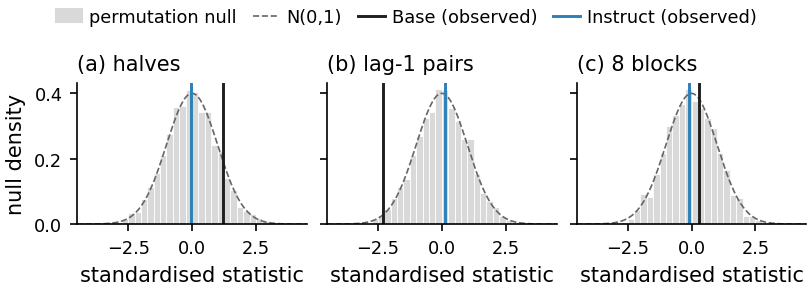

In [20]:
# 7.0b Figure F17: the three (A1) permutation tests on the real samples [analysis]
fig, axes = plt.subplots(1, 3, figsize=FIG_PANEL, layout="constrained", sharey=True)
f17 = {}
F17_SUB = {"half": "halves", "lag1": "lag-1 pairs", "blocks": "8 blocks"}   # brief subcaptions
_bins = np.linspace(-4.5, 4.5, 37)
_zz = np.linspace(-4.5, 4.5, 200)
for ax, key, lab in zip(axes, A1_TEST_NAMES, ["(a)", "(b)", "(c)"]):
    nz = np.concatenate([np.asarray(A1R[mk]["null_z"][key]) for mk in MODEL_KEYS])
    ax.hist(np.clip(nz, -4.5, 4.5), bins=_bins, density=True, color="#d9d9d9", edgecolor="white", linewidth=0.4)
    ax.plot(_zz, stats.norm.pdf(_zz), color=BOUND_COLOR, lw=0.8, ls="--")
    for mk in MODEL_KEYS:
        ax.axvline(float(np.clip(A1R[mk]["z"][key], -4.4, 4.4)), color=MODEL_COLORS[mk], lw=1.4)
    ax.set_xlim(-4.5, 4.5)
    ax.set_xlabel("standardised statistic")
    panel_label(ax, f"{lab} {F17_SUB[key]}")
    f17[key] = {"null_z_pooled": nz, "observed_z": {mk: A1R[mk]["z"][key] for mk in MODEL_KEYS},
                "p": {mk: A1R[mk]["p"][key] for mk in MODEL_KEYS}, "p_holm": {mk: float(A1_ADJ[(mk, key)]) for mk in MODEL_KEYS}}
axes[0].set_ylabel("null density")
_h = [Patch(color="#d9d9d9", label="permutation null"), Line2D([], [], color=BOUND_COLOR, ls="--", lw=0.8, label="N(0,1)")]
_h += [Line2D([], [], color=MODEL_COLORS[mk], lw=1.4, label=f"{MODEL_LABELS[mk]} (observed)") for mk in MODEL_KEYS]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=4)
finish_figure(fig, "F17_assumption_A1_tests", f17,
              "A1 permutation tests: standardised pooled nulls (grey) against the observed statistics of each model.")

Figure F17 (assumption A1). Each panel shows the exact within-problem permutation null of one pooled statistic, standardised to mean 0 and variance 1, with the observed value of each model as a vertical line:
- (a) halves: first-half versus second-half success rate;
- (b) lag-1 pairs: excess count of adjacent success pairs;
- (c) 8 blocks: two-sided 8-block homogeneity chi-square.

A line far in either tail is evidence against (A1). Holm-adjusted p-values are in T1.

[resume] e1_numerics: loaded from checkpoint
 n  eps  K_eps(n)  floor(n^2/ln(4/eps))  8n^2  2E at K  2E at K+1
 4 0.01         5                     2   128 0.003906   0.011800
 4 0.05         8                     3   128 0.035750   0.050058
 4 0.10        12                     4   128 0.095894   0.111191
 4 0.20        19                     5   128 0.195717   0.208340
 6 0.01        11                     6   288 0.007288   0.010780
 6 0.05        19                     8   288 0.048281   0.054735
 6 0.10        26                     9   288 0.095064   0.101830
 6 0.20        42                    12   288 0.196013   0.201659
 8 0.01        20                    10   512 0.009645   0.011726
 8 0.05        33                    14   512 0.047691   0.051270
 8 0.10        46                    17   512 0.096312   0.100106
 8 0.20        75                    21   512 0.198676   0.201837
12 0.01        44                    24  1152 0.009875   0.010771
12 0.05        74              

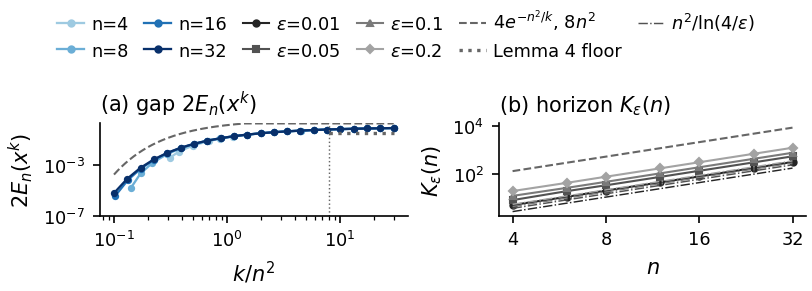

In [21]:
# 7.1 E1 (Theorem 1(A), exact numerics): brackets for 2E_n(x^k), horizons K_eps(n), Corollary 3 pair [analysis]
E1_NS = [4, 8, 16, 32]
E1_HOR_NS = [4, 8, 16] if SMOKE else [4, 6, 8, 12, 16, 24, 32]
E1_EPS = [0.01, 0.05, 0.1, 0.2]


def _e1():
    curve = {}
    for n in E1_NS:
        ks = sorted(set(max(n + 1, int(round(r * n * n))) for r in np.geomspace(0.1, 30.0, 8 if SMOKE else 22)))
        curve[n] = [(k, twoE(n, k)["lower"], twoE(n, k)["upper"]) for k in ks]
    hor = {}
    for n in E1_HOR_NS:
        for eps in E1_EPS:
            K = horizon_K(n, eps)
            hor[(n, eps)] = {"K": int(K), "lower_thm": int(math.floor(n * n / math.log(4.0 / eps))), "upper_thm": 8 * n * n,
                             "twoE_at_K": twoE(n, K)["upper"], "twoE_at_K1": twoE(n, K + 1)["lower"]}
    out = {"curve": curve, "horizon": hor, "cor3": extremal_pair(16, 2048), "adv2_pair": extremal_pair(32, 8192)}
    ckpt_save("e1_cache", E_CACHE)
    return out


E1 = cached("e1_numerics", _e1)
_hrows = [{"n": n, "eps": eps, "K_eps(n)": v["K"], "floor(n^2/ln(4/eps))": v["lower_thm"], "8n^2": v["upper_thm"],
           "2E at K": v["twoE_at_K"], "2E at K+1": v["twoE_at_K1"]} for (n, eps), v in E1["horizon"].items()]
HOR_TAB = pd.DataFrame(_hrows)
print(HOR_TAB.to_string(index=False))
HOR_TAB.to_csv(os.path.join(LOG_DIR, "e1_horizons.csv"), index=False)
_hor_ok = all(v["lower_thm"] <= v["K"] < v["upper_thm"] for v in E1["horizon"].values())
_mono = all(np.all(np.diff([0.5 * (a[1] + a[2]) for a in E1["curve"][n]]) >= -1e-9) for n in E1_NS)
_c3 = E1["cor3"]
_c3_ok = (_c3["count_law_maxdiff"] < 1e-12) and (_c3["sep"] >= 0.339)
VERDICTS["Theorem 1(A) horizon bracket"] = "PASS" if _hor_ok else "FAIL"
VERDICTS["Corollary 3 (numerical)"] = "PASS" if _c3_ok else "FAIL"
T2_ROWS.append({"Check": "Thm 1(A) horizon bracket", "Model": "--", "Value": f"{len(E1['horizon'])} (n,eps) pairs",
                "Threshold": "floor(n^2/ln(4/eps)) <= K < 8n^2", "p": np.nan, "Verdict": VERDICTS["Theorem 1(A) horizon bracket"]})
T2_ROWS.append({"Check": "Cor. 3 numerical (16, 2048)", "Model": "--",
                "Value": f"sep {_c3['sep']:.4f}; law diff {_c3['count_law_maxdiff']:.1e}",
                "Threshold": ">= 0.339; < 1e-12", "p": np.nan, "Verdict": VERDICTS["Corollary 3 (numerical)"]})
print(f"Horizon brackets hold for every (n, eps): {_hor_ok}; 2E_n(x^k) non-decreasing in k on every curve: {_mono}")
print(f"Corollary 3 (numerical) {VERDICTS['Corollary 3 (numerical)']}: the Remez pair at (16, 2048) has count laws agreeing to "
      f"{_c3['count_law_maxdiff']:.1e} and pass@2048 differing by {_c3['sep']:.4f} (bracket for 2E_16: "
      f"[{_c3['twoE_lower']:.4f}, {_c3['twoE_upper']:.4f}]); required: < 1e-12 and >= 0.339.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
GREYS = ["#252525", "#525252", "#7a7a7a", "#a3a3a3"]
EPS_MARK = ["o", "s", "^", "D"]
f1 = {"curves": {}, "horizon": {}}
_rr = np.geomspace(0.1, 30.0, 300)
for j, n in enumerate(E1_NS):
    arr = np.array(E1["curve"][n], float)
    r, mid = arr[:, 0] / n ** 2, 0.5 * (arr[:, 1] + arr[:, 2])
    ok = mid > 1e-7
    ax1.plot(r[ok], mid[ok], color=SEQ_COLORS[j], marker="o", ms=2.5, lw=1.1)
    f1["curves"][str(n)] = {"k": arr[ok, 0], "k_over_n2": r[ok], "twoE_lower": arr[ok, 1], "twoE_upper": arr[ok, 2]}
ax1.plot(_rr, np.minimum(4 * np.exp(-1.0 / _rr), 2.0), color=BOUND_COLOR, ls="--", lw=1.0)
ax1.hlines(LEMMA4_2E, 8.0, 30.0, color=BOUND_COLOR, ls=":", lw=1.6)
ax1.axvline(8.0, color=BOUND_COLOR, ls=":", lw=0.7)
ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_ylim(1e-7, 2.0)
ax1.set_xlabel(r"$k/n^2$"); ax1.set_ylabel(r"$2E_n(x^k)$")
panel_label(ax1, r"(a) gap $2E_n(x^k)$")
_nn = np.array(E1_HOR_NS, float)
for j, eps in enumerate(E1_EPS):
    Ks = [E1["horizon"][(n, eps)]["K"] for n in E1_HOR_NS]
    ax2.plot(_nn, Ks, color=GREYS[j], marker=EPS_MARK[j], ms=3, lw=1.0)
    ax2.plot(_nn, _nn ** 2 / np.log(4.0 / eps), color=GREYS[j], ls="-.", lw=0.7)
    f1["horizon"][str(eps)] = {"n": _nn, "K": Ks, "lower_bracket": _nn ** 2 / np.log(4.0 / eps)}
ax2.plot(_nn, 8 * _nn ** 2, color=BOUND_COLOR, ls="--", lw=1.0)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xticks([4, 8, 16, 32]); ax2.set_xticklabels(["4", "8", "16", "32"])
ax2.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax2.set_xlabel("$n$"); ax2.set_ylabel(r"$K_\varepsilon(n)$")
panel_label(ax2, r"(b) horizon $K_\varepsilon(n)$")
_h = [Line2D([], [], color=SEQ_COLORS[j], marker="o", ms=3, lw=1.1, label=f"n={n}") for j, n in enumerate(E1_NS)]
_h += [Line2D([], [], color=GREYS[j], marker=EPS_MARK[j], ms=3, lw=1.0, label=rf"$\varepsilon$={eps}") for j, eps in enumerate(E1_EPS)]
_h += [Line2D([], [], color=BOUND_COLOR, ls="--", lw=1.0, label=r"$4e^{-n^2/k}$, $8n^2$"),
       Line2D([], [], color=BOUND_COLOR, ls=":", lw=1.6, label="Lemma 4 floor"),
       Line2D([], [], color="#525252", ls="-.", lw=0.7, label=r"$n^2/\ln(4/\varepsilon)$")]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=6)
f1["lemma3_curve"] = {"k_over_n2": _rr, "bound": np.minimum(4 * np.exp(-1.0 / _rr), 2.0)}
f1["lemma4_floor"] = LEMMA4_2E
finish_figure(fig, "F1_population_horizon", f1, "Population ambiguity 2E_n(x^k) and the horizon K_eps(n) with both bounds.")

Figure F1 (Theorem 1(A), population horizon).
- (a) Gap $2E_n(x^k)$: the exact identification gap, the midpoint of a minimax bracket whose width is far below the marker size, against $k/n^2$ for $n\in\{4,8,16,32\}$. The dashed line is Lemma 3's upper bound $4e^{-n^2/k}$. The dotted segment is Lemma 4's floor of 0.3396 for $k\ge8n^2$.
- (b) Horizon $K_\varepsilon(n)$ against $n$. Dash-dot lines are the lower bracket $n^2/\ln(4/\varepsilon)$; the dashed line is the upper bracket $8n^2$.

The theorem predicts that every curve in (a) stays under the dashed line, and that every point in (b) lies between its two brackets.

In [22]:
# 7.2 E2 (Theorem 1(B) on real data): M6 contrast vs the signed envelope, Corollaries 1-2, overdispersion [analysis]
def e2_checks(Ymap):
    res = {}
    for mk in MODEL_KEYS:
        Y = np.asarray(Ymap[mk], dtype=np.uint8)
        C = Y.sum(1).astype(int)
        cb = Y.reshape(M_EFF, NB, N_BLK).sum(2).astype(int)
        rows = []
        for k in CFG["E2_KS"]:
            v = m6_contrast_values(C, N_ATT, N_BLK, k)
            bs = boot_mean(v)
            lo, hi = pct_ci(bs)
            L, U = signed_envelope(N_BLK, k)
            rows.append({"k": int(k), "t": k / N_BLK, "contrast": float(v.mean()), "lo": float(lo), "hi": float(hi),
                         "sd_boot": float(bs.std()), "L": float(L), "U": float(U),
                         "p_above": float(max(np.mean(bs <= U), 1.0 / B_BOOT)),
                         "p_below": float(max(np.mean(bs >= L), 1.0 / B_BOOT)),
                         "inside": bool(hi >= L and lo <= U)})
        h, ch = doubling_h(N_BLK, 48), chen_fail_table(N_ATT - N_BLK, 48)
        Fb, Rb = h[cb], ch[C[:, None] - cb]          # (m, 8): per-problem block estimates and held-out references
        D = Fb - Rb
        bs = boot_mean(D.mean(1))
        lo, hi = pct_ci(bs)
        Bc = B_n(N_BLK, 1.5)
        L48, U48 = signed_envelope(N_BLK, 48)
        p_viol = float(min(1.0, 2.0 * max(min(np.mean(bs <= Bc), np.mean(bs >= -Bc)), 1.0 / B_BOOT)))
        cor1 = {"blocks": D.mean(0), "mean": float(D.mean()), "lo": float(lo), "hi": float(hi), "B": Bc,
                "sym_inside": bool(lo <= Bc and hi >= -Bc), "signed_inside": bool(lo <= U48 and hi >= L48), "p_viol": p_viol}
        Fblk, Rblk = Fb.mean(0), Rb.mean(0)
        dev = np.abs(Fblk - Rblk)
        thr, ref_err = thm1b_bound(N_BLK, 48, M_EFF, DELTA), hoeffding_term(M_EFF, DELTA)
        cor2 = {"F_blocks": Fblk, "ref_blocks": Rblk, "dev": dev, "max_dev": float(dev.max()), "thr": thr, "ref_err": ref_err,
                "ok": bool(dev.max() <= thr + ref_err), "ok_strict": bool(dev.max() <= thr)}
        pt, tt = C / N_ATT, 1.5
        var_i = (1 - pt + pt * (1 - tt) ** 2) ** N_BLK - (1 - tt * pt) ** (2 * N_BLK)
        sigma2, s2 = float(var_i.sum() / M_EFF ** 2), float(Fblk.var(ddof=1))
        X = (NB - 1) * s2 / max(sigma2, 1e-300)
        over = {"s2": s2, "sigma2": sigma2, "ratio": s2 / max(sigma2, 1e-300), "p": float(stats.chi2.sf(X, NB - 1))}
        res[mk] = {"rows": rows, "cor1": cor1, "cor2": cor2, "over": over}
    return res


E2 = cached(f"e2_g1_{DATA_TAG}", lambda: e2_checks(YG1))
_show = [40, 48, 56, 60, 62, 63]
for mk in MODEL_KEYS:
    r = E2[mk]
    c1, c2, ov = r["cor1"], r["cor2"], r["over"]
    v1 = "PASS" if c1["sym_inside"] else ("FAIL" if A1_OK[mk] else "INCONCLUSIVE (A1 failed)")
    VERDICTS[f"Corollary 1 ({MODEL_LABELS[mk]})"] = v1
    VERDICTS[f"Corollary 2 ({MODEL_LABELS[mk]})"] = "PASS" if c2["ok"] else "FAIL"
    VERDICTS[f"Overdispersion ({MODEL_LABELS[mk]})"] = "PASS" if ov["p"] >= 0.05 else "FAIL"
    print(f"\n{MODEL_LABELS[mk]} | Corollary 1: block-averaged difference {c1['mean']:+.5f} [95% CI {c1['lo']:+.5f}, {c1['hi']:+.5f}] "
          f"vs [-{c1['B']:.5f}, {c1['B']:.5f}] -> {v1}")
    print(f"{MODEL_LABELS[mk]} | Corollary 2: max per-block |F48 - ref| = {c2['max_dev']:.4f} vs {c2['thr']:.4f} "
          f"(+ reference error {c2['ref_err']:.4f}) -> {VERDICTS[f'Corollary 2 ({MODEL_LABELS[mk]})']}")
    print(f"{MODEL_LABELS[mk]} | overdispersion: across-block variance / plug-in = {ov['ratio']:.3f}, chi2_7 p = {ov['p']:.3f}")
    tab = pd.DataFrame([x for x in r["rows"] if x["k"] in _show])[["k", "contrast", "lo", "hi", "L", "U", "p_above", "p_below", "inside"]]
    print(tab.to_string(index=False, float_format=lambda z: f"{z:.5f}"))
    T2_ROWS.append({"Check": "Cor. 1 bias, k=48", "Model": MODEL_LABELS[mk], "Value": fmt_ci(c1["mean"], c1["lo"], c1["hi"], 4),
                    "Threshold": f"overlaps +-{c1['B']:.5f}", "p": c1["p_viol"], "Verdict": v1})
    T2_ROWS.append({"Check": "Cor. 2 deviation, k=48", "Model": MODEL_LABELS[mk], "Value": f"{c2['max_dev']:.4f}",
                    "Threshold": f"<= {c2['thr']:.4f}+{c2['ref_err']:.4f}", "p": np.nan,
                    "Verdict": VERDICTS[f"Corollary 2 ({MODEL_LABELS[mk]})"]})
    T2_ROWS.append({"Check": "Overdispersion (8 blocks)", "Model": MODEL_LABELS[mk], "Value": f"ratio {ov['ratio']:.3f}",
                    "Threshold": "chi2_7 p >= 0.05", "p": ov["p"], "Verdict": VERDICTS[f"Overdispersion ({MODEL_LABELS[mk]})"]})
    for x in r["rows"]:
        if x["k"] in _show:
            for side, pv in (("above U", x["p_above"]), ("below L", x["p_below"])):
                T2_ROWS.append({"Check": f"Envelope k={x['k']} ({side})", "Model": MODEL_LABELS[mk], "Value": f"{x['contrast']:+.5f}",
                                "Threshold": f"[{x['L']:.4f}, {x['U']:.2e}]", "p": pv, "Verdict": "PASS" if x["inside"] else "FAIL"})
pd.DataFrame([dict(model=mk, **{kk: vv for kk, vv in x.items()}) for mk in MODEL_KEYS for x in E2[mk]["rows"]]).to_csv(
    os.path.join(LOG_DIR, "e2_contrast_by_k.csv"), index=False)
pd.DataFrame([{"model": mk, "block": b + 1, "F48_block": E2[mk]["cor2"]["F_blocks"][b], "ref_other_224": E2[mk]["cor2"]["ref_blocks"][b],
               "difference": E2[mk]["cor1"]["blocks"][b]} for mk in MODEL_KEYS for b in range(NB)]).to_csv(
    os.path.join(LOG_DIR, "e2_corollary1_per_block.csv"), index=False)

[resume] e2_g1_1e894fd9be: loaded from checkpoint

Base | Corollary 1: block-averaged difference +0.00147 [95% CI -0.01035, +0.01266] vs [-0.00601, 0.00601] -> PASS
Base | Corollary 2: max per-block |F48 - ref| = 0.0269 vs 0.1236 (+ reference error 0.0784) -> PASS
Base | overdispersion: across-block variance / plug-in = 0.530, chi2_7 p = 0.813
 k  contrast       lo       hi        L       U  p_above  p_below  inside
40  -0.00038 -0.00045 -0.00032 -0.00361 0.00000  1.00000  1.00000    True
48  -0.00061 -0.00073 -0.00050 -0.00601 0.00000  1.00000  1.00000    True
56  -0.00076 -0.00091 -0.00061 -0.00773 0.00010  1.00000  1.00000    True
60  -0.00080 -0.00097 -0.00063 -0.00841 0.01394  1.00000  1.00000    True
62  -0.00062 -0.00088 -0.00032 -0.00872 0.12679  1.00000  1.00000    True
63  -0.00019 -0.00076  0.00058 -0.00887 0.36206  1.00000  1.00000    True

Instruct | Corollary 1: block-averaged difference +0.00244 [95% CI -0.00696, +0.01171] vs [-0.00601, 0.00601] -> PASS
Instruct | Coroll

[figure] F2_bound_vs_measured_bias: layout audit OK {"n_text": 20, "text_overlaps": 0}


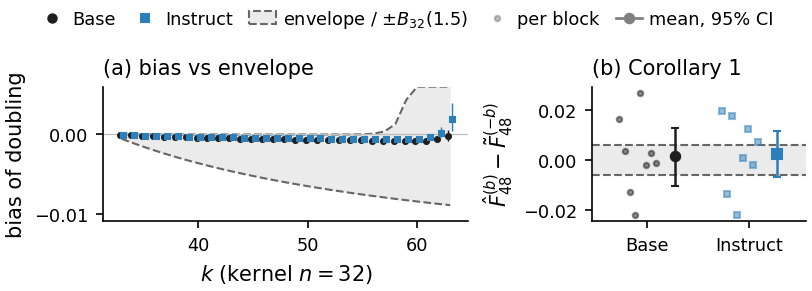

[figure] F15_mechanism_bias_by_rate: layout audit OK {"n_text": 23, "text_overlaps": 0}


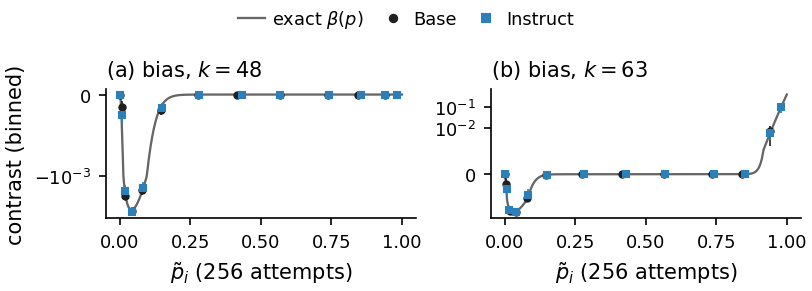

In [23]:
# Figures F2 (bound vs measured) and F15 (mechanism: per-problem contrast against the exact bias curve) [analysis]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained", gridspec_kw={"width_ratios": [1.7, 1.0]})
_ks = np.array(CFG["E2_KS"])
_Ls = np.array([signed_envelope(N_BLK, k)[0] for k in _ks])
_Us = np.array([signed_envelope(N_BLK, k)[1] for k in _ks])
_lo_all = min(_Ls.min(), min(x["lo"] for mk in MODEL_KEYS for x in E2[mk]["rows"]))
_hi_all = max(x["hi"] for mk in MODEL_KEYS for x in E2[mk]["rows"])
_ytop, _ybot = max(0.006, _hi_all + 0.002), _lo_all - 0.002
ax1.fill_between(_ks, _Ls, np.minimum(_Us, _ytop), color="#ebebeb", lw=0)
ax1.plot(_ks, _Ls, color=BOUND_COLOR, ls="--", lw=1.0)
ax1.plot(_ks, np.minimum(_Us, _ytop), color=BOUND_COLOR, ls="--", lw=1.0)
ax1.axhline(0.0, color="#bdbdbd", lw=0.6)
f2 = {"k": _ks, "envelope_lower": _Ls, "envelope_upper": _Us, "ylim": [_ybot, _ytop], "models": {}}
for j, mk in enumerate(MODEL_KEYS):
    rows = E2[mk]["rows"]
    y = np.array([x["contrast"] for x in rows]); lo = np.array([x["lo"] for x in rows]); hi = np.array([x["hi"] for x in rows])
    ax1.errorbar(_ks + (j - 0.5) * 0.32, y, yerr=[np.maximum(y - lo, 0), np.maximum(hi - y, 0)], fmt=MODEL_MARKERS[mk],
                 color=MODEL_COLORS[mk], ms=2.4, lw=0.7, capsize=0)
    f2["models"][mk] = {"contrast": y, "ci_lo": lo, "ci_hi": hi}
ax1.set_ylim(_ybot, _ytop)
ax1.set_xlabel("$k$ (kernel $n=32$)")
ax1.set_ylabel("bias of doubling")
panel_label(ax1, "(a) bias vs envelope")
_Bc = B_n(N_BLK, 1.5)
ax2.axhspan(-_Bc, _Bc, color="#ebebeb", lw=0)
ax2.axhline(_Bc, color=BOUND_COLOR, ls="--", lw=1.0); ax2.axhline(-_Bc, color=BOUND_COLOR, ls="--", lw=1.0)
f2["corollary1"] = {"B_32_1.5": _Bc}
for j, mk in enumerate(MODEL_KEYS):
    c1 = E2[mk]["cor1"]
    ax2.plot(j + np.linspace(-0.18, 0.18, NB), c1["blocks"], ls="none", marker=MODEL_MARKERS[mk], ms=2.6,
             color=MODEL_COLORS[mk], alpha=0.5)
    ax2.errorbar([j + 0.36], [c1["mean"]], yerr=[[max(c1["mean"] - c1["lo"], 0)], [max(c1["hi"] - c1["mean"], 0)]],
                 fmt=MODEL_MARKERS[mk], ms=4.5, color=MODEL_COLORS[mk], capsize=2, lw=1.2)
    f2["corollary1"][mk] = {"per_block": c1["blocks"], "mean": c1["mean"], "ci": [c1["lo"], c1["hi"]]}
ax2.set_xticks([0.09, 1.09]); ax2.set_xticklabels([MODEL_LABELS[mk] for mk in MODEL_KEYS]); ax2.set_xlim(-0.45, 1.65)
ax2.set_ylabel(r"$\hat F^{(b)}_{48}-\tilde F^{(-b)}_{48}$")
panel_label(ax2, "(b) Corollary 1")
_h = [Line2D([], [], color=MODEL_COLORS[mk], marker=MODEL_MARKERS[mk], ls="none", ms=4, label=MODEL_LABELS[mk]) for mk in MODEL_KEYS]
_h += [Patch(facecolor="#ebebeb", edgecolor=BOUND_COLOR, ls="--", label="envelope / $\\pm B_{32}(1.5)$"),
       Line2D([], [], color="#7f7f7f", marker="o", ls="none", ms=2.6, alpha=0.5, label="per block"),
       Line2D([], [], color="#7f7f7f", marker="o", ls="-", ms=4.5, label="mean, 95% CI")]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=5)
finish_figure(fig, "F2_bound_vs_measured_bias", f2, "M6 bias contrast against the signed envelope; Corollary 1 per-block check.")

_edges = np.array([0.0, 1e-9, 0.01, 0.03, 0.06, 0.1, 0.2, 0.35, 0.5, 0.65, 0.8, 0.9, 0.97, 1.0 + 1e-9])
fig, axes = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained", sharey=False)
f15 = {}
_pp = np.linspace(0, 1, 500)
for ax, k, lab in zip(axes, (48, 63), ("(a)", "(b)")):
    ax.plot(_pp, doubling_bias(_pp, N_BLK, k), color=BOUND_COLOR, lw=1.1, zorder=1)
    f15[str(k)] = {"p_grid": _pp, "exact_beta": doubling_bias(_pp, N_BLK, k), "models": {}}
    for mk in MODEL_KEYS:
        v = m6_contrast_values(C_ALL[mk], N_ATT, N_BLK, k)
        idx = np.digitize(PT[mk], _edges) - 1
        xs, ys, es = [], [], []
        for b in range(len(_edges) - 1):
            sel = idx == b
            if sel.sum() >= 5:
                xs.append(PT[mk][sel].mean()); ys.append(v[sel].mean()); es.append(1.96 * v[sel].std(ddof=1) / math.sqrt(sel.sum()))
        ax.errorbar(xs, ys, yerr=es, fmt=MODEL_MARKERS[mk], color=MODEL_COLORS[mk], ms=3, lw=0.8, capsize=0, zorder=2)
        f15[str(k)]["models"][mk] = {"bin_p": xs, "bin_mean_contrast": ys, "ci_halfwidth": es}
    ax.set_yscale("symlog", linthresh=1e-3)
    ax.set_xlabel(r"$\tilde p_i$ (256 attempts)")
    tidy_symlog(ax, 1e-3)
    panel_label(ax, f"{lab} bias, $k={k}$")
axes[0].set_ylabel("contrast (binned)")
_h = [Line2D([], [], color=BOUND_COLOR, lw=1.1, label=r"exact $\beta(p)$")]
_h += [Line2D([], [], color=MODEL_COLORS[mk], marker=MODEL_MARKERS[mk], ls="none", ms=3.5, label=MODEL_LABELS[mk]) for mk in MODEL_KEYS]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=3)
finish_figure(fig, "F15_mechanism_bias_by_rate", f15, "Binned per-problem M6 contrast against the exact bias function beta(p).")

Figure F2 (Theorem 1(B): bound against measurement).
- (a) Bias vs envelope. The M6 contrast (Rao–Blackwellised doubling estimator minus Chen et al.'s unbiased estimator, both from all 256 attempts) estimates the bias $\frac1m\sum_i\beta(p_i)$ exactly. It is plotted for $k=33,\dots,63$ with problem-level bootstrap 95% CIs. The grey band is the signed envelope M1. Its upper edge $(t-1)^{32}$ leaves the plotted range near $k=60$ (it reaches 0.36 at $k=63$), which is where the doubling barrier opens.
- (b) Corollary 1. Light points are the eight per-block differences $\hat F^{(b)}_{48}-\tilde F^{(-b)}_{48}$; the solid point is their mean with a bootstrap 95% CI. The theorem requires the CI to overlap the band $\pm B_{32}(1.5)=\pm0.00601$.

Figure F15 (mechanism). Per-problem contrasts, binned by each problem's empirical success rate, against the exact bias curve $\beta(p)=(1-tp)^{32}-(1-p)^{k}$: (a) bias at $k=48$; (b) bias at $k=63$. Bars are 95% normal CIs. The binned points should track the curve. At $k=63$ the positive lobe near $p=1$ is the barrier at $t=2$.

[resume] e3_lemma6_v2_6: loaded from checkpoint
 t       estimator  threshold  frac_D0  frac_D1   frac  p_binom  mean_err  sd_err  pass
 4 Doubling (ours)     0.0086   0.9905   0.9930 0.9930   1.0000    0.3145  0.3705  True
 4  LP-cert (ours)     0.0086   0.9345   0.9310 0.9345   1.0000    0.0313  0.0134  True
 4       Power law     0.0086   1.0000   1.0000 1.0000   1.0000    0.1773  0.0171  True
 4   Beta-binomial     0.0086   0.8470   0.3240 0.8470   1.0000    0.0125  0.0085  True
 4           NPMLE     0.0086   0.7895   0.2990 0.7895   1.0000    0.0138  0.0144  True
 4 Moment matching     0.0086   0.8620   0.5050 0.8620   1.0000    0.0197  0.0186  True
16 Doubling (ours)     0.0343   1.0000   1.0000 1.0000   1.0000    0.4228  0.4202  True
16  LP-cert (ours)     0.0343   1.0000   1.0000 1.0000   1.0000    0.0742  0.0343  True
16       Power law     0.0343   0.0700   1.0000 1.0000   1.0000    0.0489  0.0339  True
16   Beta-binomial     0.0343   1.0000   0.9935 1.0000   1.0000    0.073

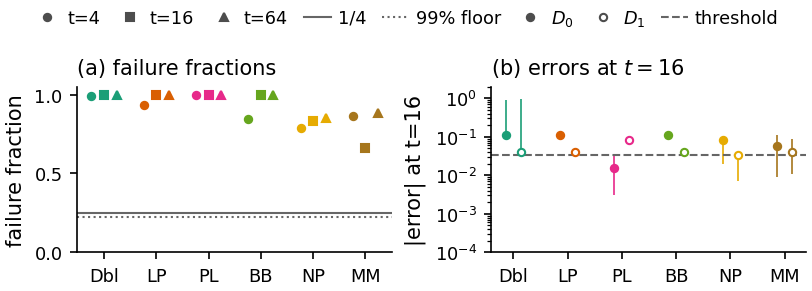

In [24]:
# 7.3 E3 (Theorem 1(C)): Lemma 6 pairs at m=500, n=32, t in {4, 16, 64}; every estimator vs the 1/4 floor [analysis]
E3_NAMES = [nm for nm in ["Doubling (ours)", "LP-cert (ours)", "Power law", "Beta-binomial", "NPMLE", "Moment matching"]
            if nm in METHOD_ORDER]   # LP and doubling are evaluated beyond their certified ranges only for this lower-bound check


def _e3_lemma6():
    n, m, R = N_BLK, CFG["M_SEMI"], CFG["R_LEMMA6"]
    rng = np.random.default_rng(SEED + 301)
    out = {}
    for t in CFG["LEMMA6_TS"]:
        k = n * t
        w, a0, a1 = lemma6_pair(n, k, m)
        errs = []
        for atoms in (a0, a1):
            pi = np.clip(count_law_atoms(atoms, n), 0.0, None)
            H = rng.multinomial(m, pi / pi.sum(), size=R).astype(float)
            est = estimate_all(H, n, [k], m, names=E3_NAMES, any_t=True)
            Ft = F_atoms(atoms, k)
            errs.append({nm: np.abs(est[nm][:, 0] - Ft) for nm in E3_NAMES})
        out[t] = {"k": k, "w": w, "thr": thm1c_lb(n, k, m), "F0": F_atoms(a0, k), "F1": F_atoms(a1, k), "err": errs}
    lp_cache_flush()
    return out


E3L = cached(f"e3_lemma6_v2_{len(E3_NAMES)}", _e3_lemma6)
R6 = CFG["R_LEMMA6"]
X_CRIT = int(stats.binom.ppf(0.01, R6, 0.25))   # exact one-sided 99% Monte Carlo floor under q = 1/4
_rows = []
for t, d in E3L.items():
    for nm in E3_NAMES:
        f0, f1 = float(np.mean(d["err"][0][nm] >= d["thr"])), float(np.mean(d["err"][1][nm] >= d["thr"]))
        frac = max(f0, f1)
        cnt = int(round(frac * R6))
        lo, hi = cp_interval(cnt, R6, 0.02)
        allerr = np.concatenate([d["err"][0][nm], d["err"][1][nm]])
        _rows.append({"t": t, "k": d["k"], "estimator": nm, "threshold": d["thr"], "frac_D0": f0, "frac_D1": f1, "frac": frac,
                      "count": cnt, "cp_lo": float(lo), "cp_hi": float(hi), "p_binom": float(stats.binom.cdf(cnt, R6, 0.25)),
                      "mean_err": float(allerr.mean()), "sd_err": float(allerr.std(ddof=1)), "pass": cnt >= X_CRIT})
E3F = pd.DataFrame(_rows)
E3F.to_csv(os.path.join(LOG_DIR, "e3_lemma6_failure_fractions.csv"), index=False)
pd.DataFrame([{"t": t, "hypothesis": h, "replicate": r, "estimator": nm, "abs_error": float(E3L[t]["err"][h][nm][r])}
              for t in E3L for h in (0, 1) for nm in E3_NAMES for r in range(R6)]).to_csv(
    os.path.join(LOG_DIR, "e3_lemma6_per_replicate_errors.csv"), index=False)
VERDICTS["Corollary 3 (data-facing, Lemma 6)"] = "PASS" if bool(E3F["pass"].all()) else "FAIL"
print(E3F[["t", "estimator", "threshold", "frac_D0", "frac_D1", "frac", "p_binom", "mean_err", "sd_err", "pass"]].to_string(
    index=False, float_format=lambda z: f"{z:.4f}"))
print(f"Corollary 3 (data-facing) {VERDICTS['Corollary 3 (data-facing, Lemma 6)']}: every estimator must miss by the threshold on one "
      f"hypothesis in at least {X_CRIT}/{R6} = {X_CRIT / R6:.4f} of replicates (99% Monte Carlo floor under 1/4).")
for _, rr_ in E3F.iterrows():
    T2_ROWS.append({"Check": f"Cor. 3 Lemma 6, t={rr_['t']}", "Model": ABBREV[rr_["estimator"]], "Value": f"{rr_['frac']:.3f}",
                    "Threshold": f">= {X_CRIT / R6:.3f}", "p": rr_["p_binom"], "Verdict": "PASS" if rr_["pass"] else "FAIL"})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
T_MARK = {4: "o", 16: "s", 64: "^"}
_xs = np.arange(len(E3_NAMES))
f8 = {"estimators": E3_NAMES, "x_crit_fraction": X_CRIT / R6, "fractions": {}, "errors_t16": {}}
for j, t in enumerate(CFG["LEMMA6_TS"]):
    sub = E3F[E3F["t"] == t]
    for i, nm in enumerate(E3_NAMES):
        row = sub[sub["estimator"] == nm].iloc[0]
        ax1.errorbar(i + (j - 1) * 0.24, row["frac"], yerr=[[row["frac"] - row["cp_lo"]], [row["cp_hi"] - row["frac"]]],
                     fmt=T_MARK.get(t, "o"), color=METHOD_COLORS[nm], ms=3.5, lw=0.8, capsize=0)
    f8["fractions"][str(t)] = {"frac": sub["frac"].values, "cp_lo": sub["cp_lo"].values, "cp_hi": sub["cp_hi"].values}
ax1.axhline(0.25, color=BOUND_COLOR, lw=1.0)
ax1.axhline(X_CRIT / R6, color=BOUND_COLOR, ls=":", lw=1.0)
ax1.set_xticks(_xs); ax1.set_xticklabels([CODE2[nm] for nm in E3_NAMES])
ax1.set_ylim(0, 1.05); ax1.set_ylabel("failure fraction")
panel_label(ax1, "(a) failure fractions")
_t16 = 16 if 16 in E3L else list(E3L)[0]
for i, nm in enumerate(E3_NAMES):
    for h, off, face in ((0, -0.14, METHOD_COLORS[nm]), (1, 0.14, "white")):
        e = np.maximum(E3L[_t16]["err"][h][nm], 1e-6)
        q10, q50, q90 = np.quantile(e, [0.1, 0.5, 0.9])
        ax2.errorbar(i + off, q50, yerr=[[q50 - q10], [q90 - q50]], fmt="o", ms=3.5, mfc=face, mec=METHOD_COLORS[nm],
                     color=METHOD_COLORS[nm], lw=0.8, capsize=0)
        f8["errors_t16"][f"{nm}|D{h}"] = {"q10": q10, "q50": q50, "q90": q90}
ax2.axhline(E3L[_t16]["thr"], color=BOUND_COLOR, ls="--", lw=1.0)
ax2.set_yscale("log"); ax2.set_ylim(1e-4, 2.0)
ax2.set_xticks(_xs); ax2.set_xticklabels([CODE2[nm] for nm in E3_NAMES])
ax2.set_ylabel(f"|error| at t={_t16}")
panel_label(ax2, f"(b) errors at $t={_t16}$")
_h = [Line2D([], [], color="#4d4d4d", marker=T_MARK.get(t, "o"), ls="none", ms=3.5, label=f"t={t}") for t in CFG["LEMMA6_TS"]]
_h += [Line2D([], [], color=BOUND_COLOR, lw=1.0, label="1/4"), Line2D([], [], color=BOUND_COLOR, ls=":", lw=1.0, label="99% floor"),
       Line2D([], [], color="#4d4d4d", marker="o", ls="none", ms=3.5, label="$D_0$"),
       Line2D([], [], color="#4d4d4d", marker="o", mfc="white", ls="none", ms=3.5, label="$D_1$"),
       Line2D([], [], color=BOUND_COLOR, ls="--", lw=1.0, label="threshold")]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=8)
finish_figure(fig, "F8_theorem1C_lemma6", f8, "Theorem 1(C): failure fractions on the Lemma 6 pairs and error quantiles at t=16.")

Figure F8 (Theorem 1(C), finite-sample lower bound).
- (a) Failure fractions: for each estimator and $t\in\{4,16,64\}$ (marker shape), the larger of the two failure fractions on the Lemma 6 pair, i.e. the share of replicates erring by at least $\min\{0.158,0.0479t/\sqrt{500}\}$. Bars are 98% Clopper–Pearson intervals. The theorem predicts every point at or above 1/4 (solid line); the dotted line is the 99% Monte Carlo floor.
- (b) Errors at $t=16$: median and 10–90% range of the absolute error under $D_0$ (filled) and $D_1$ (open), against the threshold (dashed).

The doubling and LP estimators are evaluated here outside their certified ranges, only to check the lower bound. Estimator codes: Dbl doubling (ours), LP LP-cert (ours), PL power law, BB Beta-binomial, NP NPMLE, MM moment matching.

[resume] e3_sandwich: loaded from checkpoint
[resume] e3_horizons: loaded from checkpoint
[resume] e3_nmin: loaded from checkpoint
Certified horizons (n = 64):
      m  eps    t*_LP     t*_LB
   1000 0.05 1.046875 12.359375
   1000 0.10 1.812500 28.125000
  10000 0.05 2.390625 37.000000
  10000 0.10 4.125000 64.000000
 100000 0.05 3.140625 64.000000
 100000 0.10 5.437500 64.000000
1000000 0.05 4.125000 64.000000
1000000 0.10 7.140625 64.000000
Attempt budget n_min at eps = 0.1 (grid [8, 16, 32, 64, 128]; NaN = not reached on the grid):
   m   k  n_min sufficient (LP-cert)  n_min necessary (M5)
 500  64                        64.0                     8
 500 128                       128.0                     8
 500 256                         NaN                    16
 500 512                         NaN                    32
5000  64                        32.0                     8
5000 128                        64.0                     8
5000 256                       128.0         

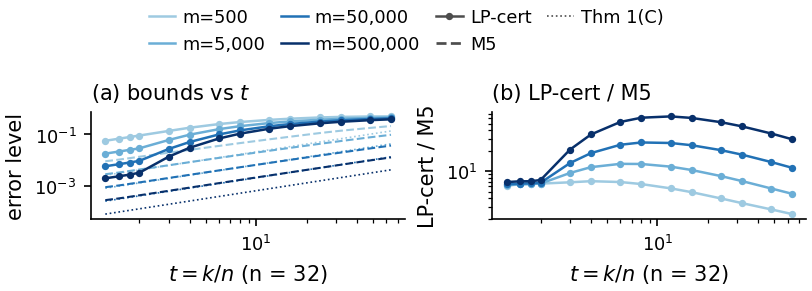

[figure] F4_certified_horizons_nmin: layout audit OK {"n_text": 24, "text_overlaps": 0}


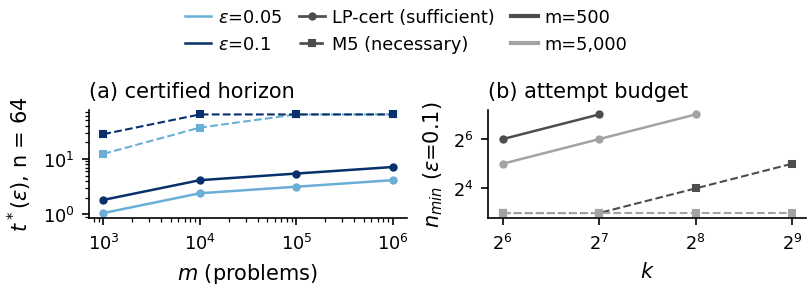

In [25]:
# 7.3b E3: sandwich (LP-cert at delta=1/4 vs M5), certified horizons t*(eps) vs m, attempt budget n_min -> F3, F4, T5 [analysis]
E3_TS = [1.5, 4, 16, 64] if SMOKE else [1.25, 1.5, 1.75, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64]
E3_MS = [500, 50000] if SMOKE else [500, 5000, 50000, 500000]
H_N = 64
H_KS = sorted(set(int(round(t * H_N)) for t in np.geomspace(1.05, 64, 6 if SMOKE else 16)))
H_MS = [1000, 100000] if SMOKE else [1000, 10000, 100000, 1000000]
NM_NS = [8, 16, 32] if SMOKE else [8, 16, 32, 64, 128]
NM_KS, NM_MS, NM_EPS = [64, 128, 256, 512], [500, 5000], 0.1


def _seq(j, total):
    return SEQ_COLORS[{1: [3], 2: [1, 3], 3: [1, 2, 3]}.get(total, [0, 1, 2, 3])[j]]


def _sweep(n, ks, ms, delta):
    rows = []
    for m in ms:
        for k in ks:
            lp = lp_estimator(n, k, int(m), delta, 1.0, CFG["LP_G_SWEEP"])
            lb = m5_cached(n, k, int(m))
            rows.append({"n": n, "m": int(m), "k": int(k), "t": k / n, "lp_cert": lp["cert"], "m5": lb["lb"],
                         "thm1c": thm1c_lb(n, k, int(m)), "ratio": lp["cert"] / max(lb["lb"], 1e-12)})
    lp_cache_flush()
    ckpt_save("m5_cache", M5_CACHE)
    return pd.DataFrame(rows)


SANDWICH = cached("e3_sandwich", lambda: _sweep(N_BLK, sorted(set(int(round(t * N_BLK)) for t in E3_TS)), E3_MS, 0.25))
HOR = cached("e3_horizons", lambda: _sweep(H_N, H_KS, H_MS, DELTA))
NMIN = cached("e3_nmin", lambda: pd.concat([_sweep(n, NM_KS, NM_MS, DELTA) for n in NM_NS], ignore_index=True))
SANDWICH.to_csv(os.path.join(LOG_DIR, "e3_sandwich.csv"), index=False)
HOR.to_csv(os.path.join(LOG_DIR, "e3_horizons.csv"), index=False)
NMIN.to_csv(os.path.join(LOG_DIR, "e3_nmin_grid.csv"), index=False)


def t_star(df, col, eps):
    ok = df[df[col] <= eps]["t"]
    return float(ok.max()) if len(ok) else float("nan")


TSTAR = pd.DataFrame([{"m": m, "eps": eps, "t*_LP": t_star(HOR[HOR["m"] == m], "lp_cert", eps),
                       "t*_LB": t_star(HOR[HOR["m"] == m], "m5", eps)} for m in H_MS for eps in (0.05, 0.1)])
print("Certified horizons (n = 64):\n" + TSTAR.to_string(index=False))
_nm_rows = []
for m in NM_MS:
    for k in NM_KS:
        sub = NMIN[(NMIN["m"] == m) & (NMIN["k"] == k)].sort_values("n")
        suff, nec = sub[sub["lp_cert"] <= NM_EPS]["n"], sub[sub["m5"] <= NM_EPS]["n"]
        _nm_rows.append({"m": m, "k": k, "n_min sufficient (LP-cert)": int(suff.min()) if len(suff) else np.nan,
                         "n_min necessary (M5)": int(nec.min()) if len(nec) else np.nan})
NMIN_TAB = pd.DataFrame(_nm_rows)
print(f"Attempt budget n_min at eps = {NM_EPS} (grid {NM_NS}; NaN = not reached on the grid):\n" + NMIN_TAB.to_string(index=False))
_sel_t = [t for t in (1.5, 4, 16, 64) if t in set(SANDWICH["t"].round(6))]
_t5 = SANDWICH[SANDWICH["t"].round(6).isin(_sel_t)].copy()
T5A = pd.DataFrame({"$m$": _t5["m"].astype(int), "$t$": _t5["t"].map(lambda z: f"{z:g}"), "LP-cert": _t5["lp_cert"].map(lambda z: f"{z:.4f}"),
                    "M5": _t5["m5"].map(lambda z: f"{z:.4f}"), "Thm 1(C)": _t5["thm1c"].map(lambda z: f"{z:.4f}"),
                    "Ratio": _t5["ratio"].map(lambda z: f"{z:.2f}")})
save_table(T5A, "T5a_sandwich", "Sandwich at n = 32: LP certificate at delta = 1/4 (upper), M5 two-point bound and Theorem 1(C) "
           "(lower, probability 1/4), and their ratio.")
save_table(NMIN_TAB.astype(object).where(NMIN_TAB.notna(), "--"), "T5b_attempt_budget",
           f"Attempt budget n_min at eps = {NM_EPS}: smallest n on the grid {NM_NS} with LP-cert <= eps (sufficient) and "
           "smallest n whose M5 lower bound does not exceed eps (necessary).")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
f3 = {}
for j, m in enumerate(E3_MS):
    sub = SANDWICH[SANDWICH["m"] == m].sort_values("t")
    c = _seq(j, len(E3_MS))
    ax1.plot(sub["t"], sub["lp_cert"], color=c, lw=1.2, marker="o", ms=2.5)
    ax1.plot(sub["t"], sub["m5"], color=c, lw=1.0, ls="--")
    ax1.plot(sub["t"], sub["thm1c"], color=c, lw=0.8, ls=":")
    ax2.plot(sub["t"], sub["ratio"], color=c, lw=1.2, marker="o", ms=2.5)
    f3[str(m)] = {"t": sub["t"].values, "lp_cert_delta_quarter": sub["lp_cert"].values, "m5": sub["m5"].values,
                  "thm1c": sub["thm1c"].values, "ratio": sub["ratio"].values}
for ax in (ax1, ax2):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("$t=k/n$ (n = 32)")
ax1.set_ylabel("error level"); ax2.set_ylabel("LP-cert / M5")
panel_label(ax1, "(a) bounds vs $t$"); panel_label(ax2, "(b) LP-cert / M5")
_h = [Line2D([], [], color=_seq(j, len(E3_MS)), lw=1.2, label=f"m={m:,}") for j, m in enumerate(E3_MS)]
_h += [Line2D([], [], color="#4d4d4d", lw=1.2, marker="o", ms=2.5, label="LP-cert"), Line2D([], [], color="#4d4d4d", ls="--", label="M5"),
       Line2D([], [], color="#4d4d4d", ls=":", lw=0.8, label="Thm 1(C)")]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=4)
finish_figure(fig, "F3_sandwich", f3, "Upper certificate vs two-point lower bounds across t and m, and their ratio.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
f4 = {"tstar": {}, "nmin": {}}
for j, eps in enumerate((0.05, 0.1)):
    sub = TSTAR[TSTAR["eps"] == eps]
    c = SEQ_COLORS[[1, 3][j]]
    ax1.plot(sub["m"], sub["t*_LP"], color=c, marker="o", ms=3, lw=1.2)
    ax1.plot(sub["m"], sub["t*_LB"], color=c, marker="s", ms=3, lw=1.0, ls="--")
    f4["tstar"][str(eps)] = {"m": sub["m"].values, "t_star_LP": sub["t*_LP"].values, "t_star_LB": sub["t*_LB"].values}
ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_xlabel("$m$ (problems)"); ax1.set_ylabel("$t^*(\\varepsilon)$, n = 64")
panel_label(ax1, "(a) certified horizon")
_mgreys = {500: "#4d4d4d", 5000: "#a3a3a3"}
for m in NM_MS:
    sub = NMIN_TAB[NMIN_TAB["m"] == m]
    ax2.plot(sub["k"], sub["n_min sufficient (LP-cert)"], color=_mgreys[m], marker="o", ms=3, lw=1.2)
    ax2.plot(sub["k"], sub["n_min necessary (M5)"], color=_mgreys[m], marker="s", ms=3, lw=1.0, ls="--")
    f4["nmin"][str(m)] = {"k": sub["k"].values, "sufficient": sub["n_min sufficient (LP-cert)"].values,
                          "necessary": sub["n_min necessary (M5)"].values}
ax2.set_xscale("log", base=2); ax2.set_yscale("log", base=2)
ax2.set_xlabel("$k$"); ax2.set_ylabel(f"$n_{{min}}$ ($\\varepsilon$={NM_EPS})")
panel_label(ax2, "(b) attempt budget")
_h = [Line2D([], [], color=SEQ_COLORS[1], lw=1.2, label=r"$\varepsilon$=0.05"), Line2D([], [], color=SEQ_COLORS[3], lw=1.2, label=r"$\varepsilon$=0.1"),
      Line2D([], [], color="#4d4d4d", marker="o", ms=3, label="LP-cert (sufficient)"),
      Line2D([], [], color="#4d4d4d", marker="s", ms=3, ls="--", label="M5 (necessary)"),
      Line2D([], [], color=_mgreys[500], lw=2, label="m=500"), Line2D([], [], color=_mgreys[5000], lw=2, label="m=5,000")]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=3)
finish_figure(fig, "F4_certified_horizons_nmin", f4, "Certified horizons against m and the attempt-budget design rule.")

Figure F3 (sandwich, Theorem 1(C) against M2).
- (a) Bounds vs $t$: against $t=k/n$ ($n=32$), for each benchmark size $m$ (colour), the LP certificate at $\delta=1/4$ (solid), the optimised two-point lower bound M5 (dashed), and the analytic Theorem 1(C) bound (dotted). Both lower bounds hold with probability 1/4.
- (b) LP-cert / M5: the ratio of the LP certificate to M5. A ratio that stays bounded means the sandwich is tight up to a constant.

Figure F4 (design rules).
- (a) Certified horizon for $n=64$ against $m$: $t^*_{LP}(\varepsilon)$, the largest $t$ whose LP certificate is $\le\varepsilon$ (solid), and $t^*_{LB}(\varepsilon)$, the largest $t$ not ruled out by M5 (dashed). The open regime lies between the two.
- (b) Attempt budget $n_{\min}$ against $k$ at $\varepsilon=0.1$: sufficient (LP certificate, solid) and necessary (M5, dashed).

In [26]:
# 7.4 E4 (real-data extrapolation) [analysis]: every estimator on every 32-attempt block vs the held-out reference (other 224 attempts)
E4_KS = list(CFG["E4_KS"])
E4_TIMINGS = {}
E4_KMAX_LP = int(round(CFG["LP_T_MAX"] * N_BLK))


def e4_stream(C, cb, m, W=None, names=None, timings=None, label=""):
    """Every estimator on each 32-attempt block against Chen et al.'s unbiased estimate from the other 224 attempts, the
    identification band from the same block, and (if W is given) problem-level bootstrap errors with refitting."""
    names = list(names or METHOD_ORDER)
    K = len(E4_KS)
    pest = {nm: np.full((NB, K), np.nan) for nm in names}
    refs, bands = np.zeros((NB, K)), np.zeros((NB, K, 2))
    bsum = {nm: np.zeros((W.shape[0], K)) for nm in names} if W is not None else None
    for b in range(NB):
        OH = np.eye(N_BLK + 1)[cb[:, b]]
        H0 = OH.sum(0)[None, :]
        ref_i = np.stack([chen_fail_table(N_ATT - N_BLK, k)[C - cb[:, b]] for k in E4_KS], 1)
        refs[b] = ref_i.mean(0)
        e0 = estimate_all(H0, N_BLK, E4_KS, m, names=names, timings=timings)
        for nm in names:
            pest[nm][b] = e0[nm][0]
        bands[b] = pi_band(H0[0], N_BLK, E4_KS, DELTA)
        if W is not None:
            eb = estimate_all(W @ OH, N_BLK, E4_KS, m, names=names)
            refb = W @ ref_i / m
            for nm in names:
                bsum[nm] += np.abs(eb[nm] - refb)
        print(f"[E4] {label}: block {b + 1}/{NB} done")
    out = {"point_est": pest, "refs": refs, "point_err": {nm: np.abs(pest[nm] - refs) for nm in names}, "band": bands,
           "band_contains": (bands[..., 0] <= refs + 1e-12) & (refs <= bands[..., 1] + 1e-12)}
    if W is not None:
        out["agg_boot"] = {nm: bsum[nm] / NB for nm in names}
    return out


def _e4():
    out = {mk: e4_stream(C_ALL[mk], CB[mk], M_EFF, W_REFIT, METHOD_ORDER, E4_TIMINGS, MODEL_LABELS[mk]) for mk in MODEL_KEYS}
    out["timings_s_per_dataset"] = {nm: float(np.median(v)) for nm, v in E4_TIMINGS.items()}
    lp_cache_flush()
    return out


E4 = cached(f"e4_{DATA_TAG}_{len(METHOD_ORDER)}_{M3_TAG}", _e4)
pd.DataFrame([{"model": mk, "estimator": nm, "block_seed": b + 1, "k": k, "estimate_F": E4[mk]["point_est"][nm][b, j],
               "reference_F_other224": E4[mk]["refs"][b, j], "abs_error": E4[mk]["point_err"][nm][b, j]}
              for mk in MODEL_KEYS for nm in METHOD_ORDER for b in range(NB) for j, k in enumerate(E4_KS)]).to_csv(
    os.path.join(LOG_DIR, "e4_per_block_results.csv"), index=False)
pd.DataFrame([{"model": mk, "block_seed": b + 1, "k": k, "band_F_lo": E4[mk]["band"][b, j, 0], "band_F_hi": E4[mk]["band"][b, j, 1],
               "reference_F_other224": E4[mk]["refs"][b, j], "contains": bool(E4[mk]["band_contains"][b, j])}
              for mk in MODEL_KEYS for b in range(NB) for j, k in enumerate(E4_KS)]).to_csv(
    os.path.join(LOG_DIR, "e4_per_block_bands.csv"), index=False)

_SIGNS = np.array(list(itertools.product([-1.0, 1.0], repeat=NB)))


def _sign_flip_p(d):
    """Exact paired sign-flip permutation test over the 8 blocks (all 2^8 sign patterns)."""
    stat = np.abs((_SIGNS * np.asarray(d)[None, :]).mean(1))
    return float(np.mean(stat >= abs(float(np.mean(d))) - 1e-15))


_rows = []
for mk in MODEL_KEYS:
    d = E4[mk]
    for method in ("LP-cert (ours)", "Doubling (ours)"):
        for bl in BASELINES:
            for j, k in enumerate(E4_KS):
                em, eb_ = d["point_err"][method][:, j], d["point_err"][bl][:, j]
                if not (np.isfinite(em).all() and np.isfinite(eb_).all()):
                    continue
                diff_b = d["agg_boot"][method][:, j] - d["agg_boot"][bl][:, j]
                lo, hi = pct_ci(diff_b)
                _rows.append({"model": mk, "method": method, "baseline": bl, "k": k, "mae_method": float(em.mean()),
                              "sd_method": float(em.std(ddof=1)), "mae_baseline": float(eb_.mean()), "sd_baseline": float(eb_.std(ddof=1)),
                              "diff": float(em.mean() - eb_.mean()), "diff_lo": float(lo), "diff_hi": float(hi),
                              "p_boot": boot_p_two_sided(diff_b), "p_signflip": _sign_flip_p(em - eb_)})
COMP = pd.DataFrame(_rows)
COMP["q_BH"], COMP["p_signflip_Holm"] = np.nan, np.nan
for _method in COMP["method"].unique():
    _sel = COMP["method"] == _method
    COMP.loc[_sel, "q_BH"] = bh(COMP.loc[_sel, "p_boot"].to_numpy(float))
    COMP.loc[_sel, "p_signflip_Holm"] = holm(COMP.loc[_sel, "p_signflip"].to_numpy(float))
COMP.to_csv(os.path.join(LOG_DIR, "e4_estimator_comparisons.csv"), index=False)
print(f"E4 mean absolute error vs the held-out reference (mean over the 8 block seeds; LP-cert reported for k <= {E4_KMAX_LP}):")
for mk in MODEL_KEYS:
    print(f"  {MODEL_LABELS[mk]}: " + pd.DataFrame({SHORT[nm]: np.round(E4[mk]["point_err"][nm].mean(0), 4) for nm in METHOD_ORDER},
                                                  index=[f"k={k}" for k in E4_KS]).to_string().replace("\n", "\n    "))
    _bw = (E4[mk]["band"][..., 1] - E4[mk]["band"][..., 0]).mean(0)
    print(f"  {MODEL_LABELS[mk]}: identification band from one block, mean width / blocks containing the reference: "
          + ", ".join(f"k={k}: {w:.3f} / {int(c)}" for k, w, c in zip(E4_KS, _bw, E4[mk]["band_contains"].sum(0))))
_prim = COMP[COMP["method"] == "LP-cert (ours)"]
print(f"LP-cert vs baselines (k <= {E4_KMAX_LP}): {len(_prim)} comparisons; BH q<0.05 with LP better: "
      f"{int(((_prim['q_BH'] < 0.05) & (_prim['diff'] < 0)).sum())}, LP worse: {int(((_prim['q_BH'] < 0.05) & (_prim['diff'] > 0)).sum())}; "
      f"exact sign-flip Holm p<0.05: {int((_prim['p_signflip_Holm'] < 0.05).sum())}")


def _ms(mk, nm, k):
    e = E4[mk]["point_err"][nm][:, E4_KS.index(k)]
    return "--" if not np.isfinite(e).all() else f"{e.mean():.3f}±{e.std(ddof=1):.3f}"


def _band_cell(mk, k):
    j = E4_KS.index(k)
    w = float((E4[mk]["band"][:, j, 1] - E4[mk]["band"][:, j, 0]).mean())
    return f"w {w:.2f}; {int(E4[mk]['band_contains'][:, j].sum())}/{NB}"


def _comp(mk, bl, k, method="LP-cert (ours)"):
    s = COMP[(COMP["model"] == mk) & (COMP["baseline"] == bl) & (COMP["k"] == k) & (COMP["method"] == method)]
    return None if s.empty else s.iloc[0]


_T3K = [48, 128]
_cols = [(mk, k) for mk in MODEL_KEYS for k in _T3K]
_cname = {(mk, k): f"{'Base' if mk == 'base' else 'Inst.'} k={k}" for mk, k in _cols}
T3 = pd.DataFrame([{"Estimator": SHORT[nm], **{_cname[c]: _ms(c[0], nm, c[1]) for c in _cols}} for nm in METHOD_ORDER]
                  + [{"Estimator": "PI band (ours)", **{_cname[c]: _band_cell(c[0], c[1]) for c in _cols}}])
save_table(T3, "T3_estimator_comparison",
           "Mean absolute error (mean ± std over the 8 block seeds) of each estimator, computed from one 32-attempt block, "
           "against Chen et al.'s unbiased estimate from the other 224 attempts; -- = not reported (Chen: k > n; Doubling: "
           "t >= 2; LP-cert: t > 2). PI band row: mean width w of the 95% identification band from the same block and the "
           "number of blocks whose held-out reference lies inside it.")
_T3K_TEST = [48, 64]
_cols_t = [(mk, k) for mk in MODEL_KEYS for k in _T3K_TEST]
_cname_t = {(mk, k): f"{'Base' if mk == 'base' else 'Inst.'} k={k}" for mk, k in _cols_t}
T3B = pd.DataFrame([{"Baseline": SHORT[bl], **{_cname_t[c]: (lambda r: "--" if r is None else f"{r['diff']:+.3f}/{r['q_BH']:.2f}")(
    _comp(c[0], bl, c[1])) for c in _cols_t}} for bl in FORECASTERS])
save_table(T3B, "T3b_estimator_tests",
           f"LP-cert minus baseline in mean absolute error / Benjamini-Hochberg q-value of the paired problem-level bootstrap "
           f"test ({CFG['B_REFIT']} refits; q over the full grid in logs/e4_estimator_comparisons.csv). k <= 2n only.")

[resume] e4_1e894fd9be_7_dkwcp: loaded from checkpoint
E4 mean absolute error vs the held-out reference (mean over the 8 block seeds; LP-cert reported for k <= 64):
  Base:        Doubling  LP-cert  Chen  Power law  Beta-bin.   NPMLE  Moments
    k=40     0.0093   0.0199   NaN     0.0082     0.0167  0.0103   0.0312
    k=48     0.0110   0.0364   NaN     0.0107     0.0202  0.0146   0.0362
    k=56     0.0118   0.0456   NaN     0.0132     0.0232  0.0189   0.0408
    k=64        NaN   0.0469   NaN     0.0154     0.0258  0.0228   0.0444
    k=96        NaN      NaN   NaN     0.0220     0.0331  0.0343   0.0557
    k=128       NaN      NaN   NaN     0.0258     0.0373  0.0404   0.0623
    k=192       NaN      NaN   NaN     0.0298     0.0414  0.0444   0.0688
    k=224       NaN      NaN   NaN     0.0309     0.0425  0.0443   0.0708
  Base: identification band from one block, mean width / blocks containing the reference: k=40: 0.187 / 8, k=48: 0.206 / 8, k=56: 0.221 / 8, k=64: 0.231 / 8, k=96: 0

[figure] F9_baseline_comparison: layout audit OK {"n_text": 22, "text_overlaps": 0}


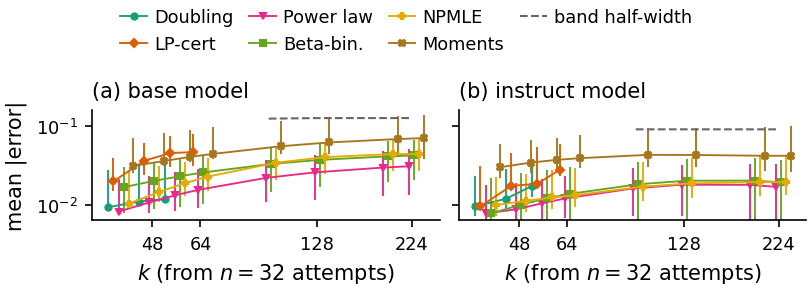

[figure] F10_per_seed_errors: layout audit OK {"n_text": 21, "text_overlaps": 0}


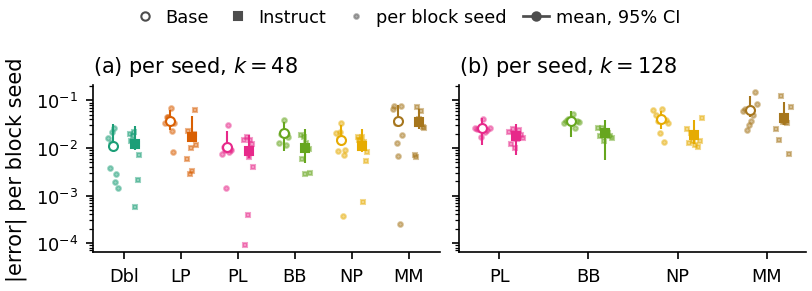

In [27]:
# Figures F9 (main baseline comparison) and F10 (per-seed distributions) [analysis]
_N9 = [nm for nm in METHOD_ORDER if nm != "Chen et al."]
fig, axes = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained", sharey=True)
f9 = {"k": E4_KS}
for ax, mk, lab in zip(axes, MODEL_KEYS, ("(a)", "(b)")):
    for i, nm in enumerate(_N9):
        pe = E4[mk]["point_err"][nm]
        ok = np.isfinite(pe).all(0)
        if not ok.any():
            continue
        mean = pe.mean(0)
        lo, hi = pct_ci(E4[mk]["agg_boot"][nm], axis=0)
        x = np.array(E4_KS, float) * (1.0 + 0.03 * (i - 2.5))
        ax.errorbar(x[ok], mean[ok], yerr=[np.maximum(mean - lo, 0)[ok], np.maximum(hi - mean, 0)[ok]],
                    fmt=METHOD_MARKERS[nm] + "-", color=METHOD_COLORS[nm], ms=3, lw=0.9, capsize=0)
        f9[f"{mk}|{nm}"] = {"k": np.array(E4_KS)[ok], "mae": mean[ok], "ci_lo": lo[ok], "ci_hi": hi[ok]}
    _bk = np.array(E4_KS) > E4_KMAX_LP
    _hw = 0.5 * (E4[mk]["band"][:, :, 1] - E4[mk]["band"][:, :, 0]).mean(0)
    ax.plot(np.array(E4_KS)[_bk], _hw[_bk], color=BOUND_COLOR, ls="--", lw=1.0)
    f9[f"{mk}|band_half_width"] = {"k": np.array(E4_KS)[_bk], "half_width": _hw[_bk]}
    ax.set_xscale("log", base=2); ax.set_yscale("log")
    ax.set_xticks([48, 64, 128, 224]); ax.set_xticklabels(["48", "64", "128", "224"]); ax.minorticks_off()
    ax.set_xlabel("$k$ (from $n=32$ attempts)")
    panel_label(ax, f"{lab} {MODEL_LABELS[mk].lower()} model")
axes[0].set_ylabel("mean |error|")
_h = [Line2D([], [], color=METHOD_COLORS[nm], marker=METHOD_MARKERS[nm], ms=3, lw=0.9, label=SHORT[nm]) for nm in _N9]
_h.append(Line2D([], [], color=BOUND_COLOR, ls="--", lw=1.0, label="band half-width"))
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=4)
finish_figure(fig, "F9_baseline_comparison", f9, "Extrapolation error of every estimator against the held-out reference.")

fig, axes = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained", sharey=True)
f10 = {}
for ax, k, lab in zip(axes, (48, 128), ("(a)", "(b)")):
    j = E4_KS.index(k)
    names = [nm for nm in _N9 if np.isfinite(E4["instruct"]["point_err"][nm][:, j]).all()]
    for i, nm in enumerate(names):
        for s, mk in enumerate(MODEL_KEYS):
            e = np.maximum(E4[mk]["point_err"][nm][:, j], 1e-6)
            x0 = i + (s - 0.5) * 0.38
            ax.plot(x0 + np.linspace(-0.08, 0.08, NB), e, ls="none", marker=MODEL_MARKERS[mk], ms=2.2,
                    color=METHOD_COLORS[nm], alpha=0.45)
            lo, hi = pct_ci(E4[mk]["agg_boot"][nm][:, j])
            mu = float(e.mean())
            ax.errorbar([x0], [mu], yerr=[[max(mu - lo, 0)], [max(hi - mu, 0)]], fmt=MODEL_MARKERS[mk], ms=4.3,
                        mfc="white" if mk == "base" else METHOD_COLORS[nm], mec=METHOD_COLORS[nm], color=METHOD_COLORS[nm],
                        capsize=0, lw=1.0)
            f10[f"k{k}|{mk}|{nm}"] = {"per_block_abs_error": e, "mean": mu, "ci": [lo, hi]}
    ax.set_xticks(range(len(names))); ax.set_xticklabels([CODE2[nm] for nm in names])
    ax.set_yscale("log")
    panel_label(ax, f"{lab} per seed, $k={k}$")
axes[0].set_ylabel("|error| per block seed")
_h = [Line2D([], [], color="#4d4d4d", marker="o", mfc="white", ls="none", ms=4, label="Base"),
      Line2D([], [], color="#4d4d4d", marker="s", ls="none", ms=4, label="Instruct"),
      Line2D([], [], color="#4d4d4d", marker="o", ls="none", ms=2.2, alpha=0.45, label="per block seed"),
      Line2D([], [], color="#4d4d4d", marker="o", ls="-", ms=4, label="mean, 95% CI")]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=4)
finish_figure(fig, "F10_per_seed_errors", f10, "Per-seed (block) absolute errors with problem-level bootstrap intervals.")

Figure F9 (baseline comparison). Mean absolute extrapolation error, over the eight block seeds, of every estimator computed from one 32-attempt block: (a) base model; (b) instruct model. The target is the unbiased estimate from the other 224 attempts; bars are problem-level bootstrap 95% CIs (2,000 resamples, refitting every estimator). The doubling estimator is shown for $k<64$ and the LP estimator for $k\le64$; beyond $k=2n$ the dashed grey line is the mean half-width of the identification band from the same block, which is what the counts certify there.

Figure F10 (per-seed distribution): (a) per seed at $k=48$; (b) per seed at $k=128$. Light markers are the eight per-block absolute errors (open = base, filled = instruct); solid markers are their mean with a bootstrap 95% CI. The paired tests are in T3b and `logs/e4_estimator_comparisons.csv`.

Estimator codes: Dbl doubling (ours), LP LP-cert (ours), PL power law, BB Beta-binomial, NP NPMLE, MM moment matching.

[resume] e4_bands_1e894fd9be_7_dkwcp: loaded from checkpoint
Forecasts from block 1 that the counts contradict (outside the 95% PI-band):
   model       estimator  k values > n  outside 95% band (32 att.)  outside 95% band (256 att.)
    base       Power law            19                           0                            0
    base   Beta-binomial            19                           0                            0
    base           NPMLE            19                           0                            2
    base Moment matching            19                           0                            5
    base  LP-cert (ours)             3                           0                            0
instruct       Power law            19                           0                            0
instruct   Beta-binomial            19                           0                            0
instruct           NPMLE            19                           0                            

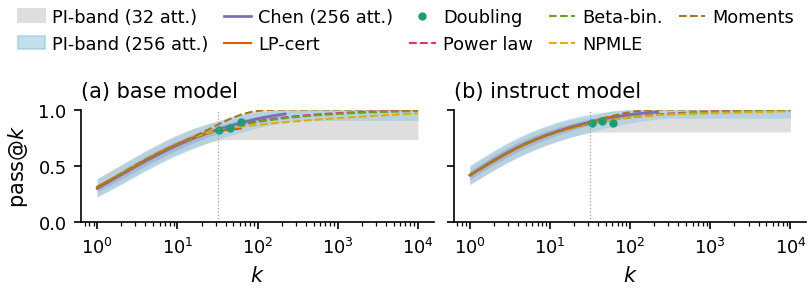

[figure] F16_piband_coverage: layout audit OK {"n_text": 8, "text_overlaps": 0}


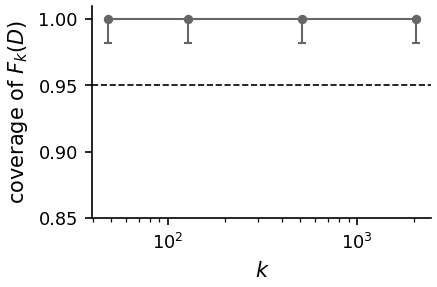

In [28]:
# 7.4b E4: PI-bands out to k = 10^4 with parametric forecasts, and semi-synthetic PI-band coverage -> F5, F16 [analysis]
KGRID = np.unique(np.round(np.geomspace(1, 1e4, 12 if SMOKE else 30)).astype(int))


def _e4_bands():
    out = {}
    names = [nm for nm in METHOD_ORDER if nm != "Chen et al."]
    for mk in MODEL_KEYS:
        C = C_ALL[mk]
        b32 = pi_band(hist_counts(CB[mk][:, 0], N_BLK), N_BLK, KGRID, DELTA)
        b256 = pi_band(hist_counts(C, N_ATT), N_ATT, KGRID, DELTA)
        fore = estimate_all(hist_counts(CB[mk][:, 0], N_BLK), N_BLK, list(KGRID), M_EFF, names=names, G=CFG["LP_G_SWEEP"])
        kk = KGRID[KGRID <= N_ATT]
        cv = np.stack([chen_fail_table(N_ATT, k)[C] for k in kk], 1)
        lo, hi = pct_ci(W_BOOT @ cv / M_EFF)
        out[mk] = {"b32": b32, "b256": b256, "fore": {nm: v[0] for nm, v in fore.items()}, "chen_k": kk,
                   "chen": cv.mean(0), "chen_lo": lo, "chen_hi": hi}
    lp_cache_flush()
    return out


BANDS = cached(f"e4_bands_{DATA_TAG}_{len(METHOD_ORDER)}_{M3_TAG}", _e4_bands)
_orows = []
for mk in MODEL_KEYS:
    b32, b256, beyond = BANDS[mk]["b32"], BANDS[mk]["b256"], KGRID > N_BLK
    for nm in FORECASTERS + ["LP-cert (ours)"]:
        F = BANDS[mk]["fore"][nm]
        o32 = (F < b32[:, 0] - 1e-9) | (F > b32[:, 1] + 1e-9)
        o256 = (F < b256[:, 0] - 1e-9) | (F > b256[:, 1] + 1e-9)
        _orows.append({"model": mk, "estimator": nm, "k values > n": int((beyond & np.isfinite(F)).sum()),
                       "outside 95% band (32 att.)": int(o32[beyond].sum()), "outside 95% band (256 att.)": int(o256[beyond].sum())})
OUTSIDE = pd.DataFrame(_orows)
OUTSIDE.to_csv(os.path.join(LOG_DIR, "e4_forecasts_outside_bands.csv"), index=False)
print("Forecasts from block 1 that the counts contradict (outside the 95% PI-band):\n" + OUTSIDE.to_string(index=False))
COV_KS = [48, 128, 512, 2048]


def _coverage():
    rng = np.random.default_rng(SEED + 501)
    p_sim = PT["instruct"]
    pi = bernstein_matrix(N_BLK, p_sim).mean(0)
    truth = np.array([float(np.mean(fail_k(p_sim, k))) for k in COV_KS])
    hits = np.zeros((CFG["R_COV"], len(COV_KS)), bool)
    for r in range(CFG["R_COV"]):
        band = pi_band(rng.multinomial(M_EFF, pi / pi.sum()).astype(float), N_BLK, COV_KS, DELTA)
        hits[r] = (band[:, 0] <= truth + 1e-12) & (truth <= band[:, 1] + 1e-12)
    return {"truth": truth, "hits": hits}


COV = cached(f"e4_coverage_{DATA_TAG}_{M3_TAG}", _coverage)
_cov = COV["hits"].mean(0)
_clo, _chi = cp_interval(COV["hits"].sum(0), COV["hits"].shape[0], 0.05)
VERDICTS["PI-band coverage (semi-synthetic)"] = "PASS" if bool(np.all(_chi >= 0.95)) else "FAIL"
print("PI-band coverage of F_k(D) on simulated data: " + ", ".join(f"k={k}: {c:.3f} [{a:.3f}, {b:.3f}]"
                                                         for k, c, a, b in zip(COV_KS, _cov, _clo, _chi))
      + f" -> {VERDICTS['PI-band coverage (semi-synthetic)']}")

fig, axes = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained", sharey=True)
f5 = {"k": KGRID}
for ax, mk, lab in zip(axes, MODEL_KEYS, ("(a)", "(b)")):
    d = BANDS[mk]
    ax.fill_between(KGRID, 1 - d["b32"][:, 1], 1 - d["b32"][:, 0], color="#dedede", lw=0)
    ax.fill_between(KGRID, 1 - d["b256"][:, 1], 1 - d["b256"][:, 0], color="#9ecae1", alpha=0.6, lw=0)
    ax.fill_between(d["chen_k"], 1 - d["chen_hi"], 1 - d["chen_lo"], color=METHOD_COLORS["Chen et al."], alpha=0.25, lw=0)
    ax.plot(d["chen_k"], 1 - d["chen"], color=METHOD_COLORS["Chen et al."], lw=1.3)
    for nm in ["LP-cert (ours)"] + FORECASTERS:
        _sel = (KGRID <= CFG["LP_T_MAX"] * N_BLK) if nm == "LP-cert (ours)" else np.ones(len(KGRID), bool)   # LP reported only for t <= 2
        ax.plot(KGRID[_sel], 1 - d["fore"][nm][_sel], color=METHOD_COLORS[nm], lw=1.0, ls="-" if nm == "LP-cert (ours)" else "--")
    dbl = d["fore"]["Doubling (ours)"]
    okd = np.isfinite(dbl)
    ax.plot(KGRID[okd], 1 - dbl[okd], ls="none", marker="o", ms=3, color=METHOD_COLORS["Doubling (ours)"])
    ax.axvline(N_BLK, color="#9e9e9e", lw=0.6, ls=":")
    ax.set_xscale("log"); ax.set_ylim(0, 1.0); ax.set_xlabel("$k$")
    panel_label(ax, f"{lab} {MODEL_LABELS[mk].lower()} model")
    f5[mk] = {"pi_band_n32_pass": [1 - d["b32"][:, 1], 1 - d["b32"][:, 0]], "pi_band_n256_pass": [1 - d["b256"][:, 1], 1 - d["b256"][:, 0]],
              "chen_k": d["chen_k"], "chen_pass": 1 - d["chen"], "chen_ci_pass": [1 - d["chen_hi"], 1 - d["chen_lo"]],
              "forecasts_pass": {nm: 1 - v for nm, v in d["fore"].items()}}
axes[0].set_ylabel("pass@$k$")
_h = [Patch(color="#dedede", label="PI-band (32 att.)"), Patch(color="#9ecae1", alpha=0.6, label="PI-band (256 att.)"),
      Line2D([], [], color=METHOD_COLORS["Chen et al."], lw=1.3, label="Chen (256 att.)"),
      Line2D([], [], color=METHOD_COLORS["LP-cert (ours)"], lw=1.0, label="LP-cert"),
      Line2D([], [], color=METHOD_COLORS["Doubling (ours)"], marker="o", ls="none", ms=3, label="Doubling")]
_h += [Line2D([], [], color=METHOD_COLORS[nm], lw=1.0, ls="--", label=SHORT[nm]) for nm in FORECASTERS]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=5)
finish_figure(fig, "F5_passk_bands_forecasts", f5, "Identification bands for pass@k with parametric forecasts from 32 attempts.")

fig, ax = plt.subplots(figsize=FIG_SINGLE, layout="constrained")
ax.errorbar(COV_KS, _cov, yerr=[np.maximum(_cov - _clo, 0), np.maximum(_chi - _cov, 0)], fmt="o-", color=BOUND_COLOR, ms=3.5, lw=1.0, capsize=2)
ax.axhline(0.95, color="#000000", lw=0.8, ls="--")
ax.set_xscale("log"); ax.set_ylim(min(0.85, float(_clo.min()) - 0.02), 1.01)
ax.set_xlabel("$k$"); ax.set_ylabel("coverage of $F_k(D)$")
finish_figure(fig, "F16_piband_coverage", {"k": COV_KS, "coverage": _cov, "cp_lo": _clo, "cp_hi": _chi, "nominal": 0.95,
                                           "replicates": int(COV["hits"].shape[0]), "truth_F": COV["truth"]},
              "Semi-synthetic coverage of the 95% PI-band.")

Figure F5 (identification bands). pass@$k$ for (a) the base model and (b) the instruct model.
- Bands: the 95% partial-identification band (DKW band and per-cell boxes, each at $\delta/2$) from the first 32-attempt block (grey) and from all 256 attempts (blue).
- Reference: Chen et al.'s unbiased curve from all 256 attempts (purple, with bootstrap 95% CI).
- Forecasts from the same 32-attempt block: the LP estimator (solid, $k\le 2n$ only), the doubling estimator (dots, $k<64$), and the four parametric or plug-in families (dashed).

A forecast outside the grey band is contradicted by the counts it was fitted on; one outside the blue band is contradicted by the full data. The counts are tabulated above and saved to `logs/e4_forecasts_outside_bands.csv`.

Figure F16 (PI-band coverage). Coverage of $F_k(D)$ by the 95% band over simulated datasets drawn from the instruct model's empirical success-rate distribution, with Clopper–Pearson 95% intervals. Coverage should not fall below 0.95.

[resume] e5v3_d649bc4819_4_dkwcp: loaded from checkpoint
[resume] e5v3_86f74a0d0d_4_dkwcp: loaded from checkpoint
E5 pair: Qwen2.5-1.5B vs Qwen2.5-1.5B-SimpleRL-Zoo on GSM8K, m = 300, prompt template abel (probe on GSM8K train problems)
[G1, lenient] pass@1 base 0.461, RL 0.757; RL - base: pass@1 0.297 [0.270, 0.323], pass@256 -0.017 [-0.033, 0.000]; crossing k* = 29.120 (95% 17.266-79.437); RL significantly ahead up to k = 17, base significantly ahead from k = 98
      reversal beyond 2n for n = [8, 16, 32]; identified from those n: none; forecast k* from 32 attempts: PL 61.271, BB 27.653, NP --, MM 32.804 -> PASS: not identified from n = [8, 16, 32]
[G2, strict] pass@1 base 0.312, RL 0.734; RL - base: pass@1 0.422 [0.393, 0.450], pass@256 -0.023 [-0.043, -6.67e-03]; crossing k* = 46.434 (95% 26.953-124.325); RL significantly ahead up to k = 26, base significantly ahead from k = 126
      reversal beyond 2n for n = [8, 16, 32]; identified from those n: none; forecast k* from 32 attemp

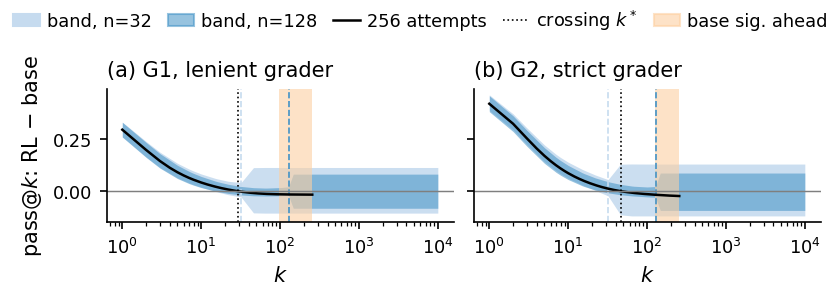

In [29]:
# 7.5 E5 (one pair, the beyond-n point) [analysis]: base vs its zero-RL counterpart under both graders; is a reversal that lies beyond 2n identified from n attempts?
E5_KS = np.unique(np.concatenate([np.round(np.geomspace(1, 1e4, 10 if SMOKE else 25)), CFG["E5_NS"]]).astype(int))
E5_FINE_K = np.arange(1, N_ATT + 1)
_e5a, _e5b = E5_PAIR
E5_M = min(SDATA[_e5a]["m"], SDATA[_e5b]["m"])
E5_LABELS = {"base": MODEL_REG[STREAM_REG[_e5a]["model"]]["label"], "rl": MODEL_REG[STREAM_REG[_e5b]["model"]]["label"]}
E5_GRADERS = (("G1", "Y1", "lenient"), ("G2", "Y2", "strict"))


def _first_cross(k, d):
    """First k at which d turns from positive to non-positive (interpolated in log k), or nan if it never does."""
    k, d = np.asarray(k, float), np.asarray(d, float)
    for i in range(1, len(d)):
        if d[i - 1] > 0 >= d[i]:
            if d[i - 1] == d[i]:
                return float(k[i])
            x0, x1 = math.log(k[i - 1]), math.log(k[i])
            return float(math.exp(x0 + (x1 - x0) * d[i - 1] / (d[i - 1] - d[i])))
    return float("nan")


def _paired_band(YB, YR, n, ks, W):
    """Simultaneous 95% band over ks (all <= n) for pass@k(RL) - pass@k(base) from the first n attempts of each model:
    per-problem paired unbiased estimates (Chen et al., 2021), problem-level bootstrap, max-|t| calibration over ks."""
    cb_, cr_ = YB[:, :n].sum(1).astype(int), YR[:, :n].sum(1).astype(int)
    per = np.stack([chen_fail_table(n, int(k))[cb_] - chen_fail_table(n, int(k))[cr_] for k in ks], 1)
    m = per.shape[0]
    d = per.mean(0)
    bs = W @ per / m
    se = np.maximum(bs.std(axis=0, ddof=1), 1e-12)
    crit = float(np.quantile(np.max(np.abs(bs - d[None, :]) / se[None, :], axis=1), 0.95))
    return d - crit * se, d + crit * se


def _e5(YB, YR, m):
    """For k <= n the difference is point-identified and gets a paired simultaneous band; beyond n only the difference
    of the two identification bands (delta/2 each) is available. Each part holds with probability 0.95."""
    out = {"ks": E5_KS, "m": m}
    W = get_wboot(m)
    for n in CFG["E5_NS"]:
        inside, beyond = E5_KS[E5_KS <= n], E5_KS[E5_KS > n]
        dlo, dhi = np.empty(len(E5_KS)), np.empty(len(E5_KS))
        if inside.size:
            dlo[: inside.size], dhi[: inside.size] = _paired_band(YB, YR, n, inside, W)
        if beyond.size:
            bands = {key: pi_band(hist_counts(Y[:, :n].sum(1), n), n, list(beyond), DELTA / 2) for key, Y in (("base", YB), ("rl", YR))}
            dlo[inside.size:] = (1 - bands["rl"][:, 1]) - (1 - bands["base"][:, 0])
            dhi[inside.size:] = (1 - bands["rl"][:, 0]) - (1 - bands["base"][:, 1])
        excl = (dlo > 0) | (dhi < 0)
        pos, neg = E5_KS[dlo > 0], E5_KS[dhi < 0]
        out[n] = {"dlo": dlo, "dhi": dhi, "excl": excl, "k_sign": int(E5_KS[excl].max()) if excl.any() else 0,
                  "sign": (1 if dlo[excl][-1] > 0 else -1) if excl.any() else 0,
                  "rl_ahead_kmax": int(pos.max()) if pos.size else 0, "base_ahead_kmin": int(neg.min()) if neg.size else 0,
                  "crossing_identified": bool(pos.size and neg.size and pos.min() < neg.max())}
    CBs, CRs = YB.sum(1).astype(int), YR.sum(1).astype(int)
    per = np.stack([chen_fail_table(N_ATT, k)[CBs] - chen_fail_table(N_ATT, k)[CRs] for k in E5_FINE_K], 1)   # pass@k: RL - base
    d = per.mean(0)
    dbs = W @ per / m
    lo, hi = pct_ci(dbs)
    kb = np.array([_first_cross(E5_FINE_K, row) for row in dbs[: min(2000, dbs.shape[0])]])
    out["truth"] = {"k": E5_FINE_K, "diff": d, "lo": lo, "hi": hi}
    out["k_star"] = _first_cross(E5_FINE_K, d)
    out["k_star_boot_frac"] = float(np.mean(np.isfinite(kb)))
    out["k_star_ci"] = ([float(np.nanquantile(kb, 0.025)), float(np.nanquantile(kb, 0.975))] if np.isfinite(kb).sum() >= 20
                        else [float("nan"), float("nan")])
    pos, neg = np.flatnonzero(lo > 0), np.flatnonzero(hi < 0)
    out["significant_cross"] = bool(pos.size and neg.size and pos.min() < neg.max())
    out["sig_pos_kmax"] = int(E5_FINE_K[pos].max()) if pos.size else 0
    out["sig_neg_kmin"] = int(E5_FINE_K[neg].min()) if neg.size else 0
    kf = np.unique(np.round(np.geomspace(1, 1e4, 60)).astype(int))
    fb = estimate_all(hist_counts(YB[:, :N_BLK].sum(1), N_BLK), N_BLK, list(kf), m, names=FORECASTERS)
    fr = estimate_all(hist_counts(YR[:, :N_BLK].sum(1), N_BLK), N_BLK, list(kf), m, names=FORECASTERS)
    out["forecast"] = {nm: {"k": kf, "diff": fb[nm][0] - fr[nm][0], "k_star": _first_cross(kf, fb[nm][0] - fr[nm][0])}
                       for nm in FORECASTERS}
    return out


E5 = None
E5G, E5_SUMMARY = {}, {}
if E5_M < CFG["M_MIN_ANALYSIS"]:
    print(f"E5 skipped: the RL pair has only m = {E5_M} problems in common (need {CFG['M_MIN_ANALYSIS']}).")
    for _g, _key, _desc in E5_GRADERS:
        VERDICTS[f"C4 reversal beyond 2n not identified ({_g})"] = "NOT RUN (pair not sampled yet)"
else:
    for _g, _key, _desc in E5_GRADERS:
        _YB, _YR = SDATA[_e5a][_key][:E5_M], SDATA[_e5b][_key][:E5_M]
        E5G[_g] = cached(f"e5v3_{data_tag(_YB, _YR)}_{len(FORECASTERS)}_{M3_TAG}", lambda YB=_YB, YR=_YR: _e5(YB, YR, E5_M))
    E5 = E5G["G1"]   # the grader used everywhere else; G2 is the verifier check of this section
    print(f"E5 pair: {E5_LABELS['base']} vs {E5_LABELS['rl']} on GSM8K, m = {E5_M}, prompt template {RL_TEMPLATE['name']} "
          f"({RL_TEMPLATE.get('decided_by')})")
    _sign_rows = []
    for _g, _key, _desc in E5_GRADERS:
        R = E5G[_g]
        _tr = R["truth"]
        k_rev = R["sig_neg_kmin"]                      # first k at which the base model is significantly ahead (256 attempts)
        beyond = [n for n in CFG["E5_NS"] if k_rev and k_rev > 2 * n]
        ident = {n: bool(R[n]["base_ahead_kmin"]) for n in CFG["E5_NS"]}
        E5_SUMMARY[_g] = {"pass1": (_tr["diff"][0], _tr["lo"][0], _tr["hi"][0]), "pass256": (_tr["diff"][-1], _tr["lo"][-1], _tr["hi"][-1]),
                          "k_star": R["k_star"], "k_star_ci": R["k_star_ci"], "rl_ahead_to": R["sig_pos_kmax"], "k_rev": k_rev,
                          "significant_reversal": R["significant_cross"], "n_beyond": beyond, "identified_from": ident,
                          "forecast_k_star": {nm: R["forecast"][nm]["k_star"] for nm in FORECASTERS},
                          "pass1_rl": float(SDATA[_e5b][_key][:E5_M].mean()), "pass1_base": float(SDATA[_e5a][_key][:E5_M].mean())}
        if not R["significant_cross"]:
            VERDICTS[f"C4 reversal beyond 2n not identified ({_g})"] = "NOT OBSERVED (no significant reversal within k <= 256)"
        elif not beyond:
            VERDICTS[f"C4 reversal beyond 2n not identified ({_g})"] = "NOT TESTABLE (the reversal starts within 2n for every n)"
        else:
            _bad = [n for n in beyond if ident[n]]
            VERDICTS[f"C4 reversal beyond 2n not identified ({_g})"] = (
                f"PASS: not identified from n = {beyond}" if not _bad else f"FAIL: identified from n = {_bad}")
        for n in CFG["E5_NS"]:
            _sign_rows.append({"grader": _g, "n": n, "k_sign": R[n]["k_sign"], "rl_ahead_up_to_k": R[n]["rl_ahead_kmax"],
                               "base_ahead_from_k": R[n]["base_ahead_kmin"], "reversal_beyond_2n": n in beyond,
                               "reversal_identified": ident[n]})
        pd.DataFrame({"k": _tr["k"], "pass_rl_minus_base": _tr["diff"], "ci_lo": _tr["lo"], "ci_hi": _tr["hi"]}).to_csv(
            os.path.join(LOG_DIR, f"e5_difference_256_attempts_{_g}.csv"), index=False)
        S_ = E5_SUMMARY[_g]
        print(f"[{_g}, {_desc}] pass@1 base {S_['pass1_base']:.3f}, RL {S_['pass1_rl']:.3f}; RL - base: pass@1 {fmt_ci(*S_['pass1'], 3)}, "
              f"pass@256 {fmt_ci(*S_['pass256'], 3)}; crossing k* = {fmt(R['k_star'], 3)} (95% {fmt(R['k_star_ci'][0], 3)}-"
              f"{fmt(R['k_star_ci'][1], 3)}); RL significantly ahead up to k = {R['sig_pos_kmax'] or '--'}, base significantly ahead "
              f"from k = {k_rev or '--'}")
        print(f"      reversal beyond 2n for n = {beyond or 'none'}; identified from those n: "
              f"{[n for n in beyond if ident[n]] or 'none'}; forecast k* from 32 attempts: "
              + ", ".join(f"{CODE2[nm]} {fmt(S_['forecast_k_star'][nm], 3)}" for nm in FORECASTERS)
              + f" -> {VERDICTS[f'C4 reversal beyond 2n not identified ({_g})']}")
    pd.DataFrame(_sign_rows).to_csv(os.path.join(LOG_DIR, "e5_sign_horizons.csv"), index=False)

    def _cell(g, what):
        S_ = E5_SUMMARY[g]
        if what == "k*":
            return f"{fmt(S_['k_star'], 3)} ({fmt(S_['k_star_ci'][0], 3)}-{fmt(S_['k_star_ci'][1], 3)})"
        if what == "rev":
            return str(S_["k_rev"] or "none")
        if what == "beyond":
            return ", ".join(f"{n}: {'yes' if S_['identified_from'][n] else 'no'}" for n in S_["n_beyond"]) or "--"
        return ""

    _t11 = [["pass@1 base / RL"] + [f"{E5_SUMMARY[g]['pass1_base']:.3f} / {E5_SUMMARY[g]['pass1_rl']:.3f}" for g, _, _ in E5_GRADERS],
            ["pass@256, RL - base"] + [fmt_ci(*E5_SUMMARY[g]["pass256"], 3) for g, _, _ in E5_GRADERS],
            ["Crossing k* (256 attempts, 95%)"] + [_cell(g, "k*") for g, _, _ in E5_GRADERS],
            ["Base significantly ahead from k"] + [_cell(g, "rev") for g, _, _ in E5_GRADERS],
            ["n with reversal beyond 2n: identified?"] + [_cell(g, "beyond") for g, _, _ in E5_GRADERS]]
    _t11 += [[f"Forecast k* from n = 32, {SHORT[nm]}"] + [fmt(E5_SUMMARY[g]["forecast_k_star"][nm], 3) for g, _, _ in E5_GRADERS]
             for nm in FORECASTERS]
    T11 = pd.DataFrame(_t11, columns=["Quantity", "G1 (lenient)", "G2 (strict)"])
    save_table(T11, "T11_crossing_pair",
               f"E5, {E5_LABELS['base']} against {E5_LABELS['rl']} on GSM8K (m = {E5_M}, same prompt), under both graders. "
               "The reversal is the range of k where the base model is significantly ahead in the 256-attempt data; for every n "
               "with 2n below its start, the table says whether the bands from the first n attempts identify it (paired "
               "simultaneous band for k <= n, difference of identification bands at delta/2 per model beyond n). Forecast k*: "
               "the crossing each family predicts from the first 32 attempts (-- = none up to k = 10^4).",
               col_format="p{1.9in}p{1.7in}p{1.7in}", width_in=5.4)
    print(T11.to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained", sharey=True)
    f6 = {"k": E5_KS, "pair": E5_LABELS, "template": RL_TEMPLATE}
    for ax, (_g, _key, _desc) in zip(axes, E5_GRADERS):
        R = E5G[_g]
        f6[_g] = {"bands": {}}
        for n, col, al in ((32, "#c6dbef", 0.9), (128, "#4292c6", 0.55)):
            if n in R:
                ax.fill_between(E5_KS, R[n]["dlo"], R[n]["dhi"], color=col, alpha=al, lw=0)
                ax.axvline(n, color=col, lw=0.8, ls="--")
                f6[_g]["bands"][str(n)] = {"diff_lo": R[n]["dlo"], "diff_hi": R[n]["dhi"], "base_ahead_kmin": R[n]["base_ahead_kmin"]}
        ax.plot(R["truth"]["k"], R["truth"]["diff"], color="#000000", lw=1.2)
        ax.axhline(0.0, color="#7f7f7f", lw=0.7)
        if np.isfinite(R["k_star"]):
            ax.axvline(R["k_star"], color="#000000", lw=0.8, ls=":")
        if R["sig_neg_kmin"]:
            ax.axvspan(R["sig_neg_kmin"], N_ATT, color="#fdd0a2", alpha=0.6, lw=0)
        ax.set_xscale("log"); ax.set_xlabel("$k$")
        panel_label(ax, f"(a) {_g}, {_desc} grader" if _g == "G1" else f"(b) {_g}, {_desc} grader")
        f6[_g]["truth"] = {"k": R["truth"]["k"], "diff": R["truth"]["diff"], "ci": [R["truth"]["lo"], R["truth"]["hi"]],
                           "k_star": R["k_star"], "base_ahead_from": R["sig_neg_kmin"]}
        f6[_g]["forecast_k_star"] = E5_SUMMARY[_g]["forecast_k_star"]
    axes[0].set_ylabel("pass@$k$: RL − base")
    _h = [Patch(color="#c6dbef", label="band, n=32"), Patch(color="#4292c6", alpha=0.55, label="band, n=128"),
          Line2D([], [], color="#000000", lw=1.2, label="256 attempts"), Line2D([], [], color="#000000", lw=0.8, ls=":", label="crossing $k^*$"),
          Patch(color="#fdd0a2", alpha=0.6, label="base sig. ahead")]
    shared_legend(fig, _h, [h.get_label() for h in _h], ncol=5)
    finish_figure(fig, "F6_sign_identification", f6, "Difference bands (RL minus base) under the lenient and the strict grader.")

Figure F6 (E5, the beyond-$n$ point; Qwen2.5-1.5B against its zero-RL counterpart from SimpleRL-Zoo, same prompt, $m=300$).
- (a) G1, lenient grader: the band for pass@$k$(RL) − pass@$k$(base) from the first $n=32$ (light) and $n=128$ (dark) attempts. Left of each dashed line $k=n$ it is a paired simultaneous 95% band built from per-problem unbiased estimates; right of it, the difference of the two models' identification bands at level $\delta/2$ each. The black curve is the difference of Chen et al.'s unbiased curves from all 256 attempts, the dotted line its crossing $k^*$, and the orange shading the range of $k$ where the base model is significantly ahead in the 256-attempt data.
- (b) G2, strict grader: the same.

Where the shaded range starts beyond $2n$, the band from $n$ attempts cannot exclude zero there. T11 gives both graders side by side, with the crossing each forecast family predicts from 32 attempts.

[resume] ab1_lp_design: loaded from checkpoint
[resume] ab2_1e894fd9be: loaded from checkpoint
  k  lam_mult     G      cert   bias   slack      range  lp_seconds
 48    0.0000  2000    0.0914 0.0000  0.0003     1.5000      0.2079
 48    0.0000 10000    0.0914 0.0000  0.0003     1.5000      1.2781
 48    0.0000 50000    0.0914 0.0000  0.0003     1.5000      6.8881
 48    1.0000  2000    0.0907 0.0034  0.0003     1.4330      1.0529
 48    1.0000 10000    0.0907 0.0035  0.0003     1.4326      4.5092
 48    1.0000 50000    0.0907 0.0034  0.0003     1.4327     21.0417
 48    4.0000  2000    0.1200 0.0544  0.0002     1.0754      2.0964
 48    4.0000 10000    0.1202 0.0547  0.0002     1.0742     26.2078
 48    4.0000 50000    0.1201 0.0547  0.0002     1.0745    142.3477
128    0.0000  2000 5081.2186 0.0001 13.3507 83440.7224      0.2976
128    0.0000 10000 5047.5700 0.0001 13.2622 82888.1648      1.5444
128    0.0000 50000 5013.4026 0.0001 13.1725 82327.0880     12.6393
128    1.0000  2000  

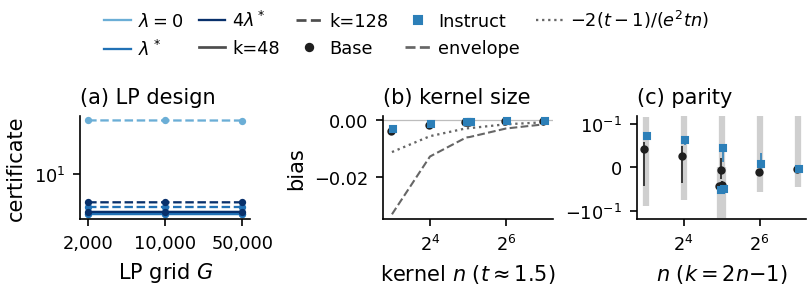

In [30]:
# 7.6 Ablations: Ab1 (LP design: lambda and grid size) and Ab2 (kernel size and parity, no new samples) -> F11 [analysis]
AB1_GS = [500, 2000] if SMOKE else [2000, 10000, 50000]
AB1_KS, AB1_LAMS = [48, 128], [0.0, 1.0, 4.0]


def _ab1():
    rows = []
    for k in AB1_KS:
        for lm in AB1_LAMS:
            for G in AB1_GS:
                r = lp_estimator(N_BLK, k, 500, DELTA, lm, G)
                rows.append({"k": k, "lam_mult": lm, "G": G, "cert": r["cert"], "bias": r["bias"], "slack": r["slack"],
                             "range": r["range"], "lp_seconds": r["lp_seconds"]})
    lp_cache_flush()
    return pd.DataFrame(rows)


AB1 = cached("ab1_lp_design", _ab1)
AB2_NS = [8, 16, 31, 32, 33, 64, 128]


def _ab2(Ymap):
    rows = []
    for mk in MODEL_KEYS:
        C = np.asarray(Ymap[mk]).sum(1).astype(int)
        for n in AB2_NS:
            for kind, k in (("t~1.5", int(round(1.5 * n))), ("k=2n-1", 2 * n - 1)):
                v = m6_contrast_values(C, N_ATT, n, k)
                bs = boot_mean(v)
                lo, hi = pct_ci(bs)
                L, U = signed_envelope(n, k)
                rows.append({"model": mk, "n": n, "k": k, "kind": kind, "t": k / n, "contrast": float(v.mean()), "lo": float(lo),
                             "hi": float(hi), "L": L, "U": U, "inside": bool(hi >= L and lo <= U)})
    return pd.DataFrame(rows)


AB2 = cached(f"ab2_{DATA_TAG}", lambda: _ab2(YG1))
AB1.to_csv(os.path.join(LOG_DIR, "ab1_lp_design.csv"), index=False)
AB2.to_csv(os.path.join(LOG_DIR, "ab2_kernel_parity.csv"), index=False)
print(AB1.to_string(index=False, float_format=lambda z: f"{z:.4f}"))
_blow = all(AB1[(AB1["k"] == k) & (AB1["lam_mult"] == 0.0) & (AB1["G"] == G)]["cert"].iloc[0] >
            AB1[(AB1["k"] == k) & (AB1["lam_mult"] == 1.0) & (AB1["G"] == G)]["cert"].iloc[0] + 1e-9 for k in AB1_KS for G in AB1_GS)
_gs = sorted(AB1_GS)
_settle = all(abs(AB1[(AB1["k"] == k) & (AB1["lam_mult"] == 1.0) & (AB1["G"] == _gs[-1])]["cert"].iloc[0] /
                  AB1[(AB1["k"] == k) & (AB1["lam_mult"] == 1.0) & (AB1["G"] == _gs[-2])]["cert"].iloc[0] - 1) < 0.05 for k in AB1_KS)
VERDICTS["Ab1: lambda=0 certificate exceeds lambda*"] = "YES" if _blow else "NO (the LP's tie-breaking kept range(h) small)"
VERDICTS["Ab1: certificate settles across G"] = "YES" if _settle else "NO"
print(f"Ab1: lambda=0 worse than lambda* everywhere: {_blow}; certificate changes < 5% between the two largest grids: {_settle}")
print(AB2.to_string(index=False, float_format=lambda z: f"{z:.5f}"))
VERDICTS["Ab2: contrast inside envelope (all kernels)"] = "PASS" if bool(AB2["inside"].all()) else "FAIL"
for mk in MODEL_KEYS:
    par = AB2[(AB2["model"] == mk) & (AB2["kind"] == "k=2n-1") & (AB2["n"].isin([31, 32, 33]))]
    print(f"Ab2 parity ({MODEL_LABELS[mk]}, share of problems with rate >= 0.9: {np.mean(PT[mk] >= 0.9):.3f}): "
          + ", ".join(f"n={int(r['n'])}: {r['contrast']:+.5f}" for _, r in par.iterrows()))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=FIG_PANEL, layout="constrained")
f11 = {"ab1": AB1.to_dict(orient="list"), "ab2": AB2.to_dict(orient="list")}
for j, lm in enumerate(AB1_LAMS):
    for k, ls in ((48, "-"), (128, "--")):
        sub = AB1[(AB1["k"] == k) & (AB1["lam_mult"] == lm)].sort_values("G")
        ax1.plot(sub["G"], sub["cert"], color=SEQ_COLORS[j + 1], ls=ls, marker="o", ms=2.5, lw=1.1)
ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_xlabel("LP grid $G$"); ax1.set_ylabel("certificate")
ax1.set_xticks(AB1_GS); ax1.set_xticklabels([f"{g:,}" for g in AB1_GS]); ax1.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
panel_label(ax1, "(a) LP design")
for j, mk in enumerate(MODEL_KEYS):
    sub = AB2[(AB2["model"] == mk) & (AB2["kind"] == "t~1.5")].sort_values("n")
    ax2.errorbar(sub["n"] * (1 + 0.04 * (j - 0.5)), sub["contrast"], yerr=[np.maximum(sub["contrast"] - sub["lo"], 0), np.maximum(sub["hi"] - sub["contrast"], 0)],
                 fmt=MODEL_MARKERS[mk], color=MODEL_COLORS[mk], ms=3, lw=0.8, capsize=0)
_s15 = AB2[(AB2["model"] == MODEL_KEYS[0]) & (AB2["kind"] == "t~1.5")].sort_values("n")
ax2.plot(_s15["n"], _s15["L"], color=BOUND_COLOR, ls="--", lw=1.0)
ax2.plot(_s15["n"], -2 * (_s15["t"] - 1) / (math.e ** 2 * _s15["t"] * _s15["n"]), color=BOUND_COLOR, ls=":", lw=1.1)
ax2.axhline(0, color="#bdbdbd", lw=0.6)
ax2.set_xscale("log", base=2); ax2.set_xlabel("kernel $n$ ($t\\approx1.5$)"); ax2.set_ylabel("bias")
panel_label(ax2, "(b) kernel size")
_s2 = AB2[(AB2["model"] == MODEL_KEYS[0]) & (AB2["kind"] == "k=2n-1")].sort_values("n")
ax3.vlines(_s2["n"], _s2["L"], np.maximum(_s2["U"], 1e-12), color="#cfcfcf", lw=3)
for j, mk in enumerate(MODEL_KEYS):
    sub = AB2[(AB2["model"] == mk) & (AB2["kind"] == "k=2n-1")].sort_values("n")
    ax3.errorbar(sub["n"] * (1 + 0.04 * (j - 0.5)), sub["contrast"], yerr=[np.maximum(sub["contrast"] - sub["lo"], 0), np.maximum(sub["hi"] - sub["contrast"], 0)],
                 fmt=MODEL_MARKERS[mk], color=MODEL_COLORS[mk], ms=3, lw=0.8, capsize=0)
ax3.set_xscale("log", base=2); ax3.set_yscale("symlog", linthresh=1e-3)
ax3.set_xlabel(r"$n$ ($k=2n{-}1$)")
tidy_symlog(ax3, 1e-3, max_per_side=1)
panel_label(ax3, "(c) parity")
_h = [Line2D([], [], color=SEQ_COLORS[j + 1], lw=1.1, label=lab) for j, lab in enumerate([r"$\lambda=0$", r"$\lambda^*$", r"$4\lambda^*$"])]
_h += [Line2D([], [], color="#4d4d4d", ls="-", label="k=48"), Line2D([], [], color="#4d4d4d", ls="--", label="k=128")]
_h += [Line2D([], [], color=MODEL_COLORS[mk], marker=MODEL_MARKERS[mk], ls="none", ms=3.5, label=MODEL_LABELS[mk]) for mk in MODEL_KEYS]
_h += [Line2D([], [], color=BOUND_COLOR, ls="--", label="envelope"), Line2D([], [], color=BOUND_COLOR, ls=":", lw=1.1, label=r"$-2(t-1)/(e^2tn)$")]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=5)
finish_figure(fig, "F11_ablations", f11, "Ablations: LP design (lambda, grid) and kernel size / parity of the doubling contrast.")

Figure F11 (ablations).
- (a) LP design (Ab1): the LP certificate at $(n,m)=(32,500)$ against grid size $G$, for $\lambda\in\{0,\lambda^*,4\lambda^*\}$, at $k=48$ (solid) and $k=128$ (dashed).
- (b) Kernel size (Ab2): the bias contrast at $t\approx1.5$ against kernel size $n$, with the lower envelope (dashed) and the second-order value of the exact supremum (dotted). Both scale like $1/n$.
- (c) Parity (Ab2): the contrast at $k=2n-1$ (symlog scale), with the signed envelope as grey bars. The sign should follow the parity of $n$ when problems with $p$ near 1 are common.

[figure] F13_data_breakdown: layout audit OK {"n_text": 26, "text_overlaps": 0}


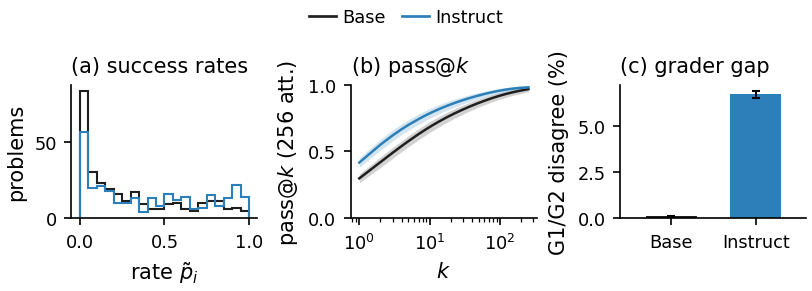

[figure] F14_efficiency: layout audit OK {"n_text": 23, "text_overlaps": 0}


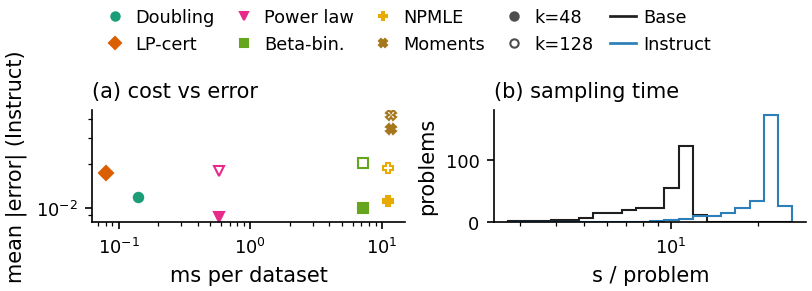

In [31]:
# 7.7 Data breakdown (F13) and efficiency (F14) [analysis]
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=FIG_PANEL, layout="constrained")
f13 = {}
_kk = np.unique(np.round(np.geomspace(1, N_ATT, 24)).astype(int))
for mk in MODEL_KEYS:
    ax1.hist(PT[mk], bins=np.linspace(0, 1, 21), histtype="step", color=MODEL_COLORS[mk], lw=1.3)
    cv = np.stack([chen_fail_table(N_ATT, k)[C_ALL[mk]] for k in _kk], 1)
    lo, hi = pct_ci(W_BOOT @ cv / M_EFF)
    ax2.fill_between(_kk, 1 - hi, 1 - lo, color=MODEL_COLORS[mk], alpha=0.2, lw=0)
    ax2.plot(_kk, 1 - cv.mean(0), color=MODEL_COLORS[mk], lw=1.2)
    f13[mk] = {"rates": PT[mk], "k": _kk, "pass_at_k": 1 - cv.mean(0), "ci": [1 - hi, 1 - lo],
               "a3_rate": A3R[mk]["rate"], "a3_ci": [A3R[mk]["lo"], A3R[mk]["hi"]]}
ax1.set_xlabel(r"rate $\tilde p_i$"); ax1.set_ylabel("problems")
ax2.set_xscale("log"); ax2.set_xlabel("$k$"); ax2.set_ylabel("pass@$k$ (256 att.)"); ax2.set_ylim(0, 1)
for j, mk in enumerate(MODEL_KEYS):
    r = A3R[mk]
    ax3.bar(j, 100 * r["rate"], color=MODEL_COLORS[mk], width=0.6)
    ax3.errorbar(j, 100 * r["rate"], yerr=[[100 * (r["rate"] - r["lo"])], [100 * (r["hi"] - r["rate"])]], color="#000000", lw=0.9, capsize=2)
ax3.set_xticks([0, 1]); ax3.set_xticklabels([MODEL_LABELS[mk] for mk in MODEL_KEYS]); ax3.set_xlim(-0.6, 1.6)
ax3.set_ylabel("G1/G2 disagree (%)")
for ax, lab in zip((ax1, ax2, ax3), ("(a) success rates", "(b) pass@$k$", "(c) grader gap")):
    panel_label(ax, lab)
_h = [Line2D([], [], color=MODEL_COLORS[mk], lw=1.3, label=MODEL_LABELS[mk]) for mk in MODEL_KEYS]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=2)
finish_figure(fig, "F13_data_breakdown", f13, "Per-problem success rates, pass@k up to 256 attempts, and grader disagreement.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
f14 = {"timings_ms": {}, "mae": {}}
for nm in _N9:
    ms_ = 1000 * E4["timings_s_per_dataset"].get(nm, np.nan)
    for k, face in ((48, None), (128, "white")):
        e = E4["instruct"]["point_err"][nm][:, E4_KS.index(k)]
        if np.isfinite(e).all() and np.isfinite(ms_):
            ax1.plot([ms_], [e.mean()], ls="none", marker=METHOD_MARKERS[nm], ms=4.5, color=METHOD_COLORS[nm],
                     mfc=face or METHOD_COLORS[nm], mec=METHOD_COLORS[nm])
            f14["mae"][f"{nm}|k{k}"] = float(e.mean())
    f14["timings_ms"][nm] = ms_
ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_xlabel("ms per dataset"); ax1.set_ylabel("mean |error| (Instruct)")
panel_label(ax1, "(a) cost vs error")
for mk in MODEL_KEYS:
    _lo_s = max(0.5, float(min(DATA[q]["sec"].min() for q in MODEL_KEYS)))
    _hi_s = float(max(DATA[q]["sec"].max() for q in MODEL_KEYS)) * 1.01
    ax2.hist(DATA[mk]["sec"], bins=np.geomspace(_lo_s, max(_hi_s, 1.01 * _lo_s), 21), histtype="step", color=MODEL_COLORS[mk], lw=1.3)
    f14[f"seconds_per_problem_{mk}"] = DATA[mk]["sec"]
ax2.set_xscale("log"); ax2.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter()); ax2.set_xlabel("s / problem" + (" (sim.)" if DRY_RUN else "")); ax2.set_ylabel("problems")
panel_label(ax2, "(b) sampling time")
_h = [Line2D([], [], color=METHOD_COLORS[nm], marker=METHOD_MARKERS[nm], ls="none", ms=4, label=SHORT[nm]) for nm in _N9]
_h += [Line2D([], [], color="#4d4d4d", marker="o", ls="none", ms=4, label="k=48"),
       Line2D([], [], color="#4d4d4d", marker="o", mfc="white", ls="none", ms=4, label="k=128")]
_h += [Line2D([], [], color=MODEL_COLORS[mk], lw=1.3, label=MODEL_LABELS[mk]) for mk in MODEL_KEYS]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=5)
for _ax in (ax1, ax2):   # no minor-tick labels on log axes (they overlapped in F14)
    _ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter()); _ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
finish_figure(fig, "F14_efficiency", f14, "Estimator runtime against accuracy, and sampling cost per problem.")

Figure F13 (data breakdown).
- (a) Success rates: the distribution of per-problem success rates over 256 attempts, for both models.
- (b) pass@$k$: Chen et al.'s unbiased estimator using all 256 attempts, with bootstrap 95% bands.
- (c) Grader gap: the G1/G2 disagreement rate (A3), with Clopper–Pearson 95% intervals.

Figure F14 (efficiency).
- (a) Cost vs error: median runtime per dataset (one histogram) of each estimator against its mean absolute error for the instruct model, at $k=48$ (filled) and $k=128$ (open; the LP estimator is not reported there). Points toward the lower left are better.
- (b) Sampling time per problem (256 attempts) on the T4, log scale. The first 77 base problems were drawn by the first-run sampler.

In [32]:
# 7.8 Corollary verdicts and Table T2 (Holm across every corollary/envelope check with a p-value) [analysis]
T2 = pd.DataFrame(T2_ROWS)
T2["p Holm"] = holm(T2["p"].to_numpy(float))
T2.to_csv(os.path.join(LOG_DIR, "t2_corollary_checks_full.csv"), index=False)
T2_TEX = T2.assign(**{"p Holm": T2["p Holm"].map(lambda z: "--" if not np.isfinite(z) else f"{z:.3f}")})[
    ["Check", "Model", "Value", "Threshold", "p Holm", "Verdict"]]
save_table(T2_TEX, "T2_corollary_checks",
           "Corollary checks. p Holm: Holm-adjusted p-value of a violation (one family over every check with a p-value). "
           "Envelope rows test the M6 bias contrast against the signed envelope M1.",
           col_format="p{1.25in}lp{0.9in}p{0.85in}rl", width_in=5.45)
print(T2_TEX.to_string(index=False))
print("\n=== Falsifiable corollary verdicts ===")
for key in [k for k in VERDICTS if k.startswith("Corollary")]:
    print(f"  {key:<42s} {VERDICTS[key]}")
for mk in MODEL_KEYS:
    c1, c2 = E2[mk]["cor1"], E2[mk]["cor2"]
    print(f"  {MODEL_LABELS[mk]}: Corollary 1 measured {c1['mean']:+.5f} [{c1['lo']:+.5f}, {c1['hi']:+.5f}] vs +-{c1['B']:.5f}; "
          f"Corollary 2 measured max deviation {c2['max_dev']:.4f} vs {c2['thr']:.4f} (+{c2['ref_err']:.4f})")
print(f"  Corollary 3 numerical: separation {E1['cor3']['sep']:.4f} (>= 0.339), law difference {E1['cor3']['count_law_maxdiff']:.1e} (< 1e-12)")
print(f"  Corollary 3 data-facing: minimum failure fraction {E3F['frac'].min():.4f} (floor {X_CRIT / R6:.4f})")

[table] T2_corollary_checks: 50 rows, estimated width 5.45 in (table*)
                      Check    Model                        Value                        Threshold p Holm Verdict
   Thm 1(A) horizon bracket       --             28 (n,eps) pairs floor(n^2/ln(4/eps)) <= K < 8n^2     --    PASS
Cor. 3 numerical (16, 2048)       -- sep 0.6688; law diff 2.3e-61                >= 0.339; < 1e-12     --    PASS
          Cor. 1 bias, k=48     Base     0.0015 [-0.0104, 0.0127]               overlaps +-0.00601  1.000    PASS
     Cor. 2 deviation, k=48     Base                       0.0269                 <= 0.1236+0.0784     --    PASS
  Overdispersion (8 blocks)     Base                  ratio 0.530                 chi2_7 p >= 0.05  1.000    PASS
    Envelope k=40 (above U)     Base                     -0.00038              [-0.0036, 5.42e-20]  1.000    PASS
    Envelope k=40 (below L)     Base                     -0.00038              [-0.0036, 5.42e-20]  1.000    PASS
    Envelope k=48

[resume] e6v3_gsm8k__base_0874ae4d6b_4_dkwcp: loaded from checkpoint
[resume] e6v3_gsm8k__instruct_1e8a120f91_4_dkwcp: loaded from checkpoint
[resume] e6v3_gsm8k__base15_4c458bfeba_4_dkwcp: loaded from checkpoint
[resume] e6v3_gsm8k__rl15_799a28bc0d_4_dkwcp: loaded from checkpoint
[resume] e6v3_math500__base_ab6f34eb85_4_dkwcp: loaded from checkpoint
[resume] e6v3_math500__instruct_c836541bc4_4_dkwcp: loaded from checkpoint
[resume] e6v3_math500__instruct1k_b6e4e9deac_4_dkwcp: loaded from checkpoint
 Stream   m pass@1 pass@256   cap  A1 p A1 p (all)  A2 p     A3 Cor.1 Cor.2
 G-B0.5 300  0.298    0.967  1.3% 0.064      0.446 0.407  0.10%  PASS  PASS
 G-I0.5 300  0.417    0.980  3.6% 1.000      1.000 0.361  6.75%  PASS  PASS
 G-B1.5 300  0.461    0.993  4.6% 1.000      1.000 0.094 14.83%  PASS  PASS
G-RL1.5 300  0.757    0.977  5.5% 0.456      1.000 0.899  2.31%  PASS  PASS
 M-B0.5 300  0.140    0.820  9.1% 0.030      0.210 0.865  1.02%  PASS  PASS
M-I0.5* 300  0.228    0.733 48.5% 0.181

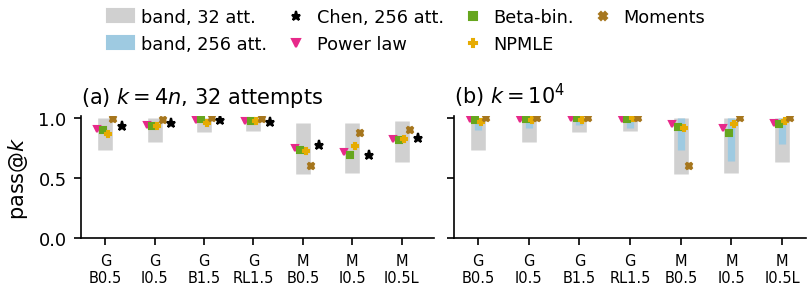

[figure] F19_family_dependence: layout audit OK {"n_text": 26, "text_overlaps": 0}


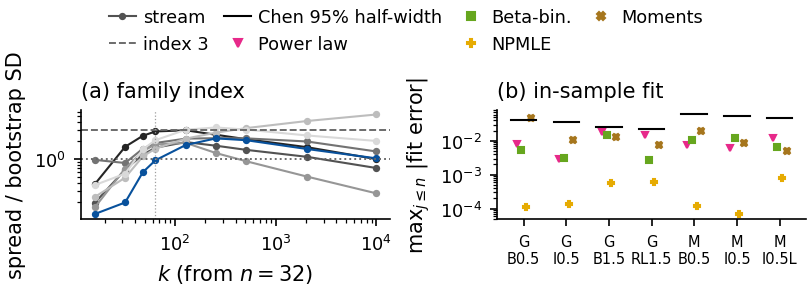

In [33]:
# 7.9 E6 (every stream) [analysis]: assumption checks, certified error for t <= 2, bands beyond, family dependence -> T12a, T12b, F18, F19
E6_KS = list(CFG["E6_KS"])
E6_FAMS = list(FORECASTERS)
E6_STREAMS = [s for s in STREAMS if SDATA[s]["m"] >= CFG["M_MIN_ANALYSIS"] and "group" not in STREAM_REG[s]]
CLAIM_STREAMS = [s for s in E6_STREAMS if CFG["SUPERSEDED"].get(s) not in E6_STREAMS]   # a superseded stream drops out
K4N = 4 * N_BLK
_jn, _j4n, _jfar = E6_KS.index(N_BLK), E6_KS.index(K4N), E6_KS.index(10000)


def e6_stream(skey):
    S = SDATA[skey]
    m, Y1, Y2 = S["m"], S["Y1"], S["Y2"]
    C, cb = Y1.sum(1).astype(int), Y1.reshape(m, NB, N_BLK).sum(2).astype(int)
    W = get_wboot(m)
    si = STREAM_REG[skey]["seed_index"]
    r = {"stream": skey, "m": m, "pass1": float(Y1.mean()), "pass256": float(np.mean(C > 0)), "never": float(np.mean(C == 0)),
         "cap_rate": float(S["cap"].mean()), "mean_len": float(S["lens"].mean())}
    a1 = a1_tests(Y1, N_BLK, min(CFG["N_PERM"], 4000), SEED + 700 + si)
    r["a1_holm_min"] = float(np.nanmin(holm(list(a1["p"].values()))))
    r["a2_p"] = float(split_half_check(cb[:, 0], N_BLK, SEED + 800 + si)["p"])
    r["a3"] = float(a3_check(Y1, Y2)["rate"])
    h48, ch48 = doubling_h(N_BLK, 48), chen_fail_table(N_ATT - N_BLK, 48)
    Fb, Rb = h48[cb], ch48[C[:, None] - cb]
    lo, hi = pct_ci(W @ (Fb - Rb).mean(1) / m)
    Bc = B_n(N_BLK, 1.5)
    r["cor1"] = {"mean": float((Fb - Rb).mean()), "lo": float(lo), "hi": float(hi), "ok": bool(lo <= Bc and hi >= -Bc)}
    dev = np.abs(Fb.mean(0) - Rb.mean(0))
    thr, ref_err = thm1b_bound(N_BLK, 48, m, DELTA), hoeffding_term(m, DELTA)
    r["cor2"] = {"max_dev": float(dev.max()), "thr": thr, "ref_err": ref_err, "ok": bool(dev.max() <= thr + ref_err)}
    e4s = e4_stream(C, cb, m, None, ["Doubling (ours)", "LP-cert (ours)"] + E6_FAMS, label=STREAM_CODES[skey])
    r["e4_err"] = {nm: e4s["point_err"][nm].mean(0) for nm in e4s["point_err"]}
    r["e4_band_width"] = (e4s["band"][..., 1] - e4s["band"][..., 0]).mean(0)
    r["e4_band_contains"] = e4s["band_contains"].mean(0)
    OH1 = np.eye(N_BLK + 1)[cb[:, 0]]
    H1 = OH1.sum(0)
    r["band32"] = pi_band(H1, N_BLK, E6_KS, DELTA)
    r["band256"] = pi_band(hist_counts(C, N_ATT), N_ATT, [K4N, 10000], DELTA)
    r["twoE"] = np.array([twoE(N_BLK, k)["upper"] for k in E6_KS])
    fore = estimate_all(H1, N_BLK, E6_KS, m, names=E6_FAMS)
    r["fore"] = {nm: fore[nm][0] for nm in E6_FAMS}
    boot = estimate_all(W[: CFG["B_E6"]] @ OH1, N_BLK, E6_KS, m, names=E6_FAMS)
    r["boot_sd"] = {nm: np.nanstd(boot[nm], axis=0, ddof=1) for nm in E6_FAMS}
    P = np.stack([r["fore"][nm] for nm in E6_FAMS])
    r["spread"] = np.nanmax(P, 0) - np.nanmin(P, 0)
    r["family_index"] = r["spread"] / np.maximum(np.nanmean(np.stack([r["boot_sd"][nm] for nm in E6_FAMS]), 0), 1e-12)
    r["inside32"] = (P >= r["band32"][:, 0] - 1e-9) & (P <= r["band32"][:, 1] + 1e-9)
    js = list(range(1, N_BLK + 1))
    chen_j = np.array([H1 @ chen_fail_table(N_BLK, j) / m for j in js])
    fit = estimate_all(H1, N_BLK, js, m, names=E6_FAMS)
    r["fit_err"] = {nm: float(np.nanmax(np.abs(fit[nm][0] - chen_j))) for nm in E6_FAMS}
    lo_c, hi_c = pct_ci(W[: CFG["B_E6"]] @ chen_fail_table(N_BLK, N_BLK)[cb[:, 0]] / m)
    r["chen_n_halfwidth"] = float(0.5 * (hi_c - lo_c))
    r["ref256"] = {k: float(np.mean(chen_fail_table(N_ATT, k)[C])) for k in E6_KS if k <= N_ATT}
    r["oos_err"] = {nm: {k: float(abs(r["fore"][nm][E6_KS.index(k)] - v)) for k, v in r["ref256"].items()} for nm in E6_FAMS}
    return r


E6 = {s: cached(f"e6v3_{s.replace(':', '__')}_{data_tag(SDATA[s]['Y1'], SDATA[s]['Y2'])}_{len(E6_FAMS)}_{M3_TAG}",
                (lambda s=s: e6_stream(s))) for s in E6_STREAMS}
ckpt_save("e1_cache", E_CACHE)
lp_cache_flush()
# Revision 4: the family index without moment matching, whose plug-in forecast is flat beyond 2n and inflates the spread.
# Computed from the stored forecasts and bootstrap SDs, so nothing is refitted.
_FAM3 = list(CFG["C5_FAMILIES"])
for _s, _r in E6.items():
    _P3 = np.stack([_r["fore"][nm] for nm in _FAM3])
    _r["spread3"] = np.nanmax(_P3, 0) - np.nanmin(_P3, 0)
    _r["family_index3"] = _r["spread3"] / np.maximum(np.nanmean(np.stack([_r["boot_sd"][nm] for nm in _FAM3]), 0), 1e-12)
_bw = lambda r, j: float(r["band32"][j, 1] - r["band32"][j, 0])
_r12a, _r12b = [], []
for s, r in E6.items():
    _r12a.append({"Stream": STREAM_CODES[s] + ("*" if s not in CLAIM_STREAMS else ""), "m": r["m"], "pass@1": f"{r['pass1']:.3f}",
                  "pass@256": f"{r['pass256']:.3f}", "cap": f"{100 * r['cap_rate']:.1f}%", "A1 p": fmt(r["a1_holm_min"], 3), "A1 p (all)": fmt(min(1.0, len(E6) * r["a1_holm_min"]), 3),
                  "A2 p": fmt(r["a2_p"], 3), "A3": f"{100 * r['a3']:.2f}%", "Cor.1": "PASS" if r["cor1"]["ok"] else "FAIL",
                  "Cor.2": "PASS" if r["cor2"]["ok"] else "FAIL"})
    j48, j64 = E4_KS.index(48), E4_KS.index(64)
    _r12b.append({"Stream": STREAM_CODES[s] + ("*" if s not in CLAIM_STREAMS else ""),
                  "Dbl k=48": f"{r['e4_err']['Doubling (ours)'][j48]:.3f}", "LP k=48": f"{r['e4_err']['LP-cert (ours)'][j48]:.3f}",
                  "band k=n": f"{_bw(r, _jn):.3f}", "band k=4n": f"{_bw(r, _j4n):.3f}", "extra": f"{_bw(r, _j4n) - _bw(r, _jn):+.3f}",
                  "band k=1e4": f"{_bw(r, _jfar):.3f}", "1e4 (256)": f"{r['band256'][1, 1] - r['band256'][1, 0]:.3f}",
                  "FI 1e4": f"{r['family_index'][_jfar]:.1f}", "FI no MM": f"{r['family_index3'][_jfar]:.1f}"})
T12A, T12B = pd.DataFrame(_r12a), pd.DataFrame(_r12b)
print(T12A.to_string(index=False))
print(T12B.to_string(index=False))
_sup_note = " * = superseded by a stream with a longer token cap and left out of the claim summaries."
save_table(T12A, "T12a_streams_checks", "Every stream: m, pass@1 and pass@256 (G1), share of attempts that hit the token cap, "
           "smallest Holm-adjusted A1 p-value within the stream and the same with a Bonferroni factor for the number of streams "
           "(A1 p (all)), A2 split-half p, A3 grader disagreement, Corollaries 1-2 at k = 48. "
           + STREAM_CODE_NOTE + _sup_note, width_in=5.45)
save_table(T12B, "T12b_streams_extrapolation", "Every stream: mean |error| over the 8 blocks of the certified estimators "
           "(t <= 2); width of the 95% identification band for pass@k from one 32-attempt block at k = n (point-identified, so "
           "the width is sampling width), at k = 4n, and their difference (extra width from extrapolating); at k = 10^4 from 32 "
           "and from all 256 attempts; family index at k = 10^4 (spread of the forecast families / mean within-family bootstrap "
           "SD), with all four families (pre-registered) and without moment matching (FI no MM). " + STREAM_CODE_NOTE + _sup_note,
           width_in=5.45)
_cs = [s for s in CLAIM_STREAMS if s in E6]
_wn = np.array([_bw(E6[s], _jn) for s in _cs])
_w4n = np.array([_bw(E6[s], _j4n) for s in _cs])
_e4n = np.array([E6[s]["twoE"][_j4n] for s in _cs])
_fi = np.array([E6[s]["family_index"][_jfar] for s in _cs])
_fi3 = np.array([E6[s]["family_index3"][_jfar] for s in _cs])
_fit_ok = np.array([E6[s]["fit_err"][nm] <= 2 * E6[s]["chen_n_halfwidth"] for s in _cs for nm in E6_FAMS])
_inside = np.array([E6[s]["inside32"][:, _jfar] for s in _cs]).ravel()
E6_SUMMARY = {"streams": _cs, "width_n": _wn, "width_4n": _w4n, "extra_4n": _w4n - _wn, "twoE_4n": _e4n, "fi_far": _fi, "fi3_far": _fi3,
              "fit_ok_frac": float(_fit_ok.mean()), "inside_far_frac": float(_inside.mean()),
              "cor2_ok": [E6[s]["cor2"]["ok"] for s in _cs]}
VERDICTS["C2 wide bands beyond 2n (claim streams)"] = "PASS" if bool(np.all(_w4n >= np.maximum(0.1, 10 * _e4n))) else "FAIL"
VERDICTS["C3 family-driven forecasts"] = ("PASS" if (np.nanmedian(_fi) >= 3 and _fit_ok.mean() >= 0.75) else "FAIL")
print(f"C2 (pre-registered): band width at k=4n from 32 attempts: min {_w4n.min():.3f}, median {np.median(_w4n):.3f}; population gap "
      f"2E_32(x^{K4N}) <= {_e4n.max():.1e} -> {VERDICTS['C2 wide bands beyond 2n (claim streams)']}")
print(f"C2 decomposition (added after the first full run): width at k=n (sampling only) median {np.median(_wn):.3f}; extra width "
      f"from extrapolating to k=4n median {np.median(_w4n - _wn):+.3f} (range {np.min(_w4n - _wn):+.3f} to {np.max(_w4n - _wn):+.3f})")
print(f"C3: family index at k=1e4: median {np.nanmedian(_fi):.1f} (min {np.nanmin(_fi):.1f}, max {np.nanmax(_fi):.1f}); in-sample fit "
      f"within twice the Chen half-width for {100 * _fit_ok.mean():.0f}% of stream-family pairs; forecasts at k=1e4 inside the band: "
      f"{100 * _inside.mean():.0f}% -> {VERDICTS['C3 family-driven forecasts']}")
print(f"C3 without moment matching (revision 4, descriptive): family index at k=1e4 median {np.nanmedian(_fi3):.1f} "
      f"(min {np.nanmin(_fi3):.1f}, max {np.nanmax(_fi3):.1f}). C3 is retired as a headline claim: its qualitative content "
      "(forecasts beyond n rest on the mixing assumption) is shown in general by Singh and Singh (2026).")

fig, axes = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained", sharey=True)
f18 = {"streams": [STREAM_CODES[s] for s in E6], "families": E6_FAMS}
_xs = np.arange(len(E6))
for ax, j, lab in ((axes[0], _j4n, "(a) $k=4n$, 32 attempts"), (axes[1], _jfar, "(b) $k=10^4$")):
    for x, s in zip(_xs, E6):
        r = E6[s]
        ax.vlines(x, 1 - r["band32"][j, 1], 1 - r["band32"][j, 0], color="#d0d0d0", lw=7)
        if j == _jfar:
            ax.vlines(x, 1 - r["band256"][1, 1], 1 - r["band256"][1, 0], color="#9ecae1", lw=3.5)
        for i, nm in enumerate(E6_FAMS):
            ax.plot(x + (i - 1.5) * 0.11, 1 - r["fore"][nm][j], marker=METHOD_MARKERS[nm], color=METHOD_COLORS[nm], ms=3.2, ls="none")
        if E6_KS[j] in r["ref256"]:
            ax.plot(x + 0.33, 1 - r["ref256"][E6_KS[j]], marker="*", color="#000000", ms=4.5, ls="none")
        f18[f"{STREAM_CODES[s]}|k{E6_KS[j]}"] = {"band32_pass": [1 - r["band32"][j, 1], 1 - r["band32"][j, 0]],
                                               "forecasts_pass": {nm: 1 - r["fore"][nm][j] for nm in E6_FAMS},
                                               "chen256_pass": (1 - r["ref256"][E6_KS[j]]) if E6_KS[j] in r["ref256"] else None}
    ax.set_xticks(_xs); ax.set_xticklabels([STREAM_CODES[s].replace("-", "\n") for s in E6], fontsize=7)
    ax.set_ylim(0, 1.02)
    panel_label(ax, lab)
axes[0].set_ylabel("pass@$k$")
_h = [Patch(color="#d0d0d0", label="band, 32 att."), Patch(color="#9ecae1", label="band, 256 att."),
      Line2D([], [], color="#000000", marker="*", ls="none", ms=4.5, label="Chen, 256 att.")]
_h += [Line2D([], [], color=METHOD_COLORS[nm], marker=METHOD_MARKERS[nm], ls="none", ms=3.5, label=SHORT[nm]) for nm in E6_FAMS]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=4)
finish_figure(fig, "F18_bands_vs_forecasts_all_streams", f18, "Identification bands and forecast families across every stream.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
f19 = {"k": E6_KS, "family_index": {}, "fit_err": {}}
_greys = ["#252525", "#525252", "#737373", "#969696", "#bdbdbd", "#d9d9d9", "#08519c"]
for i, s in enumerate(E6):
    ax1.plot(E6_KS, np.maximum(E6[s]["family_index"], 1e-2), color=_greys[i % len(_greys)], marker="o", ms=2.5, lw=1.0)
    f19["family_index"][STREAM_CODES[s]] = E6[s]["family_index"]
ax1.axhline(1.0, color=BOUND_COLOR, ls=":", lw=0.9)
ax1.axhline(3.0, color=BOUND_COLOR, ls="--", lw=0.9)
ax1.axvline(2 * N_BLK, color="#9e9e9e", ls=":", lw=0.6)
ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_xlabel("$k$ (from $n=32$)"); ax1.set_ylabel("spread / bootstrap SD")
panel_label(ax1, "(a) family index")
for x, s in zip(_xs, E6):
    for i, nm in enumerate(E6_FAMS):
        ax2.plot(x + (i - 1.5) * 0.11, max(E6[s]["fit_err"][nm], 1e-5), marker=METHOD_MARKERS[nm], color=METHOD_COLORS[nm], ms=3.2, ls="none")
    ax2.plot([x - 0.3, x + 0.3], [E6[s]["chen_n_halfwidth"]] * 2, color="#000000", lw=1.0)
    f19["fit_err"][STREAM_CODES[s]] = {"fit_err": E6[s]["fit_err"], "chen_n_halfwidth": E6[s]["chen_n_halfwidth"]}
ax2.set_yscale("log"); ax2.set_xticks(_xs); ax2.set_xticklabels([STREAM_CODES[s].replace("-", "\n") for s in E6], fontsize=7)
for _ax in (ax1, ax2):
    _ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax2.set_ylabel(r"max$_{j\leq n}$ |fit error|")
panel_label(ax2, "(b) in-sample fit")
_h = [Line2D([], [], color="#525252", marker="o", ms=2.5, lw=1.0, label="stream"),
      Line2D([], [], color=BOUND_COLOR, ls="--", lw=0.9, label="index 3"),
      Line2D([], [], color="#000000", lw=1.0, label="Chen 95% half-width")]
_h += [Line2D([], [], color=METHOD_COLORS[nm], marker=METHOD_MARKERS[nm], ls="none", ms=3.5, label=SHORT[nm]) for nm in E6_FAMS]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=4)
finish_figure(fig, "F19_family_dependence", f19, "Between-family spread relative to bootstrap noise, and in-sample fit error.")

Figure F18 (bands against forecast families, every stream; E6).
- (a) $k=4n$, 32 attempts: for each stream, the 95% identification band for pass@128 from the first 32-attempt block (grey bar), the four forecast families fitted to the same block (markers), and Chen et al.'s estimate from all 256 attempts (star).
- (b) $k=10^4$: the band from 32 attempts (grey), the band from all 256 attempts (blue), and the four forecasts from 32 attempts.

Figure F19 (family dependence; E6).
- (a) Family index: the spread of the four forecasts divided by their mean bootstrap standard deviation (400 problem-level resamples), against $k$, one line per stream. Above 3 (dashed), the choice of family moves the forecast by more than the data do. T12b also gives the index without moment matching, whose flat plug-in forecast inflates the spread; C3, which was judged on this index, is retired in revision 4.
- (b) In-sample fit: the largest absolute gap between each family's pass@$j$ and Chen et al.'s, $j\le n$, against the 95% bootstrap half-width of Chen's pass@$n$ (black bar). Families below the bar cannot be told apart by the counts.

T12b splits the band width into its sampling part (width at $k=n$, where pass@$k$ is point-identified) and the extra width from extrapolating to $k=4n$. Stream codes: G GSM8K, M MATH-500; B0.5 Qwen2.5-0.5B (base), I0.5 Qwen2.5-0.5B-Instruct (512-token cap), I0.5L the same model with a 1,024-token cap, B1.5 Qwen2.5-1.5B (base), RL1.5 Qwen2.5-1.5B-SimpleRL-Zoo. Estimator codes as in F9.

[resume] e7_certified_horizon_11b6a625: loaded from checkpoint
[resume] e7_lower_bound_scan_6ece7805: loaded from checkpoint
 n     m   eps  t*_LP  t_bind_M5  t_bind_Thm1C  LP cert at t=2  gap_ratio
16   164 0.050    NaN      4.875        13.368           0.194        NaN
16   164 0.100    NaN     11.188        26.735           0.194        NaN
16   300 0.050    NaN      6.562        18.080           0.151        NaN
16   300 0.100  1.250     15.562        36.160           0.151     12.450
16   500 0.050    NaN      8.562        23.341           0.120        NaN
16   500 0.100  1.500     20.562        46.682           0.120     13.708
16  1319 0.050  1.250     14.188        37.910           0.075     11.350
16  1319 0.100  2.500     33.750        75.821           0.075     13.500
16 10000 0.050  2.500     39.625       104.384           0.028     15.850
16 10000 0.100  4.000     93.250       208.768           0.028     23.312
32   164 0.050    NaN      4.750        13.368           0.19

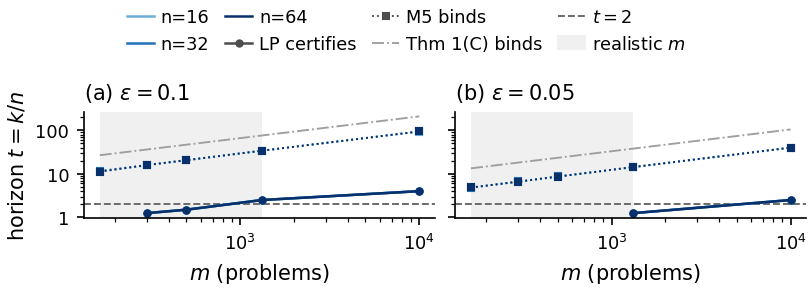

In [34]:
# 7.10 E7 (certified horizon at realistic m) [analysis]: largest t certified by the LP, and the t at which the two-point bound M5 first reaches eps (scanned far beyond the old grid) -> T10, F20
def _e7():
    rows = []
    for n in CFG["E7_NS"]:
        for m in CFG["E7_MS"]:
            for t in CFG["E7_TS"]:
                k = int(round(t * n))
                lp = lp_estimator(n, k, int(m), DELTA, 1.0, CFG["LP_G_E7"])
                lb = m5_cached(n, k, int(m))
                dbl = certificate(doubling_h(n, k), n, k, int(m), DELTA)["cert"] if k / n < 2 else float("nan")
                rows.append({"n": n, "m": int(m), "k": k, "t": k / n, "lp_cert": lp["cert"], "dbl_cert": dbl, "m5": lb["lb"],
                             "thm1c": thm1c_lb(n, k, int(m))})
        lp_cache_flush()
        ckpt_save("m5_cache", M5_CACHE)
    return pd.DataFrame(rows)


_e7key = hashlib.sha1(json.dumps([CFG["E7_NS"], CFG["E7_MS"], CFG["E7_TS"], CFG["LP_G_E7"], DELTA]).encode()).hexdigest()[:8]
E7 = cached(f"e7_certified_horizon_{_e7key}", _e7)
E7.to_csv(os.path.join(LOG_DIR, "e7_certified_horizon_grid.csv"), index=False)


def _e7_lb():
    """Revision 4. The old grid stopped at t = 6, where M5 had not yet reached eps at any realistic m, so the necessary
    horizon was censored. Here M5 and the analytic Theorem 1(C) bound are evaluated up to t = 1024; for every (n, m, eps)
    the first k at which M5 >= eps is located by bisection on the integer k between the two bracketing grid points."""
    rows = []
    for n in CFG["E7_NS"]:
        for m in CFG["E7_MS"]:
            for t in CFG["E7_TS_LB"]:
                k = int(round(t * n))
                rows.append({"n": n, "m": int(m), "k": k, "t": k / n, "m5": m5_cached(n, k, int(m))["lb"], "thm1c": thm1c_lb(n, k, int(m))})
        ckpt_save("m5_cache", M5_CACHE)
    grid = pd.DataFrame(rows)
    bind = []
    for n in CFG["E7_NS"]:
        for m in CFG["E7_MS"]:
            sub = grid[(grid["n"] == n) & (grid["m"] == m)].sort_values("k")
            for eps in (0.05, 0.1):
                t_an = eps * math.sqrt(m) / 0.0479 if eps <= 0.158 else float("nan")   # analytic: 0.0479 t / sqrt(m) = eps
                hit = sub[sub["m5"] >= eps]
                if hit.empty:
                    bind.append({"n": n, "m": int(m), "eps": eps, "k_bind": float("nan"), "t_bind": float("nan"),
                                 "t_open_max": float(sub["t"].max()), "t_thm1c": t_an, "censored": True})
                    continue
                k_hi = int(hit["k"].iloc[0])
                before = sub[sub["k"] < k_hi]
                k_lo = int(before["k"].iloc[-1]) if len(before) else n
                while k_hi - k_lo > 1:
                    mid = (k_lo + k_hi) // 2
                    if m5_cached(n, mid, int(m))["lb"] >= eps:
                        k_hi = mid
                    else:
                        k_lo = mid
                bind.append({"n": n, "m": int(m), "eps": eps, "k_bind": k_hi, "t_bind": k_hi / n, "t_open_max": k_lo / n,
                             "t_thm1c": t_an, "censored": False})
        ckpt_save("m5_cache", M5_CACHE)
    return {"grid": grid, "bind": pd.DataFrame(bind)}


_e7lbkey = hashlib.sha1(json.dumps([CFG["E7_NS"], CFG["E7_MS"], CFG["E7_TS_LB"]]).encode()).hexdigest()[:8]
E7LB = cached(f"e7_lower_bound_scan_{_e7lbkey}", _e7_lb)
E7LB["grid"].to_csv(os.path.join(LOG_DIR, "e7_lower_bound_grid.csv"), index=False)
E7LB["bind"].to_csv(os.path.join(LOG_DIR, "e7_lower_bound_binding_t.csv"), index=False)


def _t_star(sub, col, eps):
    """Largest grid t such that col <= eps at every grid t' <= t; 1 if only k = n (Chen et al., range 1) is certified; nan if none."""
    sub = sub.sort_values("t")
    best = float("nan")
    for _, row in sub.iterrows():
        if row[col] <= eps:
            best = row["t"]
        else:
            break
    if not np.isfinite(best) and hoeffding_term(int(sub["m"].iloc[0]), DELTA) <= eps:
        best = 1.0
    return best


_rows = []
for n in CFG["E7_NS"]:
    for m in CFG["E7_MS"]:
        sub = E7[(E7["n"] == n) & (E7["m"] == m)]
        for eps in (0.05, 0.1):
            _b = E7LB["bind"][(E7LB["bind"]["n"] == n) & (E7LB["bind"]["m"] == m) & (E7LB["bind"]["eps"] == eps)].iloc[0]
            _rows.append({"n": n, "m": m, "eps": eps, "t*_LP": _t_star(sub, "lp_cert", eps),
                          "t_bind_M5": float(_b["t_bind"]), "t_bind_Thm1C": float(_b["t_thm1c"]),
                          "LP cert at t=2": float(sub.loc[(sub["t"] - 2.0).abs().idxmin(), "lp_cert"])})
E7_TSTAR = pd.DataFrame(_rows)
E7_TSTAR["gap_ratio"] = E7_TSTAR["t_bind_M5"] / E7_TSTAR["t*_LP"]
E7_TSTAR.to_csv(os.path.join(LOG_DIR, "e7_certified_horizons.csv"), index=False)
print(E7_TSTAR.to_string(index=False, float_format=lambda z: f"{z:.3f}"))


def _tfmt(z):
    return "--" if not np.isfinite(z) else (f"{z:.3g}" if z < 100 else f"{z:.0f}")


T10 = pd.DataFrame([{"n": n, "m": f"{int(m):,}",
                     **{f"t*LP {e:g}": _tfmt(float(E7_TSTAR[(E7_TSTAR["n"] == n) & (E7_TSTAR["m"] == m) & (E7_TSTAR["eps"] == e)]["t*_LP"].iloc[0]))
                        for e in (0.05, 0.1)},
                     **{f"M5 binds {e:g}": _tfmt(float(E7_TSTAR[(E7_TSTAR["n"] == n) & (E7_TSTAR["m"] == m) & (E7_TSTAR["eps"] == e)]["t_bind_M5"].iloc[0]))
                        for e in (0.05, 0.1)},
                     "Thm 1(C) binds 0.1": _tfmt(float(E7_TSTAR[(E7_TSTAR["n"] == n) & (E7_TSTAR["m"] == m) & (E7_TSTAR["eps"] == 0.1)]["t_bind_Thm1C"].iloc[0]))}
                    for n in CFG["E7_NS"] for m in CFG["E7_MS"]])
save_table(T10, "T10_certified_horizons",
           f"Certified horizon against the lower bound. t*LP(eps): the largest t = k/n on the grid {CFG['E7_TS']} whose LP "
           "certificate (95%, sup-bias plus Hoeffding over linear estimators of the count histogram) is at most eps. "
           "M5 binds(eps): the smallest t at which the optimised two-point bound reaches eps, so that every estimator errs by "
           "at least eps with probability 1/4 under some D (scanned up to t = 1024, refined by bisection on k). Thm 1(C) binds: "
           "the same for the analytic bound. Between t*LP and the binding t it is open whether any estimator certifies "
           "eps (164 = HumanEval, 500 = MATH-500, 1,319 = GSM8K test).", width_in=5.2)
_real = E7_TSTAR[(E7_TSTAR["m"] <= CFG["REALISTIC_M_MAX"]) & (E7_TSTAR["eps"] == 0.1)]
VERDICTS["C1 certified horizon near 2n at realistic m"] = ("PASS" if (np.isfinite(_real["t*_LP"]).any() and np.nanmax(_real["t*_LP"]) <= 2.5)
                                                          else "FAIL")
E7_SCOPE = {"t_lp_min": float(np.nanmin(_real["t*_LP"])), "t_lp_max": float(np.nanmax(_real["t*_LP"])),
            "t_bind_min": float(np.nanmin(_real["t_bind_M5"])), "t_bind_max": float(np.nanmax(_real["t_bind_M5"])),
            "censored": int(E7LB["bind"]["censored"].sum()),
            "t_bind_m10000": float(np.nanmax(E7_TSTAR[(E7_TSTAR["m"] == max(CFG["E7_MS"])) & (E7_TSTAR["eps"] == 0.1)]["t_bind_M5"]))}
VERDICTS["C1 scope: two-point bound binds at t (eps=0.1, realistic m)"] = (
    f"{E7_SCOPE['t_bind_min']:.3g} to {E7_SCOPE['t_bind_max']:.3g} (LP certifies up to {E7_SCOPE['t_lp_max']:.3g})")
print(f"C1: t*_LP(0.1) at m <= {CFG['REALISTIC_M_MAX']}: {E7_SCOPE['t_lp_min']:.3f} to {E7_SCOPE['t_lp_max']:.3f} -> "
      f"{VERDICTS['C1 certified horizon near 2n at realistic m']}")
print(f"C1 scope: at the same m the two-point bound M5 reaches 0.1 only at t = {E7_SCOPE['t_bind_min']:.3g} to "
      f"{E7_SCOPE['t_bind_max']:.3g}; between the two, whether any estimator certifies 0.1 is open. "
      f"(Grid points where M5 never reached eps up to t = {max(CFG['E7_TS_LB']):g}: {E7_SCOPE['censored']}.)")

fig, axes = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained", sharey=True)
f20 = {}
for ax, eps, lab in ((axes[0], 0.1, r"(a) $\varepsilon=0.1$"), (axes[1], 0.05, r"(b) $\varepsilon=0.05$")):
    ax.axvspan(min(CFG["E7_MS"]), CFG["REALISTIC_M_MAX"], color="#f0f0f0", lw=0)
    ax.axhline(2.0, color=BOUND_COLOR, ls="--", lw=0.9)
    for j, n in enumerate(CFG["E7_NS"]):
        sub = E7_TSTAR[(E7_TSTAR["n"] == n) & (E7_TSTAR["eps"] == eps)].sort_values("m")
        c = _seq(j, len(CFG["E7_NS"]))
        ax.plot(sub["m"], sub["t*_LP"], color=c, marker="o", ms=3, lw=1.2)
        ax.plot(sub["m"], sub["t_bind_M5"], color=c, marker="s", ms=2.5, lw=0.9, ls=":")
        f20[f"eps{eps}|n{n}"] = {"m": sub["m"].values, "t_star_LP": sub["t*_LP"].values, "t_bind_M5": sub["t_bind_M5"].values,
                                 "t_bind_thm1c": sub["t_bind_Thm1C"].values}
    _an = E7_TSTAR[(E7_TSTAR["n"] == CFG["E7_NS"][0]) & (E7_TSTAR["eps"] == eps)].sort_values("m")
    ax.plot(_an["m"], _an["t_bind_Thm1C"], color="#9e9e9e", lw=0.9, ls="-.")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("$m$ (problems)")
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _p: f"{v:g}"))
    ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    panel_label(ax, lab)
axes[0].set_ylabel("horizon $t=k/n$")
_h = [Line2D([], [], color=_seq(j, len(CFG["E7_NS"])), lw=1.2, label=f"n={n}") for j, n in enumerate(CFG["E7_NS"])]
_h += [Line2D([], [], color="#4d4d4d", marker="o", ms=3, lw=1.2, label="LP certifies"),
       Line2D([], [], color="#4d4d4d", marker="s", ms=2.5, lw=0.9, ls=":", label="M5 binds"),
       Line2D([], [], color="#9e9e9e", lw=0.9, ls="-.", label="Thm 1(C) binds"),
       Line2D([], [], color=BOUND_COLOR, ls="--", lw=0.9, label="$t=2$"), Patch(color="#f0f0f0", label="realistic $m$")]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=4)
finish_figure(fig, "F20_certified_horizon_vs_m", f20, "Certified horizon of linear estimators against the horizon at which the two-point lower bound binds.")

Figure F20 (E7, certified horizon against benchmark size). Solid: the largest $t=k/n$ whose LP certificate is at most $\varepsilon$ (sufficient; linear estimators of the count histogram with a sup-bias plus Hoeffding certificate). Dotted: the smallest $t$ at which the optimised two-point bound M5 reaches $\varepsilon$, so that every estimator errs by at least $\varepsilon$ with probability 1/4 under some $D$ (necessary). Dash-dot: the same for the analytic Theorem 1(C) bound.
- (a) Horizon at $\varepsilon=0.1$.
- (b) Horizon at $\varepsilon=0.05$.

The three values of $n$ are drawn in different blues; their lines nearly coincide. The shaded range marks benchmark sizes in use (164 for HumanEval to 1,319 for the GSM8K test set), and the dashed line is $t=2$. Between the solid and the dotted line it is open whether any estimator certifies $\varepsilon$; the doubling barrier is a statement about the class of the solid line.

[resume] ab4_1e894fd9be_dkwcp: loaded from checkpoint
k                           128    10000
model    construction  n                
base     CP cells      8    0.387  0.387
                       16   0.295  0.295
                       32   0.260  0.262
                       64   0.180  0.185
                       128  0.122  0.149
                       256  0.180  0.093
         DKW           8    0.407  0.407
                       16   0.313  0.313
                       32   0.266  0.266
                       64   0.196  0.196
                       128  0.157  0.160
                       256  0.139  0.116
         DKW+CP (used) 8    0.393  0.393
                       16   0.301  0.301
                       32   0.266  0.267
                       64   0.185  0.190
                       128  0.127  0.154
                       256  0.131  0.097
instruct CP cells      8    0.266  0.266
                       16   0.227  0.227
                       32   0.194  0.194
   

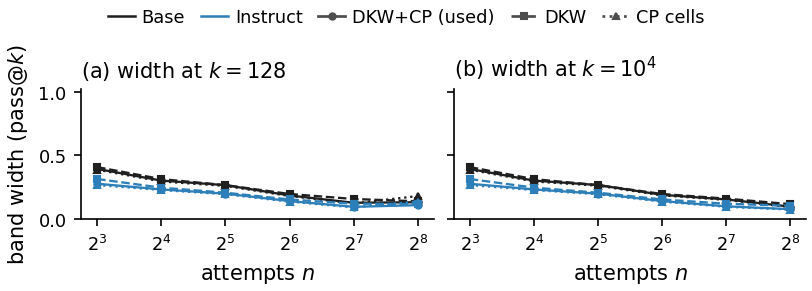

In [35]:
# 7.11 Ab4 (M3 construction) [analysis]: band width against the number of attempts n for three constructions -> F21
AB4_NS = [8, 32, 128] if SMOKE else [8, 16, 32, 64, 128, 256]
AB4_KS = [128, 10000]
AB4_CONS = (("DKW+CP (used)", "dkw+cp"), ("DKW", "dkw"), ("CP cells", "cp"))


def _ab4():
    rows = []
    for mk in MODEL_KEYS:
        for n in AB4_NS:
            h = hist_counts(YG1[mk][:, :n].sum(1), n)
            for name, method in AB4_CONS:
                for k, (lo, hi) in zip(AB4_KS, pi_band(h, n, AB4_KS, DELTA, method=method)):
                    rows.append({"model": mk, "n": n, "k": k, "construction": name, "width": hi - lo, "lo": lo, "hi": hi})
    return pd.DataFrame(rows)


AB4 = cached(f"ab4_{DATA_TAG}_{M3_TAG}", _ab4)
AB4.to_csv(os.path.join(LOG_DIR, "ab4_band_construction.csv"), index=False)
print(AB4.pivot_table(index=["model", "construction", "n"], columns="k", values="width").to_string(float_format=lambda z: f"{z:.3f}"))
_used = AB4[AB4["construction"] == AB4_CONS[0][0]]
_mono = all(_used[(_used["model"] == mk) & (_used["k"] == k) & (_used["n"] == max(AB4_NS))]["width"].iloc[0]
            <= _used[(_used["model"] == mk) & (_used["k"] == k) & (_used["n"] == 32)]["width"].iloc[0] + 0.01
            for mk in MODEL_KEYS for k in AB4_KS)
_piv = AB4.pivot_table(index=["model", "n", "k"], columns="construction", values="width")
_narrowest = float(np.mean(_piv[AB4_CONS[0][0]] <= _piv.min(axis=1) + 0.005))
VERDICTS["Ab4: the band used does not widen with more attempts"] = "PASS" if _mono else "FAIL"
print(f"Ab4: {VERDICTS['Ab4: the band used does not widen with more attempts']}; the band used is the narrowest of the three "
      f"(within 0.005) in {100 * _narrowest:.0f}% of the (model, n, k) cells")
fig, axes = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained", sharey=True)
f21 = {}
_styles = {"DKW+CP (used)": ("-", "o"), "DKW": ("--", "s"), "CP cells": (":", "^")}
for ax, k, lab in ((axes[0], 128, "(a) width at $k=128$"), (axes[1], 10000, "(b) width at $k=10^4$")):
    for mk in MODEL_KEYS:
        for name, _m in AB4_CONS:
            ls, mkr = _styles[name]
            sub = AB4[(AB4["model"] == mk) & (AB4["k"] == k) & (AB4["construction"] == name)].sort_values("n")
            ax.plot(sub["n"], sub["width"], color=MODEL_COLORS[mk], ls=ls, marker=mkr, ms=3, lw=1.1)
            f21[f"k{k}|{mk}|{name}"] = {"n": sub["n"].values, "width": sub["width"].values}
    ax.set_xscale("log", base=2); ax.set_xlabel("attempts $n$"); ax.set_ylim(0, 1.02)
    panel_label(ax, lab)
axes[0].set_ylabel("band width (pass@$k$)")
_h = [Line2D([], [], color=MODEL_COLORS[mk], lw=1.2, label=MODEL_LABELS[mk]) for mk in MODEL_KEYS]
_h += [Line2D([], [], color="#4d4d4d", ls=_styles[nm][0], marker=_styles[nm][1], ms=3, label=nm) for nm, _m in AB4_CONS]
shared_legend(fig, _h, [h.get_label() for h in _h], ncol=5)
finish_figure(fig, "F21_band_construction", f21, "Identification band width against attempts for three constructions.")

Figure F21 (Ab4: band construction). Width of the 95% identification band for pass@$k$ from the first $n$ attempts of the main pair, against $n$: (a) width at $k=128$; (b) width at $k=10^4$. Solid: the band used in this revision (DKW band and per-cell Clopper–Pearson boxes, each at $\delta/2$). Dashed: the DKW band alone at $\delta$. Dotted: the per-cell boxes alone at $\delta/(n+1)$ (the first run's construction), which widen as $n$ grows at fixed $m$.

[resume] e8_83f0ae14ea_dkwcp_4: loaded from checkpoint
E8: MATH-500 base, m = 300 problems x 1024 attempts; held-out truth from the other 992 attempts
  from n = 32 attempts (8 disjoint blocks), mean |error| against the held-out truth:
           Power law  Beta-bin.   NPMLE  Moments  Doubling  LP-cert
    k=48      0.0095     0.0179  0.0167   0.0724    0.0215   0.0189
    k=64      0.0102     0.0193  0.0240   0.1023       NaN   0.0281
    k=96      0.0117     0.0200  0.0379   0.1418       NaN      NaN
    k=128     0.0138     0.0193  0.0489   0.1641       NaN      NaN
    k=192     0.0179     0.0170  0.0627   0.1850       NaN      NaN
    k=256     0.0209     0.0148  0.0698   0.1928       NaN      NaN
    k=384     0.0256     0.0116  0.0749   0.1975       NaN      NaN
    k=512     0.0285     0.0096  0.0754   0.1986       NaN      NaN
    k=768     0.0310     0.0077  0.0728   0.1991       NaN      NaN
    k=992     0.0307     0.0075  0.0696   0.1993       NaN      NaN
    band width /

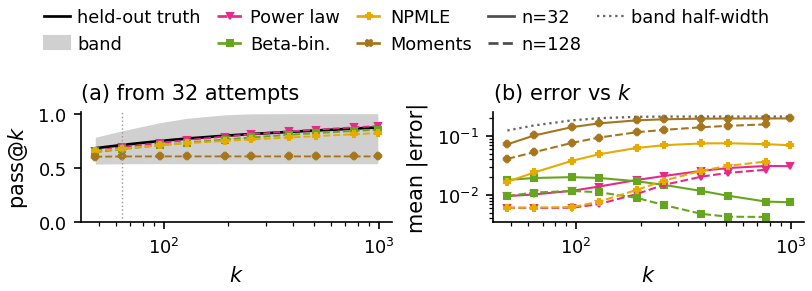

In [36]:
# 7.12 E8 (ground truth far beyond 2n) [analysis]: MATH-500 base with 1,024 attempts per problem; forecasts and bands from 32 or 128 attempts scored against held-out truth -> T13, F22
warnings.filterwarnings("ignore", message="Mean of empty slice")   # the doubling and LP estimators are undefined at most k here
E8_GROUP = list(CFG["E8_GROUP"])
E8_M = min(SDATA[s]["m"] for s in E8_GROUP)
E8 = None
if E8_M < CFG["M_MIN_ANALYSIS"]:
    print(f"E8 skipped: the four MATH-500 base streams have only m = {E8_M} problems in common (need {CFG['M_MIN_ANALYSIS']}).")
    VERDICTS["C5a family choice changes accuracy (E8)"] = "NOT RUN (extra attempts not sampled yet)"
    VERDICTS["C5b band covers ground truth (E8)"] = "NOT RUN (extra attempts not sampled yet)"
else:
    Y8 = np.concatenate([SDATA[s]["Y1"][:E8_M] for s in E8_GROUP], axis=1)   # (m, 1024): four independent 256-attempt streams
    N8 = Y8.shape[1]
    E8_FAMS = list(FORECASTERS)
    E8_NAMES = E8_FAMS + ["Doubling (ours)", "LP-cert (ours)"]

    def _e8_n(n):
        ks = [k for k in CFG["E8_KS"] if k <= N8 - n]
        nb = min(NB, N8 // n)
        est = {nm: np.full((nb, len(ks)), np.nan) for nm in E8_NAMES}
        ref, band = np.zeros((nb, len(ks))), np.zeros((nb, len(ks), 2))
        Ctot = Y8.sum(1).astype(int)
        for b in range(nb):
            cb_ = Y8[:, b * n:(b + 1) * n].sum(1).astype(int)
            ch_ = Ctot - cb_                                   # held-out successes in the other N8 - n attempts
            H = hist_counts(cb_, n)
            ref[b] = [float(np.mean(chen_fail_table(N8 - n, k)[ch_])) for k in ks]
            e = estimate_all(H, n, ks, E8_M, names=E8_NAMES)
            for nm in E8_NAMES:
                est[nm][b] = e[nm][0]
            band[b] = pi_band(H, n, ks, DELTA)
            print(f"[E8] n={n}: block {b + 1}/{nb} done")
        err = {nm: np.abs(est[nm] - ref) for nm in E8_NAMES}
        contains = (band[..., 0] <= ref + 1e-12) & (ref <= band[..., 1] + 1e-12)
        W = get_wboot(E8_M)[: CFG["B_E6"]]
        OH = np.eye(n + 1)[Y8[:, :n].sum(1).astype(int)]
        bt = estimate_all(W @ OH, n, ks, E8_M, names=E8_FAMS)
        sd = np.nanmean(np.stack([np.nanstd(bt[nm], axis=0, ddof=1) for nm in E8_FAMS]), 0)
        P = np.stack([est[nm][0] for nm in E8_FAMS])
        fi = (np.nanmax(P, 0) - np.nanmin(P, 0)) / np.maximum(sd, 1e-12)
        return {"ks": ks, "nb": nb, "est": est, "ref": ref, "err": err, "band": band, "contains": contains, "family_index": fi}

    E8 = cached(f"e8_{data_tag(Y8)}_{M3_TAG}_{len(FORECASTERS)}", lambda: {n: _e8_n(n) for n in CFG["E8_NS"]})
    lp_cache_flush()
    pd.DataFrame([{"n": n, "block": b + 1, "k": k, "estimator": nm, "estimate_F": E8[n]["est"][nm][b, j], "reference_F": E8[n]["ref"][b, j],
                   "abs_error": E8[n]["err"][nm][b, j], "band_F_lo": E8[n]["band"][b, j, 0], "band_F_hi": E8[n]["band"][b, j, 1]}
                  for n in E8 for b in range(E8[n]["nb"]) for j, k in enumerate(E8[n]["ks"]) for nm in E8_NAMES]).to_csv(
        os.path.join(LOG_DIR, "e8_ground_truth_per_block.csv"), index=False)
    _d = E8[min(E8)]
    _ks8 = _d["ks"]
    print(f"E8: MATH-500 base, m = {E8_M} problems x {N8} attempts; held-out truth from the other {N8 - min(E8)} attempts")
    for n, d in E8.items():
        print(f"  from n = {n} attempts ({d['nb']} disjoint blocks), mean |error| against the held-out truth:")
        print("    " + pd.DataFrame({SHORT[nm]: np.round(np.nanmean(d["err"][nm], 0), 4) for nm in E8_NAMES},
                                    index=[f"k={k}" for k in d["ks"]]).to_string().replace("\n", "\n    "))
        _bw8 = (d["band"][..., 1] - d["band"][..., 0]).mean(0)
        print("    band width / blocks containing the truth: " + ", ".join(
            f"k={k}: {w:.3f} / {int(c)}" for k, w, c in zip(d["ks"], _bw8, d["contains"].sum(0))))
        print("    family index (spread / bootstrap SD): " + ", ".join(f"k={k}: {v:.1f}" for k, v in zip(d["ks"], d["family_index"])))
    _cols = [k for k in (128, 256, 512, 992) if k in _ks8]

    def _cell8(nm, k):
        e = _d["err"][nm][:, _ks8.index(k)]
        return "--" if not np.isfinite(e).all() else f"{e.mean():.3f}±{e.std(ddof=1):.3f}"

    def _band8(k):
        j = _ks8.index(k)
        return f"w {float((_d['band'][:, j, 1] - _d['band'][:, j, 0]).mean()):.2f}; {int(_d['contains'][:, j].sum())}/{_d['nb']}"

    T13 = pd.DataFrame([{"Estimator": SHORT[nm], **{f"k={k}": _cell8(nm, k) for k in _cols}} for nm in E8_NAMES]
                       + [{"Estimator": "PI band (ours)", **{f"k={k}": _band8(k) for k in _cols}}])
    save_table(T13, "T13_ground_truth_math500",
               f"E8, MATH-500 base ({E8_M} problems x {N8} attempts): mean absolute error (± std over {_d['nb']} disjoint "
               f"{min(E8)}-attempt blocks) of each estimator against Chen et al.'s estimate from the other {N8 - min(E8)} "
               "attempts; -- = not reported (Doubling: t >= 2; LP-cert: t > 2). PI band row: mean width w of the 95% band and "
               "the number of blocks whose held-out truth lies inside it.")
    _jf = len(_ks8) - 1
    _m_err = {nm: float(np.mean(_d["err"][nm][:, _jf])) for nm in E8_FAMS}
    _best, _worst = min(_m_err, key=_m_err.get), max(_m_err, key=_m_err.get)
    _gap = _m_err[_worst] - _m_err[_best]
    _cov_blocks = int(np.sum(_d["contains"].all(axis=1)))
    VERDICTS["C5a family choice changes accuracy (E8)"] = ("PASS" if (_gap >= 0.05 and _d["family_index"][_jf] >= 3) else "FAIL")
    VERDICTS["C5b band covers ground truth (E8)"] = "PASS" if _cov_blocks >= _d["nb"] - 1 else "FAIL"
    E8_SUMMARY = {"k_far": _ks8[_jf], "best": _best, "worst": _worst, "gap": _gap, "errors": _m_err, "fi_far": float(_d["family_index"][_jf]),
                  "cov_blocks": _cov_blocks, "nb": _d["nb"], "band_w_far": float((_d["band"][:, _jf, 1] - _d["band"][:, _jf, 0]).mean())}
    print(f"C5a: at k = {_ks8[_jf]}: best family {SHORT[_best]} ({_m_err[_best]:.3f}), worst {SHORT[_worst]} ({_m_err[_worst]:.3f}), "
          f"gap {_gap:.3f}; family index {_d['family_index'][_jf]:.1f} -> {VERDICTS['C5a family choice changes accuracy (E8)']}")
    print(f"C5b: the band from {min(E8)} attempts holds the truth at every k in {_cov_blocks}/{_d['nb']} blocks -> "
          f"{VERDICTS['C5b band covers ground truth (E8)']}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
    f22 = {"k": _ks8, "m": E8_M, "N": N8}
    _kk = np.array(_ks8, float)
    ax1.fill_between(_kk, 1 - _d["band"][0, :, 1], 1 - _d["band"][0, :, 0], color="#d0d0d0", lw=0)
    ax1.plot(_kk, 1 - _d["ref"][0], color="#000000", lw=1.3)
    for nm in E8_FAMS:
        ax1.plot(_kk, 1 - _d["est"][nm][0], color=METHOD_COLORS[nm], marker=METHOD_MARKERS[nm], ms=2.8, lw=0.9, ls="--")
    ax1.axvline(2 * min(E8), color="#9e9e9e", ls=":", lw=0.7)
    ax1.set_xscale("log"); ax1.set_xlabel("$k$"); ax1.set_ylabel("pass@$k$"); ax1.set_ylim(0, 1.02)
    panel_label(ax1, f"(a) from {min(E8)} attempts")
    f22["block1"] = {"truth_pass": 1 - _d["ref"][0], "band_pass": [1 - _d["band"][0, :, 1], 1 - _d["band"][0, :, 0]],
                     "forecasts_pass": {nm: 1 - _d["est"][nm][0] for nm in E8_FAMS}}
    for n, ls in zip(sorted(E8), ("-", "--")):
        d = E8[n]
        for nm in E8_FAMS:
            ax2.plot(d["ks"], np.maximum(np.nanmean(d["err"][nm], 0), 1e-4), color=METHOD_COLORS[nm], ls=ls, lw=1.0,
                     marker=METHOD_MARKERS[nm], ms=2.5)
        f22[f"n{n}"] = {"ks": d["ks"], "mean_abs_error": {nm: np.nanmean(d["err"][nm], 0) for nm in E8_NAMES},
                        "band_half_width": 0.5 * (d["band"][..., 1] - d["band"][..., 0]).mean(0)}
    ax2.plot(_ks8, 0.5 * (_d["band"][..., 1] - _d["band"][..., 0]).mean(0), color=BOUND_COLOR, ls=":", lw=1.1)
    ax2.set_xscale("log"); ax2.set_yscale("log"); ax2.set_xlabel("$k$"); ax2.set_ylabel("mean |error|")
    ax2.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    panel_label(ax2, "(b) error vs $k$")
    _h = [Line2D([], [], color="#000000", lw=1.3, label="held-out truth"), Patch(color="#d0d0d0", label="band")]
    _h += [Line2D([], [], color=METHOD_COLORS[nm], marker=METHOD_MARKERS[nm], ms=3, ls="--", label=SHORT[nm]) for nm in E8_FAMS]
    _h += [Line2D([], [], color="#4d4d4d", ls="-", label=f"n={sorted(E8)[0]}"),
           Line2D([], [], color="#4d4d4d", ls="--", label=f"n={sorted(E8)[-1]}"),
           Line2D([], [], color=BOUND_COLOR, ls=":", lw=1.1, label="band half-width")]
    shared_legend(fig, _h, [h.get_label() for h in _h], ncol=5)
    finish_figure(fig, "F22_ground_truth_beyond_2n", f22, "Forecasts and bands from few attempts against held-out ground truth.")

Figure F22 (E8: ground truth far beyond $2n$; MATH-500 with the base model, 1,024 attempts per problem from four independent streams).
- (a) From 32 attempts: for the first 32-attempt block, the 95% identification band (grey), the four forecast families fitted to it (dashed), and the truth estimated from the other 992 attempts (black), up to $k=992$. The dotted vertical line marks $k=2n$.
- (b) Error vs $k$: mean absolute error against the held-out truth over 8 disjoint blocks, from $n=32$ (solid) and $n=128$ (dashed) attempts, with the mean half-width of the band from 32 attempts (dotted).

T13 gives the errors at $k\in\{128,256,512,992\}$ with their spread over blocks, and the band's width and coverage of the held-out truth. C5a and C5b in T8 use criteria fixed before these attempts were sampled.

T13b (Section 7.12b) adds, for the same data, the in-window backtest, the family flip and the family index without moment matching.

In [37]:
# 7.12b E8, revision 4 [analysis]: can the counts choose the family? In-window backtest, family flip, and the family index without moment matching -> T13b
C5_FAMS = list(CFG["C5_FAMILIES"])   # power law, Beta-binomial, NPMLE; moment matching is reported but not used (flat beyond 2n)
BT_TAG = "_".join(f"{f:g}" for f in CFG["BT_FIT_FRACS"])


def backtest_blocks(Y, n, nb, fams, fracs):
    """In-window backtest on every n-attempt block: refit each family on the first f*n attempts of the block and score it on
    pass@k at four k in (f*n, n], against Chen et al.'s unbiased estimate from the whole block. Returns mean |error| per
    block and family. This is the check a practitioner can run without ground truth."""
    m = Y.shape[0]
    out = {}
    for f in fracs:
        nf = max(2, int(round(n * f)))
        kk = sorted(set(int(round(nf + (n - nf) * q)) for q in (0.25, 0.5, 0.75, 1.0)))
        res = {nm: np.full(nb, np.nan) for nm in fams}
        for b in range(nb):
            Yb = Y[:, b * n:(b + 1) * n]
            cb = Yb.sum(1).astype(int)
            tgt = np.array([float(np.mean(chen_fail_table(n, k)[cb])) for k in kk])
            fe = estimate_all(hist_counts(Yb[:, :nf].sum(1), nf), nf, kk, m, names=fams)
            for nm in fams:
                res[nm][b] = float(np.mean(np.abs(fe[nm][0] - tgt)))
        out[float(f)] = {"n_fit": nf, "k_targets": kk, "err": res}
    return out


def gt_block_eval(Y, n, ks, nb=None, fams=None, extra=("Doubling (ours)", "LP-cert (ours)"), band=True, band_ks=None, label=""):
    """Ground-truth evaluation from disjoint n-attempt blocks: every estimator and the identification band computed from
    block b, scored against Chen et al.'s unbiased estimate from all other attempts of the same problems. band_ks limits
    the band (an LP per k) to a subset of ks; the other entries stay NaN."""
    fams = list(fams or FORECASTERS)
    m, N = Y.shape
    nb = int(min(nb or NB, N // n))
    ks = [int(k) for k in ks if k <= N - n]
    jb = [j for j, k in enumerate(ks) if band_ks is None or k in band_ks]
    Ctot = Y.sum(1).astype(int)
    names = fams + [e for e in extra if e not in fams]
    est = {nm: np.full((nb, len(ks)), np.nan) for nm in names}
    ref, bands = np.zeros((nb, len(ks))), np.full((nb, len(ks), 2), np.nan)
    for b in range(nb):
        cb = Y[:, b * n:(b + 1) * n].sum(1).astype(int)
        ref[b] = [float(np.mean(chen_fail_table(N - n, k)[Ctot - cb])) for k in ks]
        e = estimate_all(hist_counts(cb, n), n, ks, m, names=names)
        for nm in names:
            est[nm][b] = e[nm][0]
        if band and jb:
            bands[b, jb] = pi_band(hist_counts(cb, n), n, [ks[j] for j in jb], DELTA)
        if label:
            print(f"[{label}] n={n}: block {b + 1}/{nb} done")
    return {"n": n, "ks": ks, "nb": nb, "m": m, "N": N, "est": est, "ref": ref, "err": {nm: np.abs(est[nm] - ref) for nm in names},
            "band": bands, "band_js": jb, "contains": (bands[..., 0] <= ref + 1e-12) & (ref <= bands[..., 1] + 1e-12)}


def family_index(c0, n, ks, m, fams, B=None):
    """Spread of the families' forecasts from one block divided by their mean problem-level bootstrap SD."""
    W = get_wboot(m)[: int(B or CFG["B_E6"])]
    OH = np.eye(n + 1)[np.asarray(c0, int)]
    fore = estimate_all(OH.sum(0), n, ks, m, names=fams)
    boot = estimate_all(W @ OH, n, ks, m, names=fams)
    sd = np.nanmean(np.stack([np.nanstd(boot[nm], axis=0, ddof=1) for nm in fams]), 0)
    P = np.stack([fore[nm][0] for nm in fams])
    return (np.nanmax(P, 0) - np.nanmin(P, 0)) / np.maximum(sd, 1e-12)


def c5_eval(G, bt, fams=None, near_mult=4):
    """C5c / C5d on one ground-truth stream (criteria fixed before the Monkey Business labels were analysed).
    informative: the worst family's mean far error is at least C5_INFORMATIVE (otherwise the family does not matter there);
    backtest fails: the far error of the backtest-chosen family is at least max(C5_RATIO x best, best + C5_ABS);
    flip: the best family at k = near_mult x n is not the best at the far k, and its far error meets the same threshold."""
    fams = list(fams or C5_FAMS)
    ks, n = G["ks"], G["n"]
    me = {nm: np.nanmean(G["err"][nm], 0) for nm in fams}
    jf = len(ks) - 1
    jn = int(np.argmin([abs(k - near_mult * n) for k in ks]))
    best_far, worst_far = min(fams, key=lambda nm: me[nm][jf]), max(fams, key=lambda nm: me[nm][jf])
    best_near = min(fams, key=lambda nm: me[nm][jn])
    e_best = float(me[best_far][jf])
    thr = max(CFG["C5_RATIO"] * e_best, e_best + CFG["C5_ABS"])
    informative = bool(me[worst_far][jf] >= CFG["C5_INFORMATIVE"])
    f0 = float(CFG["BT_FIT_FRACS"][0])
    sel = [min(fams, key=lambda nm: bt[f0]["err"][nm][b]) for b in range(G["nb"])]
    err_sel = float(np.mean([G["err"][s_][b, jf] for b, s_ in enumerate(sel)]))
    oracle_b = [min(fams, key=lambda nm: G["err"][nm][b, jf]) for b in range(G["nb"])]
    sel_alt = {float(f): [min(fams, key=lambda nm: bt[f]["err"][nm][b]) for b in range(G["nb"])] for f in bt}
    return {"n": n, "k_near": ks[jn], "k_far": ks[jf], "mean_err_far": {nm: float(me[nm][jf]) for nm in fams},
            "mean_err_near": {nm: float(me[nm][jn]) for nm in fams}, "best_far": best_far, "worst_far": worst_far,
            "best_near": best_near, "informative": informative, "threshold": thr, "selected": sel, "err_selected": err_sel,
            "oracle_per_block": oracle_b, "agree_blocks": int(sum(a == b for a, b in zip(sel, oracle_b))),
            "selected_alt": sel_alt,
            "err_selected_alt": {f: float(np.mean([G["err"][s_][b, jf] for b, s_ in enumerate(v)])) for f, v in sel_alt.items()},
            "backtest_fails": bool(informative and err_sel >= thr),
            "flip": bool(informative and best_near != best_far and me[best_near][jf] >= thr),
            "best_by_k": [min(fams, key=lambda nm: me[nm][j]) for j in range(len(ks))], "ks": ks}


E8X = None
if globals().get("E8") is None:
    print("E8 extras skipped: E8 did not run.")
    VERDICTS["C5c backtest (E8, exploratory)"] = VERDICTS["C5d family flip (E8, exploratory)"] = "NOT RUN"
else:
    def _e8x():
        out = {}
        for n in CFG["E8_NS"]:
            d = E8[n]
            G = {"n": n, "ks": list(d["ks"]), "nb": d["nb"], "err": d["err"], "m": E8_M, "N": N8}
            bt = backtest_blocks(Y8, n, d["nb"], FORECASTERS, CFG["BT_FIT_FRACS"])
            c0 = Y8[:, :n].sum(1).astype(int)
            out[n] = {"bt": bt, "c5": c5_eval(G, bt), "fi3": family_index(c0, n, list(d["ks"]), E8_M, C5_FAMS),
                      "fi4": np.asarray(d["family_index"])}
        return out

    E8X = cached(f"e8x_{data_tag(Y8)}_{len(FORECASTERS)}_bt{BT_TAG}", _e8x)
    _rows8 = []
    for n, x in E8X.items():
        c = x["c5"]
        _rows8.append({"n": n, "k near / far": f"{c['k_near']} / {c['k_far']}",
                       **{f"{CODE2[nm]} far": f"{c['mean_err_far'][nm]:.4f}" for nm in C5_FAMS},
                       "best near": CODE2[c["best_near"]], "best far": CODE2[c["best_far"]],
                       "backtest picks": ", ".join(f"{CODE2[nm]} {c['selected'].count(nm)}" for nm in C5_FAMS if c["selected"].count(nm)),
                       "picked far err": f"{c['err_selected']:.4f}",
                       "FI far (no MM)": f"{x['fi4'][-1]:.1f} ({x['fi3'][-1]:.1f})"})
        print(f"E8 n={n}: far k={c['k_far']}: mean |error| " + ", ".join(f"{SHORT[nm]} {c['mean_err_far'][nm]:.4f}" for nm in C5_FAMS)
              + f"; best near (k={c['k_near']}) {SHORT[c['best_near']]}, best far {SHORT[c['best_far']]}; backtest (fit on "
              f"{x['bt'][float(CFG['BT_FIT_FRACS'][0])]['n_fit']} attempts) picks {[SHORT[s_] for s_ in c['selected']]} -> far error "
              f"{c['err_selected']:.4f} (best {c['mean_err_far'][c['best_far']]:.4f}; per-block oracle agreement {c['agree_blocks']}/{len(c['selected'])}); "
              f"family index at far k {x['fi4'][-1]:.1f} with moment matching, {x['fi3'][-1]:.1f} without")
        print(f"      best family by k: " + ", ".join(f"{k}:{CODE2[b]}" for k, b in zip(c["ks"], c["best_by_k"]))
              + f" | backtest fails: {c['backtest_fails']}; flip: {c['flip']}")
    T13B = pd.DataFrame(_rows8)
    save_table(T13B, "T13b_ground_truth_family_choice",
               f"E8, can the counts choose the family? Mean |error| at the far k of the three standard families (PL, BB, NP) "
               f"from n attempts; the best family at k = 4n (near) and at the far k; the family chosen in each of the 8 blocks by "
               f"an in-window backtest (fit on the first n/2 attempts of the block, scored on pass@k for k in (n/2, n]) and the "
               f"far error of that choice; the family index at the far k with all four families and, in parentheses, without "
               f"moment matching. " + CODE2_NOTE, width_in=5.45)
    _c32 = E8X[min(E8X)]["c5"]
    VERDICTS["C5c backtest (E8, exploratory)"] = ("FAILS" if _c32["backtest_fails"] else "WORKS") + \
        f" (picked far error {_c32['err_selected']:.4f} vs best {_c32['mean_err_far'][_c32['best_far']]:.4f})"
    VERDICTS["C5d family flip (E8, exploratory)"] = ("FLIP" if _c32["flip"] else "NO FLIP") + \
        f" (best at k={_c32['k_near']}: {SHORT[_c32['best_near']]}; at k={_c32['k_far']}: {SHORT[_c32['best_far']]})"
    VERDICTS["C5a without moment matching (E8, descriptive)"] = (
        f"family index {E8X[min(E8X)]['fi3'][-1]:.1f} at k={_c32['k_far']} (pre-registered rule needs 3); error gap among the "
        f"three standard families {max(_c32['mean_err_far'].values()) - min(_c32['mean_err_far'].values()):.3f}")
    print("C5a, C5c, C5d on E8:", VERDICTS["C5a without moment matching (E8, descriptive)"], "|",
          VERDICTS["C5c backtest (E8, exploratory)"], "|", VERDICTS["C5d family flip (E8, exploratory)"])

[resume] e8x_83f0ae14ea_4_bt0.5_0.25: loaded from checkpoint
E8 n=32: far k=992: mean |error| Power law 0.0307, Beta-bin. 0.0075, NPMLE 0.0696; best near (k=128) Power law, best far Beta-bin.; backtest (fit on 16 attempts) picks ['Power law', 'Power law', 'NPMLE', 'NPMLE', 'Beta-bin.', 'Power law', 'Power law', 'Power law'] -> far error 0.0330 (best 0.0075; per-block oracle agreement 2/8); family index at far k 3.7 with moment matching, 1.7 without
      best family by k: 48:PL, 64:PL, 96:PL, 128:PL, 192:BB, 256:BB, 384:BB, 512:BB, 768:BB, 992:BB | backtest fails: True; flip: True
E8 n=128: far k=768: mean |error| Power law 0.0267, Beta-bin. 0.0042, NPMLE 0.0368; best near (k=512) Beta-bin., best far Beta-bin.; backtest (fit on 64 attempts) picks ['NPMLE', 'NPMLE', 'Beta-bin.', 'Power law', 'NPMLE', 'Power law', 'Power law', 'Power law'] -> far error 0.0295 (best 0.0042; per-block oracle agreement 1/8); family index at far k 2.8 with moment matching, 1.0 without
      best family by k:

[E9] GSM8K_Llama-3-8B-Instruct: 127 problems x 10000 attempts (label cache)
[resume] e9_GSM8K_Llama-3-8B-Instruct_eb06de675f_4_dkwcp_bt0.5_0.25: loaded from checkpoint
[E9] GSM8K_Llama-3-70B-Instruct: 127 problems x 10000 attempts (label cache)
[resume] e9_GSM8K_Llama-3-70B-Instruct_16c4f53754_4_dkwcp_bt0.5_0.25: loaded from checkpoint
[E9] MATH_Llama-3-8B-Instruct: 128 problems x 10000 attempts (label cache)
[resume] e9_MATH_Llama-3-8B-Instruct_cb610939d4_4_dkwcp_bt0.5_0.25: loaded from checkpoint
[E9] MATH_Llama-3-70B-Instruct: 128 problems x 10000 attempts (label cache)
[resume] e9_MATH_Llama-3-70B-Instruct_f5feb7ae0c_4_dkwcp_bt0.5_0.25: loaded from checkpoint
[E9] CodeContests_Llama-3-8B-Instruct: 140 problems x 10000 attempts (label cache)
[resume] e9_CodeContests_Llama-3-8B-Instruct_b6542596a9_4_dkwcp_bt0.5_0.25: loaded from checkpoint
[E9] CodeContests_Llama-3-70B-Instruct: 140 problems x 10000 attempts (label cache)
[resume] e9_CodeContests_Llama-3-70B-Instruct_7e3f122e22_4_dkw

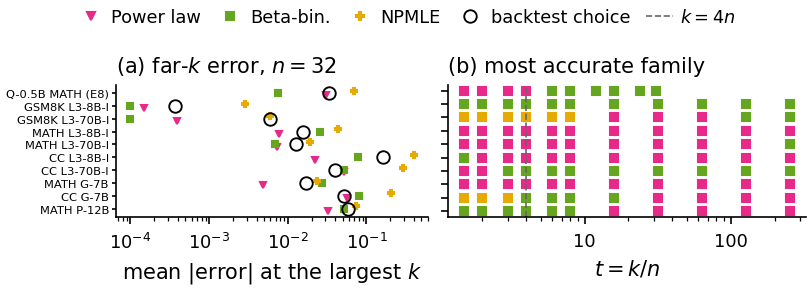

In [38]:
# 7.13 E9 (second ground truth: Monkey Business) [analysis]: Llama-3 8B/70B, Gemma-7B and Pythia-12B on GSM8K, MATH and CodeContests with about 10,000 labelled samples per problem; forecasts, certified estimators and bands from n = 32 or 128 attempts scored against held-out truth -> T14a, T14b, F23
import mmap, tempfile, urllib.request

MB_DIR = os.path.join(CKPT_DIR, "monkey_business")   # label caches; archived and restored like every other checkpoint
os.makedirs(MB_DIR, exist_ok=True)
_MB_KEY = re.compile(rb'"is_corrects"\s*:\s*\[')
_MB_BOOL = re.compile(rb"true|false|1|0")
_MB_TOK = re.compile(rb"\[|\]|true|false|1|0")
MB_TASK = {"GSM8K": "GSM8K", "MATH": "MATH", "CodeContests": "CC", "MiniF2F-MATH": "F2F"}
MB_MODEL = {"Llama-3-8B-Instruct": "L3-8B-I", "Llama-3-70B-Instruct": "L3-70B-I", "Llama-3-8B": "L3-8B", "Gemma-7B": "G-7B",
            "Gemma-2B": "G-2B", "Pythia-12B": "P-12B"}


def mb_code(cfg):
    task, model = cfg.split("_", 1)
    return f"{MB_TASK.get(task, task)} {MB_MODEL.get(model, model)}"


def _mb_parse_value(buf, start):
    """Parse the JSON list that starts at buf[start] == '[' and holds booleans or lists of booleans."""
    end = buf.find(b"]", start + 1)
    seg = buf[start + 1:end]
    if b"[" not in seg:                                          # flat list: one record's labels
        return [[t in (b"true", b"1") for t in _MB_BOOL.findall(seg)]], end + 1
    window = 1 << 22                                             # nested (column-oriented file): parse with a stack
    while True:
        stop = min(len(buf), start + window)
        stack, value, last = [], None, start
        for tok in _MB_TOK.finditer(buf, start, stop):
            t = tok.group()
            if t == b"[":
                stack.append([])
            elif t == b"]":
                done = stack.pop()
                if stack:
                    stack[-1].append(done)
                else:
                    value, last = done, tok.end()
                    break
            else:
                stack[-1].append(t in (b"true", b"1"))
        if value is not None:
            return ([v for v in value if isinstance(v, list)] if value and isinstance(value[0], list) else [value]), last
        if stop >= len(buf):
            raise ValueError("unterminated is_corrects list")
        window *= 4


def mb_parse_labels(path):
    """Every is_corrects list in a Monkey Business JSON file, without parsing the samples. Works for a JSON array of
    records, JSON lines, and a column-oriented object. Escaped occurrences inside sample strings do not match."""
    rows = []
    with open(path, "rb") as fh:
        buf = mmap.mmap(fh.fileno(), 0, access=mmap.ACCESS_READ)
        try:
            pos = 0
            while True:
                mt = _MB_KEY.search(buf, pos)
                if mt is None:
                    break
                lists, pos = _mb_parse_value(buf, mt.end() - 1)
                rows.extend(lists)
            n_idx = len(re.findall(rb'"orig_dset_idx"\s*:', buf))
        finally:
            buf.close()
    return rows, n_idx


def _mb_find_local(cfg):
    """A copy of the JSON file in PASSK_MB_DIR or in an attached Kaggle dataset."""
    roots = ([MB_LOCAL_DIR] if MB_LOCAL_DIR else []) + (["/kaggle/input"] if os.path.isdir("/kaggle/input") else [])
    for root in roots:
        hits = glob.glob(os.path.join(root, "**", cfg + ".json"), recursive=True)
        if hits:
            return hits[0]
    return None


_MB_OFFLINE = [False]   # set after the first failed download, so a session without Internet does not wait on every file


def _mb_download(cfg, dst_dir):
    """Download one configuration from the Hugging Face Hub (huggingface_hub if installed, else plain HTTPS); 3 tries."""
    if _MB_OFFLINE[0]:
        raise RuntimeError("skipped: an earlier download failed (Internet off?)")
    fn, last = cfg + ".json", None
    for attempt in range(3):
        try:
            try:
                from huggingface_hub import hf_hub_download
                return hf_hub_download(repo_id=CFG["MB_REPO"], filename=fn, repo_type="dataset", local_dir=dst_dir)
            except ImportError:
                pass
            except Exception as exc:
                last = exc
            path = os.path.join(dst_dir, fn)
            url = f"https://huggingface.co/datasets/{CFG['MB_REPO']}/resolve/main/{fn}"
            with urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "python-urllib"}), timeout=600) as r, \
                    open(path + ".part", "wb") as f:
                shutil.copyfileobj(r, f, length=1 << 24)
            os.replace(path + ".part", path)
            return path
        except Exception as exc:
            last = exc
            time.sleep(5 * (attempt + 1))
    _MB_OFFLINE[0] = True
    raise RuntimeError(f"{type(last).__name__}: {str(last)[:160]}")


def mb_labels(cfg):
    """Label matrix (problems x attempts, uint8) of one configuration, from the cache or from the JSON file."""
    npz = os.path.join(MB_DIR, cfg + ".npz")
    if os.path.exists(npz):
        z = np.load(npz, allow_pickle=False)
        return {"Y": z["Y"], "lengths": z["lengths"], "meta": json.loads(str(z["meta"])), "from_cache": True}
    local = _mb_find_local(cfg)
    tmp = None
    t0 = time.time()
    if local is None:
        if not MB_ENABLED:
            raise RuntimeError("PASSK_MB=0 and no cached labels")
        tmp = tempfile.mkdtemp(prefix="mb_")
        path, source = _mb_download(cfg, tmp), "Hugging Face Hub"
    else:
        path, source = local, "attached copy"
    t_dl = time.time() - t0
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 24), b""):
            h.update(chunk)
    size = os.path.getsize(path)
    rows, n_idx = mb_parse_labels(path)
    if tmp:
        shutil.rmtree(tmp, ignore_errors=True)
    if not rows:
        raise RuntimeError("no is_corrects lists found")
    lengths = np.array([len(r) for r in rows], int)
    N = int(lengths.min())
    Y = np.stack([np.asarray(r[:N], np.uint8) for r in rows])
    meta = {"config": cfg, "repo": CFG["MB_REPO"], "source": source, "bytes": int(size), "sha256": h.hexdigest(), "problems": int(len(rows)),
            "orig_dset_idx_fields": int(n_idx), "attempts_min": N, "attempts_max": int(lengths.max()),
            "download_seconds": round(t_dl, 1), "parse_seconds": round(time.time() - t0 - t_dl, 1),
            "fetched": datetime.datetime.now().isoformat(timespec="seconds")}
    np.savez_compressed(npz, Y=Y, lengths=lengths, meta=np.array(json.dumps(meta)))
    return {"Y": Y, "lengths": lengths, "meta": meta, "from_cache": False}


def _mb_analyse(cfg, Y, idx):
    m, N = Y.shape
    C = Y.sum(1).astype(int)
    out = {"config": cfg, "m": int(m), "N": int(N), "pass1": float(Y.mean()), "passN": float(np.mean(C > 0)), "never": float(np.mean(C == 0)),
           "gt": {}, "bt": {}, "c5": {}, "fi3": {}, "fi4": {}}
    nA = min(CFG["MB_A1_ATTEMPTS"], N - N % N_BLK)
    a1 = a1_tests(Y[:, :nA], N_BLK, min(CFG["N_PERM"], 4000), SEED + 900 + idx)
    out["a1_p"] = a1["p"]
    out["a1_holm_min"] = float(np.nanmin(holm(list(a1["p"].values()))))
    for n in CFG["MB_NS"]:
        if N < 2 * n:
            continue
        ks = [k for k in CFG["MB_KS"] if 1.5 * n <= k <= N - n]
        band_ks = [k for k in ks if k >= 4 * n or k == ks[-1] or k == ks[0]]
        G = gt_block_eval(Y, n, ks, NB, FORECASTERS, band_ks=band_ks, label=f"E9 {mb_code(cfg)}")
        bt = backtest_blocks(Y, n, G["nb"], FORECASTERS, CFG["BT_FIT_FRACS"])
        c0 = Y[:, :n].sum(1).astype(int)
        out["gt"][n], out["bt"][n], out["c5"][n] = G, bt, c5_eval(G, bt)
        out["fi4"][n] = family_index(c0, n, G["ks"], m, FORECASTERS)
        out["fi3"][n] = family_index(c0, n, G["ks"], m, C5_FAMS)
        k15 = int(round(1.5 * n))
        if k15 in G["ks"]:
            j = G["ks"].index(k15)
            dev = np.abs(G["est"]["Doubling (ours)"][:, j] - G["ref"][:, j])
            out.setdefault("thm1b", {})[n] = {"k": k15, "max_dev": float(np.nanmax(dev)), "bound": thm1b_bound(n, k15, m, DELTA),
                                              "lp_err": float(np.nanmean(G["err"]["LP-cert (ours)"][:, j])),
                                              "dbl_err": float(np.nanmean(dev)),
                                              "best_family_err": float(min(np.nanmean(G["err"][nm][:, j]) for nm in C5_FAMS))}
    lp_cache_flush()
    return out


E9, E9_META, E9_FAIL = {}, {}, {}
if not CFG["MB_CONFIGS"]:
    print("E9 skipped: no Monkey Business configuration listed in CFG['MB_CONFIGS'].")
for _i, _cfg in enumerate(CFG["MB_CONFIGS"]):
    try:
        _lab = mb_labels(_cfg)
    except Exception as exc:
        E9_FAIL[_cfg] = f"{type(exc).__name__}: {str(exc)[:160]}"
        print(f"[E9] {_cfg}: labels unavailable ({E9_FAIL[_cfg]})")
        continue
    _Y = _lab["Y"]
    E9_META[_cfg] = _lab["meta"]
    print(f"[E9] {_cfg}: {_Y.shape[0]} problems x {_Y.shape[1]} attempts ("
          + ("label cache" if _lab["from_cache"] else f"{_lab['meta']['source']}, {_lab['meta']['bytes'] / 1e6:.0f} MB, "
             f"{_lab['meta']['download_seconds']:.0f} s download, {_lab['meta']['parse_seconds']:.0f} s parse") + ")")
    E9[_cfg] = cached(f"e9_{_cfg}_{data_tag(_Y)}_{len(FORECASTERS)}_{M3_TAG}_bt{BT_TAG}", lambda Y=_Y, c=_cfg, i=_i: _mb_analyse(c, Y, i))
if E9_FAIL and not E9:
    print("E9 did not run: no labels could be read. On Kaggle, switch Internet on (Settings) or attach the JSON files of "
          "the Monkey Business release as a dataset, then run this cell again.")

def _cov_blocks(G):
    """Blocks whose held-out truth lies inside the band at every k where the band was computed."""
    return int(sum(bool(G["contains"][b, G["band_js"]].all()) for b in range(G["nb"])))


if E9:
    _n0 = min(CFG["MB_NS"])
    _r14a, _r14b = [], []
    for cfg, R in E9.items():
        G, c = R["gt"].get(_n0), R["c5"].get(_n0)
        if G is None:
            continue
        jf = len(G["ks"]) - 1
        j4 = G["ks"].index(4 * _n0) if 4 * _n0 in G["ks"] else None
        _bw = lambda j: float(np.nanmean(G["band"][:, j, 1] - G["band"][:, j, 0]))
        _cov = _cov_blocks(G)
        tb = R.get("thm1b", {}).get(_n0, {})
        _r14a.append({"Config": mb_code(cfg), "m": R["m"], "N": R["N"], "pass@1": f"{R['pass1']:.3f}", "pass@N": f"{R['passN']:.3f}",
                      "never": f"{R['never']:.3f}", "A1 p": fmt(R["a1_holm_min"], 3),
                      "Dbl dev / bound": (f"{tb['max_dev']:.3f} / {tb['bound']:.3f}" if tb else "--"),
                      "band 4n": (f"{_bw(j4):.3f}" if j4 is not None else "--"), f"band k={G['ks'][jf]}": f"{_bw(jf):.3f}",
                      "cover": f"{_cov}/{G['nb']}"})
        _r14b.append({"Config": mb_code(cfg), **{f"{CODE2[nm]}": f"{c['mean_err_far'][nm]:.4f}" for nm in C5_FAMS},
                      "MM": f"{float(np.nanmean(G['err']['Moment matching'][:, jf])):.4f}",
                      "best 4n/far": f"{CODE2[c['best_near']]}/{CODE2[c['best_far']]}",
                      "backtest picks": " ".join(f"{CODE2[nm]}{c['selected'].count(nm)}" for nm in C5_FAMS if c["selected"].count(nm)),
                      "picked err": f"{c['err_selected']:.4f}", "inform.": "yes" if c["informative"] else "no",
                      "fails/flip": f"{'Y' if c['backtest_fails'] else 'N'}/{'Y' if c['flip'] else 'N'}",
                      "FI (no MM)": f"{R['fi4'][_n0][-1]:.1f} ({R['fi3'][_n0][-1]:.1f})"})
    T14A, T14B = pd.DataFrame(_r14a), pd.DataFrame(_r14b)
    print(T14A.to_string(index=False))
    print(T14B.to_string(index=False))
    _mbnote = ("Config codes: GSM8K, MATH, CC CodeContests; L3-8B-I / L3-70B-I Llama-3-8B/70B-Instruct, G-7B Gemma-7B, P-12B Pythia-12B. ")
    save_table(T14A, "T14a_monkey_business_data",
               f"E9, Monkey Business (Brown et al., 2024): problems m, attempts per problem N, pass@1 and pass@N, share never "
               f"solved, smallest Holm-adjusted A1 p-value (first {CFG['MB_A1_ATTEMPTS']} attempts), the largest deviation of the "
               f"doubling estimator at k = 1.5n over the 8 blocks against the Theorem 1(B) bound, mean width of the 95% band from "
               f"n = {_n0} attempts at k = 4n and at the largest k, and the number of blocks whose held-out truth lies inside the "
               f"band at every k where it is computed. " + _mbnote, width_in=5.45)
    save_table(T14B, "T14b_monkey_business_family_choice",
               f"E9: mean |error| at the largest k (from n = {_n0} attempts, truth from the other N - n) of the three standard "
               f"families and of moment matching; best family at k = 4n and at the largest k; the family chosen in each block by "
               f"the in-window backtest and the far error of that choice; whether the stream is informative (worst family "
               f">= {CFG['C5_INFORMATIVE']}), whether the backtest fails and whether the best family flips (criteria in Section "
               f"9); family index at the largest k with all four families and without moment matching. " + _mbnote + CODE2_NOTE,
               width_in=5.45)
    _inf = [cfg for cfg in E9 if E9[cfg]["c5"].get(_n0, {}).get("informative")]
    _fails = [cfg for cfg in _inf if E9[cfg]["c5"][_n0]["backtest_fails"]]
    _flips = [cfg for cfg in _inf if E9[cfg]["c5"][_n0]["flip"]]

    def _conf(hits):
        if len(_inf) < 3:
            return f"INSUFFICIENT ({len(_inf)} informative streams)"
        return ("SUPPORTED" if len(hits) >= math.ceil(len(_inf) / 2) else "NOT SUPPORTED") + f" ({len(hits)}/{len(_inf)} informative streams)"

    VERDICTS["C5c backtest fails to find the far-k family (Monkey Business, pre-registered)"] = _conf(_fails)
    VERDICTS["C5d best family flips between 4n and the far k (Monkey Business, pre-registered)"] = _conf(_flips)
    _covok = [_cov_blocks(E9[cfg]["gt"][_n0]) >= E9[cfg]["gt"][_n0]["nb"] - 1 for cfg in E9 if _n0 in E9[cfg]["gt"]]
    VERDICTS["C5b band covers ground truth (Monkey Business, pre-registered)"] = (
        ("PASS" if all(_covok) else "FAIL") + f" ({sum(_covok)}/{len(_covok)} configurations)")
    _tb = [E9[cfg]["thm1b"][_n0] for cfg in E9 if _n0 in E9[cfg].get("thm1b", {})]
    VERDICTS["C1 data: doubling deviation inside Theorem 1(B) (Monkey Business)"] = (
        ("PASS" if all(t["max_dev"] <= t["bound"] for t in _tb) else "FAIL") + f" ({len(_tb)} configurations)")
    E9_SUMMARY = {"n0": _n0, "configs": list(E9), "informative": _inf, "fails": _fails, "flips": _flips, "failed_downloads": E9_FAIL,
                  "lp_vs_best": [(cfg, E9[cfg]["thm1b"][_n0]["lp_err"], E9[cfg]["thm1b"][_n0]["best_family_err"])
                                 for cfg in E9 if _n0 in E9[cfg].get("thm1b", {})]}
    for _k in [k for k in VERDICTS if "Monkey Business" in k]:
        print(f"{_k}: {VERDICTS[_k]}")
else:
    E9_SUMMARY = None
    for _k in ("C5c backtest fails to find the far-k family (Monkey Business, pre-registered)",
               "C5d best family flips between 4n and the far k (Monkey Business, pre-registered)",
               "C5b band covers ground truth (Monkey Business, pre-registered)"):
        VERDICTS[_k] = "NOT RUN (Monkey Business labels unavailable)"

# F23: which family wins, and can the counts tell? E8 (Qwen2.5-0.5B, MATH-500) and every Monkey Business configuration
_gt_rows = []
if globals().get("E8X") is not None:
    _gt_rows.append(("Q-0.5B MATH (E8)", E8X[min(E8X)]["c5"], E8[min(E8X)]))
if E9:
    for cfg, R in E9.items():
        if min(CFG["MB_NS"]) in R["c5"]:
            _gt_rows.append((mb_code(cfg), R["c5"][min(CFG["MB_NS"])], R["gt"][min(CFG["MB_NS"])]))
if _gt_rows:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained", gridspec_kw={"width_ratios": [1.0, 1.15]})
    f23 = {"rows": [r[0] for r in _gt_rows], "families": C5_FAMS}
    ys = np.arange(len(_gt_rows))[::-1]
    for y, (name, c, G) in zip(ys, _gt_rows):
        for i, nm in enumerate(C5_FAMS):
            ax1.plot(max(c["mean_err_far"][nm], 1e-4), y + (i - 1) * 0.18, marker=METHOD_MARKERS[nm], color=METHOD_COLORS[nm], ms=3.2, ls="none")
        ax1.plot(max(c["err_selected"], 1e-4), y, marker="o", mfc="none", mec="#000000", ms=6.0, mew=0.9, ls="none")
        f23[name] = {"k_far": c["k_far"], "mean_err_far": c["mean_err_far"], "err_backtest_choice": c["err_selected"],
                     "best_by_k": c["best_by_k"], "ks": c["ks"], "n": c["n"]}
        kn = np.asarray(c["ks"], float) / c["n"]
        for j, b in enumerate(c["best_by_k"]):
            ax2.plot(kn[j], y, marker="s", color=METHOD_COLORS[b], ms=4.2, ls="none")
    ax1.set_xscale("log"); ax1.set_yticks(ys); ax1.set_yticklabels([r[0] for r in _gt_rows], fontsize=5.5)
    ax1.tick_params(axis="y", length=2, pad=1.5)
    ax1.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax1.set_xlabel("mean |error| at the largest $k$")
    panel_label(ax1, "(a) far-$k$ error, $n=32$")
    ax2.set_xscale("log"); ax2.set_yticks(ys); ax2.set_yticklabels([])
    ax2.axvline(4, color=BOUND_COLOR, ls="--", lw=0.8)
    ax2.set_xlabel("$t=k/n$")
    ax2.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _p: f"{v:g}"))
    ax2.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    panel_label(ax2, "(b) most accurate family")
    _h = [Line2D([], [], color=METHOD_COLORS[nm], marker=METHOD_MARKERS[nm], ls="none", ms=3.5, label=SHORT[nm]) for nm in C5_FAMS]
    _h += [Line2D([], [], marker="o", mfc="none", mec="#000000", ms=6.0, mew=0.9, ls="none", label="backtest choice"),
           Line2D([], [], color=BOUND_COLOR, ls="--", lw=0.8, label="$k=4n$")]
    shared_legend(fig, _h, [h.get_label() for h in _h], ncol=5)
    finish_figure(fig, "F23_family_choice_ground_truth", f23, "Far-k error of each family and of the backtest choice, and the most accurate family as a function of k/n.")

Figure F23 (can the counts choose the family? E8 and E9, $n=32$).
- (a) Far-$k$ error: for each ground-truth stream (rows; E8 on top, then the Monkey Business configurations), the mean absolute error at the largest $k$ with held-out truth ($k=992$ for E8, $k=8{,}192$ for Monkey Business) of the power law, the Beta-binomial and the NPMLE, each fitted to one 32-attempt block, over 8 disjoint blocks. The open circle is the family chosen by the in-window backtest in each block (fitted on the first 16 attempts, scored on pass@$k$ for $k$ in $(16,32]$).
- (b) Most accurate family: for each stream and each $k$ (as $t=k/n$), the family with the smallest mean error. A change of colour along a row is a family flip; the dashed line marks $k=4n$.

Config codes: GSM8K, MATH, CC CodeContests; L3-8B-I and L3-70B-I Llama-3-8B/70B-Instruct, G-7B Gemma-7B, P-12B Pythia-12B; Q-0.5B MATH (E8) is Qwen2.5-0.5B on MATH-500. T14a and T14b give the numbers. C5b–C5d in T8 use criteria fixed before the Monkey Business labels were analysed.

In [39]:
# 7.14 E10a (revision 4, kept for comparison) [analysis]: on real count laws, the width of the identification interval for pass@k against the count-CDF tolerance of a DKW band, i.e. against benchmark size m -> T15b
_E10_ETAS = list(CFG["E10_ETAS"])
_E10_M = {eta: math.log(2.0 / DELTA) / (2.0 * eta * eta) for eta in _E10_ETAS}   # DKW: tolerance eta at level 95% needs this m


def eta_band_width(p_hat, n, ks, etas, G):
    """Width of {F_k(D'): |P_D'(c <= j) - P_D(c <= j)| <= eta for j = 0..n-1}, the population identified set (eta = 0)
    widened by a count-CDF tolerance eta, for a finitely supported D (exact count law, no sampling noise). The extreme
    distributions are searched on a support grid that contains D's own atoms and no discretisation slack is added, so
    every width is a lower bound on the width of the DKW band of a benchmark of m(eta) problems with this count law."""
    vals, cnt = np.unique(np.clip(np.asarray(p_hat, float), 0.0, 1.0), return_counts=True)
    w0 = cnt / cnt.sum()
    grid = np.unique(np.concatenate([pi_grid(G), vals]))
    Fc = np.cumsum(bernstein_matrix(n, grid), axis=1)[:, :n]
    cdf = w0 @ np.cumsum(bernstein_matrix(n, vals), axis=1)[:, :n]
    A_ub, A_eq = np.vstack([Fc.T, -Fc.T]), np.ones((1, grid.size))
    out = []
    for k in ks:
        f = fail_k(grid, k)
        truth = float(w0 @ fail_k(vals, k))
        for eta in etas:
            b_ub = np.concatenate([cdf + eta, -(cdf - eta)])
            res = []
            for sign in (1.0, -1.0):
                r = optimize.linprog(sign * f, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=[1.0], bounds=(0, None), method="highs")
                if r.status != 0:
                    r = optimize.linprog(sign * f, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=[1.0], bounds=(0, None), method="highs-ipm")
                res.append(float(f @ np.clip(r.x, 0, None)) if r.status == 0 else float("nan"))
            out.append({"n": n, "k": int(k), "t": k / n, "eta": eta, "m_equiv": _E10_M[eta], "lo": res[0], "hi": res[1],
                        "width": res[1] - res[0], "truth": truth})
    return out


E10_DISTS = {}
if globals().get("E8") is not None:
    E10_DISTS["Q-0.5B MATH (E8)"] = Y8.mean(1)
for _cfg in globals().get("E9", {}) or {}:
    try:
        E10_DISTS[mb_code(_cfg)] = mb_labels(_cfg)["Y"].mean(1)
    except Exception:
        pass
E10 = None
E10_DKW = None
if not E10_DISTS:
    print("E10 skipped: no ground-truth distribution available (E8 and E9 did not run).")
else:
    def _e10():
        rows = []
        twoe = {(n, int(t * n)): twoE(n, int(t * n))["upper"] for n in CFG["E10_NS"] for t in CFG["E10_TS"]}
        ckpt_save("e1_cache", E_CACHE)
        for name, ph in E10_DISTS.items():
            for n in CFG["E10_NS"]:
                for r in eta_band_width(ph, n, [int(t * n) for t in CFG["E10_TS"]], _E10_ETAS, CFG["E10_G"]):
                    r.update({"dist": name, "twoE_upper": twoe[(n, r["k"])]})
                    rows.append(r)
            print(f"[E10] {name}: done")
        return pd.DataFrame(rows)

    _e10key = hashlib.sha1(json.dumps([sorted(E10_DISTS), [data_tag(np.asarray(E10_DISTS[d])) for d in sorted(E10_DISTS)],
                                       CFG["E10_NS"], CFG["E10_TS"], _E10_ETAS, CFG["E10_G"]]).encode()).hexdigest()[:10]
    E10 = cached(f"e10_eta_widths_{_e10key}", _e10)
    E10.to_csv(os.path.join(LOG_DIR, "e10_identification_vs_tolerance.csv"), index=False)
    _ok_truth = bool(((E10["lo"] <= E10["truth"] + 1e-7) & (E10["truth"] <= E10["hi"] + 1e-7)).all())
    _mono = bool(all((g.sort_values("eta")["width"].diff().dropna() >= -1e-6).all() for _, g in E10.groupby(["dist", "n", "k"])))

    def m_needed(sub, w):
        """Smallest m (log-interpolated between tolerance grid points) at which the width falls to w; inf if never."""
        s = sub.sort_values("eta", ascending=False)
        e, W = s["eta"].values, s["width"].values
        if W[0] <= w:
            return -float(s["m_equiv"].values[0])     # negative: already narrow enough at the smallest m on the grid
        for i in range(1, len(W)):
            if W[i] <= w:
                f = (math.log(W[i - 1]) - math.log(w)) / max(math.log(W[i - 1]) - math.log(max(W[i], 1e-300)), 1e-12)
                le = math.log(e[i - 1]) + f * (math.log(e[i]) - math.log(e[i - 1]))
                return math.log(2.0 / DELTA) / (2.0 * math.exp(le) ** 2)
        return float("inf")

    _n0 = 32 if 32 in CFG["E10_NS"] else CFG["E10_NS"][len(CFG["E10_NS"]) // 2]
    _eta_min = min(_E10_ETAS)
    _eta_mid = min(_E10_ETAS, key=lambda e: abs(math.log(e) - math.log(1e-3)))    # about 1.8e6 problems
    _tnear = 4 if 4 in CFG["E10_TS"] else CFG["E10_TS"][0]
    _t16 = 16 if 16 in CFG["E10_TS"] else CFG["E10_TS"][-1]
    _rows15 = []
    for name in E10["dist"].unique():
        rec = {"Distribution": name}
        for t in CFG["E10_TS"]:
            rec[f"t={t:g}"] = m_needed(E10[(E10["dist"] == name) & (E10["n"] == _n0) & (E10["t"] == t)], 0.1)
        for t in (_tnear, _t16):
            sub = E10[(E10["dist"] == name) & (E10["n"] == _n0) & (E10["t"] == t) & (E10["eta"] == _eta_mid)]
            rec[f"w(t={t:g})"] = float(sub["width"].iloc[0])
        _rows15.append(rec)
    T15B_RAW = pd.DataFrame(_rows15)

    def _mfmt(z):
        return f">{_E10_M[_eta_min]:.0e}" if not np.isfinite(z) else (f"<={-z:.1e}" if z < 0 else f"{z:.1e}")

    T15B = T15B_RAW.copy()
    for c in T15B.columns[1:]:
        T15B[c] = T15B[c].map(_mfmt) if c.startswith("t=") else T15B[c].map(lambda z: f"{z:.3f}")
    _lim = {t: float(E10[(E10["n"] == _n0) & (E10["t"] == t)]["twoE_upper"].iloc[0]) for t in CFG["E10_TS"]}
    _first = {"Distribution": f"population limit 2E_{_n0}(x^k)", **{f"t={t:g}": f"{_lim[t]:.1e}" for t in CFG["E10_TS"]},
              **{f"w(t={t:g})": f"{_lim[t]:.1e}" for t in (_tnear, _t16)}}
    T15B = pd.concat([pd.DataFrame([_first]), T15B], ignore_index=True)
    print(T15B.to_string(index=False))
    save_table(T15B, "T15b_dkw_band_vs_benchmark_size",
               f"E10a, the DKW band on real count laws (n = {_n0}; kept from revision 4 for comparison with T15). Columns t = ...: the number of problems m at "
               f"which the identification interval for pass@k, k = t n, narrows to width 0.1, for each real success-rate "
               f"distribution (per-problem rates from 1,024 or about 10,000 attempts); m is the DKW sample size that pins the "
               f"count CDF to tolerance eta, m = ln(2/delta)/(2 eta^2); '>' = not reached at m = {_E10_M[_eta_min]:.0e}; "
               f"'<=' = already reached at the smallest m on the grid. "
               f"Columns w(t = ...): the interval width with m = {_E10_M[_eta_mid]:.1e} problems. The intervals are lower bounds "
               f"(support grid, no slack) for a count histogram equal to D's exact count law, so no sampling noise enters. First "
               f"row: the population limit 2E_n(x^k) of Theorem 1(A), which the interval approaches as m grows.", width_in=5.45)
    _mt = {t: T15B_RAW[f"t={t:g}"].values for t in CFG["E10_TS"]}
    E10_DKW = {"n0": _n0, "eta_min": _eta_min, "m_max": _E10_M[_eta_min], "m_mid": _E10_M[_eta_mid], "t_near": _tnear, "t16": _t16,
                   "m_needed": {f"{t:g}": [float(v) for v in _mt[t]] for t in CFG["E10_TS"]},
                   "width_mid": {f"{t:g}": [float(v) for v in T15B_RAW[f"w(t={t:g})"].values] for t in (_tnear, _t16)},
                   "twoE": {f"{t:g}": _lim[t] for t in CFG["E10_TS"]}, "truth_inside": _ok_truth, "monotone": _mono,
                   "dists": list(E10["dist"].unique())}
    _fin = lambda v: np.abs(np.asarray(v, float)[np.isfinite(np.asarray(v, float))])
    _mn4, _mn16 = _fin(_mt[_tnear]), np.asarray(_mt[_t16], float)
    E10_DKW["low_censored_near"] = bool((np.asarray(_mt[_tnear], float) < 0).any())
    print(f"E10a checks: D inside its own interval everywhere: {_ok_truth}; width non-increasing as the tolerance shrinks: {_mono}")
    _lowtxt = "at most " if E10_DKW["low_censored_near"] else ""
    print(f"E10a, DKW band (n = {_n0}): problems needed for width 0.1 at k = {_tnear:g}n: "
          + (f"{_lowtxt}{_mn4.min():.1e} to {_mn4.max():.1e}" if _mn4.size else "never") + f" (population limit {_lim[_tnear]:.1e}); at k = {_t16:g}n: "
          f"more than {_E10_M[_eta_min]:.0e} in {int(np.sum(~np.isfinite(_mn16)))} of {len(_mn16)} distributions (population limit {_lim[_t16]:.1e})")
    VERDICTS["E10a DKW band: problems for width 0.1 (descriptive)"] = (
        (f"k={_tnear:g}n: {_lowtxt}{_mn4.min():.1e}-{_mn4.max():.1e}; " if _mn4.size else "") +
        f"k={_t16:g}n: >{_E10_M[_eta_min]:.0e} in {int(np.sum(~np.isfinite(_mn16)))}/{len(_mn16)}")

[resume] e10_eta_widths_5a8dc701b0: loaded from checkpoint
               Distribution     t=2     t=4    t=16    t=64  w(t=4) w(t=16)
population limit 2E_32(x^k) 6.5e-09 5.7e-05 4.7e-02 3.4e-01 5.7e-05 4.7e-02
           Q-0.5B MATH (E8) 1.1e+04 4.7e+05  >2e+12  >2e+12   0.074   0.243
              GSM8K L3-8B-I 2.4e+02 2.4e+02 2.4e+02 2.4e+02   0.009   0.010
             GSM8K L3-70B-I 2.2e+02 2.2e+02 2.2e+02 2.2e+02   0.006   0.009
               MATH L3-8B-I 8.3e+03 2.0e+05 2.6e+10  >2e+12   0.063   0.176
              MATH L3-70B-I 4.4e+03 3.1e+04 2.4e+05 2.5e+05   0.045   0.086
                 CC L3-8B-I 4.9e+03 6.4e+04 1.8e+09  >2e+12   0.041   0.225
                CC L3-70B-I 6.2e+03 1.2e+05 9.8e+09  >2e+12   0.050   0.270
                  MATH G-7B 9.6e+03 2.8e+05 3.7e+10  >2e+12   0.067   0.175
                    CC G-7B 4.4e+03 4.5e+04 2.6e+09  >2e+12   0.039   0.207
                 MATH P-12B 1.4e+04 1.1e+06  >2e+12  >2e+12   0.089   0.420
[table] T15b_dkw_band_vs_benc

[resume] e10h_aec2464af025: loaded from checkpoint
[resume] e10h_2a4f87ad6896: loaded from checkpoint
[resume] e10h_e135f10efeb8: loaded from checkpoint
[resume] e10h_6a2596d27266: loaded from checkpoint
[resume] e10h_3a2467ec721c: loaded from checkpoint
[resume] e10h_5bc57dbcfdd8: loaded from checkpoint
[resume] e10h_62c25982638f: loaded from checkpoint
[resume] e10h_0a48d87b35e8: loaded from checkpoint
[resume] e10h_44e5ad4693d4: loaded from checkpoint
[resume] e10h_90cd31b5e4ea: loaded from checkpoint
[resume] e10h_991f790dc907: loaded from checkpoint
[resume] e10h_5d280ad5a1f8: loaded from checkpoint
[resume] e10h_a1e2e431a54d: loaded from checkpoint
[resume] e10h_041dcf8e8350: loaded from checkpoint
[resume] e10h_1b4e7029c87f: loaded from checkpoint
[resume] e10h_8c7595fea598: loaded from checkpoint
[resume] e10h_1fcce56344f4: loaded from checkpoint
[resume] e10h_bf7bdb8b9d18: loaded from checkpoint
[resume] e10h_e4c62303c5d3: loaded from checkpoint
[resume] e10h_96a3d792c640: loa

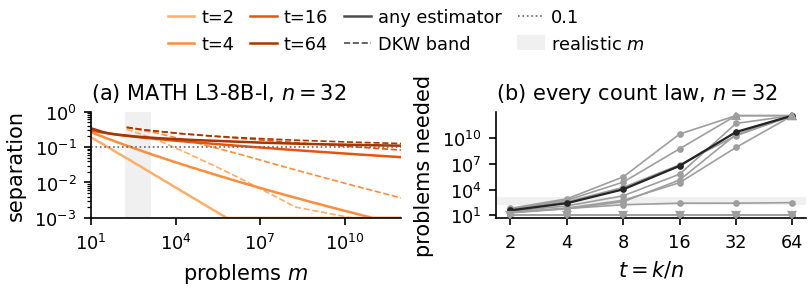

In [40]:
# 7.14b E10, revision 5 [analysis]: how many problems does ANY estimator need? Local two-point (Le Cam) lower bound with a Hellinger constraint at each real count law -> T15, T15c, F24
# Revision 7: the problems needed is kept as an order-of-magnitude figure; the error floor at fixed m (7.14e, T19) is the headline reading.
import contextlib

E10H_THR = 2.0 * CFG["E10H_ACC"]     # accuracy +-0.05 requires the certified separation to fall to 0.1
_E10H_SOLVER = "cutting-plane LP, Hellinger cuts, v1"


@contextlib.contextmanager
def _quiet_c_output():
    """HiGHS can write diagnostics straight to the process's stdout; keep them out of the notebook while an LP runs."""
    saved = []
    try:
        sys.stdout.flush(); sys.stderr.flush()
        null = os.open(os.devnull, os.O_WRONLY)
        for fd in (1, 2):
            saved.append((fd, os.dup(fd)))
            os.dup2(null, fd)
        os.close(null)
    except Exception:
        saved = []
    try:
        yield
    finally:
        for fd, s in saved:
            try:
                os.dup2(s, fd); os.close(s)
            except Exception:
                pass


def hel_level(m):
    """h(m) = 2(1 - (3/4)^(1/(2m))). If two count laws have squared Hellinger distance H^2 <= h(m) (H^2 = sum_j
    (sqrt(pi_j) - sqrt(pi'_j))^2), the affinity of the m-problem samples is (1 - H^2/2)^m >= (3/4)^(1/2), so their total
    variation is at most sqrt(1 - 3/4) = 1/2 (Le Cam's inequality) and no estimator separates them with error below 1/4."""
    return -2.0 * math.expm1(math.log(0.75) / (2.0 * float(m)))


def hel_m_of_level(h):
    return math.log(0.75) / (2.0 * math.log1p(-float(h) / 2.0))


def _hel_psi(d, p0):
    """(sqrt(p0 + d) - sqrt(p0))^2, computed without cancellation."""
    q = np.maximum(p0 + d, 0.0)
    den = (np.sqrt(q) + np.sqrt(p0)) ** 2
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(den > 0, d * d / np.where(den > 0, den, 1.0), 0.0)


def _hel_dpsi(d, p0):
    return 1.0 - np.sqrt(p0 / np.maximum(p0 + d, 1e-300))


class HelSetup:
    """Support grid (pi_grid plus the atoms of D), D's weights w0 on it, the Bernstein matrix and D's count law pi0."""

    def __init__(self, p_hat, n, G):
        vals, cnt = np.unique(np.clip(np.asarray(p_hat, float), 0.0, 1.0), return_counts=True)
        self.X = np.unique(np.concatenate([pi_grid(G), vals]))
        self.w0 = np.zeros(self.X.size)
        self.w0[np.searchsorted(self.X, vals)] = cnt / cnt.sum()
        self.atom = self.w0 > 0
        self.B = bernstein_matrix(n, self.X)
        self.pi0 = self.w0 @ self.B
        self.n = int(n)
        self.BTs = sparse.csr_matrix(np.where(self.B > 1e-16, self.B, 0.0).T)
        self.stats = {"lp": 0, "lp_fail": 0}

    def h2(self, delta):
        d = delta @ self.B
        return float(np.sum(_hel_psi(d, self.pi0))), d

    def clean(self, x, tau=1e-10):
        """D1 = D + x with solver noise removed: no negative mass, no specks below tau off D's atoms, total mass one."""
        D1 = self.w0 + x
        D1[(~self.atom) & (D1 < tau)] = 0.0
        D1 = np.maximum(D1, 0.0)
        return D1 / D1.sum() - self.w0


def hel_solve(S, f, rho, sign, cuts0=(), tol=0.02, itmax=25):
    """max sign * (F_k(D1) - F_k(D)) over D1 = D + delta on the grid with H^2(pi_D1, pi_D) <= rho. Kelley cutting planes on
    the convex per-cell terms psi_j; each LP is a relaxation (its value is reported for diagnostics), and the returned
    perturbation is always exactly feasible: its H^2 is recomputed in closed form and, if it exceeds rho, the perturbation is
    shrunk towards D (H^2 is convex along that segment). Bounds used inside the LP follow from psi_j(d_j) <= rho for every j."""
    G, n1, p0 = S.X.size, S.n + 1, S.pi0
    sig = 2.0 * np.sqrt(rho * p0) + rho                                   # largest d_j with psi_j(d_j) <= rho
    dmin = -np.where(p0 <= rho, p0, 2.0 * np.sqrt(rho * p0) - rho)        # smallest d_j with psi_j(d_j) <= rho
    with np.errstate(divide="ignore", over="ignore"):
        u = np.min(np.where(S.B > 0, (sig + p0)[None, :] / np.where(S.B > 0, S.B, 1.0), np.inf), axis=1)
    u = np.minimum(u, 1.0 - S.w0)                                          # mass a point can receive: B_ij u_i <= sig_j + pi0_j
    idx = np.flatnonzero(S.atom | (u >= 1e-14))
    Gk = idx.size
    scale = np.where(S.atom[idx], 1.0, u[idx])                             # column scaling: off-atom points use mass / u_i
    cuts = [(j, a * sig[j]) for j in range(n1) for a in (-1.0, -0.5, 0.5, 1.0) if a * sig[j] > max(dmin[j], -0.99 * p0[j])]
    cuts += [(j, db) for j, db in cuts0 if db > -0.99 * p0[j]]
    nv = Gk + 2 * n1
    c = np.concatenate([-sign * f[idx] * scale, np.zeros(2 * n1)])
    lo_x = np.where(S.atom[idx], -S.w0[idx], 0.0) / scale
    hi_x = np.where(S.atom[idx], u[idx], 1.0)
    bounds = np.column_stack([np.concatenate([lo_x, dmin / sig, np.zeros(n1)]), np.concatenate([hi_x, np.ones(n1), np.ones(n1)])])
    A_eq = sparse.vstack([sparse.csr_matrix(np.concatenate([scale, np.zeros(2 * n1)])[None, :]),
                          sparse.hstack([sparse.diags(1.0 / sig) @ S.BTs[:, idx] @ sparse.diags(scale), -sparse.identity(n1),
                                         sparse.csr_matrix((n1, n1))])]).tocsr()
    b_eq = np.zeros(n1 + 1)
    budget = sparse.csr_matrix(np.concatenate([np.zeros(Gk + n1), np.ones(n1)])[None, :])
    opts = {"primal_feasibility_tolerance": 1e-10, "dual_feasibility_tolerance": 1e-10}
    best, lp_up, it = None, float("nan"), 0
    for it in range(itmax):
        J = np.array([j for j, _ in cuts]); Dd = np.array([db for _, db in cuts]); P = p0[J]
        g1 = _hel_dpsi(Dd, P); K = J.size
        rows = sparse.csr_matrix((np.concatenate([g1 * sig[J] / rho, -np.ones(K)]),
                                  (np.tile(np.arange(K), 2), np.concatenate([Gk + J, Gk + n1 + J]))), shape=(K, nv))
        A_ub = sparse.vstack([budget, rows]).tocsr()
        b_ub = np.concatenate([[1.0], (g1 * Dd - _hel_psi(Dd, P)) / rho])
        r = None
        with _quiet_c_output():
            for meth in ("highs-ds", "highs-ipm"):
                r = optimize.linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method=meth, options=opts)
                S.stats["lp"] += 1
                if r.status == 0:
                    break
        if r is None or r.status != 0:
            S.stats["lp_fail"] += 1
            break
        lp_up = -r.fun
        x = np.zeros(G); x[idx] = r.x[:Gk] * scale
        delta = S.clean(x)
        h2, d = S.h2(delta)
        om = sign * float(f @ delta)
        if best is None or h2 <= rho * (1 + tol) or h2 < best[1]:
            best = (delta, h2, om)
        if h2 <= rho * (1 + tol):
            break
        s = r.x[Gk + n1:] * rho
        dlp = r.x[Gk:Gk + n1] * sig
        ps = _hel_psi(d, p0)
        for j in np.flatnonzero(ps > s + 1e-6 * rho / n1):
            if d[j] > -0.99 * p0[j]:
                cuts.append((j, d[j]))
            if dlp[j] > -0.99 * p0[j] and abs(dlp[j] - d[j]) > 1e-3 * abs(d[j]):
                cuts.append((j, dlp[j]))
    if best is None:
        return None
    delta, h2, om = best
    if h2 > rho:                                                           # exact repair: shrink towards D
        a_lo, a_hi = 0.0, 1.0
        for _ in range(50):
            a = 0.5 * (a_lo + a_hi)
            if S.h2(a * delta)[0] <= rho:
                a_lo = a
            else:
                a_hi = a
        delta = a_lo * delta
        h2, om = S.h2(delta)[0], sign * float(f @ delta)
    return {"omega": om, "rho_act": h2, "lp_upper": lp_up, "iters": it + 1, "d": delta @ S.B}


def hel_pair_h2(S, d1, d2):
    q1, q2 = np.maximum(S.pi0 + d1, 0.0), np.maximum(S.pi0 + d2, 0.0)
    den = (np.sqrt(q1) + np.sqrt(q2)) ** 2
    with np.errstate(divide="ignore", invalid="ignore"):
        return float(np.sum(np.where(den > 0, (d1 - d2) ** 2 / np.where(den > 0, den, 1.0), 0.0)))


def hel_hull(cfg, L):
    """Largest certified separation at squared-Hellinger level L. Every (level, sep) in cfg is a pair of distributions
    (P, Q) with F_k(Q) - F_k(P) = sep, H^2(pi_P, pi_Q) <= level and both count laws within level of D's. Mixing two pairs
    with weight a mixes the separations linearly and keeps every H^2 below the mixed level (H^2 is jointly convex), so the
    upper concave hull through (0, 0) is certified too, and so is anything below a smaller level."""
    P = sorted(set([(0.0, 0.0)] + [(float(l), float(s)) for l, s in cfg if np.isfinite(l) and np.isfinite(s) and s > 0]))
    H = []
    for p in P:
        while len(H) >= 2 and (H[-1][0] - H[-2][0]) * (p[1] - H[-2][1]) - (H[-1][1] - H[-2][1]) * (p[0] - H[-2][0]) >= 0:
            H.pop()
        H.append(p)
    xs, ys = np.array([h[0] for h in H]), np.maximum.accumulate(np.array([h[1] for h in H]))
    return np.interp(np.atleast_1d(np.asarray(L, float)), xs, ys, right=ys[-1])


def hel_march(S, f, levels, early=True, thr=None):
    """Both directions at every level (largest first), warm-starting the cuts from the previous level. Each level adds three
    certified pairs: (D, D+), (D-, D) and (D-, D+). With early=True the march stops once the separation has stayed below
    0.9 thr at two consecutive levels (it only decreases further)."""
    thr = E10H_THR if thr is None else thr
    cfg, rows, prev, below = [], [], {1: None, -1: None}, 0
    for rho in levels:
        out = {}
        for sign in (1, -1):
            c0 = ()
            if prev[sign] is not None:
                d_prev, r_prev = prev[sign]
                sc = math.sqrt(rho / r_prev)
                c0 = [(j, d_prev[j] * a * sc) for j in range(S.n + 1) for a in (0.8, 1.25)]
            r = hel_solve(S, f, rho, sign, cuts0=c0)
            out[sign] = r
            if r is not None:
                prev[sign] = (r["d"], rho)
                cfg.append((r["rho_act"], max(r["omega"], 0.0)))
        rec = {"rho": float(rho)}
        for sign, sfx in ((1, "+"), (-1, "-")):
            r = out[sign]
            rec["om" + sfx] = float(r["omega"]) if r else float("nan")
            rec["up" + sfx] = float(r["lp_upper"]) if r else float("nan")
            rec["it" + sfx] = int(r["iters"]) if r else -1
        if out[1] is not None and out[-1] is not None:
            lev = max(hel_pair_h2(S, out[1]["d"], out[-1]["d"]), out[1]["rho_act"], out[-1]["rho_act"])
            sep = max(out[1]["omega"], 0.0) + max(out[-1]["omega"], 0.0)
            cfg.append((lev, sep))
            rec["pair_level"], rec["pair_sep"] = float(lev), float(sep)
        rows.append(rec)
        if early:
            cur = max(rec.get("pair_sep", 0.0), np.nan_to_num(rec["om+"]), np.nan_to_num(rec["om-"]))
            below = below + 1 if cur < 0.9 * thr else 0
            if below >= 2:
                break
    return cfg, rows


def hel_problems_needed(cfg, lev_min, thr=None):
    """Largest m at which the certified separation still exceeds thr, so every estimator needs more than m problems for
    accuracy thr/2 (probability above 3/4 at every count law in the neighbourhood). Returns (m, flag): flag '<' if the bound
    does not bind even at the smallest m, '>' if it still binds at the largest m that was examined."""
    thr = E10H_THR if thr is None else thr
    m_lo, m_hi = map(float, CFG["E10H_M_RANGE"])
    Dm = lambda m: float(hel_hull(cfg, hel_level(m))[0])
    if Dm(m_lo) <= thr:
        return m_lo, "<"
    top = min(m_hi, hel_m_of_level(lev_min))
    if Dm(top) > thr:
        return top, ">"
    a, b = math.log(m_lo), math.log(top)
    for _ in range(80):
        cmid = 0.5 * (a + b)
        if Dm(math.exp(cmid)) > thr:
            a = cmid
        else:
            b = cmid
    return math.exp(a), ""


def _hel_levels():
    m_lo, m_hi = map(float, CFG["E10H_M_RANGE"])
    r_hi, r_lo = hel_level(m_lo), hel_level(m_hi) / 4.0
    K = int(math.ceil(CFG["E10H_PER_DECADE"] * math.log10(r_hi / r_lo)))
    return r_hi * 10.0 ** (-np.arange(K + 1) / CFG["E10H_PER_DECADE"])


def _fmt_m(v, flag=""):
    if flag == "<":
        return f"<{v:.0f}"
    if flag == ">":
        return f">{v:.0e}".replace("e+", "e")
    if not np.isfinite(v):
        return "--"
    if v < 1e5:
        e = int(math.floor(math.log10(max(v, 1.0))))
        return f"{int(round(v, -e + 1)):,}"
    return f"{v:.1e}".replace("e+0", "e").replace("e+", "e")


E10H = None
E10_SUMMARY = None
if not E10_DISTS:
    print("E10 (Hellinger) skipped: no ground-truth distribution available.")
else:
    _n0h = int(CFG["E10H_N"])
    _levels = _hel_levels()
    _rep = next((d for d in E10_DISTS if d.startswith("MATH L3-8B")), list(E10_DISTS)[0])
    _units = {}
    for _n in sorted(set([_n0h] + list(CFG["E10H_FIXED_NS"]))):
        _ks = sorted(set(([int(t * _n) for t in CFG["E10H_TS"]] if _n == _n0h else [])
                         + ([int(k) for k in CFG["E10H_FIXED_K"]] if _n in CFG["E10H_FIXED_NS"] else [])))
        _units[_n] = _ks
    _settings = json.dumps([CFG["E10H_G"], CFG["E10H_PER_DECADE"], CFG["E10H_M_RANGE"], CFG["E10H_ACC"], _E10H_SOLVER])

    def _e10h_unit(name, ph, n, ks, full):
        S = HelSetup(ph, n, CFG["E10H_G"])
        t0 = time.time()
        res = {"n": n, "ks": ks, "full": full, "F0": {}, "cfg": {}, "rows": {}}
        for k in ks:
            f = fail_k(S.X, k)
            res["F0"][k] = float(S.w0 @ f)
            cfg_k, rows_k = hel_march(S, f, _levels, early=not full)
            res["cfg"][k], res["rows"][k] = cfg_k, rows_k
        res["stats"] = dict(S.stats, seconds=round(time.time() - t0, 1), grid=int(S.X.size))
        print(f"[E10] {name}, n={n}: k = {ks} done in {time.time() - t0:.0f}s ({S.stats['lp']} LPs, {S.stats['lp_fail']} failed)")
        return res

    E10H, _loaded = {}, 0
    for _name, _ph in E10_DISTS.items():
        for _n, _ks in _units.items():
            _full = (_name == _rep and _n == _n0h)
            _key = "e10h_" + hashlib.sha1(json.dumps([_name, data_tag(np.asarray(_ph, float)), _n, _ks, _full, _settings]).encode()).hexdigest()[:12]
            E10H[(_name, _n)] = cached(_key, lambda nm=_name, ph=_ph, n=_n, ks=_ks, fu=_full: _e10h_unit(nm, ph, n, ks, fu))
            _loaded += int(RUN_LOG["stages"].get(("smoke_" + _key) if SMOKE else _key, {}).get("status") == "resumed")
    _minutes = sum(u["stats"]["seconds"] for u in E10H.values()) / 60.0      # compute time of all pieces, wherever computed

    def _pn(name, n, k):
        u = E10H[(name, n)]
        rows = u["rows"][k]
        return hel_problems_needed(u["cfg"][k], min(r["rho"] for r in rows))

    def _floor(name, n, k, m):
        return 0.5 * float(hel_hull(E10H[(name, n)]["cfg"][k], hel_level(m))[0])

    _dists = list(E10_DISTS)
    _mreal = int(CFG["REALISTIC_M_MAX"])
    _tn4 = 4 if 4 in CFG["E10H_TS"] else CFG["E10H_TS"][0]
    _tn16 = 16 if 16 in CFG["E10H_TS"] else CFG["E10H_TS"][-1]
    _rows15, _raw15 = [], {}
    for name in _dists:
        rec = {"Distribution": name}
        for t in CFG["E10H_TS"]:
            v, fl = _pn(name, _n0h, int(t * _n0h))
            _raw15[(name, t)] = (v, fl)
            rec[f"t={t:g}"] = _fmt_m(v, fl)
        _rows15.append(rec)
    T15 = pd.DataFrame(_rows15)
    print(T15.to_string(index=False))
    _lim = {t: twoE(_n0h, int(t * _n0h))["upper"] for t in CFG["E10H_TS"]}
    save_table(T15, "T15_problems_needed_any_estimator",
               f"E10, what any estimator needs (n = {_n0h} attempts per problem). Columns t = ...: the number of problems m below "
               f"which no estimator can be within +-{CFG['E10H_ACC']:g} of the population pass@k, k = t n, with probability above 3/4 at every "
               f"success-rate distribution whose count law lies within squared Hellinger distance h(m) = 2(1 - (3/4)^(1/(2m))) "
               f"of the real one (Le Cam's two-point method; local minimax lower bound); '>' = still binding at m = "
               f"{_fmt_m(float(CFG['E10H_M_RANGE'][1]), '>')[1:]}; '<' = not binding at m = {float(CFG['E10H_M_RANGE'][0]):.0f}. These are "
               f"order-of-magnitude figures: they are read where a nearly flat separation curve crosses 0.1, so they move by orders of "
               f"magnitude with the accuracy target (T15d) and the draw of problems (T18); the error floor at a fixed m (T19, T20) is "
               f"the stable reading of the same bound. Each row uses the per-problem rates from 1,024 or about 10,000 attempts as D. "
               f"Population limits 2E_n(x^k) for t = "
               + ", ".join(f"{t:g}: {_lim[t]:.1e}" for t in CFG["E10H_TS"]) + ".", width_in=5.45)

    # fixed k, different n: what more attempts per problem buy
    _fixed = {}
    _rows15c = []
    for k in CFG["E10H_FIXED_K"]:
        rec = {"k": f"{int(k):,}"}
        for n in sorted(set([_n0h] + list(CFG["E10H_FIXED_NS"]))):
            if k not in E10H[(_dists[0], n)]["ks"]:
                rec[f"n={n}"] = "--"
                continue
            vals = [_pn(name, n, k) for name in _dists]
            _fixed[(int(k), n)] = vals
            key = [(v if fl != ">" else float("inf")) if fl != "<" else 0.0 for v, fl in vals]
            order = np.argsort(key)
            med = vals[order[(len(vals) - 1) // 2]]
            lo_, hi_ = vals[order[0]], vals[order[-1]]
            rec[f"n={n}"] = f"{_fmt_m(*med)} [{_fmt_m(*lo_)}, {_fmt_m(*hi_)}]"
        _rows15c.append(rec)
    T15C = pd.DataFrame(_rows15c)
    print(T15C.to_string(index=False))
    save_table(T15C, "T15c_problems_needed_fixed_k",
               f"E10, the same lower bound at fixed k for n = 16, 32 and 64 attempts per problem: median [smallest, largest] "
               f"number of problems below which no estimator reaches +-{CFG['E10H_ACC']:g} with probability above 3/4, over the "
               f"{len(_dists)} real count laws. Notation as in T15.", width_in=5.0)

    # diagnostics: certified value against the LP relaxation on the same grid (first level excluded: largest perturbations)
    _gaps, _nfail, _nlp = [], 0, 0
    for (name, n), u in E10H.items():
        _nfail += u["stats"]["lp_fail"]; _nlp += u["stats"]["lp"]
        for k, rows in u["rows"].items():
            for r in rows[1:]:
                for sfx in ("+", "-"):
                    if np.isfinite(r["up" + sfx]) and r["up" + sfx] > 1e-6:
                        _gaps.append(max(0.0, (r["up" + sfx] - r["om" + sfx]) / r["up" + sfx]))
    _gaps = np.asarray(_gaps)
    print(f"E10 solver check: certified separation within {100 * np.quantile(_gaps, 0.99):.1f}% of the LP relaxation on the same "
          f"grid in 99% of {len(_gaps)} solves (largest gap {100 * _gaps.max():.1f}%); {_nfail} of {_nlp} LPs failed "
          f"(a failed level is skipped; the certified curve uses the other levels). Compute time {_minutes:.1f} min; "
          f"{_loaded} of {len(E10H)} pieces were loaded from checkpoints in this session.")

    def _hel_cvx_check(ph, n, cases):
        """Independent check when cvxpy is installed: the same convex program on the same grid, solved by a conic solver.
        A conic solution is used only if its own H^2, recomputed in closed form, is within 0.1% of the budget."""
        try:
            import cvxpy as cp
        except Exception:
            return None
        S = HelSetup(ph, n, CFG["E10H_G"])
        out = []
        for t, m in cases:
            k = int(t * n)
            f = fail_k(S.X, k)
            rho = hel_level(m)
            F0 = float(S.w0 @ f)
            for sign in (1, -1):
                ours = hel_solve(S, f, rho, sign)
                w = cp.Variable(S.X.size, nonneg=True)
                aff = cp.sum(cp.multiply(np.sqrt(S.pi0), cp.sqrt(S.B.T @ w)))
                prob = cp.Problem(cp.Maximize(sign * (f @ w)), [cp.sum(w) == 1, aff >= 1 - rho / 2])
                val, ratio, used = float("nan"), float("nan"), "--"
                for solver in ("CLARABEL", "SCS"):
                    try:
                        with warnings.catch_warnings():
                            warnings.simplefilter("ignore")
                            prob.solve(solver=solver)
                        if w.value is None:
                            continue
                        wv = np.maximum(np.asarray(w.value, float), 0.0)
                        wv /= wv.sum()
                        h2c = S.h2(wv - S.w0)[0]
                        if h2c <= rho * 1.001:
                            val, ratio, used = sign * (float(f @ wv) - F0), h2c / rho, solver
                            break
                    except Exception:
                        continue
                out.append({"t": t, "m": m, "sign": sign, "certified": ours["omega"] if ours else float("nan"),
                            "lp_relaxation": ours["lp_upper"] if ours else float("nan"), "conic": val, "conic_h2_over_rho": ratio,
                            "solver": used})
        return out

    try:
        _cvx = _hel_cvx_check(E10_DISTS[_rep], _n0h, [(4, 100), (16, 1000)])
    except Exception as _exc:
        _cvx = None
        print(f"E10 conic cross-check failed to run ({type(_exc).__name__}); the certified values do not depend on it.")
    if _cvx is None:
        print("E10 conic cross-check skipped (cvxpy is not installed); the certified values do not depend on it.")
    else:
        _agree = 0
        for r in _cvx:
            ok = (r["conic"] >= r["certified"] - 1e-4) and (r["conic"] <= r["lp_relaxation"] + 1e-4)
            _agree += int(bool(ok))
            print(f"E10 conic cross-check, {_rep}, t={r['t']:g}, m={r['m']:,}, {'max' if r['sign'] > 0 else 'min'}: certified "
                  f"{r['certified']:.5f}, conic {r['conic']:.5f} ({r['solver']}, its H^2/budget {r['conic_h2_over_rho']:.4f}), "
                  f"LP relaxation {r['lp_relaxation']:.5f}")
        print(f"E10 conic cross-check: the conic optimum lies between the certified value and the LP relaxation (to 1e-4) in "
              f"{_agree} of {len(_cvx)} instances.")

    _ms = {t: [_raw15[(name, t)] for name in _dists] for t in CFG["E10H_TS"]}
    E10_SUMMARY = {"n0": _n0h, "acc": CFG["E10H_ACC"], "thr": E10H_THR, "m_range": list(map(float, CFG["E10H_M_RANGE"])),
                   "dists": _dists, "rep": _rep, "m_star": {f"{t:g}": [float(v) for v, fl in _ms[t]] for t in CFG["E10H_TS"]},
                   "flags": {f"{t:g}": [fl for v, fl in _ms[t]] for t in CFG["E10H_TS"]},
                   "fixed_k": {f"{k}_{n}": [[float(v), fl] for v, fl in vals] for (k, n), vals in _fixed.items()},
                   "twoE": {f"{t:g}": _lim[t] for t in CFG["E10H_TS"]}, "solver_gap_q99": float(np.quantile(_gaps, 0.99)),
                   "solver_gap_max": float(_gaps.max()), "lp_fail": int(_nfail), "lp_total": int(_nlp), "minutes": _minutes,
                   "t_near": _tn4, "t16": _tn16, "m_real": _mreal, "dkw": E10_DKW, "conic_check": _cvx}

    def _span(t):
        vals = _ms[t]
        fin = [v for v, fl in vals if fl == ""]
        n_hi = sum(fl == ">" for v, fl in vals)
        n_lo = sum(fl == "<" for v, fl in vals)
        lo_s, hi_s = (_fmt_m(min(fin)), _fmt_m(max(fin))) if fin else ("", "")
        txt = (lo_s if lo_s == hi_s else f"{lo_s} to {hi_s}") if fin else ""
        if n_hi:
            txt += (", " if txt else "") + f"{_fmt_m(float(CFG['E10H_M_RANGE'][1]), '>')} in {n_hi}/{len(vals)}"
        if n_lo:
            txt += (", " if txt else "") + f"not binding in {n_lo}/{len(vals)}"
        return txt

    E10_SUMMARY["span"] = {f"{t:g}": _span(t) for t in CFG["E10H_TS"]}
    E10_SUMMARY["above_real"] = {f"{t:g}": int(sum((fl == ">") or (fl == "" and v > _mreal) for v, fl in _ms[t])) for t in CFG["E10H_TS"]}
    VERDICTS["E10 problems needed for +-0.05, any estimator (descriptive)"] = "; ".join(
        f"k={t:g}n: {E10_SUMMARY['span'][f'{t:g}']}" for t in CFG["E10H_TS"])
    print("E10 (n = %d), problems below which no estimator reaches +-%g: " % (_n0h, CFG["E10H_ACC"])
          + VERDICTS["E10 problems needed for +-0.05, any estimator (descriptive)"])
    _silent = [name for name in _dists if all(_raw15[(name, t)][1] == "<" for t in CFG["E10H_TS"])]
    if _silent:
        print("E10: the bound does not bind at any t for " + ", ".join(_silent) + " (pass@k at these k: "
              + ", ".join(f"{1 - E10H[(name, _n0h)]['F0'][int(CFG['E10H_TS'][0] * _n0h)]:.4f}" for name in _silent)
              + f" at t = {CFG['E10H_TS'][0]:g}); +-{CFG['E10H_ACC']:g} is a loose target when pass@k is that close to 1.")
    print("E10 count laws for which a benchmark of %s problems is provably too small: " % f"{_mreal:,}"
          + ", ".join(f"k={t:g}n: {E10_SUMMARY['above_real'][f'{t:g}']}/{len(_dists)}" for t in CFG["E10H_TS"]))

    # ---- F24: (a) certified separation against m for one count law, with the DKW band width; (b) problems needed against t
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
    _mg = 10.0 ** np.arange(math.log10(float(CFG["E10H_M_RANGE"][0])), math.log10(float(CFG["E10H_M_RANGE"][1])) + 1e-9, 0.05)
    _ta = [t for t in CFG["E10H_TS"] if t in (2, 4, 16, 64)] or list(CFG["E10H_TS"])     # panel (a): the t of the DKW table
    _tcol = {t: c for t, c in zip(_ta, ORANGES)}
    f24 = {"representative": _rep, "n": _n0h, "m": _mg, "separation": {}, "dkw_width": {}, "problems_needed": {}}
    _urep = E10H[(_rep, _n0h)]
    for t in _ta:
        k = int(t * _n0h)
        sep = hel_hull(_urep["cfg"][k], [hel_level(m) for m in _mg])
        ax1.plot(_mg, np.maximum(sep, 1e-3), color=_tcol[t], lw=1.2)
        f24["separation"][f"t{t:g}"] = sep
        if E10 is not None and t in CFG["E10_TS"] and _n0h in CFG["E10_NS"]:
            sub = E10[(E10["dist"] == _rep) & (E10["n"] == _n0h) & (E10["t"] == t)].sort_values("m_equiv")
            ax1.plot(sub["m_equiv"], np.maximum(sub["width"], 1e-3), color=_tcol[t], lw=0.8, ls="--")
            f24["dkw_width"][f"t{t:g}"] = {"m": sub["m_equiv"].values, "width": sub["width"].values}
    ax1.axhline(E10H_THR, color=BOUND_COLOR, lw=0.8, ls=":")
    ax1.axvspan(min(CFG["E7_MS"]), _mreal, color="#f0f0f0", lw=0)
    ax1.set_xscale("log"); ax1.set_yscale("log")
    ax1.set_xlim(float(CFG["E10H_M_RANGE"][0]), float(CFG["E10H_M_RANGE"][1])); ax1.set_ylim(1e-3, 1.0)
    ax1.xaxis.set_major_locator(matplotlib.ticker.FixedLocator([1e1, 1e4, 1e7, 1e10]))
    ax1.yaxis.set_major_locator(matplotlib.ticker.FixedLocator([1e-3, 1e-2, 1e-1, 1.0]))
    ax1.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter()); ax1.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax1.set_xlabel("problems $m$"); ax1.set_ylabel("separation")
    panel_label(ax1, f"(a) {_rep}, $n={_n0h}$")
    _tt = np.array(CFG["E10H_TS"], float)
    _ycap = float(CFG["E10H_M_RANGE"][1]) * 4
    for name in _dists:
        vals = [_raw15[(name, t)] for t in CFG["E10H_TS"]]
        ys = [(_ycap if fl == ">" else (float(CFG["E10H_M_RANGE"][0]) if fl == "<" else v)) for v, fl in vals]
        strong = name == _rep
        ax2.plot(_tt, ys, color="#252525" if strong else "#9e9e9e", lw=1.1 if strong else 0.8, marker="o", ms=2.2, zorder=3 if strong else 2)
        for tt_, (v, fl), y in zip(_tt, vals, ys):
            if fl:
                ax2.plot([tt_], [y], marker="^" if fl == ">" else "v", ms=3.2, color="#252525" if strong else "#9e9e9e", zorder=4)
        f24["problems_needed"][name] = [[float(v), fl] for v, fl in vals]
    ax2.axhspan(min(CFG["E7_MS"]), _mreal, color="#f0f0f0", lw=0)
    ax2.set_xscale("log", base=2); ax2.set_yscale("log")
    ax2.set_ylim(float(CFG["E10H_M_RANGE"][0]) * 0.5, _ycap * 3)
    ax2.yaxis.set_major_locator(matplotlib.ticker.FixedLocator([1e1, 1e4, 1e7, 1e10]))
    ax2.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax2.xaxis.set_major_locator(matplotlib.ticker.FixedLocator(list(_tt)))
    ax2.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _p: f"{v:g}"))
    ax2.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    ax2.set_xlabel("$t=k/n$"); ax2.set_ylabel("problems needed")
    panel_label(ax2, f"(b) every count law, $n={_n0h}$")
    _h = [Line2D([], [], color=_tcol[t], lw=1.2, label=f"t={t:g}") for t in _ta]
    _h += [Line2D([], [], color="#4d4d4d", lw=1.2, label="any estimator"),
           Line2D([], [], color="#4d4d4d", lw=0.8, ls="--", label="DKW band"),
           Line2D([], [], color=BOUND_COLOR, lw=0.8, ls=":", label="0.1"),
           Patch(color="#f0f0f0", label="realistic $m$")]
    shared_legend(fig, _h, [h.get_label() for h in _h], ncol=4)
    finish_figure(fig, "F24_problems_needed_any_estimator", f24,
                  "Local minimax lower bound on real count laws: separation every estimator must resolve, and problems needed.")

Figure F24 (E10, what any estimator needs on real count laws; $n=32$).
- (a) One count law, Llama-3-8B-Instruct on MATH (E8's if E9 did not run). Solid: the certified separation in pass@$k$ between two success-rate distributions whose count laws lie within squared Hellinger distance $h(m)=2\{1-(3/4)^{1/(2m)}\}$ of the real one and of each other, against the number of problems $m$; every estimator errs by at least half of it with probability at least $1/4$ under one of the two. Dashed: the width of the DKW band of revision 4 (E10a) for the same count law, drawn at the $m$ that pins the count CDF to the band's tolerance. One colour per $t=k/n$. Dotted: separation 0.1, which corresponds to accuracy $\pm0.05$. The shaded range marks benchmark sizes in use (164 to 1,319 problems).
- (b) Problems needed for $\pm0.05$, against $t$, for every count law (grey; the count law of (a) in black). An upward triangle means the bound still binds at $m=10^{12}$; a downward triangle means it does not bind even at $m=10$.

The bound is local: it applies to every estimator that is to be accurate at all distributions whose count laws are this close to the real one, not to an estimator allowed to assume a parametric family. Alternatives live on a support grid, which can only make the separation smaller. T15 gives the numbers, T15c the same bound at fixed $k$ for $n=16$, 32 and 64, and T15b the DKW computation. Panel (b) reads each curve of (a) where it crosses 0.1. Where a curve is nearly flat that point is fragile (T18), so these numbers are orders of magnitude; reading the same curves at a fixed $m$ gives the error floor of T19 and F27.

In [41]:
# 7.14c E10, revision 6 [analysis]: the bound at +-0.1 (the accuracy of C1), and how tight it is: a profile likelihood-ratio band on the same count laws -> T15d, T17
# A lower bound alone leaves open how many problems are actually enough. The natural likelihood-based construction is the
# profile likelihood-ratio interval for pass@k: the range of F_k over all distributions whose count law pi satisfies
# 2 m KL(pi_hat || pi) <= q, with q a chi-square(1) quantile (the multinomial likelihood-ratio statistic is 2 m KL). As in
# E10a, the best case is computed: the count histogram equals the real count law, so the interval is the range of F_k over
# the KL ball of radius rho = q / (2m) around it, on the same support grid. The width is taken from the LP relaxation (an
# upper bound on the width over the grid), and the m at which it falls to 0.1 (accuracy +-0.05 for the midpoint) is found by
# bisection in rho. Because rho = q / (2m), one curve gives every calibration: level 3/4 (q = chi2_1(0.75), the probability
# level of the lower bound), 95% (chi2_1(0.95)) and the simultaneous 95% set for the whole count law (chi2_n(0.95)).
def _kl_psi(d, p0):
    """p0 log(p0 / (p0 + d)) + d = p0 (x - log(1 + x)), x = d / p0 (one cell of KL(pi0 || pi0 + d) plus the mass term);
    d itself for an empty cell (p0 = 0, d >= 0); inf if the cell would be emptied. Series for small x avoids cancellation."""
    d = np.asarray(d, float); p0 = np.asarray(p0, float)
    pos = p0 > 0
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        x = np.where(pos, d / np.where(pos, p0, 1.0), 0.0)
        small = np.abs(x) < 1e-4
        xs = np.maximum(x, -1.0 + 1e-15)
        g = np.where(small, x * x / 2.0 - x ** 3 / 3.0 + x ** 4 / 4.0, xs - np.log1p(xs))
        g = np.where(x <= -1.0, np.inf, g)
        return np.where(pos, p0 * g, np.where(d >= 0, d, np.inf))


def _kl_dpsi(d, p0):
    p0 = np.asarray(p0, float)
    return np.where(p0 > 0, np.asarray(d, float) / np.maximum(p0 + d, 1e-300), 1.0)


def _kl_bounds(p0, rho, iters=90):
    """Per cell, the largest and smallest d with psi_j(d) <= rho (bisection; brackets from x - log(1+x) >= x^2/(2(1+x)) for
    x >= 0 and >= x^2/2 for -1 < x < 0)."""
    p0 = np.asarray(p0, float)
    a, b = np.zeros_like(p0), rho + np.sqrt(rho * rho + 2.0 * rho * p0)
    for _ in range(iters):
        mid = 0.5 * (a + b)
        ok = _kl_psi(mid, p0) <= rho
        a, b = np.where(ok, mid, a), np.where(ok, b, mid)
    sig = np.where(p0 > 0, a, rho)
    dl = -np.minimum(p0 * (1.0 - 1e-12), np.sqrt(2.0 * rho * p0))
    feas = _kl_psi(dl, p0) <= rho
    a2, b2 = dl.copy(), np.zeros_like(p0)
    for _ in range(iters):
        mid = 0.5 * (a2 + b2)
        ok = _kl_psi(mid, p0) <= rho
        b2, a2 = np.where(ok, mid, b2), np.where(ok, a2, mid)
    dmin = np.where(p0 > 0, np.where(feas, dl, b2), 0.0)
    return np.maximum(sig, 1e-300), dmin


def _div_value(S, delta, psi):
    d = delta @ S.B
    return float(np.sum(psi(d, S.pi0))), d


def div_solve(S, f, rho, sign, psi=_kl_psi, dpsi=_kl_dpsi, bounds=_kl_bounds, cuts0=(), tol=0.02, itmax=25):
    """As hel_solve, for any separable convex divergence sum_j psi_j(d_j) <= rho between count laws (here KL(pi_D || pi_D1))."""
    G, n1, p0 = S.X.size, S.n + 1, S.pi0
    sig, dmin = bounds(p0, rho)
    with np.errstate(divide="ignore", over="ignore"):
        u = np.min(np.where(S.B > 0, (sig + p0)[None, :] / np.where(S.B > 0, S.B, 1.0), np.inf), axis=1)
    u = np.minimum(u, 1.0 - S.w0)
    idx = np.flatnonzero(S.atom | (u >= 1e-14))
    Gk = idx.size
    scale = np.where(S.atom[idx], 1.0, u[idx])
    cuts = [(j, a * (sig[j] if a > 0 else -dmin[j])) for j in range(n1) for a in (-1.0, -0.5, 0.5, 1.0)
            if (a > 0 or dmin[j] < 0)]
    cuts = [(j, db) for j, db in cuts if db > -0.99 * p0[j] or (p0[j] == 0 and db >= 0)]
    cuts += [(j, db) for j, db in cuts0 if db > -0.99 * p0[j] or (p0[j] == 0 and db >= 0)]
    nv = Gk + 2 * n1
    c = np.concatenate([-sign * f[idx] * scale, np.zeros(2 * n1)])
    lo_x = np.where(S.atom[idx], -S.w0[idx], 0.0) / scale
    hi_x = np.where(S.atom[idx], u[idx], 1.0)
    bnds = np.column_stack([np.concatenate([lo_x, dmin / sig, np.zeros(n1)]), np.concatenate([hi_x, np.ones(n1), np.ones(n1)])])
    A_eq = sparse.vstack([sparse.csr_matrix(np.concatenate([scale, np.zeros(2 * n1)])[None, :]),
                          sparse.hstack([sparse.diags(1.0 / sig) @ S.BTs[:, idx] @ sparse.diags(scale), -sparse.identity(n1),
                                         sparse.csr_matrix((n1, n1))])]).tocsr()
    b_eq = np.zeros(n1 + 1)
    budget = sparse.csr_matrix(np.concatenate([np.zeros(Gk + n1), np.ones(n1)])[None, :])
    opts = {"primal_feasibility_tolerance": 1e-10, "dual_feasibility_tolerance": 1e-10}
    best, lp_up, it = None, float("nan"), 0
    for it in range(itmax):
        J = np.array([j for j, _ in cuts]); Dd = np.array([db for _, db in cuts]); P = p0[J]
        g1 = dpsi(Dd, P); K = J.size
        rows = sparse.csr_matrix((np.concatenate([g1 * sig[J] / rho, -np.ones(K)]),
                                  (np.tile(np.arange(K), 2), np.concatenate([Gk + J, Gk + n1 + J]))), shape=(K, nv))
        A_ub = sparse.vstack([budget, rows]).tocsr()
        b_ub = np.concatenate([[1.0], (g1 * Dd - psi(Dd, P)) / rho])
        r = None
        with _quiet_c_output():
            for meth in ("highs-ds", "highs-ipm"):
                r = optimize.linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bnds, method=meth, options=opts)
                S.stats["lp"] += 1
                if r.status == 0:
                    break
        if r is None or r.status != 0:
            S.stats["lp_fail"] += 1
            break
        lp_up = -r.fun
        x = np.zeros(G); x[idx] = r.x[:Gk] * scale
        delta = S.clean(x)
        dv, d = _div_value(S, delta, psi)
        om = sign * float(f @ delta)
        if best is None or dv <= rho * (1 + tol) or dv < best[1]:
            best = (delta, dv, om)
        if dv <= rho * (1 + tol):
            break
        s = r.x[Gk + n1:] * rho
        dlp = r.x[Gk:Gk + n1] * sig
        ps = psi(d, p0)
        for j in np.flatnonzero(ps > s + 1e-6 * rho / n1):
            if d[j] > -0.99 * p0[j]:
                cuts.append((j, d[j]))
            if dlp[j] > -0.99 * p0[j] and abs(dlp[j] - d[j]) > 1e-3 * abs(d[j]):
                cuts.append((j, dlp[j]))
    if best is None:
        return None
    delta, dv, om = best
    if dv > rho:
        a_lo, a_hi = 0.0, 1.0
        for _ in range(50):
            a = 0.5 * (a_lo + a_hi)
            if _div_value(S, a * delta, psi)[0] <= rho:
                a_lo = a
            else:
                a_hi = a
        delta = a_lo * delta
        dv, om = _div_value(S, delta, psi)[0], sign * float(f @ delta)
    return {"omega": om, "div": dv, "lp_upper": lp_up, "iters": it + 1, "d": delta @ S.B}


def lr_band_crossing(S, f, levels, thr, refine=8):
    """Width of the identification interval for F_k over the KL ball KL(pi_D || pi) <= rho, at decreasing rho; the LP
    relaxation gives an upper bound on the width on the grid, which is what the band would report at best. Returns the rows,
    rho* (largest rho at which the width falls to thr, by bisection in log rho) and a flag ('<' width already below thr at the
    largest rho; '>' still above thr at the smallest)."""
    rows, prev, below = [], {1: None, -1: None}, 0

    def _pair(rho):
        out = {}
        for sign in (1, -1):
            c0 = ()
            if prev[sign] is not None:
                d_prev, r_prev = prev[sign]
                sc = math.sqrt(rho / r_prev)
                c0 = [(j, d_prev[j] * a * sc) for j in range(S.n + 1) for a in (0.8, 1.25)]
            r = div_solve(S, f, rho, sign, cuts0=c0)
            out[sign] = r
            if r is not None:
                prev[sign] = (r["d"], rho)
        ok = out[1] is not None and out[-1] is not None
        rec = {"rho": float(rho), "width_up": (out[1]["lp_upper"] + out[-1]["lp_upper"]) if ok else float("nan"),
               "width_cert": (max(out[1]["omega"], 0) + max(out[-1]["omega"], 0)) if ok else float("nan")}
        return rec

    for rho in levels:
        rec = _pair(rho)
        rows.append(rec)
        w = rec["width_up"]
        below = below + 1 if (np.isfinite(w) and w < 0.9 * thr) else 0
        if below >= 2:
            break
    W = np.array([r["width_up"] for r in rows])
    Rr = np.array([r["rho"] for r in rows])
    okw = np.isfinite(W)
    if okw.any() and W[okw][0] <= thr and Rr[okw][0] == Rr[0]:
        return rows, float(levels[0]), "<"
    idx_ok = np.flatnonzero(okw & (W <= thr))
    if idx_ok.size == 0:
        return rows, float(Rr[-1]), ">"
    j = int(idx_ok[0])
    hi_rho, lo_rho = Rr[j - 1], Rr[j]          # width above thr at hi_rho, at most thr at lo_rho
    prev[1] = prev[-1] = None
    for _ in range(refine):
        mid = math.sqrt(hi_rho * lo_rho)
        rec = _pair(mid)
        rows.append(dict(rec, refine=True))
        if np.isfinite(rec["width_up"]) and rec["width_up"] <= thr:
            lo_rho = mid
        else:
            hi_rho = mid
    return rows, float(lo_rho), ""


def _lr_levels():
    pdec = CFG["E10H_PER_DECADE"]
    return 0.5 * 10.0 ** (-np.arange(0, int(round(pdec * 14)) + 1) / pdec)      # KL radius from 0.5 down to 5e-15


def _m_rank(vf):
    v, fl = vf
    return 0.0 if fl == "<" else (float("inf") if fl == ">" else float(v))


E10_PM01, E10LR, T15D, T17 = None, None, None, None
if E10H is None or not E10_DISTS:
    print("E10 at +-0.1 and the likelihood-ratio band skipped: E10 did not run.")
else:
    # ---- (1) the lower bound at +-0.1, read from the stored E10 pieces: no new solves
    _thr_w = 2.0 * float(CFG["E10H_ACC_WIDE"])
    _rows15d, _raw15d = [], {}
    for name in _dists:
        rec = {"Distribution": name}
        for t in CFG["E10H_TS"]:
            u = E10H[(name, _n0h)]
            k = int(t * _n0h)
            v, fl = hel_problems_needed(u["cfg"][k], min(r["rho"] for r in u["rows"][k]), thr=_thr_w)
            _raw15d[(name, t)] = (v, fl)
            rec[f"t={t:g}"] = _fmt_m(v, fl)
        _rows15d.append(rec)
    T15D = pd.DataFrame(_rows15d)
    print(T15D.to_string(index=False))
    save_table(T15D, "T15d_problems_needed_pm01",
               f"E10 at accuracy +-{CFG['E10H_ACC_WIDE']:g} (n = {_n0h}): the number of problems below which no estimator can be within "
               f"+-{CFG['E10H_ACC_WIDE']:g} of the population pass@k, k = t n, with probability above 3/4 at every success-rate distribution "
               f"whose count law lies within squared Hellinger distance h(m) of the real one. Same certified pairs as T15 (no new "
               f"computation); this is the accuracy at which C1 and E7 state certification. Notation as in T15.", width_in=5.0)

    def _span_of(vals):
        fin = [v for v, fl in vals if fl == ""]
        n_hi, n_lo = sum(fl == ">" for v, fl in vals), sum(fl == "<" for v, fl in vals)
        lo_s, hi_s = (_fmt_m(min(fin)), _fmt_m(max(fin))) if fin else ("", "")
        txt = (lo_s if lo_s == hi_s else f"{lo_s} to {hi_s}") if fin else ""
        if n_hi:
            txt += (", " if txt else "") + f"{_fmt_m(float(CFG['E10H_M_RANGE'][1]), '>')} in {n_hi}/{len(vals)}"
        if n_lo:
            txt += (", " if txt else "") + f"not binding in {n_lo}/{len(vals)}"
        return txt

    _ms01 = {t: [_raw15d[(name, t)] for name in _dists] for t in CFG["E10H_TS"]}
    E10_PM01 = {"acc": CFG["E10H_ACC_WIDE"], "span": {f"{t:g}": _span_of(_ms01[t]) for t in CFG["E10H_TS"]},
                "m_star": {f"{t:g}": [float(v) for v, fl in _ms01[t]] for t in CFG["E10H_TS"]},
                "flags": {f"{t:g}": [fl for v, fl in _ms01[t]] for t in CFG["E10H_TS"]},
                "above_real": {f"{t:g}": int(sum((fl == ">") or (fl == "" and v > _mreal) for v, fl in _ms01[t]))
                               for t in CFG["E10H_TS"]}}
    E10_SUMMARY["pm01"] = E10_PM01
    VERDICTS["E10 problems needed for +-0.1, any estimator (descriptive)"] = "; ".join(
        f"k={t:g}n: {E10_PM01['span'][f'{t:g}']}" for t in CFG["E10H_TS"])
    print(f"E10 at +-{CFG['E10H_ACC_WIDE']:g} (n = {_n0h}): " + VERDICTS["E10 problems needed for +-0.1, any estimator (descriptive)"])
    print(f"E10 at +-{CFG['E10H_ACC_WIDE']:g}: count laws for which {_mreal:,} problems are provably too small: "
          + ", ".join(f"k={t:g}n: {E10_PM01['above_real'][f'{t:g}']}/{len(_dists)}" for t in CFG["E10H_TS"]))

    # ---- (2) the profile likelihood-ratio band
    _lrq = {"3/4": float(stats.chi2.ppf(0.75, 1)), "95%": float(stats.chi2.ppf(0.95, 1)),
            "95% simultaneous": float(stats.chi2.ppf(0.95, _n0h))}
    _lr_ts = [t for t in CFG["E10_LR_TS"]]
    _lr_set = json.dumps([CFG["E10H_G"], CFG["E10H_PER_DECADE"], E10H_THR, _E10H_SOLVER, "KL band v1"])

    def _e10lr_unit(name, ph, n, ts):
        S = HelSetup(ph, n, CFG["E10H_G"])
        t0 = time.time()
        res = {"n": n, "ts": ts, "rho_star": {}, "flag": {}, "rows": {}}
        for t in ts:
            f = fail_k(S.X, int(t * n))
            rows, rs, fl = lr_band_crossing(S, f, _lr_levels(), E10H_THR)
            res["rho_star"][t], res["flag"][t], res["rows"][t] = rs, fl, rows
        res["stats"] = dict(S.stats, seconds=round(time.time() - t0, 1))
        print(f"[E10 LR] {name}, n={n}: t = {ts} done in {time.time() - t0:.0f}s ({S.stats['lp']} LPs, {S.stats['lp_fail']} failed)")
        return res

    E10LR = {}
    for _name, _ph in E10_DISTS.items():
        _key = "e10lr_" + hashlib.sha1(json.dumps([_name, data_tag(np.asarray(_ph, float)), _n0h, _lr_ts, _lr_set]).encode()).hexdigest()[:12]
        E10LR[_name] = cached(_key, lambda nm=_name, ph=_ph: _e10lr_unit(nm, ph, _n0h, _lr_ts))

    def _lr_m(name, t, q):
        u = E10LR[name]
        rs, fl = u["rho_star"][t], u["flag"][t]
        return q / (2.0 * rs), fl

    def _dkw_m(name, t):
        if E10_DKW is None or f"{t:g}" not in E10_DKW["m_needed"] or name not in E10_DKW["dists"]:
            return float("nan")
        v = E10_DKW["m_needed"][f"{t:g}"][E10_DKW["dists"].index(name)]
        return float(v) if (np.isfinite(v) and v > 0) else float("nan")

    _rows17, _ratios, _dkw_ratios, _lr_store = [], [], [], {}
    for name in _dists:
        rec = {"Distribution": name}
        rr = []
        for t in _lr_ts:
            vb, fb = _raw15[(name, t)] if (name, t) in _raw15 else (float("nan"), "?")
            vl, fll = _lr_m(name, t, _lrq["3/4"])
            _lr_store[(name, t)] = {"bound": [vb, fb], "lr_34": [vl, fll], "rho_star": E10LR[name]["rho_star"][t]}
            rec[f"bound t={t:g}"] = _fmt_m(vb, fb)
            rec[f"LR t={t:g}"] = _fmt_m(vl, ">" if fll == ">" else ("<" if fll == "<" else ""))
            if fb == "" and fll == "" and np.isfinite(vb) and vb > 0:
                rr.append(vl / vb)
        _ratios += rr
        rec["LR/bound"] = (f"{min(rr):.1f}-{max(rr):.1f}" if len(rr) > 1 else (f"{rr[0]:.1f}" if rr else "--"))
        dr = []
        for t in (4, 16):
            if (name, t) in _raw15 and _raw15[(name, t)][1] == "":
                md = _dkw_m(name, t)
                if np.isfinite(md):
                    dr.append(md / _raw15[(name, t)][0])
        _dkw_ratios += dr
        rec["DKW/bound"] = (f"{_fmt_m(min(dr))}-{_fmt_m(max(dr))}" if len(dr) > 1 else (_fmt_m(dr[0]) if dr else "--"))
        _rows17.append(rec)
    T17 = pd.DataFrame(_rows17)
    print(T17.to_string(index=False))
    _f95 = _lrq["95%"] / _lrq["3/4"]
    _fsim = _lrq["95% simultaneous"] / _lrq["3/4"]
    save_table(T17, "T17_upper_vs_lower_bound",
               f"E10, how tight the bound is (n = {_n0h}, accuracy +-{CFG['E10H_ACC']:g}). 'bound': problems below which no estimator "
               f"reaches the accuracy (T15). 'LR': problems at which the profile likelihood-ratio interval at level 3/4 (the "
               f"probability level of the bound; q = chi2_1(0.75) = {_lrq['3/4']:.2f}) narrows to width {E10H_THR:g}, in the best case "
               f"(count histogram equal to the count law; asymptotic calibration; support grid; T21 repeats it on drawn benchmarks). At "
               f"95% the LR numbers grow by "
               f"{_f95:.2f}, and for the simultaneous 95% set (chi2_{_n0h}) by {_fsim:.1f}. LR/bound: range of the ratio over t; "
               f"DKW/bound: the same for the DKW band of T15b at t = 4 and 16 ('--' where either side is censored).", width_in=5.45)
    _gaps_lr, _nfail_lr, _nlp_lr = [], 0, 0
    for name, u in E10LR.items():
        _nfail_lr += u["stats"]["lp_fail"]; _nlp_lr += u["stats"]["lp"]
        for t, rows in u["rows"].items():
            for r in rows[1:]:
                if np.isfinite(r["width_up"]) and r["width_up"] > 1e-6:
                    _gaps_lr.append(max(0.0, (r["width_up"] - r["width_cert"]) / r["width_up"]))
    _gaps_lr = np.asarray(_gaps_lr) if _gaps_lr else np.zeros(1)
    print(f"E10 LR band solver check: certified width within {100 * np.quantile(_gaps_lr, 0.99):.1f}% of the LP relaxation in 99% "
          f"of {len(_gaps_lr)} levels (largest gap {100 * _gaps_lr.max():.1f}%); {_nfail_lr} of {_nlp_lr} LPs failed.")
    E10_SUMMARY["lr"] = {"q": _lrq, "ts": _lr_ts, "ratio_min": float(min(_ratios)) if _ratios else float("nan"),
                         "ratio_max": float(max(_ratios)) if _ratios else float("nan"), "f95": _f95, "fsim": _fsim,
                         "dkw_ratio_min": float(min(_dkw_ratios)) if _dkw_ratios else float("nan"),
                         "dkw_ratio_max": float(max(_dkw_ratios)) if _dkw_ratios else float("nan"),
                         "pairs": {f"{name}|{t}": v for (name, t), v in _lr_store.items()},
                         "solver_gap_q99": float(np.quantile(_gaps_lr, 0.99)), "lp_fail": int(_nfail_lr)}
    if _ratios:
        VERDICTS["E10b likelihood-ratio band against the bound (descriptive)"] = (
            f"LR band at level 3/4 needs {min(_ratios):.1f}-{max(_ratios):.1f}x the bound's problems (t = "
            + ", ".join(f"{t:g}" for t in _lr_ts) + f"n; {len(_ratios)} pairs); at 95% {min(_ratios) * _f95:.0f}-{max(_ratios) * _f95:.0f}x"
            + (f"; DKW band {_fmt_m(min(_dkw_ratios))}-{_fmt_m(max(_dkw_ratios))}x" if _dkw_ratios else ""))
        print("E10b: " + VERDICTS["E10b likelihood-ratio band against the bound (descriptive)"])

    Distribution t=2 t=4   t=8   t=16   t=32   t=64
Q-0.5B MATH (E8)  12  53   580 22,000  2.7e6  3.6e8
   GSM8K L3-8B-I <10 <10   <10    <10    <10    <10
  GSM8K L3-70B-I <10 <10   <10    <10    <10    <10
    MATH L3-8B-I <10  24    86    260    310    320
   MATH L3-70B-I <10 <10   <10     11     12     13
      CC L3-8B-I <10  19    76    740  1.4e5  5.1e9
     CC L3-70B-I <10  27   140  3,100  1.6e6  >1e12
       MATH G-7B  10  32   130    290    330    320
         CC G-7B <10  17    58    470  6.5e5 3.6e11
      MATH P-12B  16 100 4,200  4.1e6 7.5e11  >1e12
[table] T15d_problems_needed_pm01: 10 rows, estimated width 5.00 in (table*)
E10 at +-0.1 (n = 32): k=2n: 10 to 16, not binding in 7/10; k=4n: 17 to 100, not binding in 3/10; k=8n: 58 to 4,200, not binding in 3/10; k=16n: 11 to 4.1e6, not binding in 2/10; k=32n: 12 to 7.5e11, not binding in 2/10; k=64n: 13 to 3.6e11, >1e12 in 2/10, not binding in 2/10
E10 at +-0.1: count laws for which 1,319 problems are provably too small: 

[resume] e10bs_d95c51575375: loaded from checkpoint
[resume] e10bs_06eb24bfec43: loaded from checkpoint
[resume] e10bs_91389f96b342: loaded from checkpoint
 Distribution  t full data median         10%-90% > 1,319
 MATH L3-8B-I  4       260    280      170 to 320    0/20
 MATH L3-8B-I 16     5.7e6  7.5e6 57,000 to 6.6e7   20/20
  CC L3-70B-I  4       120    120       98 to 160    0/20
  CC L3-70B-I 16     6.2e5  2.2e5 59,000 to 3.6e6   20/20
MATH L3-70B-I  4        63     60        29 to 88    0/20
MATH L3-70B-I 16       260    280     48 to 9,400    5/20
[table] T18_bound_under_resampling: 6 rows, estimated width 5.00 in (table*)
E10 bootstrap (10%-90% over resamples): MATH L3-8B-I k=4n: 170 to 320 (full data 260; more than 1,319 in 0/20); MATH L3-8B-I k=16n: 57,000 to 6.6e7 (full data 5.7e6; more than 1,319 in 20/20); CC L3-70B-I k=4n: 98 to 160 (full data 120; more than 1,319 in 0/20); CC L3-70B-I k=16n: 59,000 to 3.6e6 (full data 6.2e5; more than 1,319 in 20/20); MATH L3-70B-I k=4n

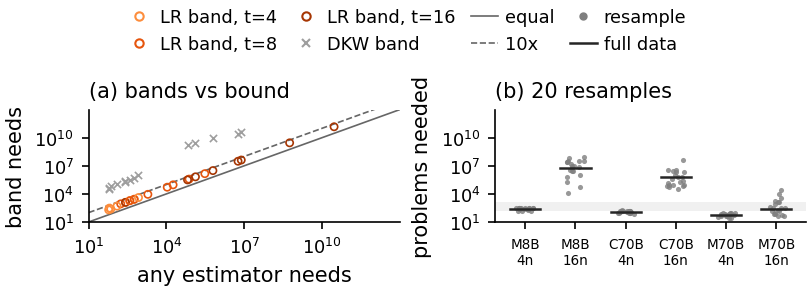

In [42]:
# 7.14d E10, revision 6 [analysis]: how stable is the bound when the benchmark's problems are resampled? -> T18, F26
# The bound is computed around one empirical distribution of per-problem rates (128 problems for Monkey Business). Here the
# problems are resampled with replacement and each resampled problem's attempts are redrawn from its own rate (the same number
# of attempts as in the data), and the bound is recomputed for every resample, for three count laws at t = 4 and 16.
E10BS, T18 = None, None


def _e10_attempts(name):
    """Attempts per problem behind a count law of E10 (used to redraw each resampled problem's successes)."""
    if name.endswith("(E8)") and globals().get("Y8") is not None:
        return int(Y8.shape[1])
    for cfg in (globals().get("E9") or {}):
        if mb_code(cfg) == name:
            try:
                return int(mb_labels(cfg)["Y"].shape[1])
            except Exception:
                return None
    return None


_bs_names = [d for d in CFG["E10_BOOT_DISTS"] if d in (E10_DISTS or {})]
if E10H is None or not _bs_names:
    print("E10 bootstrap skipped: E10 did not run or none of the chosen count laws is available.")
else:
    _bs_ts = [t for t in CFG["E10_BOOT_TS"]]
    _bs_set = json.dumps([CFG["E10H_G"], CFG["E10H_PER_DECADE"], CFG["E10H_M_RANGE"], E10H_THR, _E10H_SOLVER, CFG["E10_BOOT_B"]])

    def _e10bs_unit(name, ph, n, ts, B, seed, n_att):
        rng = np.random.default_rng(seed)
        ph = np.asarray(ph, float)
        t0 = time.time()
        out = {t: [] for t in ts}
        nlp = nfail = 0
        for b in range(int(B)):
            idx = rng.integers(0, ph.size, ph.size)
            pb = rng.binomial(int(n_att), ph[idx]) / float(n_att) if n_att else ph[idx]
            S = HelSetup(pb, n, CFG["E10H_G"])
            for t in ts:
                f = fail_k(S.X, int(t * n))
                cfg_b, rows_b = hel_march(S, f, _levels, early=True)
                out[t].append(hel_problems_needed(cfg_b, min(r["rho"] for r in rows_b)))
            nlp += S.stats["lp"]; nfail += S.stats["lp_fail"]
        print(f"[E10 bootstrap] {name}: {B} resamples, t = {ts}, done in {time.time() - t0:.0f}s ({nlp} LPs, {nfail} failed)")
        return {"ts": ts, "B": int(B), "values": out, "n_attempts": n_att, "lp": nlp, "lp_fail": nfail,
                "seconds": round(time.time() - t0, 1)}

    E10BS = {}
    for _i, _name in enumerate(_bs_names):
        _ph = E10_DISTS[_name]
        _natt = _e10_attempts(_name)
        _key = "e10bs_" + hashlib.sha1(json.dumps([_name, data_tag(np.asarray(_ph, float)), _n0h, _bs_ts, _bs_set, _natt]).encode()).hexdigest()[:12]
        E10BS[_name] = cached(_key, lambda nm=_name, ph=_ph, na=_natt, i=_i: _e10bs_unit(nm, ph, _n0h, _bs_ts, CFG["E10_BOOT_B"], SEED + 701 + i, na))

    _rows18, _bs_summary = [], {}
    for name in _bs_names:
        for t in _bs_ts:
            vals = [tuple(x) for x in E10BS[name]["values"][t]]
            keyv = np.array([_m_rank(x) for x in vals])
            order = np.argsort(keyv)
            Bn = len(vals)
            med = vals[order[(Bn - 1) // 2]]
            q10, q90 = vals[order[int(np.floor(0.1 * (Bn - 1)))]], vals[order[int(np.ceil(0.9 * (Bn - 1)))]]
            above = int(sum((fl == ">") or (fl == "" and v > _mreal) for v, fl in vals))
            full = _raw15[(name, t)] if (name, t) in _raw15 else (float("nan"), "?")
            _rows18.append({"Distribution": name, "t": f"{t:g}", "full data": _fmt_m(*full), "median": _fmt_m(*med),
                            "10%-90%": f"{_fmt_m(*q10)} to {_fmt_m(*q90)}", f"> {_mreal:,}": f"{above}/{Bn}"})
            fin = [v for v, fl in vals if fl == ""]
            _bs_summary[f"{name}|{t}"] = {"full": list(full), "median": list(med), "q10": list(q10), "q90": list(q90),
                                          "above_real": above, "B": Bn,
                                          "fold_10_90": (float(q90[0] / q10[0]) if (q10[1] == "" and q90[1] == "") else float("nan")),
                                          "values": [list(x) for x in vals], "finite_min": min(fin) if fin else float("nan"),
                                          "finite_max": max(fin) if fin else float("nan")}
    T18 = pd.DataFrame(_rows18)
    print(T18.to_string(index=False))
    save_table(T18, "T18_bound_under_resampling",
               f"E10, stability of the bound (n = {_n0h}, accuracy +-{CFG['E10H_ACC']:g}): problems needed (any estimator) for "
               f"{CFG['E10_BOOT_B']} resamples of the benchmark, each drawing the problems with replacement and redrawing each problem's "
               f"attempts from its own rate. 'full data': T15; median and 10%-90% range over the resamples; last column: resamples in "
               f"which more than {_mreal:,} problems are needed.", width_in=5.0)
    E10_SUMMARY["bootstrap"] = _bs_summary
    _parts = []
    for name in _bs_names:
        for t in _bs_ts:
            s_ = _bs_summary[f"{name}|{t}"]
            _parts.append(f"{name} k={t:g}n: {_fmt_m(*s_['q10'])} to {_fmt_m(*s_['q90'])} (full data {_fmt_m(*s_['full'])}; "
                          f"more than {_mreal:,} in {s_['above_real']}/{s_['B']})")
    VERDICTS["E10 bound under resampling of problems (descriptive)"] = "; ".join(_parts)
    print("E10 bootstrap (10%-90% over resamples): " + "; ".join(_parts))

# ---- F26: (a) what a band needs against what any estimator needs; (b) the bound under resampling
if E10LR is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
    f26 = {"lr": {}, "dkw": {}, "bootstrap": {}}
    _tc = {t: c for t, c in zip(sorted(set(list(CFG["E10_LR_TS"]))), ORANGES[1:] + ORANGES[:1])}
    _lo, _hi = 10.0, float(CFG["E10H_M_RANGE"][1]) * 10
    for name in _dists:
        for t in CFG["E10_LR_TS"]:
            vb, fb = _raw15.get((name, t), (float("nan"), "?"))
            vl, fll = _lr_m(name, t, _lrq["3/4"])
            if fb == "" and fll == "":
                ax1.scatter([vb], [vl], s=12, facecolors="none", edgecolors=_tc[t], linewidths=0.8, zorder=3)
                f26["lr"][f"{name}|{t}"] = [vb, vl]
        for t in (4, 16):
            vb, fb = _raw15.get((name, t), (float("nan"), "?"))
            md = _dkw_m(name, t)
            if fb == "" and np.isfinite(md):
                ax1.scatter([vb], [md], s=12, marker="x", color="#9e9e9e", linewidths=0.8, zorder=2)
                f26["dkw"][f"{name}|{t}"] = [vb, md]
    _g = np.geomspace(_lo, _hi, 50)
    ax1.plot(_g, _g, color=BOUND_COLOR, lw=0.8)
    ax1.plot(_g, 10 * _g, color=BOUND_COLOR, lw=0.8, ls="--")
    ax1.set_xscale("log"); ax1.set_yscale("log")
    ax1.set_xlim(_lo, _hi); ax1.set_ylim(_lo, _hi)
    ax1.xaxis.set_major_locator(matplotlib.ticker.FixedLocator([1e1, 1e4, 1e7, 1e10]))
    ax1.yaxis.set_major_locator(matplotlib.ticker.FixedLocator([1e1, 1e4, 1e7, 1e10]))
    ax1.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter()); ax1.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax1.set_xlabel("any estimator needs"); ax1.set_ylabel("band needs")
    panel_label(ax1, "(a) bands vs bound")
    if E10BS is not None:
        _codes = {"MATH L3-8B-I": "M8B", "CC L3-70B-I": "C70B", "MATH L3-70B-I": "M70B", "CC L3-8B-I": "C8B",
                  "MATH G-7B": "MG7", "CC G-7B": "CG7", "MATH P-12B": "MP12", "Q-0.5B MATH (E8)": "QE8"}
        _xt, _xl, xpos = [], [], 0
        _bs_rng = np.random.default_rng(SEED + 799)
        for name in _bs_names:
            for t in _bs_ts:
                vals = E10BS[name]["values"][t]
                ys = [(_hi if fl == ">" else (_lo if fl == "<" else v)) for v, fl in vals]
                xs = xpos + _bs_rng.uniform(-0.18, 0.18, len(ys))
                ax2.scatter(xs, ys, s=6, color="#7f7f7f", alpha=0.8, linewidths=0, zorder=2)
                full = _raw15.get((name, t), (float("nan"), "?"))
                if full[1] == "":
                    ax2.plot([xpos - 0.3, xpos + 0.3], [full[0], full[0]], color="#252525", lw=1.2, zorder=3)
                f26["bootstrap"][f"{name}|{t}"] = {"values": [list(x) for x in vals], "full": list(full)}
                _xt.append(xpos)
                _xl.append(f"{_codes.get(name, name[:6])}\n{t:g}n")
                xpos += 1
        ax2.axhspan(min(CFG["E7_MS"]), _mreal, color="#f0f0f0", lw=0)
        ax2.set_yscale("log")
        ax2.set_ylim(_lo, _hi)
        ax2.yaxis.set_major_locator(matplotlib.ticker.FixedLocator([1e1, 1e4, 1e7, 1e10]))
        ax2.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        ax2.set_xticks(_xt)
        ax2.set_xticklabels(_xl, fontsize=6.5)
        ax2.set_xlim(-0.6, xpos - 0.4)
        ax2.set_ylabel("problems needed")
        panel_label(ax2, f"(b) {CFG['E10_BOOT_B']} resamples")
    _h = [Line2D([], [], color=_tc[t], marker="o", ls="none", mfc="none", ms=4, label=f"LR band, t={t:g}") for t in CFG["E10_LR_TS"]]
    _h += [Line2D([], [], color="#9e9e9e", marker="x", ls="none", ms=4, label="DKW band"),
           Line2D([], [], color=BOUND_COLOR, lw=0.8, label="equal"),
           Line2D([], [], color=BOUND_COLOR, lw=0.8, ls="--", label="10x"),
           Line2D([], [], color="#7f7f7f", marker="o", ls="none", ms=3, label="resample"),
           Line2D([], [], color="#252525", lw=1.2, label="full data")]
    shared_legend(fig, _h, [h.get_label() for h in _h], ncol=4)
    finish_figure(fig, "F26_bound_tightness_and_stability", f26,
                  "How tight the any-estimator bound is (likelihood-ratio and DKW bands) and how it moves under resampling the problems.")

Figure F26 (E10, how tight and how stable the bound is; $n=32$, accuracy $\pm0.05$).
- (a) For every count law and $k=tn$, the problems at which a band narrows to width 0.1 (vertical axis) against the problems below which no estimator reaches $\pm0.05$ (horizontal axis, T15). Open circles: the profile likelihood-ratio interval at level $3/4$, the probability level of the lower bound, for $t=4$, 8 and 16 (best case: count histogram equal to the count law; asymptotic $\chi^2_1$ calibration; support grid). Crosses: the DKW band of E10a at $t=4$ and 16. Solid line: equality; dashed: ten times the bound. Censored values are left out.
- (b) The bound recomputed on 20 resamples of the benchmark (problems drawn with replacement, each problem's attempts redrawn from its own rate) for Llama-3-8B-Instruct on MATH (M8B), Llama-3-70B-Instruct on CodeContests (C70B) and Llama-3-70B-Instruct on MATH (M70B), at $k=4n$ and $16n$. Grey dots: resamples; black bars: the full data (T15). The shaded range marks benchmark sizes in use (164 to 1,319 problems).

At level 95% the likelihood-ratio numbers grow by the factor $\chi^2_1(0.95)/\chi^2_1(0.75)$ printed with T17. T17 and T18 give the numbers. F28 and T21 repeat the likelihood-ratio interval of (a) on drawn benchmarks, and F27 and T20 put the floor at $m=1{,}319$ next to (b).

[E10 floor] Q-0.5B MATH (E8), n=32: t = [2, 4, 8, 16, 32, 64] done in 18s (239 LPs, 0 failed)
[stage] e10f_9ebd1089c0dd: done in 17.8s
[E10 floor] GSM8K L3-8B-I, n=32: t = [2, 4, 8, 16, 32, 64] done in 15s (231 LPs, 0 failed)
[stage] e10f_c6b49ab86160: done in 15.2s
[E10 floor] GSM8K L3-70B-I, n=32: t = [2, 4, 8, 16, 32, 64] done in 14s (237 LPs, 0 failed)
[stage] e10f_cc8fc760434d: done in 14.0s
[E10 floor] MATH L3-8B-I, n=32: t = [2, 4, 8, 16, 32, 64] done in 18s (244 LPs, 0 failed)
[stage] e10f_8013b0f0a743: done in 18.4s
[E10 floor] MATH L3-70B-I, n=32: t = [2, 4, 8, 16, 32, 64] done in 19s (251 LPs, 0 failed)
[stage] e10f_2c784fd02dbc: done in 18.5s
[E10 floor] CC L3-8B-I, n=32: t = [2, 4, 8, 16, 32, 64] done in 14s (271 LPs, 0 failed)
[stage] e10f_0a7b4cdeaf61: done in 14.4s
[E10 floor] CC L3-70B-I, n=32: t = [2, 4, 8, 16, 32, 64] done in 21s (237 LPs, 0 failed)
[stage] e10f_b4b60625a9fa: done in 20.6s
[E10 floor] MATH G-7B, n=32: t = [2, 4, 8, 16, 32, 64] done in 17s (252 LPs, 0

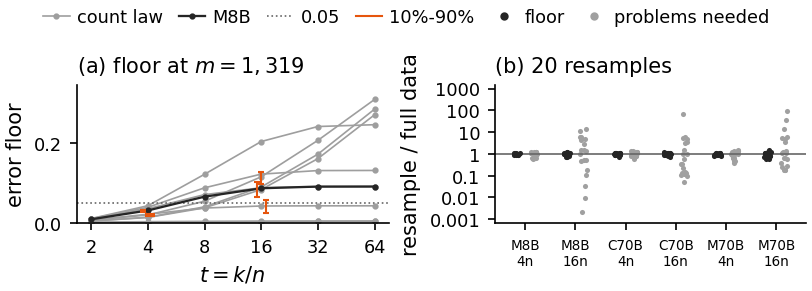

In [43]:
# 7.14e E10, revision 7 [analysis]: the error floor at the benchmark sizes in use, and how stable it is under resampling -> T19, T20, F27
# T15 reads the certified separation where it falls to 0.1. At k = 16n that separation is nearly flat in m over several
# decades, so the crossing moves by orders of magnitude with the accuracy target (T15d) and with the draw of problems (T18).
# The same certified pairs can be read at a fixed benchmark size instead: with m problems, every estimator of the population
# pass@k errs by at least half the certified separation at h(m), with probability at least 1/4 under one of the two
# distributions (whose count laws lie within h(m) of the real one and of each other). This cell computes that floor at
# m = 500 and 1,319 (the sizes of MATH-500 and of the GSM8K test set) for every count law and t. The marches run through
# every level near h(m) without the early stop of 7.14b, which could end before h(m) when the separation fell below 0.09 at
# smaller m. The floor is then recomputed on the same 20 resamples of the problems as T18.
E10F, E10FB, T19, T20, E10_FLOOR = None, None, None, None, None
if E10H is None or not E10_DISTS:
    print("E10 floor skipped: E10 did not run.")
else:
    _fms = sorted(set(int(m) for m in CFG["E10_FLOOR_MS"]))
    _mhead = int(CFG["REALISTIC_M_MAX"]) if int(CFG["REALISTIC_M_MAX"]) in _fms else _fms[-1]
    _flevels = [float(r) for r in _levels if hel_level(max(_fms)) / 8.0 <= r <= 8.0 * hel_level(min(_fms))]
    _fl_set = json.dumps([CFG["E10H_G"], CFG["E10H_PER_DECADE"], CFG["E10H_M_RANGE"], _fms, _E10H_SOLVER, "floor march v1"])
    _fts = list(CFG["E10H_TS"])

    def _fmt_fold(v):
        """A ratio of two quantiles (spread), 1.19 or 62 or 1,200."""
        if not np.isfinite(v):
            return "--"
        return f"{v:.2f}" if v < 10 else (f"{v:.0f}" if v < 100 else _fmt_m(v))

    def _floors_of(cfg):
        return {m: 0.5 * float(hel_hull(cfg, hel_level(m))[0]) for m in _fms}

    def _e10f_unit(name, ph, n, ts):
        S = HelSetup(ph, n, CFG["E10H_G"])
        t0 = time.time()
        res = {"n": n, "ts": ts, "ms": _fms, "levels": _flevels, "floor": {}, "cfg": {}, "rows": {}}
        for t in ts:
            f = fail_k(S.X, int(t * n))
            cfg_t, rows_t = hel_march(S, f, _flevels, early=False)
            res["cfg"][t], res["rows"][t], res["floor"][t] = cfg_t, rows_t, _floors_of(cfg_t)
        res["stats"] = dict(S.stats, seconds=round(time.time() - t0, 1))
        print(f"[E10 floor] {name}, n={n}: t = {ts} done in {time.time() - t0:.0f}s ({S.stats['lp']} LPs, {S.stats['lp_fail']} failed)")
        return res

    E10F = {}
    for _name, _ph in E10_DISTS.items():
        _key = "e10f_" + hashlib.sha1(json.dumps([_name, data_tag(np.asarray(_ph, float)), _n0h, _fts, _fl_set]).encode()).hexdigest()[:12]
        E10F[_name] = cached(_key, lambda nm=_name, ph=_ph: _e10f_unit(nm, ph, _n0h, _fts))

    def _fl(name, t, m=None):
        return float(E10F[name]["floor"][t][_mhead if m is None else m])

    _t16 = 16 if 16 in _fts else _fts[-1]
    _rows19 = []
    for name in _dists:
        rec = {"Distribution": name, f"pass@{_t16:g}n": f"{1.0 - E10H[(name, _n0h)]['F0'][int(_t16 * _n0h)]:.3f}"}
        for t in _fts:
            rec[f"t={t:g}"] = f"{_fl(name, t):.3f}"
        for m in _fms:
            if m != _mhead:
                rec[f"t={_t16:g}, m={m:,}"] = f"{_fl(name, _t16, m):.3f}"
        _rows19.append(rec)
    T19 = pd.DataFrame(_rows19)
    print(T19.to_string(index=False))
    save_table(T19, "T19_error_floor_realistic_m",
               f"E10, the error floor at a realistic benchmark size (n = {_n0h} attempts per problem). Columns t = ...: with m = {_mhead:,} "
               f"problems (the GSM8K test set), every estimator of the population pass@k, k = t n, errs by at least this much with "
               f"probability at least 1/4 under one of two success-rate distributions whose count laws lie within squared Hellinger "
               f"distance h(m) of the real one and of each other (Le Cam's two-point method; half the certified separation at h(m); "
               f"alternatives on a support grid, which can only lower the floor). A floor above {CFG['E10H_ACC']:g} means that accuracy "
               f"+-{CFG['E10H_ACC']:g} is out of reach at this m. Last column: the same at m = "
               + ", ".join(f"{m:,}" for m in _fms if m != _mhead) + f" (MATH-500), t = {_t16:g}. pass@{_t16:g}n: the value at the real "
               "distribution.", width_in=5.45)
    _nlp_f = sum(u["stats"]["lp"] for u in E10F.values())
    _nfail_f = sum(u["stats"]["lp_fail"] for u in E10F.values())
    _gaps_f = []
    for u in E10F.values():
        for rows in u["rows"].values():
            for r in rows:
                for sfx in ("+", "-"):
                    if np.isfinite(r["up" + sfx]) and r["up" + sfx] > 1e-6:
                        _gaps_f.append(max(0.0, (r["up" + sfx] - r["om" + sfx]) / r["up" + sfx]))
    _gaps_f = np.asarray(_gaps_f) if _gaps_f else np.zeros(1)
    # the early-stopped marches of 7.14b give a floor too (a chord to the origin where they stopped before h(m)); report the change
    _old = {(name, t): _floor(name, _n0h, int(t * _n0h), _mhead) for name in _dists for t in _fts}
    _raised = [(name, t, _old[(name, t)], _fl(name, t)) for name in _dists for t in _fts if _fl(name, t) > _old[(name, t)] + 0.002]
    print(f"E10 floor solver check: certified separation within {100 * np.quantile(_gaps_f, 0.99):.1f}% of the LP relaxation in 99% of "
          f"{len(_gaps_f)} solves (largest gap {100 * _gaps_f.max():.1f}%); {_nfail_f} of {_nlp_f} LPs failed. {len(_fts)} values of t, "
          f"{len(_flevels)} levels from h = {max(_flevels):.2e} to {min(_flevels):.2e}.")
    print(f"E10 floor: {len(_raised)} of {len(_dists) * len(_fts)} floors are higher than the chord of the early-stopped marches of 7.14b"
          + (": " + "; ".join(f"{nm} t={t:g} {a:.3f} -> {b:.3f}" for nm, t, a, b in _raised[:6]) + ("; ..." if len(_raised) > 6 else "")
             if _raised else "."))

    _f16 = {name: _fl(name, _t16) for name in _dists}
    _above16 = [name for name in _dists if _f16[name] > CFG["E10H_ACC"]]
    E10_FLOOR = {"m_head": _mhead, "ms": _fms, "ts": _fts, "t16": _t16, "levels": _flevels,
                 "floor": {name: {f"{t:g}": {str(m): _fl(name, t, m) for m in _fms} for t in _fts} for name in _dists},
                 "above_acc_16": _above16, "n_dists": len(_dists),
                 "range_above_16": [min(_f16[nm] for nm in _above16), max(_f16[nm] for nm in _above16)] if _above16 else None,
                 "range_all": {f"{t:g}": [min(_fl(nm, t) for nm in _dists), max(_fl(nm, t) for nm in _dists)] for t in _fts},
                 "above_acc": {f"{t:g}": int(sum(_fl(nm, t) > CFG["E10H_ACC"] for nm in _dists)) for t in _fts},
                 "solver_gap_q99": float(np.quantile(_gaps_f, 0.99)), "lp_fail": int(_nfail_f), "lp_total": int(_nlp_f),
                 "raised": [[nm, float(t), float(a), float(b)] for nm, t, a, b in _raised]}
    for m in _fms:
        if m != _mhead:
            _fm = [_fl(nm, _t16, m) for nm in _above16]
            E10_FLOOR[f"range_above_16_m{m}"] = [min(_fm), max(_fm)] if _fm else None
    E10_SUMMARY["floor"] = E10_FLOOR
    _ft = ", ".join(f"k={t:g}n {E10_FLOOR['range_all'][f'{t:g}'][0]:.3f}-{E10_FLOOR['range_all'][f'{t:g}'][1]:.3f} "
                    f"(above {CFG['E10H_ACC']:g} for {E10_FLOOR['above_acc'][f'{t:g}']}/{len(_dists)})" for t in _fts)
    VERDICTS["E10 error floor at realistic m, any estimator (descriptive)"] = (
        f"m = {_mhead:,}: " + _ft + (f"; at k={_t16:g}n the floor exceeds {CFG['E10H_ACC']:g} for {len(_above16)}/{len(_dists)} count laws "
                                      f"({E10_FLOOR['range_above_16'][0]:.3f} to {E10_FLOOR['range_above_16'][1]:.3f})" if _above16 else ""))
    print("E10 error floor (probability >= 1/4, any estimator): " + VERDICTS["E10 error floor at realistic m, any estimator (descriptive)"])

    # ---- the floor on the resamples of T18
    _fb_names = [d for d in CFG["E10_BOOT_DISTS"] if d in E10_DISTS]
    _fb_ts = [t for t in CFG["E10_BOOT_TS"] if t in _fts]

    def _e10_resamples(ph, B, seed, n_att):
        """The resamples of 7.14d: the same generator, seed and order of draws, so resample b here is resample b of T18."""
        rng = np.random.default_rng(seed)
        ph = np.asarray(ph, float)
        for _b in range(int(B)):
            idx = rng.integers(0, ph.size, ph.size)
            yield rng.binomial(int(n_att), ph[idx]) / float(n_att) if n_att else ph[idx]

    if _fb_names and _fb_ts:
        _fb_set = json.dumps([_fl_set, CFG["E10_BOOT_B"], "resamples of 7.14d"])

        def _e10fb_unit(name, ph, n, ts, B, seed, n_att):
            t0 = time.time()
            out = {t: [] for t in ts}
            nlp = nfail = 0
            for pb in _e10_resamples(ph, B, seed, n_att):
                S = HelSetup(pb, n, CFG["E10H_G"])
                for t in ts:
                    f = fail_k(S.X, int(t * n))
                    cfg_b, _rows_b = hel_march(S, f, _flevels, early=False)
                    out[t].append(_floors_of(cfg_b))
                nlp += S.stats["lp"]; nfail += S.stats["lp_fail"]
            print(f"[E10 floor bootstrap] {name}: {B} resamples, t = {ts}, done in {time.time() - t0:.0f}s ({nlp} LPs, {nfail} failed)")
            return {"ts": ts, "B": int(B), "ms": _fms, "values": out, "n_attempts": n_att, "lp": nlp, "lp_fail": nfail,
                    "seconds": round(time.time() - t0, 1)}

        E10FB = {}
        for _i, _name in enumerate(_fb_names):
            _ph = E10_DISTS[_name]
            _natt = _e10_attempts(_name)
            _key = "e10fb_" + hashlib.sha1(json.dumps([_name, data_tag(np.asarray(_ph, float)), _n0h, _fb_ts, _fb_set, _natt]).encode()).hexdigest()[:12]
            E10FB[_name] = cached(_key, lambda nm=_name, ph=_ph, na=_natt, i=_i: _e10fb_unit(nm, ph, _n0h, _fb_ts, CFG["E10_BOOT_B"], SEED + 701 + i, na))

        # replay check: the first resample, recomputed with the early-stopped march of 7.14d, gives the problems needed stored in T18
        _chk = None
        if E10BS is not None and _fb_names[0] in E10BS and _fb_ts[0] in E10BS[_fb_names[0]]["ts"]:
            _nm0, _t0c = _fb_names[0], _fb_ts[0]
            _pb0 = next(_e10_resamples(E10_DISTS[_nm0], 1, SEED + 701, _e10_attempts(_nm0)))
            _S0 = HelSetup(_pb0, _n0h, CFG["E10H_G"])
            _cfg0, _rows0 = hel_march(_S0, fail_k(_S0.X, int(_t0c * _n0h)), _levels, early=True)
            _v0 = hel_problems_needed(_cfg0, min(r["rho"] for r in _rows0))
            _ref = tuple(E10BS[_nm0]["values"][_t0c][0])
            _same = (_v0[1] == _ref[1]) and (_v0[1] != "" or abs(_v0[0] / _ref[0] - 1.0) < 0.01)
            _chk = {"dist": _nm0, "t": _t0c, "replayed": list(_v0), "stored": list(_ref), "same": bool(_same)}
            print(f"E10 floor bootstrap: resample 1 of {_nm0}, recomputed as in 7.14d, needs {_fmt_m(*_v0)} problems at k = {_t0c:g}n "
                  f"(T18 stored {_fmt_m(*_ref)}): " + ("the resamples are those of T18." if _same else "MISMATCH, the resamples differ from T18."))

        def _q(vals, p):
            vals = np.sort(np.asarray(vals, float))
            return float(vals[int(np.floor(p * (len(vals) - 1)))] if p < 0.5 else vals[int(np.ceil(p * (len(vals) - 1)))])

        _rows20, _fb_summary = [], {}
        for name in _fb_names:
            for t in _fb_ts:
                fv = [float(v[_mhead]) for v in E10FB[name]["values"][t]]
                f_full = _fl(name, t)
                f10, f50, f90 = _q(fv, 0.1), float(np.median(fv)), _q(fv, 0.9)
                rec = {"Distribution": name, "t": f"{t:g}", "floor": f"{f_full:.3f}", "floor 10%-90%": f"{f10:.3f}-{f90:.3f}",
                       "floor spread": (_fmt_fold(f90 / f10) if f10 > 0 else "--")}
                mstat = None
                if E10BS is not None and name in E10BS and t in E10BS[name]["ts"]:
                    vals = [tuple(x) for x in E10BS[name]["values"][t]]
                    order = np.argsort([_m_rank(x) for x in vals])
                    q10m, q90m = vals[order[int(np.floor(0.1 * (len(vals) - 1)))]], vals[order[int(np.ceil(0.9 * (len(vals) - 1)))]]
                    full_m = _raw15.get((name, t), (float("nan"), "?"))
                    fold = (q90m[0] / q10m[0]) if (q10m[1] == "" and q90m[1] == "") else float("nan")
                    rec.update({"needed": _fmt_m(*full_m), "needed 10%-90%": f"{_fmt_m(*q10m)} to {_fmt_m(*q90m)}",
                                "needed spread": (_fmt_fold(fold) if np.isfinite(fold) else (f">{_fmt_fold(q90m[0] / q10m[0])}" if q90m[1] == ">" else "--"))})
                    mstat = {"full": list(full_m), "q10": list(q10m), "q90": list(q90m), "fold": float(fold),
                             "ratios": [(v / full_m[0]) if (fl == "" and full_m[1] == "") else float("nan") for v, fl in vals],
                             "flags": [fl for v, fl in vals]}
                _rows20.append(rec)
                _fb_summary[f"{name}|{t}"] = {"floor_full": f_full, "q10": f10, "median": f50, "q90": f90,
                                              "fold": (f90 / f10) if f10 > 0 else float("nan"), "values": fv,
                                              "rel_dev_max": float(max(abs(v / f_full - 1.0) for v in fv)) if f_full > 0 else float("nan"),
                                              "m_star": mstat, "B": len(fv)}
        T20 = pd.DataFrame(_rows20)
        print(T20.to_string(index=False))
        save_table(T20, "T20_floor_vs_problems_needed_stability",
                   f"E10, how stable the two readings of the bound are (n = {_n0h}). 'floor': the error floor at m = {_mhead:,} (T19) on the full "
                   f"data, and its 10%-90% range over the {CFG['E10_BOOT_B']} resamples of T18 (problems drawn with replacement, each "
                   f"problem's attempts redrawn from its own rate; the same resamples, replayed from the same seeds). 'needed': "
                   f"the problems needed for +-{CFG['E10H_ACC']:g} (T15) and its 10%-90% range over the same resamples (T18). 'spread': 90th "
                   f"percentile over 10th.", width_in=5.45)
        _ff = [v["fold"] for v in _fb_summary.values() if np.isfinite(v["fold"])]
        _mf = [v["m_star"]["fold"] for v in _fb_summary.values() if v["m_star"] and np.isfinite(v["m_star"]["fold"])]
        E10_FLOOR["bootstrap"] = _fb_summary
        E10_FLOOR["bootstrap_check"] = _chk
        E10_FLOOR["fold_max"] = float(max(_ff)) if _ff else float("nan")
        E10_FLOOR["m_star_fold_max"] = float(max(_mf)) if _mf else float("nan")
        _k16f = [(key.split("|")[0], v) for key, v in _fb_summary.items() if key.endswith(f"|{_t16}")]
        E10_FLOOR["boot16_above_acc"] = {nm: int(sum(x > CFG["E10H_ACC"] for x in v["values"])) for nm, v in _k16f}
        VERDICTS["E10 error floor under resampling of problems (descriptive)"] = "; ".join(
            f"{name} k={t:g}n: floor {_fb_summary[f'{name}|{t}']['q10']:.3f}-{_fb_summary[f'{name}|{t}']['q90']:.3f} "
            f"(full data {_fb_summary[f'{name}|{t}']['floor_full']:.3f}; spread {_fmt_fold(_fb_summary[f'{name}|{t}']['fold'])}"
            + (f"; problems needed spread {_fmt_fold(_fb_summary[f'{name}|{t}']['m_star']['fold'])}"
               if (_fb_summary[f'{name}|{t}']['m_star'] and np.isfinite(_fb_summary[f'{name}|{t}']['m_star']['fold'])) else "") + ")"
            for name in _fb_names for t in _fb_ts)
        print("E10 floor under resampling (10%-90%): " + VERDICTS["E10 error floor under resampling of problems (descriptive)"])
    else:
        print("E10 floor bootstrap skipped: none of the chosen count laws or values of t is available.")

    # ---- F27: (a) the floor at m = 1,319 against t, every count law, with the resampling range; (b) floor vs problems needed under resampling
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
    f27 = {"m": _mhead, "ts": _fts, "floor": {}, "bootstrap": {}}
    _tt = np.array(_fts, float)
    _codes = {"MATH L3-8B-I": "M8B", "CC L3-70B-I": "C70B", "MATH L3-70B-I": "M70B", "CC L3-8B-I": "C8B", "MATH G-7B": "MG7",
              "CC G-7B": "CG7", "MATH P-12B": "MP12", "Q-0.5B MATH (E8)": "QE8", "GSM8K L3-8B-I": "G8B", "GSM8K L3-70B-I": "G70B"}
    for name in _dists:
        ys = [_fl(name, t) for t in _fts]
        strong = name == _rep
        ax1.plot(_tt, ys, color="#252525" if strong else "#9e9e9e", lw=1.1 if strong else 0.8, marker="o", ms=2.0,
                 zorder=3 if strong else 2)
        f27["floor"][name] = ys
    if E10FB is not None:
        _off = {nm: o for nm, o in zip(_fb_names, np.linspace(-0.08, 0.08, max(len(_fb_names), 1)))}
        for name in _fb_names:
            for t in _fb_ts:
                s_ = E10_FLOOR["bootstrap"][f"{name}|{t}"]
                xx = t * 2.0 ** _off[name]
                ax1.errorbar([xx], [s_["median"]], yerr=[[s_["median"] - s_["q10"]], [s_["q90"] - s_["median"]]], fmt="none",
                             ecolor=ORANGES[2], elinewidth=1.0, capsize=1.6, zorder=4)
    ax1.axhline(CFG["E10H_ACC"], color=BOUND_COLOR, lw=0.8, ls=":")
    ax1.set_xscale("log", base=2)
    ax1.xaxis.set_major_locator(matplotlib.ticker.FixedLocator(list(_tt)))
    ax1.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _p: f"{v:g}"))
    ax1.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    _ymax = max(max(f27["floor"][nm]) for nm in _dists)
    ax1.set_ylim(0.0, max(0.1, 1.12 * _ymax))
    ax1.set_xlabel("$t=k/n$"); ax1.set_ylabel("error floor")
    panel_label(ax1, f"(a) floor at $m={_mhead:,}$")
    if E10FB is not None:
        _cap = 1e3
        _xt, _xl, xpos = [], [], 0
        _jit = np.random.default_rng(SEED + 899)
        for name in _fb_names:
            for t in _fb_ts:
                s_ = E10_FLOOR["bootstrap"][f"{name}|{t}"]
                fr = np.array(s_["values"]) / s_["floor_full"] if s_["floor_full"] > 0 else np.full(len(s_["values"]), np.nan)
                ax2.scatter(xpos - 0.17 + _jit.uniform(-0.07, 0.07, fr.size), np.clip(fr, 1.0 / _cap, _cap), s=6, color="#252525",
                            linewidths=0, zorder=3)
                rec_ = {"floor_ratio": fr}
                if s_["m_star"]:
                    mr = np.array(s_["m_star"]["ratios"], float)
                    fl_ = s_["m_star"]["flags"]
                    mr = np.where(np.array([f_ == ">" for f_ in fl_]), _cap, np.where(np.array([f_ == "<" for f_ in fl_]), 1.0 / _cap, mr))
                    ax2.scatter(xpos + 0.17 + _jit.uniform(-0.07, 0.07, mr.size), np.clip(mr, 1.0 / _cap, _cap), s=6, color="#a0a0a0",
                                linewidths=0, zorder=2)
                    rec_["m_star_ratio"] = mr
                f27["bootstrap"][f"{name}|{t}"] = rec_
                _xt.append(xpos)
                _xl.append(f"{_codes.get(name, name[:5])}\n{t:g}n")
                xpos += 1
        ax2.axhline(1.0, color=BOUND_COLOR, lw=0.8)
        ax2.set_yscale("log")
        ax2.set_ylim(1.0 / _cap / 1.5, _cap * 1.5)
        ax2.yaxis.set_major_locator(matplotlib.ticker.FixedLocator([1e-3, 1e-2, 1e-1, 1, 10, 1e2, 1e3]))
        ax2.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _p: f"{v:g}"))
        ax2.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        ax2.set_xticks(_xt)
        ax2.set_xticklabels(_xl, fontsize=6.5)
        ax2.set_xlim(-0.6, xpos - 0.4)
        ax2.set_ylabel("resample / full data")
        panel_label(ax2, f"(b) {CFG['E10_BOOT_B']} resamples")
    _h = [Line2D([], [], color="#9e9e9e", lw=0.8, marker="o", ms=2.0, label="count law"),
          Line2D([], [], color="#252525", lw=1.1, marker="o", ms=2.0, label=_codes.get(_rep, _rep)),
          Line2D([], [], color=BOUND_COLOR, lw=0.8, ls=":", label=f"{CFG['E10H_ACC']:g}"),
          Line2D([], [], color=ORANGES[2], lw=1.0, label="10%-90%"),
          Line2D([], [], color="#252525", marker="o", ls="none", ms=3, label="floor"),
          Line2D([], [], color="#a0a0a0", marker="o", ls="none", ms=3, label="problems needed")]
    shared_legend(fig, _h, [h.get_label() for h in _h], ncol=6)
    finish_figure(fig, "F27_error_floor_and_stability", f27,
                  "Error floor of every estimator at a realistic benchmark size, and its stability next to that of the problems needed.")

Figure F27 (E10 read at a fixed benchmark size: the error floor of every estimator; $n=32$).
- (a) The floor at $m=1{,}319$ problems, the size of the GSM8K test set, against $t=k/n$ for every count law (grey; Llama-3-8B-Instruct on MATH in black). With that many problems, every estimator of the population pass@$k$ errs by at least this much with probability at least $1/4$ under one of two success-rate distributions whose count laws lie within squared Hellinger distance $h(m)$ of the real one and of each other. It is half the certified separation of F24(a), read at $m=1{,}319$ instead of at separation 0.1. Dotted: 0.05; a floor above it means that accuracy $\pm0.05$ is out of reach at this $m$. Orange bars: the 10%–90% range of the floor over the 20 resamples of T18, for the three count laws of F26(b) at $t=4$ and 16.
- (b) The same 20 resamples, each value divided by its full-data value: the floor at $m=1{,}319$ (black) and the problems needed for $\pm0.05$ (grey; T18). Codes as in F26(b); values beyond the axis are drawn at its edge.

The floor and the problems needed come from the same certified pairs. Where the separation is nearly flat in $m$, as at $t=16$ for most count laws, the point at which it crosses 0.1 moves by orders of magnitude between resamples, while its height at a fixed $m$ moves much less. T19 and T20 give the numbers; T15 and F24(b) keep the problems needed as an order-of-magnitude figure.

[E10 LR simulation] Q-0.5B MATH (E8): (t, m) = [(4, 2709), (8, 374526)], 100 draws each, done in 73s (1650 LPs, 0 failed)
[stage] e10ls_d71f70b84acb: done in 73.4s
[E10 LR simulation] MATH L3-8B-I: (t, m) = [(4, 1228), (8, 51310), (16, 30271541)], 100 draws each, done in 110s (2584 LPs, 0 failed)
[stage] e10ls_0a31c072b760: done in 109.7s
[E10 LR simulation] MATH L3-70B-I: (t, m) = [(4, 301), (8, 862), (16, 1243)], 100 draws each, done in 97s (2484 LPs, 0 failed)
[stage] e10ls_2d2075fc10ec: done in 97.1s
[E10 LR simulation] CC L3-8B-I: (t, m) = [(4, 242), (8, 2598), (16, 310064)], 100 draws each, done in 72s (2294 LPs, 0 failed)
[stage] e10ls_801c8c84247b: done in 72.4s
[E10 LR simulation] CC L3-70B-I: (t, m) = [(4, 492), (8, 8908), (16, 3045360)], 100 draws each, done in 92s (2440 LPs, 0 failed)
[stage] e10ls_e693ba6a4b60: done in 91.9s
[E10 LR simulation] MATH G-7B: (t, m) = [(4, 1885), (8, 92068), (16, 40854778)], 100 draws each, done in 113s (2603 LPs, 0 failed)
[stage] e10ls_1ce22

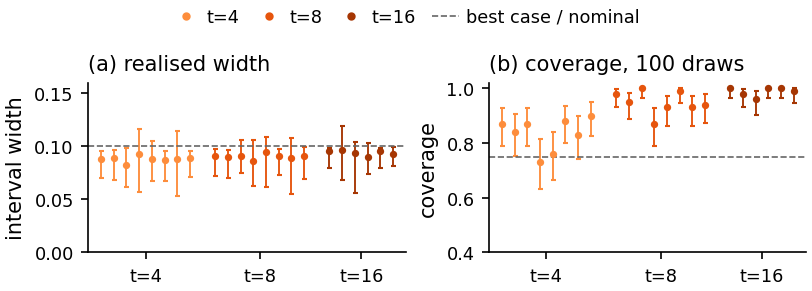

In [44]:
# 7.14f E10, revision 7 [analysis]: the likelihood-ratio interval on drawn histograms, at the m where its best case reaches width 0.1 -> T21, F28
# T17 compares the bound with the profile likelihood-ratio interval in its best case: the count histogram equal to the count
# law, and chi-square calibration taken on trust. Here the histograms are drawn. For every count law and t at which T17 gives
# both numbers, R benchmarks of m_LR problems are drawn from the real distribution (m_LR: where the best-case interval at
# level 3/4 narrows to width 0.1), and on each the interval {D': 2m [KL(pi_hat || pi_D') - min KL] <= chi2_1(0.75)} is
# computed on the support grid. The minimum is the grid NPMLE (constrained Newton method; its distance from the optimum is
# bounded by the Lindsay gap log max_i D_i). The endpoints come from the cutting-plane solver with KL cuts written around the
# NPMLE; the LP relaxation gives an outer interval and the certified points an inner one, and the exact interval lies between.
# Recorded per draw: the width, whether the interval holds the true pass@k, and whether its midpoint is within +-0.05 of it.
def npmle_grid(B, ph, tol=1e-12, itmax=200, em0=30):
    """Grid NPMLE (see _npmle_once); if the first attempt stops with a Lindsay gap above 1e-11, a second attempt starts
    from a longer EM run, and the attempt with the smaller gap is returned."""
    out = _npmle_once(B, ph, tol, itmax, em0)
    if out[2] > 1e-11:
        out2 = _npmle_once(B, ph, tol, itmax, 10 * em0)
        if out2[2] < out[2]:
            out = out2
    return out


def _npmle_once(B, ph, tol=1e-12, itmax=200, em0=30):
    """Grid NPMLE of the mixing distribution from a count histogram ph. EM from the uniform grid distribution for a few
    steps (so that no observed cell has negligible probability), then Wang's constrained Newton method: add the local maxima
    of the gradient function, Newton step by NNLS with the weights summing to one, backtracking line search; a failed line
    search falls back to EM on the whole grid. Returns full-grid weights w, the gradient D_i = sum_j ph_j B_ij / q_j at w,
    the Lindsay gap log(max_i D_i), which bounds KL(ph || q_w) - min_v KL(ph || q_v) over the grid, and the iterations."""
    G = B.shape[0]
    pos = ph > 0
    P = ph[pos]
    Bp = B[:, pos]

    def _em(wf, steps):
        for _ in range(steps):
            wf = wf * (Bp @ (P / (wf @ Bp)))
            wf = wf / wf.sum()
        return wf

    def _support(wf):
        loc = np.flatnonzero(np.r_[wf[0] >= wf[1], (wf[1:-1] >= wf[:-2]) & (wf[1:-1] >= wf[2:]), wf[-1] >= wf[-2]])
        return np.union1d(np.flatnonzero(wf > 1e-3 * wf.max()), loc[wf[loc] > 1e-8 * wf.max()])

    wf = _em(np.full(G, 1.0 / G), em0)
    sup = _support(wf)
    w = wf[sup] / wf[sup].sum()
    q = w @ Bp[sup]
    ll = float(P @ np.log(q))
    Dg = Bp @ (P / q)
    best, stall, rescues = None, 0, 0
    for it in range(itmax):
        mx = float(Dg.max())
        if best is None or mx < best[0]:
            best = (mx, sup.copy(), w.copy(), Dg.copy())
        if mx - 1.0 < tol or stall >= 4:
            break
        inner = np.flatnonzero((Dg[1:-1] >= Dg[:-2]) & (Dg[1:-1] >= Dg[2:])) + 1
        cand = list(inner)
        if Dg[0] >= Dg[1]:
            cand.append(0)
        if Dg[-1] >= Dg[-2]:
            cand.append(G - 1)
        cand = [i for i in cand if Dg[i] > 1.0]
        sup_n = np.union1d(sup, np.asarray(cand, int))
        w0n = np.zeros(sup_n.size)
        w0n[np.searchsorted(sup_n, sup)] = w
        Sm = (Bp[sup_n] / q).T * np.sqrt(P)[:, None]
        lam = 1e4 * max(1.0, float(np.abs(Sm).max()))                  # sum-to-one constraint as a heavily weighted row
        acc = False
        if lam < 1e12:
            wn, _ = optimize.nnls(np.vstack([Sm, lam * np.ones((1, sup_n.size))]), np.concatenate([2.0 * np.sqrt(P), [lam]]),
                                  maxiter=50 * sup_n.size)
            if wn.sum() > 0:
                wn = wn / wn.sum()
                a = 1.0
                for _ in range(40):
                    wa = (1.0 - a) * w0n + a * wn
                    qa = wa @ Bp[sup_n]
                    if np.all(qa > 0):
                        dll = float(P @ np.log1p((qa - q) / q))       # exact change in log-likelihood (no cancellation)
                        if dll >= 0.0:
                            acc = True
                            break
                    a *= 0.5
        if acc:
            keep = wa > 1e-300
            sup, w = sup_n[keep], wa[keep] / wa[keep].sum()
        else:
            if rescues >= 5:
                break
            rescues += 1
            wf = np.zeros(G)
            wf[sup] = w
            wf = _em(0.999 * wf + 0.001 / G, 50)
            sup = _support(wf)
            w = wf[sup] / wf[sup].sum()
        q_new = w @ Bp[sup]
        dll = float(P @ np.log1p((q_new - q) / q))
        stall = stall + 1 if (acc and dll <= 1e-18) else 0
        q = q_new
        ll = float(P @ np.log(q))
        Dg = Bp @ (P / q)
    mx = float(Dg.max())
    if best is None or mx < best[0]:
        best = (mx, sup.copy(), w.copy(), Dg.copy())
    # polish on the support found: Newton steps with the weights summing to one exactly (KKT system), dropping points
    # whose weight would reach zero; then the gradient over the whole grid again, adding the points where it is largest
    def _newton(sup, w):
        for _ in range(30):
            A = Bp[sup]
            q = w @ A
            if not np.all(q > 0):
                break
            ll0 = float(P @ np.log(q))
            g = A @ (P / q)
            H = -(A * (P / q ** 2)) @ A.T
            s_ = sup.size
            K = np.zeros((s_ + 1, s_ + 1))
            K[:s_, :s_], K[:s_, s_], K[s_, :s_] = H, 1.0, 1.0
            if not np.all(np.isfinite(K)):
                break
            try:
                step = np.linalg.lstsq(K, np.concatenate([-g, [0.0]]), rcond=None)[0][:s_]
            except np.linalg.LinAlgError:
                break
            neg = step < 0
            amax = float(np.min(-w[neg] / step[neg])) if neg.any() else np.inf
            a, acc = min(1.0, amax), False
            for _ in range(30):
                wa = np.maximum(w + a * step, 0.0)
                wa = wa / wa.sum()
                qa = wa @ A
                if np.all(qa > 0) and float(P @ np.log1p((qa - q) / q)) >= 0.0:
                    acc = True
                    break
                a *= 0.5
            if not acc:
                break
            moved = float(np.max(np.abs(wa - w)))
            w = wa
            if np.any(w <= 0):
                sup, w = sup[w > 0], w[w > 0] / w[w > 0].sum()
            if moved < 1e-16:
                break
        return sup, w

    mx, sup, w, Dg = best
    for _ in range(4):
        sup, w = sup[w > 0], w[w > 0] / w[w > 0].sum()
        sup, w = _newton(sup, w)
        q = w @ Bp[sup]
        if not np.all(q > 0):
            break
        Dg = Bp @ (P / q)
        mx_p = float(Dg.max())
        if mx_p < best[0]:
            best = (mx_p, sup.copy(), w.copy(), Dg.copy())
        if mx_p - 1.0 < tol:
            break
        add = np.setdiff1d(np.flatnonzero(Dg > 1.0 + 0.5 * (mx_p - 1.0)), sup)
        if add.size == 0:
            break
        add = add[np.argsort(-Dg[add])[:5]]
        new_sup = np.union1d(sup, add)
        w_new = np.full(new_sup.size, 1e-9)
        w_new[np.searchsorted(new_sup, sup)] = w * (1.0 - 1e-9 * add.size)
        sup, w = new_sup, w_new / w_new.sum()
    mx, sup, w, Dg = best
    wfull = np.zeros(G)
    wfull[sup] = w
    return wfull, Dg, math.log(max(mx, 1.0)), it


def _rg(y):
    """y - log(1 + y), with a series near 0; inf for y <= -1."""
    y = np.asarray(y, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        small = np.abs(y) < 1e-4
        ys = np.maximum(y, -1.0 + 1e-15)
        g = np.where(small, y * y / 2.0 - y ** 3 / 3.0 + y ** 4 / 4.0, ys - np.log1p(ys))
    return np.where(y <= -1.0, np.inf, g)


class LRBase:
    """A drawn histogram ph with its grid NPMLE w (count law b) on the support grid of a HelSetup. KL(ph || q) - KL(ph || b)
    for q = b + d, d = x B, is written exactly as sum_i x_i (1 - D_i) + sum_j r_j(d_j) with r_j(d) = ph_j (y - log(1 + y)),
    y = d / b_j (Bregman form): the linear part is exact and r_j >= 0 is convex with r_j(0) = r_j'(0) = 0."""

    def __init__(self, S, ph, w, Dg):
        self.X, self.B, self.BTs, self.n = S.X, S.B, S.BTs, S.n
        self.ph = np.asarray(ph, float)
        self.w0 = np.asarray(w, float)
        self.atom = self.w0 > 0
        self.b = self.w0 @ self.B
        self.Dg = np.asarray(Dg, float)
        self.pos = self.ph > 0
        self.stats = {"lp": 0, "lp_fail": 0}

    def r(self, d):
        with np.errstate(divide="ignore", invalid="ignore"):
            y = np.where(self.pos, d / np.where(self.b > 0, self.b, 1.0), 0.0)
        return np.where(self.pos, self.ph * _rg(y), 0.0)

    def dr(self, d, J):
        bj, pj = self.b[J], self.ph[J]
        y = d / np.maximum(bj, 1e-300)
        return np.where(pj > 0, (pj / np.maximum(bj, 1e-300)) * y / np.maximum(1.0 + y, 1e-300), 0.0)

    def excess(self, delta):
        """KL(ph || pi_{w + delta}) - KL(ph || b), exactly (delta sums to zero)."""
        d = delta @ self.B
        if np.any((self.b + d)[self.pos] <= 0):
            return float("inf"), d
        return float(delta @ (1.0 - self.Dg) + np.sum(self.r(d))), d

    def clean(self, x, tau=1e-14):
        D1 = self.w0 + x
        D1[(~self.atom) & (D1 < tau)] = 0.0
        D1 = np.maximum(D1, 0.0)
        return D1 / D1.sum() - self.w0

    def cell_bounds(self, eps_c, iters=90):
        """Per cell, the interval of d with r_j(d) <= eps_c (cells with ph_j = 0 only need b_j + d >= 0)."""
        b, p = self.b, self.ph
        lo, hi = -b.copy(), np.ones_like(b)
        J = np.flatnonzero(self.pos)
        c = eps_c / p[J]                                    # y - log(1 + y) <= c
        a1, b1 = np.zeros(J.size), c + np.sqrt(c * c + 2.0 * c)
        for _ in range(iters):
            mid = 0.5 * (a1 + b1)
            ok = _rg(mid) <= c
            a1, b1 = np.where(ok, mid, a1), np.where(ok, b1, mid)
        a2, b2 = -np.ones(J.size) * (1.0 - 1e-15), np.zeros(J.size)
        for _ in range(iters):
            mid = 0.5 * (a2 + b2)
            ok = _rg(mid) <= c
            b2, a2 = np.where(ok, mid, b2), np.where(ok, a2, mid)
        hi[J], lo[J] = a1 * b[J], b2 * b[J]
        return lo, hi


def lr_interval_solve(T, f, eps, sign, tol=0.01, itmax=60):
    """max sign * (F(w + x) - F(w)) over grid distributions w + x whose count law q satisfies KL(ph || q) <= KL(ph || b) + eps.
    Kelley cutting planes on the Bregman terms r_j; the LP value is an upper bound on the grid, the returned point is exactly
    feasible (excess recomputed in closed form, shrunk towards w if needed)."""
    G, n1 = T.X.size, T.n + 1
    over = max(0.0, float(T.Dg.max()) - 1.0) + 2.0 * float(np.max(np.abs(1.0 - T.Dg[T.atom])))
    eps_c = eps + over               # every r_j, and x_i (1 - D_i) off the support, is at most eps + over (D_i = 1 on it at the optimum)
    lo, hi = T.cell_bounds(eps_c)
    sig = np.maximum(np.maximum(np.abs(lo), np.abs(hi)), 1e-300)
    with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
        u = np.min(np.where(T.B > 0, (T.b + hi)[None, :] / np.where(T.B > 0, T.B, 1.0), np.inf), axis=1)
        gap_i = 1.0 - T.Dg
        u = np.where((~T.atom) & (gap_i > 0), np.minimum(u, eps_c / np.where(gap_i > 0, gap_i, 1.0)), u)
    u = np.minimum(u, 1.0 - T.w0)
    idx = np.flatnonzero(T.atom | (u >= 1e-16))
    Gk = idx.size
    scale = np.where(T.atom[idx], 1.0, u[idx])
    J0 = np.flatnonzero(T.pos)
    cuts = [(j, a * hi[j]) for j in J0 for a in (0.25, 0.5, 1.0)] + [(j, a * lo[j]) for j in J0 for a in (0.25, 0.5, 1.0)]
    cuts = [(j, db) for j, db in cuts if T.b[j] + db > 1e-3 * T.b[j]]
    nv = Gk + 2 * n1
    c = np.concatenate([-sign * f[idx] * scale, np.zeros(2 * n1)])
    lo_x = np.where(T.atom[idx], -T.w0[idx], 0.0) / scale
    hi_x = np.where(T.atom[idx], u[idx], 1.0)
    s_hi = np.where(T.pos, 1.0, 0.0) * (eps_c / eps)
    bounds = np.column_stack([np.concatenate([lo_x, lo / sig, np.zeros(n1)]), np.concatenate([hi_x, hi / sig, s_hi])])
    A_eq = sparse.vstack([sparse.csr_matrix(np.concatenate([scale, np.zeros(2 * n1)])[None, :]),
                          sparse.hstack([sparse.diags(1.0 / sig) @ T.BTs[:, idx] @ sparse.diags(scale), -sparse.identity(n1),
                                         sparse.csr_matrix((n1, n1))])]).tocsr()
    b_eq = np.zeros(n1 + 1)
    budget = sparse.csr_matrix(np.concatenate([gap_i[idx] * scale / eps, np.zeros(n1), np.ones(n1)])[None, :])
    opts = {"primal_feasibility_tolerance": 1e-10, "dual_feasibility_tolerance": 1e-10}
    best, lp_up, it = None, float("nan"), 0
    for it in range(itmax):
        J = np.array([j for j, _ in cuts]); Dd = np.array([db for _, db in cuts]); K = J.size
        g1 = T.dr(Dd, J)
        rv = T.ph[J] * _rg(Dd / np.maximum(T.b[J], 1e-300))
        rows = sparse.csr_matrix((np.concatenate([g1 * sig[J] / eps, -np.ones(K)]),
                                  (np.tile(np.arange(K), 2), np.concatenate([Gk + J, Gk + n1 + J]))), shape=(K, nv))
        A_ub = sparse.vstack([budget, rows]).tocsr()
        b_ub = np.concatenate([[1.0], (g1 * Dd - rv) / eps])
        r = None
        with _quiet_c_output():
            for meth in ("highs-ds", "highs-ipm"):
                r = optimize.linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method=meth, options=opts)
                T.stats["lp"] += 1
                if r.status == 0:
                    break
        if r is None or r.status != 0:
            T.stats["lp_fail"] += 1
            break
        lp_up = -r.fun
        x = np.zeros(G); x[idx] = r.x[:Gk] * scale
        delta = T.clean(x)
        ex, d = T.excess(delta)
        om = sign * float(f @ delta)
        if best is None or ex <= eps * (1 + tol) or ex < best[1]:
            best = (delta, ex, om)
        if ex <= eps * (1 + tol):
            break
        s = r.x[Gk + n1:] * eps
        dlp = r.x[Gk:Gk + n1] * sig
        rr = T.r(d)
        for j in np.flatnonzero(rr > s + 1e-6 * eps / n1):
            if T.b[j] + d[j] > 1e-3 * T.b[j]:
                cuts.append((j, d[j]))
            if T.b[j] + dlp[j] > 1e-3 * T.b[j] and abs(dlp[j] - d[j]) > 1e-3 * abs(d[j]):
                cuts.append((j, dlp[j]))
    if best is None:
        return None
    delta, ex, om = best
    return {"omega": om, "excess": ex, "lp_upper": lp_up, "iters": it + 1, "delta": delta}


def lr_shrink(T, f, delta, eps, sign):
    """Largest a in [0, 1] with excess(a delta) <= eps (convex along the segment, 0 at a = 0); returns sign * F change."""
    if T.excess(delta)[0] <= eps:
        return sign * float(f @ delta), 1.0
    a_lo, a_hi = 0.0, 1.0
    for _ in range(60):
        a = 0.5 * (a_lo + a_hi)
        if T.excess(a * delta)[0] <= eps:
            a_lo = a
        else:
            a_hi = a
    return sign * float(f @ (a_lo * delta)), a_lo

E10LS, T21 = None, None
if E10LR is None or E10H is None:
    print("E10 likelihood-ratio simulation skipped: the likelihood-ratio band (7.14c) did not run.")
else:
    _ls_q = float(_lrq["3/4"])
    _ls_names = [d for d in _dists if (CFG["E10_LRSIM_DISTS"] is None or d in CFG["E10_LRSIM_DISTS"])]
    _ls_pairs = {}
    for name in _ls_names:
        for t in CFG["E10_LR_TS"]:
            vb, fb = _raw15.get((name, t), (float("nan"), "?"))
            if fb != "" or E10LR[name]["flag"][t] != "":
                continue                                    # T17 has no ratio here (one side censored)
            m_t = int(round(_ls_q / (2.0 * E10LR[name]["rho_star"][t])))
            if m_t <= float(CFG["E10_LRSIM_M_MAX"]):
                _ls_pairs.setdefault(name, []).append((t, m_t))
    _ls_skipped = [(name, t) for name in _ls_names for t in CFG["E10_LR_TS"]
                   if _raw15.get((name, t), (0, "?"))[1] == "" and E10LR[name]["flag"][t] == ""
                   and int(round(_ls_q / (2.0 * E10LR[name]["rho_star"][t]))) > float(CFG["E10_LRSIM_M_MAX"])]
    _ls_set = json.dumps([CFG["E10H_G"], CFG["E10_LRSIM_R"], _ls_q, _E10H_SOLVER, "LR interval on drawn histograms v2"])

    def _e10ls_unit(name, ph, n, pairs, R, seeds):
        S = HelSetup(ph, n, CFG["E10H_G"])
        p0 = S.pi0 / S.pi0.sum()
        t0 = time.time()
        res = {"n": n, "pairs": pairs, "R": int(R), "draws": {}, "lp": 0, "lp_fail": 0}
        for (t, m_t), seed in zip(pairs, seeds):
            f = fail_k(S.X, int(t * n))
            F_true = float(f @ S.w0)
            rng = np.random.default_rng(seed)
            eps = _ls_q / (2.0 * m_t)
            rec = {k_: [] for k_ in ("F_hat", "up_hi", "up_lo", "in_hi", "in_lo", "gap", "kl_min", "lp_ok")}
            for _r in range(int(R)):
                ph_hat = rng.multinomial(m_t, p0) / float(m_t)
                w, Dg, gap, _its = npmle_grid(S.B, ph_hat)
                T = LRBase(S, ph_hat, w, Dg)
                F_hat = float(f @ w)
                eps_in = eps - gap
                vals, ok = {}, True
                for sign in (1, -1):
                    r = lr_interval_solve(T, f, eps, sign)
                    if r is None or not np.isfinite(r["lp_upper"]):
                        ok = False
                        vals[sign] = (float("nan"), float("nan"))
                        continue
                    om_in = lr_shrink(T, f, r["delta"], eps_in, sign)[0] if eps_in > 0 else 0.0
                    vals[sign] = (max(float(r["lp_upper"]), 0.0), max(om_in, 0.0))
                pos = ph_hat > 0
                kl = float(np.sum(ph_hat[pos] * np.log(ph_hat[pos] / np.maximum(T.b[pos], 1e-300))))
                for k_, v_ in (("F_hat", F_hat), ("up_hi", vals[1][0]), ("up_lo", vals[-1][0]), ("in_hi", vals[1][1]),
                               ("in_lo", vals[-1][1]), ("gap", gap), ("kl_min", kl), ("lp_ok", ok)):
                    rec[k_].append(v_)
                res["lp"] += T.stats["lp"]; res["lp_fail"] += T.stats["lp_fail"]
            rec = {k_: np.asarray(v_) for k_, v_ in rec.items()}
            rec.update({"F_true": F_true, "m": int(m_t), "eps": eps})
            res["draws"][t] = rec
        res["seconds"] = round(time.time() - t0, 1)
        print(f"[E10 LR simulation] {name}: (t, m) = {pairs}, {R} draws each, done in {time.time() - t0:.0f}s "
              f"({res['lp']} LPs, {res['lp_fail']} failed)")
        return res

    E10LS = {}
    for _i, _name in enumerate(_dists):
        if _name not in _ls_pairs:
            continue
        _ph = E10_DISTS[_name]
        _pairs = _ls_pairs[_name]
        _seeds = [SEED + 811 + 31 * _i + int(t) for t, _m in _pairs]
        _key = "e10ls_" + hashlib.sha1(json.dumps([_name, data_tag(np.asarray(_ph, float)), _n0h, _pairs, _seeds, _ls_set]).encode()).hexdigest()[:12]
        E10LS[_name] = cached(_key, lambda nm=_name, ph=_ph, pr=_pairs, sd=_seeds: _e10ls_unit(nm, ph, _n0h, pr, CFG["E10_LRSIM_R"], sd))

    _acc_ = float(CFG["E10H_ACC"])
    _rows21, _ls_store = [], {}
    for t in CFG["E10_LR_TS"]:
        for name in _dists:
            if name not in E10LS or t not in E10LS[name]["draws"]:
                continue
            d_ = E10LS[name]["draws"][t]
            ok = d_["lp_ok"].astype(bool)
            Ft = d_["F_true"]
            lo_out, hi_out = d_["F_hat"] - d_["up_lo"], d_["F_hat"] + d_["up_hi"]
            lo_in, hi_in = d_["F_hat"] - d_["in_lo"], d_["F_hat"] + d_["in_hi"]
            w_out, w_in = (hi_out - lo_out)[ok], (hi_in - lo_in)[ok]
            cov_out = ((lo_out <= Ft) & (Ft <= hi_out))[ok]
            cov_in = ((lo_in <= Ft) & (Ft <= hi_in))[ok]
            # the exact midpoint lies between (lo_out + hi_in) / 2 and (lo_in + hi_out) / 2; count a draw only if both are within +-acc
            mid_ok = ((np.abs(0.5 * (lo_out + hi_in) - Ft) <= _acc_) & (np.abs(0.5 * (lo_in + hi_out) - Ft) <= _acc_))[ok]
            Rn = int(ok.sum())
            w10, w50, w90 = (np.quantile(w_out, [0.1, 0.5, 0.9]) if Rn else [float("nan")] * 3)
            rel_gap = float(np.max(d_["gap"] / d_["eps"])) if len(d_["gap"]) else float("nan")
            _rows21.append({"Distribution": name, "t": f"{t:g}", "m": _fmt_m(float(d_["m"])),
                            "width": f"{w50:.3f} ({w10:.3f}-{w90:.3f})", f"width at most {2 * _acc_:g}": f"{int(np.sum(w_out <= 2 * _acc_))}/{Rn}",
                            "coverage": (f"{int(cov_out.sum())}/{Rn}" if int(cov_in.sum()) == int(cov_out.sum())
                                         else f"{int(cov_in.sum())}-{int(cov_out.sum())}/{Rn}"),
                            f"midpoint within {_acc_:g}": f"{int(mid_ok.sum())}/{Rn}"})
            _ls_store[f"{name}|{t}"] = {"m": int(d_["m"]), "R": Rn, "width_q10": float(w10), "width_median": float(w50),
                                        "width_q90": float(w90), "width_le": int(np.sum(w_out <= 2 * _acc_)),
                                        "cov_out": int(cov_out.sum()), "cov_in": int(cov_in.sum()), "mid_ok": int(mid_ok.sum()),
                                        "inner_over_outer": float(np.median(w_in / np.maximum(w_out, 1e-300))) if Rn else float("nan"),
                                        "max_gap_over_eps": rel_gap, "widths": w_out, "covered": cov_out.astype(int),
                                        "F_true": float(Ft), "kl_min_2m_median": float(np.median(2 * d_["m"] * d_["kl_min"]))}
    T21 = pd.DataFrame(_rows21)
    print(T21.to_string(index=False))
    save_table(T21, "T21_likelihood_ratio_simulation",
               f"E10, the likelihood-ratio interval on drawn benchmarks (n = {_n0h}). For each count law and k = t n where T17 gives both "
               f"numbers, {CFG['E10_LRSIM_R']} benchmarks of m problems are drawn from the real distribution, with m the size at which the "
               f"best-case interval at level 3/4 narrows to width {2 * _acc_:g} (T17). On each draw the profile likelihood-ratio interval "
               f"2m[KL(pi_hat || pi) - min KL] <= chi2_1(0.75) is computed on the support grid. width: median (10%-90%) of the interval "
               f"computed by the LP relaxation, which contains the exact interval; coverage: draws in which it holds the true pass@k "
               f"(nominal 3/4; a range where the certified inner interval gives fewer); midpoint: draws in which the midpoint is within "
               f"+-{_acc_:g} of the true value." + (f" Left out because m exceeds {float(CFG['E10_LRSIM_M_MAX']):.0e}: "
                                                   + ", ".join(f"{nm} t={t:g}" for nm, t in _ls_skipped) + "." if _ls_skipped else ""),
               width_in=5.45)
    _all_w = [v["width_median"] for v in _ls_store.values()]
    _by_t = {}
    for key, v in _ls_store.items():
        t = float(key.split("|")[1])
        a = _by_t.setdefault(t, {"R": 0, "cov_out": 0, "cov_in": 0, "mid_ok": 0, "pairs": 0, "cov_rates": []})
        a["R"] += v["R"]; a["cov_out"] += v["cov_out"]; a["cov_in"] += v["cov_in"]; a["mid_ok"] += v["mid_ok"]; a["pairs"] += 1
        a["cov_rates"].append(v["cov_out"] / max(v["R"], 1))
    _ntot = sum(v["R"] for v in _ls_store.values())
    _iog = [v["inner_over_outer"] for v in _ls_store.values() if np.isfinite(v["inner_over_outer"])]
    _lpf = sum(u["lp_fail"] for u in E10LS.values())
    _lpt = sum(u["lp"] for u in E10LS.values())
    E10_SUMMARY["lrsim"] = {"pairs": _ls_store, "by_t": {f"{t:g}": v for t, v in _by_t.items()}, "R": CFG["E10_LRSIM_R"],
                            "q": _ls_q, "m_max": float(CFG["E10_LRSIM_M_MAX"]), "skipped": [[nm, float(t)] for nm, t in _ls_skipped],
                            "width_median_min": float(min(_all_w)) if _all_w else float("nan"),
                            "width_median_max": float(max(_all_w)) if _all_w else float("nan"),
                            "cov_rate_min": float(min(v["cov_out"] / max(v["R"], 1) for v in _ls_store.values())) if _ls_store else float("nan"),
                            "cov_rate_max": float(max(v["cov_out"] / max(v["R"], 1) for v in _ls_store.values())) if _ls_store else float("nan"),
                            "mid_rate_min": float(min(v["mid_ok"] / max(v["R"], 1) for v in _ls_store.values())) if _ls_store else float("nan"),
                            "draws": int(_ntot), "inner_over_outer_min": float(min(_iog)) if _iog else float("nan"),
                            "max_gap_over_eps": float(max(v["max_gap_over_eps"] for v in _ls_store.values())) if _ls_store else float("nan"),
                            "lp_fail": int(_lpf), "lp_total": int(_lpt)}
    if _ls_store:
        _S7 = E10_SUMMARY["lrsim"]
        VERDICTS["E10b likelihood-ratio interval on drawn benchmarks (descriptive)"] = (
            f"{len(_ls_store)} (count law, t) pairs, {CFG['E10_LRSIM_R']} draws each at the best-case m: median width "
            f"{_S7['width_median_min']:.3f}-{_S7['width_median_max']:.3f} (best case {2 * _acc_:g}); coverage at nominal 0.75: "
            + ", ".join(f"k={t:g}n {v['cov_out'] / max(v['R'], 1):.2f} ({v['pairs']} pairs)" for t, v in sorted(_by_t.items()))
            + f"; midpoint within +-{_acc_:g} in {100 * _S7['mid_rate_min']:.0f}% or more of the draws of every pair")
        print("E10b simulation: " + VERDICTS["E10b likelihood-ratio interval on drawn benchmarks (descriptive)"])
        print(f"E10b simulation checks: inner (certified) width at least {100 * _S7['inner_over_outer_min']:.1f}% of the outer width in the "
              f"median draw of every pair; NPMLE gap at most {_S7['max_gap_over_eps']:.1e} of the KL radius; {_lpf} of {_lpt} LPs failed.")

    # ---- F28: realised width and coverage per (count law, t), grouped by t
    if _ls_store:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
        f28 = {"pairs": {}, "best_case_width": 2 * _acc_, "nominal": 0.75}
        _tcol = {t: c for t, c in zip(sorted(set(CFG["E10_LR_TS"])), ORANGES[1:] + ORANGES[:1])}
        xpos, _xt, _xl = 0.0, [], []
        for t in CFG["E10_LR_TS"]:
            keys = [f"{nm}|{t}" for nm in _dists if f"{nm}|{t}" in _ls_store]
            if not keys:
                continue
            x0 = xpos
            for key in keys:
                v = _ls_store[key]
                ax1.errorbar([xpos], [v["width_median"]], yerr=[[v["width_median"] - v["width_q10"]], [v["width_q90"] - v["width_median"]]],
                             fmt="o", ms=2.5, color=_tcol[t], elinewidth=0.9, capsize=1.2)
                rate = v["cov_out"] / max(v["R"], 1)
                lo_ = float(stats.beta.ppf(0.025, v["cov_out"], v["R"] - v["cov_out"] + 1)) if v["cov_out"] > 0 else 0.0
                hi_ = float(stats.beta.ppf(0.975, v["cov_out"] + 1, v["R"] - v["cov_out"])) if v["cov_out"] < v["R"] else 1.0
                ax2.errorbar([xpos], [rate], yerr=[[rate - lo_], [hi_ - rate]], fmt="o", ms=2.5, color=_tcol[t], elinewidth=0.9, capsize=1.2)
                f28["pairs"][key] = {"x": xpos, "width": [v["width_q10"], v["width_median"], v["width_q90"]], "coverage": [rate, lo_, hi_]}
                xpos += 1.0
            _xt.append(0.5 * (x0 + xpos - 1.0)); _xl.append(f"t={t:g}")
            xpos += 1.0
        for ax in (ax1, ax2):
            ax.set_xticks(_xt); ax.set_xticklabels(_xl)
            ax.set_xlim(-1.0, xpos - 1.0)
        ax1.axhline(2 * _acc_, color=BOUND_COLOR, lw=0.8, ls="--")
        ax1.set_ylim(0.0, max(0.16, 1.1 * max(v["width_q90"] for v in _ls_store.values())))
        ax1.set_ylabel("interval width")
        panel_label(ax1, "(a) realised width")
        ax2.axhline(0.75, color=BOUND_COLOR, lw=0.8, ls="--")
        ax2.set_ylim(0.4, 1.02)
        ax2.set_ylabel("coverage")
        panel_label(ax2, f"(b) coverage, {CFG['E10_LRSIM_R']} draws")
        _h = [Line2D([], [], color=_tcol[t], marker="o", ls="none", ms=3, label=f"t={t:g}") for t in CFG["E10_LR_TS"]
              if any(key.endswith(f"|{t}") for key in _ls_store)]
        _h += [Line2D([], [], color=BOUND_COLOR, lw=0.8, ls="--", label="best case / nominal")]
        shared_legend(fig, _h, [h.get_label() for h in _h], ncol=len(_h))
        finish_figure(fig, "F28_likelihood_ratio_simulation", f28,
                      "Likelihood-ratio interval on drawn benchmarks at the best-case m: realised width and coverage.")

Figure F28 (E10b on drawn benchmarks: the profile likelihood-ratio interval at the $m$ where its best case reaches width 0.1; $n=32$).
- (a) Realised width of the interval at level $3/4$ over 100 drawn benchmarks per count law and $t$ (dot: median; bar: 10%–90%), grouped by $t$, count laws in the order of T21. Dashed: 0.1, the width of the best case at this $m$ (T17).
- (b) Share of draws in which the interval holds the true pass@$k$, with 95% Clopper–Pearson intervals. Dashed: the nominal level 0.75.

Each benchmark has $m$ problems drawn from the real success-rate distribution and $n=32$ attempts per problem. The interval is computed on the support grid of E10; its endpoints are those of the LP relaxation, so the interval drawn contains the exact one (the certified inner interval is reported in T21 where it changes the coverage). The check is made at the real distribution only, not uniformly over the neighbourhood that the lower bound covers. T21 gives the numbers, including how often the midpoint is within $\pm0.05$ of the true value.

[E10 bracket] Q-0.5B MATH (E8): m = 1,319, t = [4, 8, 16], 100 draws each, done in 106s (2463 LPs, 0 failed)
[stage] e10bk_2c0eceb23fcf: done in 106.5s
[E10 bracket] GSM8K L3-8B-I: m = 1,319, t = [4, 8, 16], 100 draws each, done in 97s (2530 LPs, 0 failed)
[stage] e10bk_3e188fd85770: done in 96.7s
[E10 bracket] GSM8K L3-70B-I: m = 1,319, t = [4, 8, 16], 100 draws each, done in 77s (2516 LPs, 0 failed)
[stage] e10bk_616a627a1074: done in 76.6s
[E10 bracket] MATH L3-8B-I: m = 1,319, t = [4, 8, 16], 100 draws each, done in 101s (2479 LPs, 0 failed)
[stage] e10bk_281ebcf0854f: done in 101.3s
[E10 bracket] MATH L3-70B-I: m = 1,319, t = [4, 8, 16], 100 draws each, done in 97s (2527 LPs, 0 failed)
[stage] e10bk_c0376dd8cb7c: done in 97.1s
[E10 bracket] CC L3-8B-I: m = 1,319, t = [4, 8, 16], 100 draws each, done in 71s (2384 LPs, 0 failed)
[stage] e10bk_16e2b86d2fa0: done in 71.4s
[E10 bracket] CC L3-70B-I: m = 1,319, t = [4, 8, 16], 100 draws each, done in 91s (2446 LPs, 0 failed)
[stage] e10

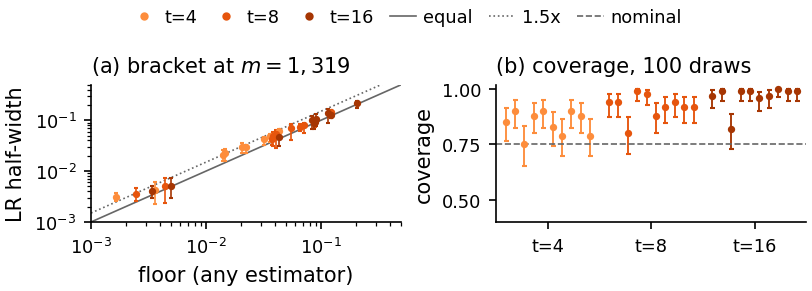

In [45]:
# 7.14g E10, revision 7 [analysis]: the error bracket at m = 1,319: the floor of every estimator against the likelihood-ratio interval at the same m -> T22, F29
# T17 and T21 compare the bound with the profile likelihood-ratio interval in problems needed, the reading that 7.14e found to
# be fragile. Here the comparison is made at a fixed benchmark size and in units of error. At m = 1,319 problems (n = 32), the
# floor of T19 is set beside the half-width of the likelihood-ratio interval at level 3/4: (i) in its best case (count histogram
# equal to the count law), solved at exactly the KL radius chi2_1(0.75) / (2m); (ii) on R benchmarks of m problems drawn from
# the real distribution, computed as in 7.14f (grid NPMLE, cutting-plane endpoints, LP relaxation), with its coverage of the
# true pass@k. The floor binds every estimator under some distribution near the real one; the interval is a procedure judged
# at the real one. A ratio near 1 means that, at this m, the bound is close to what a standard procedure achieves.
CFG.setdefault("E10_BRACKET_R", 4 if SMOKE else 100)    # draws per (count law, t); set in Section 1.3 to change it
E10BK, T22 = None, None
if E10LR is None or E10_FLOOR is None:
    print("E10 error bracket skipped: the floor (7.14e) or the likelihood-ratio band (7.14c) did not run.")
else:
    _bk_m = int(E10_FLOOR["m_head"])
    _bk_q = float(_lrq["3/4"])
    _bk_rho = _bk_q / (2.0 * _bk_m)
    _bk_ts = [t for t in CFG["E10_LR_TS"] if t in E10_FLOOR["ts"]]
    _bk_acc = float(CFG["E10H_ACC"])
    _bk_set = json.dumps([CFG["E10H_G"], CFG["E10_BRACKET_R"], _bk_q, _bk_m, _E10H_SOLVER, "LR error bracket v1"])

    def _e10bk_unit(name, ph, n, ts, R, seeds):
        S = HelSetup(ph, n, CFG["E10H_G"])
        p0 = S.pi0 / S.pi0.sum()
        t0 = time.time()
        res = {"n": n, "m": _bk_m, "ts": ts, "R": int(R), "best": {}, "draws": {}, "lp": 0, "lp_fail": 0}
        for t, seed in zip(ts, seeds):
            f = fail_k(S.X, int(t * n))
            F_true = float(f @ S.w0)
            bc = {}
            for sign in (1, -1):                              # best case: the histogram equals the count law
                r = div_solve(S, f, _bk_rho, sign)
                bc[sign] = (float(r["lp_upper"]), max(float(r["omega"]), 0.0)) if r is not None else (float("nan"), float("nan"))
            res["best"][t] = {"width_up": bc[1][0] + bc[-1][0], "width_cert": bc[1][1] + bc[-1][1]}
            rng = np.random.default_rng(seed)
            rec = {k_: [] for k_ in ("F_hat", "up_hi", "up_lo", "in_hi", "in_lo", "gap", "lp_ok")}
            for _r in range(int(R)):                          # benchmarks of m problems drawn from the real distribution
                ph_hat = rng.multinomial(_bk_m, p0) / float(_bk_m)
                w, Dg, gap, _its = npmle_grid(S.B, ph_hat)
                T = LRBase(S, ph_hat, w, Dg)
                eps_in = _bk_rho - gap
                vals, ok = {}, True
                for sign in (1, -1):
                    r = lr_interval_solve(T, f, _bk_rho, sign)
                    if r is None or not np.isfinite(r["lp_upper"]):
                        ok = False
                        vals[sign] = (float("nan"), float("nan"))
                        continue
                    om_in = lr_shrink(T, f, r["delta"], eps_in, sign)[0] if eps_in > 0 else 0.0
                    vals[sign] = (max(float(r["lp_upper"]), 0.0), max(om_in, 0.0))
                for k_, v_ in (("F_hat", float(f @ w)), ("up_hi", vals[1][0]), ("up_lo", vals[-1][0]), ("in_hi", vals[1][1]),
                               ("in_lo", vals[-1][1]), ("gap", gap), ("lp_ok", ok)):
                    rec[k_].append(v_)
                res["lp"] += T.stats["lp"]; res["lp_fail"] += T.stats["lp_fail"]
            rec = {k_: np.asarray(v_) for k_, v_ in rec.items()}
            rec.update({"F_true": F_true, "eps": _bk_rho})
            res["draws"][t] = rec
        res["lp"] += S.stats["lp"]; res["lp_fail"] += S.stats["lp_fail"]
        res["seconds"] = round(time.time() - t0, 1)
        print(f"[E10 bracket] {name}: m = {_bk_m:,}, t = {ts}, {R} draws each, done in {time.time() - t0:.0f}s "
              f"({res['lp']} LPs, {res['lp_fail']} failed)")
        return res

    E10BK = {}
    for _i, _name in enumerate(_dists):
        _ph = E10_DISTS[_name]
        _seeds = [SEED + 911 + 31 * _i + int(t) for t in _bk_ts]
        _key = "e10bk_" + hashlib.sha1(json.dumps([_name, data_tag(np.asarray(_ph, float)), _n0h, _bk_ts, _seeds, _bk_set]).encode()).hexdigest()[:12]
        E10BK[_name] = cached(_key, lambda nm=_name, ph=_ph, sd=_seeds: _e10bk_unit(nm, ph, _n0h, _bk_ts, CFG["E10_BRACKET_R"], sd))

    _rows22, _bk_store = [], {}
    for t in _bk_ts:
        for name in _dists:
            u = E10BK[name]
            d_ = u["draws"][t]
            ok = d_["lp_ok"].astype(bool)
            Rn = int(ok.sum())
            Ft = d_["F_true"]
            lo_out, hi_out = d_["F_hat"] - d_["up_lo"], d_["F_hat"] + d_["up_hi"]
            lo_in, hi_in = d_["F_hat"] - d_["in_lo"], d_["F_hat"] + d_["in_hi"]
            hw = (0.5 * (hi_out - lo_out))[ok]
            cov_out = int(((lo_out <= Ft) & (Ft <= hi_out))[ok].sum())
            cov_in = int(((lo_in <= Ft) & (Ft <= hi_in))[ok].sum())
            h10, h50, h90 = (np.quantile(hw, [0.1, 0.5, 0.9]) if Rn else [float("nan")] * 3)
            fl = float(E10_FLOOR["floor"][name][f"{t:g}"][str(_bk_m)])
            hb = 0.5 * u["best"][t]["width_up"]
            ratio = (h50 / fl) if fl > 0 else float("nan")
            _rows22.append({"Distribution": name, "t": f"{t:g}", "floor": f"{fl:.3f}", "LR best case": f"{hb:.3f}",
                            "LR drawn": f"{h50:.3f} ({h10:.3f}-{h90:.3f})", "ratio": (f"{ratio:.2f}" if np.isfinite(ratio) else "--"),
                            "coverage": (f"{cov_out}/{Rn}" if cov_in == cov_out else f"{cov_in}-{cov_out}/{Rn}")})
            _bk_store[f"{name}|{t}"] = {"floor": fl, "best_half": hb, "best_half_cert": 0.5 * u["best"][t]["width_cert"],
                                        "half_q10": float(h10), "half_median": float(h50), "half_q90": float(h90), "ratio": float(ratio),
                                        "ratio_best": (hb / fl) if fl > 0 else float("nan"), "cov_out": cov_out, "cov_in": cov_in, "R": Rn,
                                        "max_gap_over_eps": float(np.max(d_["gap"] / d_["eps"])) if len(d_["gap"]) else float("nan"),
                                        "half_widths": hw, "F_true": float(Ft)}
    T22 = pd.DataFrame(_rows22)
    print(T22.to_string(index=False))
    save_table(T22, "T22_error_bracket_realistic_m",
               f"E10, the error bracket at m = {_bk_m:,} problems (n = {_n0h}). floor: T19, the error that every estimator exceeds with "
               f"probability at least 1/4 under one of two distributions near the real one. LR: half-width of the profile "
               f"likelihood-ratio interval at level 3/4 (2m[KL(pi_hat || pi) - min KL] <= chi2_1(0.75), on the support grid, endpoints "
               f"from the LP relaxation) at the same m; best case: count histogram equal to the count law; drawn: median (10%-90%) over "
               f"{CFG['E10_BRACKET_R']} benchmarks of m problems drawn from the real distribution. ratio: drawn median over floor. "
               f"coverage: draws in which the interval holds the true pass@k (nominal 3/4; a range where the certified inner interval "
               f"gives fewer). The floor holds for every estimator near the real distribution; the interval is evaluated at the real "
               f"distribution only.", width_in=5.45)
    _gaps_bk = [abs(v["best_half"] - v["best_half_cert"]) / max(v["best_half"], 1e-12) for v in _bk_store.values()]
    _lpf = sum(u["lp_fail"] for u in E10BK.values())
    _lpt = sum(u["lp"] for u in E10BK.values())
    _by_t = {}
    for t in _bk_ts:
        vs = [_bk_store[f"{nm}|{t}"] for nm in _dists]
        big = [v for v in vs if v["floor"] > 0.01]
        above = [v for v in vs if v["floor"] > _bk_acc]
        _by_t[f"{t:g}"] = {"ratio_min": float(min(v["ratio"] for v in big)) if big else float("nan"),
                           "ratio_max": float(max(v["ratio"] for v in big)) if big else float("nan"),
                           "ratio_best_min": float(min(v["ratio_best"] for v in big)) if big else float("nan"),
                           "ratio_best_max": float(max(v["ratio_best"] for v in big)) if big else float("nan"),
                           "n_big": len(big), "n_above": len(above),
                           "floor_above": [min(v["floor"] for v in above), max(v["floor"] for v in above)] if above else None,
                           "half_above": [min(v["half_median"] for v in above), max(v["half_median"] for v in above)] if above else None,
                           "coverage": sum(v["cov_out"] for v in vs) / max(sum(v["R"] for v in vs), 1),
                           "coverage_min": float(min(v["cov_out"] / max(v["R"], 1) for v in vs))}
    E10_SUMMARY["bracket"] = {"m": _bk_m, "R": CFG["E10_BRACKET_R"], "q": _bk_q, "ts": _bk_ts, "pairs": _bk_store, "by_t": _by_t,
                              "best_case_solver_gap_max": float(max(_gaps_bk)) if _gaps_bk else float("nan"),
                              "lp_fail": int(_lpf), "lp_total": int(_lpt)}
    _parts = []
    for t in _bk_ts:
        b = _by_t[f"{t:g}"]
        if b["n_big"]:
            _parts.append(f"k={t:g}n {b['ratio_min']:.2f}-{b['ratio_max']:.2f}")
    _txt = (f"m = {_bk_m:,}: likelihood-ratio half-width over the floor (median of {CFG['E10_BRACKET_R']} drawn benchmarks; count laws "
            f"with floor above 0.01) " + ", ".join(_parts) + "; coverage at nominal 0.75: "
            + ", ".join(f"k={t:g}n {_by_t[f'{t:g}']['coverage']:.2f}" for t in _bk_ts))
    _b16 = _by_t.get(f"{max(_bk_ts):g}")
    if _b16 and _b16["n_above"]:
        _txt += (f"; at k={max(_bk_ts):g}n, for the {_b16['n_above']} count laws whose floor exceeds {_bk_acc:g}: floor "
                 f"{_b16['floor_above'][0]:.3f}-{_b16['floor_above'][1]:.3f}, half-width {_b16['half_above'][0]:.3f}-{_b16['half_above'][1]:.3f}")
    VERDICTS["E10 error bracket at realistic m (descriptive)"] = _txt
    print("E10 error bracket: " + _txt)
    print(f"E10 bracket checks: best-case half-width certified within {100 * max(_gaps_bk):.1f}% of its LP relaxation in every pair; "
          f"NPMLE gap at most {max(v['max_gap_over_eps'] for v in _bk_store.values()):.1e} of the KL radius; {_lpf} of {_lpt} LPs failed.")

    # ---- F29: (a) the bracket, floor against the likelihood-ratio half-width; (b) the interval's coverage at the same m
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
    f29 = {"m": _bk_m, "pairs": {}}
    _tc = {t: c for t, c in zip(sorted(set(CFG["E10_LR_TS"])), ORANGES[1:] + ORANGES[:1])}
    _lo, _hi = 1e-3, 0.5
    for t in _bk_ts:
        for name in _dists:
            v = _bk_store[f"{name}|{t}"]
            if v["floor"] <= 0:
                continue
            x = max(v["floor"], _lo * 1.05)
            ax1.errorbar([x], [v["half_median"]], yerr=[[v["half_median"] - v["half_q10"]], [v["half_q90"] - v["half_median"]]],
                         fmt="o", ms=2.5, color=_tc[t], elinewidth=0.8, capsize=1.0, zorder=3)
            f29["pairs"][f"{name}|{t}"] = {"floor": v["floor"], "half": [v["half_q10"], v["half_median"], v["half_q90"]],
                                           "best_half": v["best_half"], "coverage": v["cov_out"] / max(v["R"], 1)}
    _g = np.geomspace(_lo, _hi, 50)
    ax1.plot(_g, _g, color=BOUND_COLOR, lw=0.8)
    ax1.plot(_g, 1.5 * _g, color=BOUND_COLOR, lw=0.8, ls=":")
    ax1.set_xscale("log"); ax1.set_yscale("log")
    ax1.set_xlim(_lo, _hi); ax1.set_ylim(_lo, _hi)
    ax1.xaxis.set_major_locator(matplotlib.ticker.FixedLocator([1e-3, 1e-2, 1e-1]))
    ax1.yaxis.set_major_locator(matplotlib.ticker.FixedLocator([1e-3, 1e-2, 1e-1]))
    ax1.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter()); ax1.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax1.set_xlabel("floor (any estimator)"); ax1.set_ylabel("LR half-width")
    panel_label(ax1, f"(a) bracket at $m={_bk_m:,}$")
    xpos, _xt, _xl = 0.0, [], []
    for t in _bk_ts:
        x0 = xpos
        for name in _dists:
            v = _bk_store[f"{name}|{t}"]
            rate = v["cov_out"] / max(v["R"], 1)
            lo_ = float(stats.beta.ppf(0.025, v["cov_out"], v["R"] - v["cov_out"] + 1)) if v["cov_out"] > 0 else 0.0
            hi_ = float(stats.beta.ppf(0.975, v["cov_out"] + 1, v["R"] - v["cov_out"])) if v["cov_out"] < v["R"] else 1.0
            ax2.errorbar([xpos], [rate], yerr=[[rate - lo_], [hi_ - rate]], fmt="o", ms=2.5, color=_tc[t], elinewidth=0.9, capsize=1.2)
            f29["pairs"].setdefault(f"{name}|{t}", {})["coverage_ci"] = [rate, lo_, hi_]
            xpos += 1.0
        _xt.append(0.5 * (x0 + xpos - 1.0)); _xl.append(f"t={t:g}")
        xpos += 1.0
    ax2.set_xticks(_xt); ax2.set_xticklabels(_xl)
    ax2.set_xlim(-1.0, xpos - 1.0)
    ax2.axhline(0.75, color=BOUND_COLOR, lw=0.8, ls="--")
    ax2.set_ylim(0.4, 1.02)
    ax2.set_ylabel("coverage")
    panel_label(ax2, f"(b) coverage, {CFG['E10_BRACKET_R']} draws")
    _h = [Line2D([], [], color=_tc[t], marker="o", ls="none", ms=3, label=f"t={t:g}") for t in _bk_ts]
    _h += [Line2D([], [], color=BOUND_COLOR, lw=0.8, label="equal"), Line2D([], [], color=BOUND_COLOR, lw=0.8, ls=":", label="1.5x"),
           Line2D([], [], color=BOUND_COLOR, lw=0.8, ls="--", label="nominal")]
    shared_legend(fig, _h, [h.get_label() for h in _h], ncol=len(_h))
    finish_figure(fig, "F29_error_bracket_realistic_m", f29,
                  "Error bracket at a realistic benchmark size: the floor of every estimator against the likelihood-ratio interval.")

Figure F29 (E10 at a fixed benchmark size: the error bracket at $m=1{,}319$; $n=32$, $k=tn$ for $t=4$, 8 and 16).
- (a) For every count law and $t$, the floor of T19 (horizontal axis), which every estimator exceeds with probability at least $1/4$ under one of two distributions near the real one, against the half-width of the profile likelihood-ratio interval at level $3/4$ computed on benchmarks of the same size drawn from the real distribution (vertical axis; dot: median over the draws; bar: 10%–90%). Solid line: equality; dotted: 1.5 times the floor. Points close to the solid line mean that, at this $m$, the lower bound is close to what a standard procedure achieves.
- (b) Share of draws in which the interval holds the true pass@$k$, with 95% Clopper–Pearson intervals, grouped by $t$, count laws in the order of T22. Dashed: the nominal level 0.75.

The two sides are not the same kind of statement: the floor holds for every estimator under some distribution near the real one, while the interval is evaluated at the real distribution only. The interval is computed on the support grid of E10, with endpoints from the LP relaxation, so the interval drawn contains the exact one. T22 gives the numbers, including the best-case half-width (count histogram equal to the count law).

[resume] c5e_356037b5_200_0.5_0.25: loaded from checkpoint
          Stream PL 128 BB 128 NP 128 far k PL far BB far NP far BT far ref fold
Q-0.5B MATH (E8)   1.05   1.07   1.23   992   1.31   1.03   1.66   1.31     1.08
   GSM8K L3-8B-I   1.85   1.18   2.71   512   2.40   3.83     53   7.42     1.90
  GSM8K L3-70B-I   2.13     34   1.18 1,024   1.72    142   3.94   3.94     1.82
    MATH L3-8B-I   1.06   1.10   1.28 8,192   1.42   2.49   3.95   1.67     1.41
   MATH L3-70B-I   1.18   1.42   1.87 8,192   1.98   1.45     14   2.54     1.23
      CC L3-8B-I   1.01   1.01   1.02 8,192   1.03   1.10   2.07   1.10     1.02
     CC L3-70B-I   1.02   1.03   1.05 8,192   1.08   1.08   2.14   1.07     1.02
       MATH G-7B   1.05   1.24   1.44 8,192   1.21   2.36   3.98   1.60     1.40
         CC G-7B   1.02   1.01   1.01 8,192   1.07   1.11   1.47   1.06     1.02
      MATH P-12B   1.11   1.10   1.07 8,192   1.24   1.48   1.63   1.29     1.11
[table] T16_relative_failure_rate_errors: 10 rows,

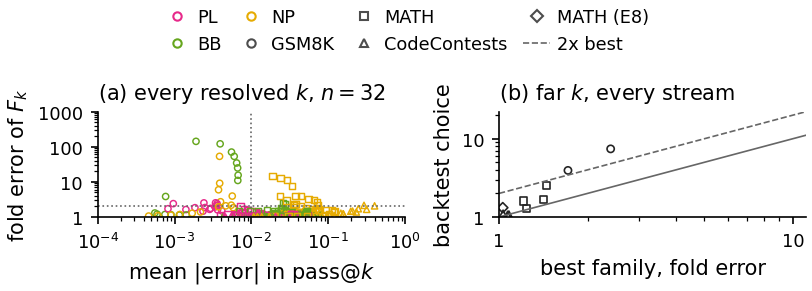

In [46]:
# 7.15 C5e, revision 5 [analysis]: the family comparison in relative failure-rate terms (exploratory: defined after the C5c and C5d results had been seen) -> T16, F25
# Absolute errors in pass@k are small whenever the failure rate F_k = 1 - pass@k is small, so an easy task can hide large
# relative errors. Here every forecast of F_k is scored by its fold error max(F_hat / F, F / F_hat) against the held-out
# reference, using only results already computed in E8 and E9 (n = 32). A fold error is reported only where the reference
# itself is known to within a factor C5E_REF_FOLD_MAX: half the log-width of a 90% parametric bootstrap interval of the
# reference (attempts redrawn per problem from its own success rate) must stay below log(C5E_REF_FOLD_MAX).
_C5E_N = 32
_C5E_FAMS = list(C5_FAMS)


def fold_error(est, ref):
    """max(est / ref, ref / est); inf if exactly one of them is zero, 1 if both are, nan if the reference is negative."""
    est, ref = np.asarray(est, float), np.asarray(ref, float)
    out = np.full(np.broadcast(est, ref).shape, np.nan)
    both0 = (est <= 0) & (ref <= 0)
    one0 = (est <= 0) ^ (ref <= 0)
    ok = (est > 0) & (ref > 0)
    out[both0] = 1.0
    out[one0] = np.inf
    with np.errstate(divide="ignore", over="ignore"):
        out[ok] = np.exp(np.abs(np.log(est[ok] / ref[ok])))
    return out


def ref_noise_fold(Y, n, ks, B, seed):
    """Factor within which the held-out reference of block 0 is known: sqrt(q95 / q05) of its parametric bootstrap."""
    rng = np.random.default_rng(seed)
    m, N = Y.shape
    Np = N - n
    cref = (Y.sum(1) - Y[:, :n].sum(1)).astype(int)
    draws = rng.binomial(Np, cref[None, :] / Np, size=(int(B), m))
    out = {}
    for k in ks:
        tab = chen_fail_table(Np, int(k))
        F = tab[draws].mean(1)
        q05, q95 = np.quantile(F, [0.05, 0.95])
        out[int(k)] = float(math.sqrt(q95 / q05)) if q05 > 0 else float("inf")
    return out


_C5E_SRC = {}
if globals().get("E8") is not None and _C5E_N in E8 and globals().get("E8X") is not None:
    _C5E_SRC["Q-0.5B MATH (E8)"] = (E8[_C5E_N], E8X[_C5E_N]["c5"]["selected"], Y8)
for _cfg in globals().get("E9", {}) or {}:
    if _C5E_N in E9[_cfg]["gt"]:
        try:
            _C5E_SRC[mb_code(_cfg)] = (E9[_cfg]["gt"][_C5E_N], E9[_cfg]["c5"][_C5E_N]["selected"], mb_labels(_cfg)["Y"])
        except Exception as _exc:
            print(f"C5e: {_cfg} skipped ({type(_exc).__name__})")

C5E = None
if not _C5E_SRC:
    print("C5e skipped: neither E8 nor E9 results are available.")
    VERDICTS["C5e relative failure-rate errors (exploratory)"] = "NOT RUN"
else:
    def _c5e():
        out = {}
        for i, (name, (G, sel, Yg)) in enumerate(_C5E_SRC.items()):
            ks = [int(k) for k in G["ks"]]
            u = ref_noise_fold(Yg, _C5E_N, ks, CFG["C5E_BOOT"], SEED + 501 + i)
            rec = {"ks": ks, "u": u, "ref": np.asarray(G["ref"]).mean(0).tolist(), "fold": {}, "abs": {}}
            for nm in _C5E_FAMS:
                fe = fold_error(G["est"][nm], G["ref"])
                rec["fold"][nm] = np.median(fe, axis=0).tolist()
                rec["abs"][nm] = np.nanmean(np.abs(np.asarray(G["est"][nm]) - np.asarray(G["ref"])), axis=0).tolist()
            est_sel = np.array([[G["est"][s_][b, j] for j in range(len(ks))] for b, s_ in enumerate(sel)])
            rec["fold"]["Backtest choice"] = np.median(fold_error(est_sel, np.asarray(G["ref"])[:len(sel)]), axis=0).tolist()
            out[name] = rec
        return out

    C5E = cached(f"c5e_{hashlib.sha1(json.dumps(sorted(_C5E_SRC)).encode()).hexdigest()[:8]}_{CFG['C5E_BOOT']}_{BT_TAG}", _c5e)
    _fmax = float(CFG["C5E_REF_FOLD_MAX"])
    _knear = 4 * _C5E_N
    _fmtf = lambda v: ("inf" if not np.isfinite(v) else (f"{v:.2f}" if v < 10 else (f"{v:.0f}" if v < 1e4 else f"{v:.1e}")))
    _rows16, _hide, _bt_bad, _flip_rel, _far_info = [], [], [], [], {}
    for name, rec in C5E.items():
        ks = rec["ks"]
        res_ks = [k for k in ks if rec["u"][k] <= _fmax]
        jn = ks.index(_knear) if _knear in ks else int(np.argmin([abs(k - _knear) for k in ks]))
        kf = max(res_ks) if res_ks else None      # far k: the largest k whose reference is resolved
        row = {"Stream": name}
        for nm in _C5E_FAMS:
            row[f"{CODE2[nm]} {ks[jn]}"] = _fmtf(rec["fold"][nm][jn]) if ks[jn] in res_ks else "n/r"
        row["far k"] = f"{kf:,}" if kf else "--"
        for nm in _C5E_FAMS + ["Backtest choice"]:
            row[f"{CODE2.get(nm, 'BT')} far"] = _fmtf(rec["fold"][nm][ks.index(kf)]) if kf else "--"
        row["ref fold"] = f"{rec['u'][kf]:.2f}" if kf else "--"
        _rows16.append(row)
        for nm in _C5E_FAMS:                      # cells where the absolute error looks negligible but the fold error is not
            for j, k in enumerate(ks):
                if k in res_ks and rec["abs"][nm][j] < 0.01 and rec["fold"][nm][j] >= 2.0:
                    _hide.append((name, CODE2[nm], k, rec["abs"][nm][j], rec["fold"][nm][j]))
        if kf:
            jf = ks.index(kf)
            ff = {nm: rec["fold"][nm][jf] for nm in _C5E_FAMS}
            best_far = min(_C5E_FAMS, key=lambda nm: ff[nm])
            bt = rec["fold"]["Backtest choice"][jf]
            _far_info[name] = {"k": kf, "best": best_far, "best_fold": ff[best_far], "bt_fold": bt, "folds": ff}
            if bt >= max(2.0 * ff[best_far], 1.5):
                _bt_bad.append(name)
            if ks[jn] in res_ks and kf != ks[jn]:
                fn = {nm: rec["fold"][nm][jn] for nm in _C5E_FAMS}
                best_near = min(_C5E_FAMS, key=lambda nm: fn[nm])
                _far_info[name]["best_near"] = best_near
                if best_near != best_far and ff[best_near] >= max(2.0 * ff[best_far], 1.5):
                    _flip_rel.append(name)
    T16 = pd.DataFrame(_rows16)
    print(T16.to_string(index=False))
    save_table(T16, "T16_relative_failure_rate_errors",
               f"C5e (exploratory, defined after C5c and C5d were seen), n = {_C5E_N}: median over the 8 blocks of the fold error "
               f"max(F_hat/F, F/F_hat) of the failure rate F = 1 - pass@k, at k = {_knear} and at the largest k (far k) whose "
               f"held-out reference is known within a factor {_fmax:g} ('ref fold': sqrt(q95/q05) of a parametric bootstrap of "
               f"the reference); BT = the family chosen per block by the in-window backtest of C5c; n/r = reference not resolved "
               f"at that k. " + CODE2_NOTE, width_in=5.45)
    _gsm = [h for h in _hide if h[0].startswith("GSM8K")]
    print(f"C5e (exploratory): {len(_hide)} resolved cells with mean |error| below 0.01 but a fold error of 2 or more"
          + (f" ({len(_gsm)} of them on GSM8K; largest fold error {max(h[4] for h in _hide):.0f})" if _hide else ""))
    print(f"C5e (exploratory): backtest choice at least twice the best family's fold error at the far k in {len(_bt_bad)} of "
          f"{len(_far_info)} streams {_bt_bad}; family flip in relative terms in {len(_flip_rel)} {_flip_rel}")
    for name, fi in _far_info.items():
        print(f"   {name}: far k={fi['k']}: " + ", ".join(f"{SHORT[nm]} x{fi['folds'][nm]:.2f}" for nm in _C5E_FAMS)
              + f"; backtest x{fi['bt_fold']:.2f}")
    C5E_SUMMARY = {"n": _C5E_N, "fold_max": _fmax, "hidden": _hide, "bt_bad": _bt_bad, "flip_rel": _flip_rel, "far": _far_info,
                   "streams": list(C5E)}
    VERDICTS["C5e relative failure-rate errors (exploratory)"] = (
        f"{len(_hide)} resolved cells with |error| < 0.01 but fold error >= 2; backtest >= 2x best fold in "
        f"{len(_bt_bad)}/{len(_far_info)}; relative flips {len(_flip_rel)}")

    # ---- F25: (a) absolute against fold error for every resolved cell; (b) backtest choice against the best family, far k
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
    _task_marker = lambda name: "D" if "(E8)" in name else ("o" if name.startswith("GSM8K") else ("s" if name.startswith("MATH") else "^"))
    f25 = {"cells": [], "far": _far_info}
    for name, rec in C5E.items():
        for nm in _C5E_FAMS:
            for j, k in enumerate(rec["ks"]):
                if rec["u"][k] <= _fmax and np.isfinite(rec["fold"][nm][j]):
                    x, y = max(rec["abs"][nm][j], 1e-4), min(max(rec["fold"][nm][j], 1.0), 1e4)
                    ax1.scatter([x], [y], s=9, marker=_task_marker(name), facecolors="none", edgecolors=METHOD_COLORS[nm], linewidths=0.7)
                    f25["cells"].append([name, nm, k, rec["abs"][nm][j], rec["fold"][nm][j]])
    ax1.axhline(2.0, color=BOUND_COLOR, lw=0.8, ls=":")
    ax1.axvline(0.01, color=BOUND_COLOR, lw=0.8, ls=":")
    ax1.set_xscale("log"); ax1.set_yscale("log")
    _ytop = 10.0 ** max(1, math.ceil(math.log10(max([2.0] + [c[4] for c in f25["cells"] if np.isfinite(c[4])]))))
    ax1.set_xlim(1e-4, 1.0); ax1.set_ylim(1.0, min(_ytop, 1e4))
    ax1.xaxis.set_major_locator(matplotlib.ticker.FixedLocator([1e-4, 1e-3, 1e-2, 1e-1, 1.0]))
    ax1.yaxis.set_major_locator(matplotlib.ticker.FixedLocator([v for v in (1.0, 10.0, 100.0, 1000.0, 1e4) if v <= min(_ytop, 1e4)]))
    ax1.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _p: f"{v:g}"))
    ax1.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter()); ax1.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax1.set_xlabel("mean |error| in pass@$k$"); ax1.set_ylabel("fold error of $F_k$")
    panel_label(ax1, f"(a) every resolved $k$, $n={_C5E_N}$")
    _xy = [(fi["best_fold"], fi["bt_fold"], name) for name, fi in _far_info.items()]
    for x, y, name in _xy:
        ax2.scatter([x], [min(y, 1e3)], s=12, marker=_task_marker(name), facecolors="none", edgecolors="#252525", linewidths=0.8)
    _lim2 = max([2.0] + [max(x, min(y, 1e3)) for x, y, _ in _xy]) * 1.5
    _g = np.geomspace(1.0, _lim2, 50)
    ax2.plot(_g, _g, color=BOUND_COLOR, lw=0.8)
    ax2.plot(_g, 2 * _g, color=BOUND_COLOR, lw=0.8, ls="--")
    ax2.set_xscale("log"); ax2.set_yscale("log")
    ax2.set_xlim(1.0, _lim2); ax2.set_ylim(1.0, 2 * _lim2)
    ax2.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _p: f"{v:g}"))
    ax2.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _p: f"{v:g}"))
    ax2.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter()); ax2.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax2.set_xlabel("best family, fold error"); ax2.set_ylabel("backtest choice")
    panel_label(ax2, "(b) far $k$, every stream")
    _h = [Line2D([], [], color=METHOD_COLORS[nm], marker="o", ls="none", mfc="none", ms=4, label=CODE2[nm]) for nm in _C5E_FAMS]
    _h += [Line2D([], [], color="#4d4d4d", marker=mk, ls="none", mfc="none", ms=4, label=lab)
           for mk, lab in (("o", "GSM8K"), ("s", "MATH"), ("^", "CodeContests"), ("D", "MATH (E8)"))]
    _h += [Line2D([], [], color=BOUND_COLOR, lw=0.8, ls="--", label="2x best")]
    shared_legend(fig, _h, [h.get_label() for h in _h], ncol=4)
    finish_figure(fig, "F25_relative_failure_rate_errors", f25,
                  "Exploratory: the family comparison in relative failure-rate terms (E8 and E9, n = 32).")

Figure F25 (C5e, exploratory: the family comparison in relative terms; E8 and E9, $n=32$).
- (a) Every resolved combination of stream, family and $k$: mean absolute error in pass@$k$ over the 8 blocks against the median fold error $\max(\hat F/F,F/\hat F)$ of the failure rate $F=1-\text{pass@}k$. Colour: power law, Beta-binomial, NPMLE; marker: task. Dotted lines at fold error 2 and absolute error 0.01; points in the upper left look negligible in pass@$k$ but are large relative to the failure rate.
- (b) At the far $k$ of each stream (the largest $k$ whose reference is resolved): the fold error of the family chosen by the in-window backtest of C5c against the fold error of the best family. Solid line: equal; dashed: twice the best.

A cell is resolved if the held-out reference is known within a factor of 2: $\sqrt{q_{0.95}/q_{0.05}}$ of a parametric bootstrap of the reference, with each problem's attempts redrawn from its own success rate. C5e was defined after the C5c and C5d results were known. T16 gives the numbers.

## Section 8: Robustness and Adversarial Stress Tests

Each test below is designed to find where the guarantees break.

- Adv1 breaks (A1) on purpose. It uses a Markov copy model and block-wise drift, with exact bias via a 2×2 transfer matrix and simulated test power. It compares $\rho_{\mathrm{break}}$, where the bias leaves the envelope, with $\rho_{\mathrm{detect}}$, where the A1 tests reach 80% power.
- Adv2 plants extremal pairs inside the real success-rate distributions. Both members of each pair produce identical count laws, or nearly so.
- Adv3 tests the barrier near $t=2$ and an adversarially selected subset of problems.
- Ab3 recomputes the headline checks with the second grader, G2.

Figures F7a (copy model) and F7b (drift) show the A1-violation map.
- (a) Bias vs violation: the exact mean bias of the doubling estimator at $k=48$ against the strength of the violation ($\rho$ or $\tau$), with the signed envelope (grey).
- (b) A1 test power: the power of the three A1 tests at Bonferroni level $0.05/3$, with the 80% line, and the two thresholds marked: $\rho_{\mathrm{break}}$ (solid) and $\rho_{\mathrm{detect}}$ (dashed).

[resume] adv1_1e894fd9be: loaded from checkpoint
[Base] copy model: rho_break = 0.010, rho_detect = 0.016;  drift: tau_break = 5.00e-03, tau_detect = 0.017
[Instruct] copy model: rho_break = 0.010, rho_detect = 0.017;  drift: tau_break = 5.00e-03, tau_detect = 0.017
[figure] F7a_A1_violation_copy_model: layout audit OK {"n_text": 23, "text_overlaps": 0}


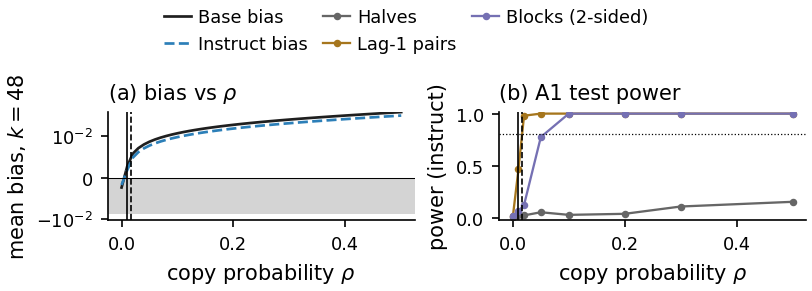

[figure] F7b_A1_violation_block_drift: layout audit OK {"n_text": 27, "text_overlaps": 0}


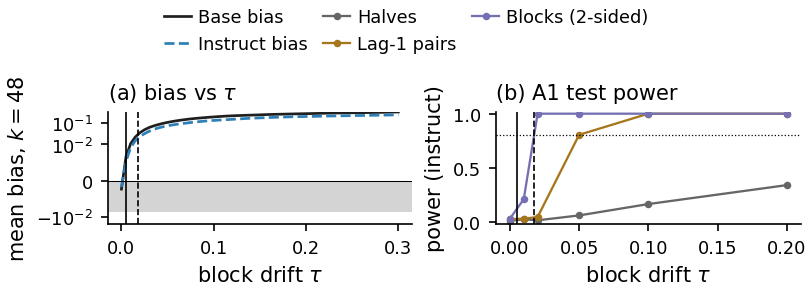

In [47]:
# 8.1 Adv1: A1 violations (copy model, block drift): exact bias via a 2x2 transfer matrix, power via z-tests on exact permutation moments [analysis]
from matplotlib.colors import to_rgb


def shade(color, frac):
    """Blend a colour towards white (frac = 0 keeps the colour, 1 gives white)."""
    r, g, b = to_rgb(color)
    return (r + (1 - r) * frac, g + (1 - g) * frac, b + (1 - b) * frac)


def copy_gf(p, rho, n, z):
    """E[z^c] for the Markov copy chain over n attempts with stationary success probability p (vectorised over p)."""
    p = np.asarray(p, float)
    a01, a11 = (1 - rho) * p, rho + (1 - rho) * p
    f0, f1 = 1 - p, p * z
    for _ in range(n - 1):
        f0, f1 = f0 * (1 - a01) + f1 * (1 - a11), (f0 * a01 + f1 * a11) * z
    return f0 + f1


def null_moments(N, block, n_perm, seed):
    """Exact permutation-null means/variances of the per-problem A1 statistics for every success count C = 0..N."""
    tabs = perm_null_tables(np.arange(N + 1), N, block, n_perm, np.random.default_rng(seed))
    mom = {}
    for key in ("H", "A", "X2"):
        mom[key + "_mean"] = np.array([tabs[c][key].mean() for c in range(N + 1)])
        mom[key + "_var"] = np.array([tabs[c][key].var() for c in range(N + 1)])
    return mom


def ztest_pvals(Y, mom):
    C, H, A, X2 = a1_observed(Y, N_BLK)
    C = np.asarray(C, dtype=int)
    trip = (((2 * H - C).sum(), (2 * mom["H_mean"][C] - C).sum(), (4 * mom["H_var"][C]).sum()),
            (A.sum(), mom["A_mean"][C].sum(), mom["A_var"][C].sum()),
            (X2.sum(), mom["X2_mean"][C].sum(), mom["X2_var"][C].sum()))
    return [float(2 * stats.norm.sf(abs((s - mu) / math.sqrt(max(v, 1e-12))))) for s, mu, v in trip]


def run_adv1():
    n, k, t = N_BLK, 48, 1.5
    el, eh = signed_envelope(n, k)
    mom = null_moments(N_ATT, N_BLK, 300 if SMOKE else 2000, SEED + 61)
    rng = np.random.default_rng(SEED + 62)
    out = {"env": (el, eh)}
    rho_fine, tau_fine = np.linspace(0, 0.5, 51), np.linspace(0, 0.3, 61)
    rho_grid, tau_grid = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5], [0, 0.01, 0.02, 0.05, 0.1, 0.2]
    for mk in MODEL_KEYS:
        Y, pt = YG1[mk], PT[mk]
        bias_copy = np.array([np.mean(copy_gf(pt, r, n, 1 - t) - (1 - pt) ** k) for r in rho_fine])
        bias_drift = []
        for tau in tau_fine:
            pu, pd_ = np.clip(pt + tau, 0, 1), np.clip(pt - tau, 0, 1)
            bias_drift.append(np.mean(0.5 * ((1 - t * pu) ** n + (1 - t * pd_) ** n) - (1 - 0.5 * (pu + pd_)) ** k))
        bias_drift = np.array(bias_drift)
        pow_copy, pow_drift = [], []
        for r in rho_grid:
            det = np.zeros(3)
            for _ in range(CFG["R_POWER"]):
                Yc = copy_model(rng.permuted(Y, axis=1), r, rng)
                det += np.array(ztest_pvals(Yc, mom)) < 0.05 / 3
            pow_copy.append(det / CFG["R_POWER"])
        for tau in tau_grid:
            det = np.zeros(3)
            for _ in range(CFG["R_POWER"]):
                signs = rng.choice([-1.0, 1.0], size=(pt.size, NB))
                rates = np.repeat(np.clip(pt[:, None] + tau * signs, 0, 1), N_BLK, axis=1)
                det += np.array(ztest_pvals((rng.random(rates.shape) < rates).astype(np.uint8), mom)) < 0.05 / 3
            pow_drift.append(det / CFG["R_POWER"])

        def first_cross(xs, ys):
            bad = np.flatnonzero((ys < el) | (ys > eh))
            return float(xs[bad[0]]) if bad.size else float("nan")

        def detect_at(xs, pw):
            anyp = np.max(np.array(pw), axis=1)
            idx = np.flatnonzero(anyp >= 0.8)
            if idx.size == 0:
                return float("nan")
            i = int(idx[0])
            if i == 0:
                return float(xs[0])
            x0, x1, y0, y1 = xs[i - 1], xs[i], anyp[i - 1], anyp[i]
            return float(x0 + (0.8 - y0) * (x1 - x0) / max(y1 - y0, 1e-12))

        out[mk] = {"rho_fine": rho_fine, "bias_copy": bias_copy, "tau_fine": tau_fine, "bias_drift": bias_drift,
                   "rho_grid": rho_grid, "pow_copy": np.array(pow_copy), "tau_grid": tau_grid, "pow_drift": np.array(pow_drift),
                   "rho_break": first_cross(rho_fine, bias_copy), "rho_detect": detect_at(np.array(rho_grid), pow_copy),
                   "tau_break": first_cross(tau_fine, bias_drift), "tau_detect": detect_at(np.array(tau_grid), pow_drift)}
    return out


ADV1 = cached(f"adv1_{DATA_TAG}", run_adv1)
for mk in MODEL_KEYS:
    a = ADV1[mk]
    print(f"[{MODEL_LABELS[mk]}] copy model: rho_break = {fmt(a['rho_break'], 3)}, rho_detect = {fmt(a['rho_detect'], 3)};  "
          f"drift: tau_break = {fmt(a['tau_break'], 3)}, tau_detect = {fmt(a['tau_detect'], 3)}")

for tag, xf, yf, xg, pg, brk, det, xlabel in (
        ("F7a_A1_violation_copy_model", "rho_fine", "bias_copy", "rho_grid", "pow_copy", "rho_break", "rho_detect", r"copy probability $\rho$"),
        ("F7b_A1_violation_block_drift", "tau_fine", "bias_drift", "tau_grid", "pow_drift", "tau_break", "tau_detect", r"block drift $\tau$")):
    fig, axes = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
    el, eh = ADV1["env"]
    axes[0].axhspan(el, eh, color=shade(BOUND_COLOR, 0.72), lw=0)
    for mk in MODEL_KEYS:
        axes[0].plot(ADV1[mk][xf], ADV1[mk][yf], color=MODEL_COLORS[mk], lw=1.3, ls="-" if mk == "base" else "--")
    axes[0].axhline(0, color="k", lw=0.5)
    axes[0].set_yscale("symlog", linthresh=1e-3, linscale=0.6)
    axes[0].set_ylabel("mean bias, $k=48$")
    a = ADV1["instruct"]
    for j, (key, nm) in enumerate(A1_TEST_NAMES.items()):
        axes[1].plot(a[xg], np.array(a[pg])[:, j], marker="o", ms=2.6, lw=1.1, color=(PALETTE[7], PALETTE[6], PALETTE[2])[j], label=A1_SHORT[key])
    axes[1].axhline(0.8, color="k", lw=0.6, ls=":")
    for ax in axes:
        if np.isfinite(a[brk]):
            ax.axvline(a[brk], color="k", lw=0.8)
        if np.isfinite(a[det]):
            ax.axvline(a[det], color="k", lw=0.8, ls="--")
        ax.set_xlabel(xlabel)
    tidy_symlog(axes[0], 1e-3)
    axes[1].set_ylim(-0.02, 1.02)
    axes[1].set_ylabel("power (instruct)")
    panel_label(axes[0], "(a) bias vs " + (r"$\rho$" if "copy" in tag else r"$\tau$")); panel_label(axes[1], "(b) A1 test power")
    _h, _l = axes[1].get_legend_handles_labels()
    _h = [Line2D([], [], color=MODEL_COLORS["base"], lw=1.3), Line2D([], [], color=MODEL_COLORS["instruct"], lw=1.3, ls="--")] + _h
    shared_legend(fig, _h, ["Base bias", "Instruct bias"] + _l, 3)
    _fd = {mk: {kk: ADV1[mk][kk] for kk in (xf, yf, xg, pg, brk, det)} for mk in MODEL_KEYS}
    _fd["envelope"] = ADV1["env"]
    finish_figure(fig, tag, _fd, "A1-violation map: (a) exact bias against violation strength with the signed envelope; (b) power of the A1 tests.")

Figure F12 (adversarial distributions).
- (a) Same count law (Adv2): the Lemma 2(ii) pair at $(n,k)=(32,8192)$, mixed at weight 0.5 into the instruct model's empirical success-rate distribution. The two members produce identical count laws at $n=32$. Each estimator's estimate of $F_{8192}$ is shown as its median with a 10–90% range, against the two members' true values (dashed and dotted lines). No estimator can be within half the separation of both.
- (b) Selected subset (Adv3): the M6 contrast at $(32,48)$ on problems selected with attempts 129–256 to have $\tilde p\approx p^*$, where $|\beta|$ peaks, and evaluated on attempts 1–128. It is compared with the exact $\beta(p^*)$ (dashed), the lower envelope (solid grey) and the full-sample contrast (hollow markers).

Estimator codes: Dbl doubling (ours), LP LP-cert (ours), PL power law, BB Beta-binomial, NP NPMLE, MM moment matching.

[resume] adv2_1e894fd9be_6_dkwcp: loaded from checkpoint
[resume] adv3_1e894fd9be: loaded from checkpoint
[Base] Adv2 Lemma 2(ii) pair: count-law difference 1.1e-16, separation 0.3344, band holds both members in 1.00 of replicates; worst-member miss fractions {'Doubling': 1.0, 'LP-cert': 1.0, 'Power law': 0.68, 'Beta-bin.': 0.88, 'NPMLE': 0.8, 'Moments': 0.76}
[Base] Adv2 M5 pair (k=512): weight 1.000, separation 0.2014, max miss fractions {Doubling: 1.00, LP-cert: 1.00, Power law: 0.95, Beta-bin.: 1.00, NPMLE: 0.60, Moments: 0.70}
[Base] Adv3 selection: 49 problems, contrast -0.0023 [-0.0026, -0.0019] vs exact beta(p*=0.041) = -0.0029, lower envelope -0.0060
[Instruct] Adv2 Lemma 2(ii) pair: count-law difference 3.5e-18, separation 0.3344, band holds both members in 1.00 of replicates; worst-member miss fractions {'Doubling': 1.0, 'LP-cert': 1.0, 'Power law': 0.6, 'Beta-bin.': 0.81, 'NPMLE': 0.79, 'Moments': 0.63}
[Instruct] Adv2 M5 pair (k=512): weight 1.000, separation 0.2014, max m

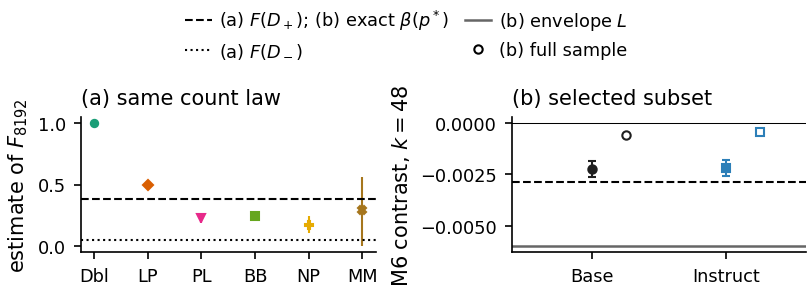

[table] T6_robustness_adversarial: 16 rows, estimated width 5.45 in (table*)
   Model             Condition                         Measured            Reference         Outcome
    Base       Adv1 copy model                  rho_break 0.010     rho_detect 0.016    breaks first
    Base      Adv1 block drift               tau_break 5.00e-03     tau_detect 0.017    breaks first
    Base Adv2 Lemma 2(ii) pair                        sep 0.334 band holds both 1.00            PASS
    Base  Adv2 M5 pair (k=512)                        sep 0.201  min worst-miss 0.60            PASS
    Base  Adv3 selected subset                    n=49, -0.0023     beta(p*) -0.0029 inside envelope
    Base     Adv3 barrier k=60 -7.96e-04 [-9.65e-04, -6.31e-04]     [-0.0084, 0.014]          inside
    Base     Adv3 barrier k=62 -6.21e-04 [-8.79e-04, -3.22e-04]     [-0.0087, 0.127]          inside
    Base     Adv3 barrier k=63  -1.90e-04 [-7.60e-04, 5.75e-04]     [-0.0089, 0.362]          inside
Instruct      

In [48]:
# 8.2 Adv2 (extremal pairs inside real data) and Adv3 (barrier, adversarial selection) -> F12, T6 [analysis]
def run_adv2():
    pair = extremal_pair(32, 8192)
    rng = np.random.default_rng(SEED + 91)
    out = {"pair_sep": pair["sep"]}
    for mk in MODEL_KEYS:
        p_emp = PT[mk]
        m = p_emp.size
        base = [(float(p), 1.0 / m) for p in p_emp]
        plus = [(p, 0.5 * w) for p, w in base] + [(p, 0.5 * w) for p, w in pair["atoms_mu"]]
        minus = [(p, 0.5 * w) for p, w in base] + [(p, 0.5 * w) for p, w in pair["atoms_nu"]]
        k1 = 8192
        Fp, Fm = F_atoms(plus, k1), F_atoms(minus, k1)
        pi_p, pi_m = count_law_atoms(plus, N_BLK), count_law_atoms(minus, N_BLK)
        Hs = rng.multinomial(m, pi_p / pi_p.sum(), size=CFG["R_ADV2"]).astype(float)
        est = estimate_all(Hs, N_BLK, [k1], m, names=E3_NAMES, any_t=True, G=CFG["LP_G_SWEEP"])
        sep = abs(Fp - Fm)
        miss = {nm: (float(np.mean(np.abs(est[nm][:, 0] - Fp) >= sep / 2)), float(np.mean(np.abs(est[nm][:, 0] - Fm) >= sep / 2)))
                for nm in E3_NAMES}
        q = {nm: np.quantile(est[nm][:, 0], [0.1, 0.5, 0.9]) for nm in E3_NAMES}
        hits = []
        for r in range(CFG["R_ADV2_BAND"]):
            b = pi_band(Hs[r], N_BLK, [k1], DELTA)[0]
            hits.append(bool(b[0] <= min(Fp, Fm) + 1e-9 and max(Fp, Fm) <= b[1] + 1e-9))
        k2 = 512
        lb = m5_cached(N_BLK, k2, m)
        D0, D1 = [(lb["q"], 1 - lb["w"]), (lb["p0"], lb["w"])], [(lb["q"], 1 - lb["w"]), (lb["p1"], lb["w"])]
        pb, p0, p1 = count_law_atoms(base, N_BLK), count_law_atoms(D0, N_BLK), count_law_atoms(D1, N_BLK)

        def chi2(a):
            q0, q1 = (1 - a) * pb + a * p0, (1 - a) * pb + a * p1
            with np.errstate(divide="ignore", invalid="ignore"):
                return float(np.sum(np.where((q1 - q0) ** 2 > 0, (q1 - q0) ** 2 / q0, 0.0)))

        lo, hi = 0.0, 1.0
        for _ in range(50):
            mid = 0.5 * (lo + hi)
            lo, hi = (mid, hi) if chi2(mid) <= 1.0 / (2 * m) else (lo, mid)
        alpha = lo
        F0 = (1 - alpha) * F_atoms(base, k2) + alpha * F_atoms(D0, k2)
        F1 = (1 - alpha) * F_atoms(base, k2) + alpha * F_atoms(D1, k2)
        sep2, miss2 = abs(F0 - F1), {nm: [] for nm in E3_NAMES}
        for pp, Ft in (((1 - alpha) * pb + alpha * p0, F0), ((1 - alpha) * pb + alpha * p1, F1)):
            e2_ = estimate_all(rng.multinomial(m, pp / pp.sum(), size=CFG["R_ADV2"]).astype(float), N_BLK, [k2], m,
                               names=E3_NAMES, any_t=True, G=CFG["LP_G_SWEEP"])
            for nm in E3_NAMES:
                miss2[nm].append(float(np.mean(np.abs(e2_[nm][:, 0] - Ft) >= sep2 / 2)))
        out[mk] = {"F_plus": Fp, "F_minus": Fm, "sep": sep, "law_diff": float(np.max(np.abs(pi_p - pi_m))), "miss": miss, "q": q,
                   "band_both": float(np.mean(hits)), "m5_alpha": alpha, "m5_sep": sep2, "m5_miss": miss2}
    lp_cache_flush()
    return out


def run_adv3():
    ext = exact_bias_extrema(N_BLK, 48)
    p_star = ext["p_min"]
    rng = np.random.default_rng(SEED + 93)
    out = {"p_star": p_star, "beta_star": ext["min"], "env": signed_envelope(N_BLK, 48)}
    for mk in MODEL_KEYS:
        Y = YG1[mk]
        r_sel = Y[:, 128:].mean(1)
        sel = np.flatnonzero((r_sel >= p_star / 2) & (r_sel <= 2 * p_star))
        if sel.size < 5:
            out[mk] = {"n_sel": int(sel.size), "mean": float("nan"), "lo": float("nan"), "hi": float("nan")}
            continue
        v = m6_contrast_values(Y[sel, :128].sum(1).astype(int), 128, N_BLK, 48)
        Wsub = rng.multinomial(sel.size, np.full(sel.size, 1.0 / sel.size), size=CFG["B_BOOT"])
        lo, hi = pct_ci((Wsub @ v) / sel.size)
        out[mk] = {"n_sel": int(sel.size), "mean": float(v.mean()), "lo": float(lo), "hi": float(hi)}
    return out


ADV2 = cached(f"adv2_{DATA_TAG}_{len(E3_NAMES)}_{M3_TAG}", run_adv2)
ADV3 = cached(f"adv3_{DATA_TAG}", run_adv3)
for mk in MODEL_KEYS:
    a2 = ADV2[mk]
    worst = {SHORT[nm]: round(max(v), 2) for nm, v in a2["miss"].items()}
    print(f"[{MODEL_LABELS[mk]}] Adv2 Lemma 2(ii) pair: count-law difference {a2['law_diff']:.1e}, separation {a2['sep']:.4f}, "
          f"band holds both members in {a2['band_both']:.2f} of replicates; worst-member miss fractions {worst}")
    print(f"[{MODEL_LABELS[mk]}] Adv2 M5 pair (k=512): weight {a2['m5_alpha']:.3f}, separation {a2['m5_sep']:.4f}, "
          f"max miss fractions {{{', '.join(f'{SHORT[nm]}: {max(v):.2f}' for nm, v in a2['m5_miss'].items())}}}")
    a3 = ADV3[mk]
    print(f"[{MODEL_LABELS[mk]}] Adv3 selection: {a3['n_sel']} problems, contrast {fmt_ci(a3['mean'], a3['lo'], a3['hi'], 4)} vs exact "
          f"beta(p*={ADV3['p_star']:.3f}) = {ADV3['beta_star']:.4f}, lower envelope {ADV3['env'][0]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=FIG_PANEL, layout="constrained")
ax = axes[0]
a2 = ADV2["instruct"]
for x, nm in enumerate(E3_NAMES):
    q = a2["q"][nm]
    ax.errorbar([x], [q[1]], yerr=[[q[1] - q[0]], [q[2] - q[1]]], fmt=METHOD_MARKERS[nm], ms=3.5, color=METHOD_COLORS[nm], capsize=0, lw=1)
ax.axhline(a2["F_plus"], color="k", lw=1.0, ls="--")
ax.axhline(a2["F_minus"], color="k", lw=1.0, ls=":")
ax.set_xticks(range(len(E3_NAMES)))
ax.set_xticklabels([CODE2[nm] for nm in E3_NAMES])
ax.set_ylabel(r"estimate of $F_{8192}$")
panel_label(ax, "(a) same count law")
ax = axes[1]
el, eh = ADV3["env"]
ax.axhline(ADV3["beta_star"], color="k", lw=1.0, ls="--")
ax.axhline(el, color=BOUND_COLOR, lw=1.2)
for j, mk in enumerate(MODEL_KEYS):
    a3 = ADV3[mk]
    if np.isfinite(a3["mean"]):
        ax.errorbar([j], [a3["mean"]], yerr=[[a3["mean"] - a3["lo"]], [a3["hi"] - a3["mean"]]], fmt=MODEL_MARKERS[mk], ms=4,
                    color=MODEL_COLORS[mk], capsize=2, lw=1)
    r48 = next(r for r in E2[mk]["rows"] if r["k"] == 48)
    ax.plot([j + 0.25], [r48["contrast"]], marker=MODEL_MARKERS[mk], mfc="none", mec=MODEL_COLORS[mk], ms=4, ls="none")
ax.axhline(0, color="k", lw=0.5)
ax.set_xticks([0, 1])
ax.set_xticklabels([MODEL_LABELS[mk] for mk in MODEL_KEYS])
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("M6 contrast, $k=48$")
panel_label(ax, "(b) selected subset")
handles = [Line2D([], [], color="k", ls="--", lw=1.0), Line2D([], [], color="k", ls=":", lw=1.0), Line2D([], [], color=BOUND_COLOR, lw=1.2),
           Line2D([], [], marker="o", ls="none", mfc="none", mec="k", ms=4)]
shared_legend(fig, handles, [r"(a) $F(D_+)$; (b) exact $\beta(p^*)$", r"(a) $F(D_-)$", "(b) envelope $L$", "(b) full sample"], 2)
finish_figure(fig, "F12_adversarial_pairs_and_selection",
              {"adv2": {mk: {kk: ADV2[mk][kk] for kk in ("F_plus", "F_minus", "sep", "law_diff", "q", "band_both", "miss")} for mk in MODEL_KEYS},
               "adv3": ADV3, "E3_names": E3_NAMES},
              "Adversarial: (a) estimates under an identical-count-law pair; (b) contrast on an adversarially selected subset.")

_rows = []
for mk in MODEL_KEYS:
    a1, a2, a3 = ADV1[mk], ADV2[mk], ADV3[mk]
    _rows += [[MODEL_LABELS[mk], "Adv1 copy model", f"rho_break {fmt(a1['rho_break'], 3)}", f"rho_detect {fmt(a1['rho_detect'], 3)}",
               "detected first" if (np.isfinite(a1["rho_detect"]) and (not np.isfinite(a1["rho_break"]) or a1["rho_detect"] <= a1["rho_break"])) else "breaks first"],
              [MODEL_LABELS[mk], "Adv1 block drift", f"tau_break {fmt(a1['tau_break'], 3)}", f"tau_detect {fmt(a1['tau_detect'], 3)}",
               "detected first" if (np.isfinite(a1["tau_detect"]) and (not np.isfinite(a1["tau_break"]) or a1["tau_detect"] <= a1["tau_break"])) else "breaks first"],
              [MODEL_LABELS[mk], "Adv2 Lemma 2(ii) pair", f"sep {a2['sep']:.3f}", f"band holds both {a2['band_both']:.2f}",
               "PASS" if (a2["band_both"] >= 0.9 and all(max(v) >= 0.25 for v in a2["miss"].values())) else "FAIL"],
              [MODEL_LABELS[mk], "Adv2 M5 pair (k=512)", f"sep {a2['m5_sep']:.3f}", f"min worst-miss {min(max(v) for v in a2['m5_miss'].values()):.2f}",
               "PASS" if all(max(v) >= 0.227 for v in a2["m5_miss"].values()) else "FAIL"],
              [MODEL_LABELS[mk], "Adv3 selected subset", f"n={a3['n_sel']}, {fmt(a3['mean'], 4)}", f"beta(p*) {ADV3['beta_star']:.4f}",
               "inside envelope" if (np.isfinite(a3["lo"]) and a3["lo"] <= ADV3["env"][1] and a3["hi"] >= ADV3["env"][0]) else "outside / n.a."]]
    for k in (60, 62, 63):
        r = next(rr for rr in E2[mk]["rows"] if rr["k"] == k)
        _rows.append([MODEL_LABELS[mk], f"Adv3 barrier k={k}", fmt_ci(r["contrast"], r["lo"], r["hi"], 4),
                      f"[{r['L']:.4f}, {r['U']:.3f}]", "inside" if r["inside"] else "outside"])
T6 = pd.DataFrame(_rows, columns=["Model", "Condition", "Measured", "Reference", "Outcome"])
save_table(T6, "T6_robustness_adversarial", "Robustness and adversarial stress tests (Adv1-Adv3).",
           col_format="lp{1.15in}p{1.45in}p{1.15in}p{0.85in}", width_in=5.45)
print(T6.to_string(index=False))

In [49]:
# 8.3 Ab3: verifier ablation, the headline checks recomputed with grader G2 -> T7 [analysis]
def run_ab3():
    a1g2 = a1_real(YG2)
    e2g2 = e2_checks(YG2)
    head = {}
    for mk in MODEL_KEYS:
        Y = YG2[mk]
        C_all, Cb = Y.sum(1).astype(int), Y.reshape(M_EFF, NB, N_BLK).sum(2).astype(int)
        for k in (48, 64):
            errs = {nm: np.zeros(NB) for nm in METHOD_ORDER}
            for b in range(NB):
                ref = chen_fail_table(N_ATT - N_BLK, k)[C_all - Cb[:, b]].mean()
                est = estimate_all(hist_counts(Cb[:, b], N_BLK)[None, :], N_BLK, [k], M_EFF)
                for nm in METHOD_ORDER:
                    errs[nm][b] = abs(est[nm][0, 0] - ref)
            head[(mk, k)] = errs
    return {"a1": a1g2, "e2": e2g2, "head": head}


AB3 = cached(f"ab3_G2_{DATA_TAG}_{len(METHOD_ORDER)}", run_ab3)
_, A1_OK_G2 = a1_holm(AB3["a1"])


def _winner(errs):
    lp = float(np.mean(errs["LP-cert (ours)"]))
    best = min(float(np.mean(errs[nm])) for nm in FORECASTERS)
    return "LP lower" if lp < best else "baseline lower"


_rows = []
for mk in MODEL_KEYS:
    g1c, g2c = E2[mk], AB3["e2"][mk]
    _rows += [[MODEL_LABELS[mk], "A1 (3 tests, Holm)", "PASS" if A1_OK[mk] else "FAIL", "PASS" if A1_OK_G2[mk] else "FAIL"],
              [MODEL_LABELS[mk], "Corollary 1 (k=48)", "PASS" if g1c["cor1"]["sym_inside"] else "FAIL", "PASS" if g2c["cor1"]["sym_inside"] else "FAIL"],
              [MODEL_LABELS[mk], "Corollary 2 (k=48)", "PASS" if g1c["cor2"]["ok"] else "FAIL", "PASS" if g2c["cor2"]["ok"] else "FAIL"],
              [MODEL_LABELS[mk], "Overdispersion", "PASS" if g1c["over"]["p"] >= 0.05 else "FAIL", "PASS" if g2c["over"]["p"] >= 0.05 else "FAIL"]]
    for k in (48, 64):
        j = E4_KS.index(k)
        g1 = {nm: E4[mk]["point_err"][nm][:, j] for nm in METHOD_ORDER}
        _rows.append([MODEL_LABELS[mk], f"E4 headline (k={k})", _winner(g1), _winner(AB3["head"][(mk, k)])])
T7 = pd.DataFrame(_rows, columns=["Model", "Check", "G1 (numeric)", "G2 (strict)"])
T7["Agree"] = np.where(T7["G1 (numeric)"] == T7["G2 (strict)"], "yes", "no")
save_table(T7, "T7_verifier_ablation_G1_vs_G2", "Ab3: status of each headline check under grader G1 (numeric) and grader G2 (strict string).")
print(T7.to_string(index=False))
VERDICTS["Ab3: G1/G2 statuses agree"] = f"{int((T7['Agree'] == 'yes').sum())}/{len(T7)}"

[resume] ab3_G2_1e894fd9be_7: loaded from checkpoint
[table] T7_verifier_ablation_G1_vs_G2: 12 rows, estimated width 4.86 in (table*)
   Model              Check   G1 (numeric)    G2 (strict) Agree
    Base A1 (3 tests, Holm)           PASS           PASS   yes
    Base Corollary 1 (k=48)           PASS           PASS   yes
    Base Corollary 2 (k=48)           PASS           PASS   yes
    Base     Overdispersion           PASS           PASS   yes
    Base E4 headline (k=48) baseline lower baseline lower   yes
    Base E4 headline (k=64) baseline lower baseline lower   yes
Instruct A1 (3 tests, Holm)           PASS           PASS   yes
Instruct Corollary 1 (k=48)           PASS           PASS   yes
Instruct Corollary 2 (k=48)           PASS           PASS   yes
Instruct     Overdispersion           PASS           PASS   yes
Instruct E4 headline (k=48) baseline lower baseline lower   yes
Instruct E4 headline (k=64) baseline lower baseline lower   yes


## Section 9: Claims Supported by the Data

T4 gives the comparison rows at $(n,k,m,\delta)=(32,48,m,0.05)$. The guarantees come from the theorems and their constants; the last column is measured in this run.

T8 is the claims ledger. Each row says when its criterion was fixed. Pre-registered rows were fixed before the data they test were analysed: C1–C4 in revision 2; C5a–C5b in revision 3, before the extra MATH-500 attempts were sampled; the Monkey Business rows in revision 4, before those labels were analysed. Exploratory rows were found on the data they are reported on (the backtest and the family flip on E8) and are tested on Monkey Business. Descriptive rows carry no verdict. C3 is retired, because its qualitative content is shown in general by Singh and Singh (2026); its pre-registered verdict stays in the ledger. A claim is SUPPORTED only if its criterion holds on every stream it covers; streams superseded by a longer token cap are left out.

The cell ends with a draft abstract assembled from this run's numbers, saved as `abstract_draft.txt`. Edit the wording, not the numbers.

In [50]:
# 9. Comparison rows (T4), the claims ledger (T8) and a draft abstract built from this run's numbers [analysis]
_kink = 0.5 + np.concatenate([-np.geomspace(1e-7, 0.05, 400), np.geomspace(1e-7, 0.05, 400)])
_w1 = minimax_f(lambda x: np.abs(x - 0.5), N_BLK, extra=_kink)
W1_FLOOR_48 = 48 * _w1["lower"]                      # any W1-rate guarantee transferred through the Lipschitz constant k
_lp48 = lp_estimator(N_BLK, 48, M_EFF, DELTA)
_lpinf = lp_estimator(N_BLK, 48, 10 ** 12, DELTA)
_m5_48 = m5_cached(N_BLK, 48, M_EFF)
_dev = {mk: E2[mk]["cor2"]["max_dev"] for mk in MODEL_KEYS}
_j48 = E4_KS.index(48)
_mae = {mk: {nm: float(np.mean(E4[mk]["point_err"][nm][:, _j48])) for nm in METHOD_ORDER} for mk in MODEL_KEYS}
_dbl_cert = thm1b_bound(N_BLK, 48, M_EFF, DELTA)
T4 = pd.DataFrame([
    ["Chen et al. (2021)", "none for k > n", f"{hoeffding_term(M_EFF, DELTA):.4f} (k <= 32 only)", "--", "--"],
    ["Any W1 rate (Lipschitz k)", ">= k E_32(|x-1/2|)", f">= {W1_FLOOR_48:.3f}", f">= {W1_FLOOR_48:.3f}", "--"],
    ["Doubling (Thm 1B)", "t sqrt(ln(2/d)/2m) + B_n(t)", f"{_dbl_cert:.4f}", f"{B_n(N_BLK, 1.5):.4f}",
     f"max dev {max(_dev.values()):.4f}; MAE {np.mean([_mae[mk]['Doubling (ours)'] for mk in MODEL_KEYS]):.4f}"],
    ["LP-cert (Prop. 1)", "cert(h*)", f"{_lp48['cert']:.4f}", f"{_lpinf['cert']:.4f}",
     f"MAE {np.mean([_mae[mk]['LP-cert (ours)'] for mk in MODEL_KEYS]):.4f}"],
    ["Lower bound (Thm 1C, prob. 1/4)", "min(0.158, 0.0479 t/sqrt(m))", f"{thm1c_lb(N_BLK, 48, M_EFF):.4f} (M5 {_m5_48['lb']:.4f})", "0", "--"],
], columns=["Method", "Guarantee at k = 48", f"m = {M_EFF}", "m -> inf", "Measured (this run)"])
save_table(T4, "T4_sota_comparison_rows",
           f"Comparison rows at (n, k, m, delta) = (32, 48, {M_EFF}, 0.05). The W1 floor uses E_32(|x-1/2|) = {_w1['lower']:.5f} computed here "
           "by minimax LP. The lower-bound row holds at probability 1/4, the others at 0.95.",
           col_format="p{1.35in}p{1.25in}p{1.0in}lp{1.1in}", width_in=5.45)
print(T4.to_string(index=False))

_G9 = globals()
_E9S = _G9.get("E9_SUMMARY")
_ok = lambda key: str(VERDICTS.get(key, "")).split(" ")[0].split(":")[0]
CLAIMS = []
# ---- the quadratic horizon (population) and what any estimator needs at real count laws (E10) ----
_E10S = _G9.get("E10_SUMMARY")


def _m_rank(vf):
    v, fl = vf
    return 0.0 if fl == "<" else (float("inf") if fl == ">" else float(v))


def _median_m(vals):
    vals = sorted([tuple(x) for x in vals], key=_m_rank)
    return _fmt_m(*vals[(len(vals) - 1) // 2])


if _E10S is not None:
    _n0, _nd = _E10S["n0"], len(_E10S["dists"])
    _FL = _E10S.get("floor")
    if _FL is not None:
        CLAIMS.append([f"E10 floor [descriptive, rev. 7]: the error of every estimator at a realistic benchmark size, m = {_FL['m_head']:,} "
                       f"(local two-point bound, Hellinger; probability 1/4)",
                       str(VERDICTS.get("E10 error floor at realistic m, any estimator (descriptive)")), "descriptive (a bound; no test)",
                       "REPORTED"])
        if _FL.get("bootstrap"):
            CLAIMS.append(["E10 floor, resampled problems [descriptive, rev. 7]: how much the floor moves with the benchmark's problems",
                           str(VERDICTS.get("E10 error floor under resampling of problems (descriptive)")), "descriptive", "REPORTED"])
        if _E10S.get("bracket"):
            CLAIMS.append([f"E10 bracket [descriptive, rev. 7]: the floor against the likelihood-ratio interval at the same m = {_FL['m_head']:,}",
                           str(VERDICTS.get("E10 error bracket at realistic m (descriptive)")), "descriptive", "REPORTED"])
    CLAIMS.append(["E10 [descriptive, rev. 5; an order of magnitude from rev. 7]: problems that any estimator needs at real count laws (local two-point bound, Hellinger)",
                   f"n = {_n0}; no estimator reaches +-{_E10S['acc']:g} with probability above 3/4 below: "
                   + "; ".join(f"k = {t}n {_E10S['span'][t]}" for t in _E10S["span"])
                   + f". More than {_E10S['m_real']:,} problems needed at k = 16n for {_E10S['above_real'].get('16', 0)}/{_nd} count laws",
                   "descriptive (a bound; no test)", "REPORTED"])
    _fk = _E10S.get("fixed_k", {})
    _fk_ks = sorted(set(int(key.split("_")[0]) for key in _fk))
    if _fk_ks:
        _parts = []
        for _k in _fk_ks:
            _ns = sorted(int(key.split("_")[1]) for key in _fk if int(key.split("_")[0]) == _k)
            _parts.append(f"k = {_k:,}: " + ", ".join(f"n = {_n} {_median_m(_fk[f'{_k}_{_n}'])}" for _n in _ns))
        CLAIMS.append(["E10, fixed k [descriptive, rev. 5]: more attempts per problem against more problems",
                       "median over the count laws of the problems needed; " + "; ".join(_parts), "descriptive", "REPORTED"])
    if _E10S.get("dkw") is not None:
        CLAIMS.append(["E10a [descriptive, rev. 4]: the DKW band on the same count laws (width 0.1)",
                       str(VERDICTS.get("E10a DKW band: problems for width 0.1 (descriptive)")), "descriptive", "REPORTED"])
    _p01 = _E10S.get("pm01")
    if _p01 is not None:
        CLAIMS.append(["E10 at +-0.1 [descriptive, rev. 6]: the same bound at the accuracy used for C1",
                       "; ".join(f"k = {t}n {_p01['span'][t]}" for t in _p01["span"])
                       + f". More than {_E10S['m_real']:,} problems needed at k = 16n for {_p01['above_real'].get('16', 0)}/{_nd} count laws",
                       "descriptive (a bound; no test)", "REPORTED"])
    _lr6 = _E10S.get("lr")
    if _lr6 is not None and np.isfinite(_lr6["ratio_min"]):
        CLAIMS.append(["E10b [descriptive, rev. 6]: how tight the bound is (profile likelihood-ratio band, best case)",
                       str(VERDICTS.get("E10b likelihood-ratio band against the bound (descriptive)")), "descriptive", "REPORTED"])
    if _E10S.get("lrsim"):
        CLAIMS.append(["E10b on drawn benchmarks [descriptive, rev. 7]: the likelihood-ratio interval's realised width and coverage at the best-case m",
                       str(VERDICTS.get("E10b likelihood-ratio interval on drawn benchmarks (descriptive)")), "descriptive", "REPORTED"])
    if _E10S.get("bootstrap"):
        CLAIMS.append(["E10, resampled problems [descriptive, rev. 6]: how much the problems needed moves with the benchmark's problems",
                       str(VERDICTS.get("E10 bound under resampling of problems (descriptive)")), "descriptive", "REPORTED"])
else:
    CLAIMS.append(["E10: problems needed at real count laws", "not run", "--", "NOT RUN"])
# ---- finite-sample limits: certified linear estimation ----
_r01 = E7_TSTAR[(E7_TSTAR["m"] <= CFG["REALISTIC_M_MAX"]) & (E7_TSTAR["eps"] == 0.1)]["t*_LP"]
_big = E7_TSTAR[(E7_TSTAR["m"] == max(CFG["E7_MS"])) & (E7_TSTAR["eps"] == 0.1)]["t*_LP"]
CLAIMS.append(["C1 [pre-registered, rev. 2]: certified extrapolation by linear estimators with range-based (Hoeffding) certificates stops near k = 2n at realistic m",
               f"t*_LP(0.1) from {np.nanmin(_r01):.2f} to {np.nanmax(_r01):.2f} for n in {CFG['E7_NS']}, m <= {CFG['REALISTIC_M_MAX']:,}; "
               f"{np.nanmin(_big):.2f} to {np.nanmax(_big):.2f} at m = {max(CFG['E7_MS']):,}",
               "t*_LP(0.1) <= 2.5 for every n at m <= 1,319", "SUPPORTED" if VERDICTS["C1 certified horizon near 2n at realistic m"] == "PASS" else "NOT SUPPORTED"])
CLAIMS.append(["C1 scope [descriptive, rev. 4]: where the two-point lower bound starts to bind",
               f"M5 reaches 0.1 at t = {E7_SCOPE['t_bind_min']:.3g} to {E7_SCOPE['t_bind_max']:.3g} for m <= {CFG['REALISTIC_M_MAX']:,} "
               f"(t = {E7_SCOPE['t_bind_m10000']:.3g} at m = {max(CFG['E7_MS']):,}); LP certificate {_lp48['cert']:.4f} vs M5 {_m5_48['lb']:.4f} at k = 48, m = {M_EFF}",
               "descriptive", "OPEN (barrier holds for the class, not for all estimators)"])
_c2ok = list(E6_SUMMARY["cor2_ok"])
_mb_tb = (_E9S is not None) and str(VERDICTS.get("C1 data: doubling deviation inside Theorem 1(B) (Monkey Business)", "")).startswith("PASS")
CLAIMS.append(["C1 data: measured deviation at k = 1.5n inside the Theorem 1(B) certificate",
               f"{sum(_c2ok)}/{len(_c2ok)} Qwen claim streams" + (f"; Monkey Business: {VERDICTS.get('C1 data: doubling deviation inside Theorem 1(B) (Monkey Business)')}"
                                                                   if _E9S is not None else ""),
               "every stream", "SUPPORTED" if (all(_c2ok) and (_E9S is None or _mb_tb)) else "NOT SUPPORTED"])
for mk in MODEL_KEYS:
    sub = COMP[(COMP["model"] == mk) & (COMP["k"] == 48) & (COMP["method"] == "LP-cert (ours)") & COMP["baseline"].isin(FORECASTERS)]
    if not sub.empty:
        best = sub.loc[sub["mae_baseline"].idxmin()]
        q = float(best["q_BH"]) if np.isfinite(best["q_BH"]) else 1.0
        CLAIMS.append([f"C1 accuracy, {MODEL_LABELS[mk]} [rev. 2]: LP-cert against the best forecaster at k = 48",
                       f"{best['mae_method']:.4f} vs {best['mae_baseline']:.4f} ({SHORT[best['baseline']]}); diff {best['diff']:+.4f}, q_BH {q:.3f}",
                       "BH q < 0.05 decides", "MATCHED" if q >= 0.05 else ("LP BETTER" if best["diff"] < 0 else "LP WORSE")])
# ---- finite-sample limits: bands beyond 2n ----
CLAIMS.append(["C2 [pre-registered, rev. 2]: beyond 2n the counts fix pass@k only within wide bands at realistic m",
               f"band width at k = 4n from 32 attempts: min {E6_SUMMARY['width_4n'].min():.3f}, median {np.median(E6_SUMMARY['width_4n']):.3f} "
               f"({len(E6_SUMMARY['streams'])} streams); 2E_32(x^128) <= {E6_SUMMARY['twoE_4n'].max():.1e}",
               "width >= max(0.1, 10 x 2E_n) in every stream", "SUPPORTED" if VERDICTS["C2 wide bands beyond 2n (claim streams)"] == "PASS" else "NOT SUPPORTED"])
CLAIMS.append(["C2 decomposition [descriptive, rev. 3]: sampling width against the extra width from extrapolating",
               f"width at k = n median {np.median(E6_SUMMARY['width_n']):.3f}; extra width at k = 4n median "
               f"{np.median(E6_SUMMARY['extra_4n']):+.3f} (range {np.min(E6_SUMMARY['extra_4n']):+.3f} to {np.max(E6_SUMMARY['extra_4n']):+.3f})",
               "descriptive", "REPORTED"])
CLAIMS.append(["C3 [pre-registered, rev. 2; retired in rev. 4]: forecasts are set by the fitted family, not the counts",
               f"family index at k = 1e4: median {np.nanmedian(E6_SUMMARY['fi_far']):.1f} with moment matching, "
               f"{np.nanmedian(E6_SUMMARY['fi3_far']):.1f} without; the qualitative claim is shown in general by Singh and Singh (2026)",
               "median index >= 3 and >= 75% of fits indistinguishable", "NOT SUPPORTED (retired)" if VERDICTS["C3 family-driven forecasts"] != "PASS" else "SUPPORTED (retired)"])
# ---- E5: one pair, the beyond-n point, both graders ----
if E5 is not None:
    for _g in ("G1", "G2"):
        S_ = E5_SUMMARY[_g]
        v = VERDICTS[f"C4 reversal beyond 2n not identified ({_g})"]
        CLAIMS.append([f"C4, {_g} [rev. 3, both graders in rev. 4]: a reversal that starts beyond 2n is not identified from n attempts",
                       f"k* = {fmt(S_['k_star'], 3)}; base significantly ahead from k = {S_['k_rev'] or '--'}; n with the reversal beyond 2n: "
                       f"{S_['n_beyond'] or 'none'}; forecast k* from 32 attempts: " + ", ".join(f"{CODE2[nm]} {fmt(S_['forecast_k_star'][nm], 3)}" for nm in FORECASTERS),
                       "significant reversal; not identified from any such n",
                       {"PASS": "SUPPORTED", "FAIL": "NOT SUPPORTED"}.get(v.split(":")[0], v.split(" (")[0])])
# ---- ground truth far beyond 2n: which family, and can the counts tell? ----
if _G9.get("E8") is not None:
    CLAIMS.append(["C5a, E8 [pre-registered, rev. 3]: with ground truth far beyond 2n, the family changes forecast accuracy",
                   f"k = {E8_SUMMARY['k_far']}: best {SHORT[E8_SUMMARY['best']]} {E8_SUMMARY['errors'][E8_SUMMARY['best']]:.3f}, worst "
                   f"{SHORT[E8_SUMMARY['worst']]} {E8_SUMMARY['errors'][E8_SUMMARY['worst']]:.3f}; family index {E8_SUMMARY['fi_far']:.1f}; "
                   + str(VERDICTS.get("C5a without moment matching (E8, descriptive)", "")),
                   "error gap >= 0.05 and family index >= 3",
                   ("SUPPORTED" if VERDICTS["C5a family choice changes accuracy (E8)"] == "PASS" else "NOT SUPPORTED") + " (as run; see moment-matching note)"])
    CLAIMS.append(["C5b, E8 [pre-registered, rev. 3]: the band from 32 attempts holds the ground truth far beyond 2n",
                   f"{E8_SUMMARY['cov_blocks']}/{E8_SUMMARY['nb']} blocks at every k; mean width at k = {E8_SUMMARY['k_far']}: {E8_SUMMARY['band_w_far']:.3f}",
                   "all but at most one block", "SUPPORTED" if VERDICTS["C5b band covers ground truth (E8)"] == "PASS" else "NOT SUPPORTED"])
    CLAIMS.append(["C5c, E8 [exploratory, rev. 4]: in-window backtesting does not find the family that is most accurate far out",
                   str(VERDICTS.get("C5c backtest (E8, exploratory)")), "found on these data; tested on Monkey Business below", "EXPLORATORY"])
    CLAIMS.append(["C5d, E8 [exploratory, rev. 4]: the most accurate family changes between k = 4n and the far k",
                   str(VERDICTS.get("C5d family flip (E8, exploratory)")), "found on these data; tested on Monkey Business below", "EXPLORATORY"])
if _E9S is not None:
    for key, lab in (("C5b band covers ground truth (Monkey Business, pre-registered)", "C5b, Monkey Business [pre-registered, rev. 4]: the band from 32 attempts holds the ground truth"),
                     ("C5c backtest fails to find the far-k family (Monkey Business, pre-registered)",
                      "C5c, Monkey Business [pre-registered, rev. 4]: in-window backtesting does not find the far-k family"),
                     ("C5d best family flips between 4n and the far k (Monkey Business, pre-registered)",
                      "C5d, Monkey Business [pre-registered, rev. 4]: the most accurate family flips between k = 4n and the far k")):
        v = str(VERDICTS[key])
        crit = {"C5b": "all but at most one block, every configuration",
                "C5c": f"picked far error >= max({CFG['C5_RATIO']:g} x best, best + {CFG['C5_ABS']:g}) in at least half of the informative streams",
                "C5d": f"best at 4n not best far, and >= max({CFG['C5_RATIO']:g} x best, best + {CFG['C5_ABS']:g}) far, in at least half"}[lab[:3]]
        CLAIMS.append([lab, v, crit, {"PASS": "SUPPORTED", "FAIL": "NOT SUPPORTED"}.get(v.split(" (")[0], v.split(" (")[0])])
else:
    CLAIMS.append(["C5b-C5d on Monkey Business (E9)", "not run: labels unavailable (Internet off and no attached copy)", "--", "NOT RUN"])
if _G9.get("C5E") is not None:
    CLAIMS.append(["C5e [exploratory, rev. 5; defined after C5c and C5d were seen]: the family comparison in relative failure-rate terms",
                   str(VERDICTS.get("C5e relative failure-rate errors (exploratory)")), "none (exploratory)", "EXPLORATORY"])
T8 = pd.DataFrame(CLAIMS, columns=["Claim", "Measured (this run)", "Criterion", "Verdict"])
save_table(T8, "T8_claims", "Claims ledger. Pre-registered rows use criteria fixed before the data they test were analysed (revision 2: "
           "C1-C4; revision 3: C5a-C5b, before the extra MATH-500 attempts were sampled; revision 4: the Monkey Business rows, "
           "before those labels were analysed). Exploratory rows were found on the data they are reported on (C5e was defined in "
           "revision 5, after the C5c and C5d results were known); descriptive rows carry no verdict. C3 is retired: its "
           "qualitative content is shown in general by Singh and Singh (2026).",
           col_format="p{1.6in}p{2.0in}p{0.95in}p{0.75in}", width_in=5.45)
_BRACKET = re.compile(r" \[[^\]]*\]")


def _claim_key(label):
    return _BRACKET.sub("", label.split(": ")[0])


VERDICTS["sota"] = "; ".join(_claim_key(c[0]) + ": " + c[3] for c in CLAIMS)   # read by the two final cells
for c in CLAIMS:
    print(f"  [{c[3][:28]:>28}] {c[0]}: {c[1]}")

# ---- draft abstract: every number below is read from this run ----
_ab = []
_ab.append("With n attempts on each of m problems, the success counts identify pass@k for k > n only through the first n "
           "moments of the success-rate distribution. Two populations with the same counts can differ in pass@k by at most "
           "2E_n(x^k), the error of the best degree-n approximation to x^k, which stays below a tolerance eps until k is of order "
           "n^2/ln(4/eps) and exceeds 0.33 from k = 8n^2 on. This quadratic horizon is what infinitely many problems could reveal.")
if _E10S is not None:
    _nd = len(_E10S["dists"])
    _who = ("the count law of Qwen2.5-0.5B on MATH-500" if _nd == 1 else
            f"{_nd} real count laws (Llama-3, Gemma, Pythia and Qwen models on GSM8K, MATH and CodeContests)")

    def _vals(t):
        return list(zip(_E10S["m_star"][t], _E10S["flags"][t])) if t in _E10S["m_star"] else []

    def _pow10(v):
        e = math.log10(v)
        return f"10^{int(round(e))}" if abs(e - round(e)) < 1e-9 else _fmt_m(v)

    def _fold(v):
        return f"{v:.1f}" if v < 10 else _fmt_m(v)

    _acc = float(_E10S["acc"])
    _big16 = [(v, fl) for v, fl in _vals("16") if fl == ">" or (fl == "" and v > _E10S["m_real"])]
    _FL = _E10S.get("floor")
    _lead = f"How far benchmarks are from it can be bounded for every estimator. On {_who}, Le Cam's two-point method with a Hellinger constraint shows"
    if _FL is not None:
        _mh, _t16 = _FL["m_head"], _FL["t16"]
        _s = f"{_lead} that with m = {_mh:,} problems (the size of the GSM8K test set) and n = {_E10S['n0']} attempts each, "
        if _FL["above_acc_16"]:
            _lo, _hi = _FL["range_above_16"]
            _s += (f"every estimator of pass@{_t16}n errs by at least {_lo:.3f} to {_hi:.3f}, with probability at least 1/4 under some "
                   f"population near the observed one, for {len(_FL['above_acc_16'])} of the {_nd} count laws")
            _o = [m for m in _FL["ms"] if m != _mh and _FL.get(f"range_above_16_m{m}")]
            if _o:
                _s += "".join(f" ({_FL[f'range_above_16_m{m}'][0]:.3f} to {_FL[f'range_above_16_m{m}'][1]:.3f} at m = {m:,})" for m in _o)
        else:
            _s += f"the error floor of every estimator at pass@{_t16}n stays at or below {_acc:g} for every count law"
        if "64" in _FL["range_all"]:
            _s += f"; at pass@64n the floor reaches {_FL['range_all']['64'][1]:.2f}"
        if "4" in _FL["range_all"] and _FL["above_acc"].get("4", 1) == 0:
            _s += (f", while at pass@4n it is at most {_FL['range_all']['4'][1]:.3f} for every count law, so there the bound leaves "
                   f"open whether benchmarks of the usual size suffice")
        _ab.append(_s + ".")
        _BK = _E10S.get("bracket")
        _bk16 = (_BK or {}).get("by_t", {}).get(f"{max(_BK['ts']):g}") if _BK else None
        if _bk16 and _bk16["n_big"]:
            _tb = max(_BK["ts"])
            _s = (f"The floor is close to what a standard procedure achieves at that m: on {_BK['R']} benchmarks of {_BK['m']:,} problems "
                  f"drawn from each observed distribution, a profile likelihood-ratio interval at the same probability level has a median "
                  f"half-width of {_bk16['ratio_min']:.2f} to {_bk16['ratio_max']:.2f} times the floor at pass@{_tb:g}n")
            if _bk16["n_above"]:
                _s += (f" ({_bk16['half_above'][0]:.3f} to {_bk16['half_above'][1]:.3f} for the count laws whose floor exceeds "
                       f"{_acc:g})")
            _s += f" and holds the true value in {100 * _bk16['coverage']:.0f}% of the draws against a nominal 75%"
            _ab.append(_s + ".")
        _bsf = _FL.get("bootstrap") or {}
        _k16f = [(key.split("|")[0], v) for key, v in _bsf.items() if key.endswith(f"|{_t16}")]
        if _k16f:
            _ff = [v["fold"] for _, v in _k16f if np.isfinite(v["fold"])]
            _ffa = [v["fold"] for _, v in _k16f if np.isfinite(v["fold"]) and v["floor_full"] > _acc]
            _mf = [v["m_star"]["fold"] for _, v in _k16f if v["m_star"] and np.isfinite(v["m_star"]["fold"])]
            _alw = [nm for nm, v in _k16f if min(v["values"]) > _acc]
            _s = f"Over {_k16f[0][1]['B']} resamples of the problems, the floor at pass@{_t16}n varies"
            _s += (f" by a factor of at most {_fold(max(_ff))} between the 10th and 90th percentiles" if _ff else "")
            if _ffa and max(_ffa) < max(_ff):
                _s += f" ({_fold(max(_ffa))} where it exceeds {_acc:g})"
            if _alw:
                _s += f" and stays above {_acc:g} in every resample for {len(_alw)} of the {len(_k16f)} count laws tested"
            if _mf:
                _s += (f", whereas the number of problems needed for +-{_acc:g}, read from the same bound where a nearly flat curve "
                       f"crosses a threshold, moves by up to a factor of {_fold(max(_mf))}")
            _ab.append(_s + ".")
        _s = ""
        if _big16:
            _min16 = min(_big16, key=_m_rank)
            _s = (f"As a sample size the bound is an order-of-magnitude statement: for pass@16n, {len(_big16)} of the count laws need more "
                  f"than {_fmt_m(*_min16)} problems for +-{_acc:g}")
    else:
        _s = ""
        if _big16:
            _min16 = min(_big16, key=_m_rank)
            _s = (f"{_lead} that from n = {_E10S['n0']} attempts, in {len(_big16)} of the {_nd} cases no estimator can be within "
                  f"+-{_acc:g} of pass@16n with probability above 3/4 at all populations near the observed one unless the benchmark has "
                  f"more than {_fmt_m(*_min16)} problems")
    _fk = _E10S.get("fixed_k", {})
    if "512_32" in _fk and "512_64" in _fk:
        _s += ((". " if _s else "") + f"Attempts per problem matter more than the number of problems: at k = 512 the median requirement "
               f"falls from {_median_m(_fk['512_32'])} problems with n = 32 to {_median_m(_fk['512_64'])} with n = 64")
    if _s:
        _ab.append(_s + ".")
    _lr6 = _E10S.get("lr")
    if _lr6 is not None and np.isfinite(_lr6["ratio_min"]):
        if _E10S.get("bracket"):
            _s2 = (f"Counted in problems rather than in error, the same interval narrows to width {2 * _acc:g} with {_lr6['ratio_min']:.1f} to "
                   f"{_lr6['ratio_max']:.1f} times as many problems as the bound requires in its best case ({_lr6['ratio_min'] * _lr6['f95']:.0f} "
                   f"to {_lr6['ratio_max'] * _lr6['f95']:.0f} times for a 95% interval; pass@{min(_lr6['ts'])}n to pass@{max(_lr6['ts'])}n)")
        else:
            _s2 = (f"The bound comes within a factor of {_lr6['ratio_max']:.1f} of what a likelihood-based procedure attains: a profile "
                   f"likelihood-ratio interval at the same probability level narrows to width {2 * _acc:g} with {_lr6['ratio_min']:.1f} to "
                   f"{_lr6['ratio_max']:.1f} times as many problems in its best case ({_lr6['ratio_min'] * _lr6['f95']:.0f} to "
                   f"{_lr6['ratio_max'] * _lr6['f95']:.0f} times for a 95% interval; pass@{min(_lr6['ts'])}n to pass@{max(_lr6['ts'])}n)")
        if np.isfinite(_lr6["dkw_ratio_min"]):
            _s2 += f", while a DKW band needs {_fmt_m(_lr6['dkw_ratio_min'])} to {_fmt_m(_lr6['dkw_ratio_max'])} times as many"
        _ab.append(_s2 + ".")
        _ls7 = _E10S.get("lrsim")
        if _ls7 and _ls7.get("pairs"):
            _cv = [v["cov_out"] / max(v["R"], 1) for v in _ls7["pairs"].values()]
            _span_pct = (f"{100 * min(_cv):.0f}%" if round(100 * min(_cv)) == round(100 * max(_cv))
                         else f"{100 * min(_cv):.0f}% to {100 * max(_cv):.0f}%")
            _span_w = (f"{_ls7['width_median_min']:.3f}" if f"{_ls7['width_median_min']:.3f}" == f"{_ls7['width_median_max']:.3f}"
                       else f"{_ls7['width_median_min']:.3f} to {_ls7['width_median_max']:.3f}")
            _ab.append(f"On {_ls7['R']} benchmarks of that size drawn from each observed distribution ({len(_ls7['pairs'])} count-law "
                       f"and k combinations), the interval's median width was {_span_w}, it held the true pass@k in {_span_pct} of the "
                       f"draws against a nominal 75%, and its midpoint was within +-{_acc:g} of it in at least "
                       f"{100 * _ls7['mid_rate_min']:.0f}% of the draws of every combination.")
_ab.append(f"At the benchmark sizes in use (m <= {CFG['REALISTIC_M_MAX']:,}) the binding limits are finite-sample. For linear estimators of "
           f"the count histogram with range-based certificates, which include the unbiased estimator of Chen et al. (2021) and the "
           f"doubling estimator of Theorem 1(B), a certified error of 0.1 is reached only up to k = {E7_SCOPE['t_lp_min']:.3g}n-{E7_SCOPE['t_lp_max']:.3g}n; "
           f"the worst-case two-point lower bound reaches 0.1 only at k = {E7_SCOPE['t_bind_min']:.3g}n-{E7_SCOPE['t_bind_max']:.3g}n, and "
           "between the two it is open, for worst-case populations, whether any estimator can certify that error at these m.")
_cov = str(VERDICTS.get("C5b band covers ground truth (Monkey Business, pre-registered)", ""))
_mcov = re.search(r"\((\d+)/(\d+)", _cov)
_ab.append("Beyond 2n the counts give bands rather than points"
           + (f": in {_mcov.group(1)} of the {_mcov.group(2)} Monkey Business configurations the 95% band from 32 attempts held the "
              f"held-out truth in at least 7 of 8 blocks at every k where it was computed, up to k = 8,192" if (_cov.startswith("PASS") and _mcov) else "")
           + f", and on our own streams its median width at pass@4n is {np.median(E6_SUMMARY['width_4n']):.2f}.")
if _E9S is not None and len(_E9S["informative"]) >= 1:
    _ni, _nf, _nl = len(_E9S["informative"]), len(_E9S["fails"]), len(_E9S["flips"])
    _s1 = (f"Inside a band the forecast depends on the parametric family. With ground truth up to k = 8,192 on the Monkey Business "
           f"release (Brown et al., 2024), in the {_ni} settings where the family mattered, ")
    if _nl >= math.ceil(_ni / 2):
        _s2 = (f"the family that was most accurate at k = 4n was at least twice as far from the truth as the best family at the "
               f"largest k in {_nl} of them")
    else:
        _s2 = f"the family that was most accurate at k = 4n stayed within a factor of two of the best at the largest k in {_ni - _nl} of them"
    if _nf >= math.ceil(_ni / 2):
        _s3 = f", and choosing the family by its fit inside the sampled range gave at least twice the best family's far error in {_nf}."
    else:
        _s3 = f", and choosing the family by its fit inside the sampled range came within a factor of two of the best family in {_ni - _nf}."
    _ab.append(_s1 + _s2 + _s3)
_C5ES = _G9.get("C5E_SUMMARY")
if _C5ES is not None:
    _hid = [h for h in _C5ES["hidden"] if str(h[0]).startswith("GSM8K")]
    if _hid:
        _ab.append(f"In relative terms (an exploratory analysis added after these results), forecasts on GSM8K whose pass@k errors "
                   f"were below 0.01 were off in the failure rate by factors of 2 to {max(h[4] for h in _hid):.0f}.")
ABSTRACT_DRAFT = " ".join(_ab)
with open(os.path.join(OUTPUT_DIR, "abstract_draft.txt"), "w") as f:
    f.write(ABSTRACT_DRAFT + "\n")
print("\nDraft abstract (numbers from this run; edit the wording, not the numbers):\n" + ABSTRACT_DRAFT)

# ---- revision 6, item 4: a main-text / appendix plan for the paper, with this run's numbers (written to paper_outline.md)
_FIGS, _TABS = list(FIGURES), list(TABLES)


def _ref(prefixes, pool):
    out = []
    for pre in prefixes:
        out += [nm for nm in pool if nm.split("_")[0] == pre and nm not in out]
    return ", ".join(out) if out else "(not produced in this run)"


_E10S = _G9.get("E10_SUMMARY")
_lim_lines = []
if _E10S is not None:
    _lim_lines.append(f"- The E10 bound is local: it covers estimators that must be accurate at every distribution whose count law is "
                      f"within h(m) of the real one, not estimators allowed to assume a parametric family.")
    _silent = [d for i, d in enumerate(_E10S["dists"]) if all(_E10S["flags"][t][i] == "<" for t in _E10S["flags"])]
    if _silent:
        _lim_lines.append(f"- At +-{_E10S['acc']:g} the bound is silent for "
                          + (" and ".join(_silent) if len(_silent) <= 2 else ", ".join(_silent[:-1]) + " and " + _silent[-1])
                          + ", where pass@k is already close to 1.")
    if _E10S.get("lr") is not None:
        if _E10S.get("lrsim"):
            _lim_lines.append("- The likelihood-ratio check (T17, T21" + (", T22" if _E10S.get("bracket") else "") + ") is made at the "
                              "observed distributions only, not uniformly over the neighbourhood that the lower bound covers, and its "
                              "alternatives live on a support grid.")
        else:
            _lim_lines.append("- The likelihood-ratio comparison is a best case (count histogram equal to the count law) with asymptotic "
                              "chi-square calibration, on a support grid.")
    _bsx = _E10S.get("bootstrap") or {}
    _f16 = [v["fold_10_90"] for key, v in _bsx.items() if key.endswith("|16") and np.isfinite(v["fold_10_90"])]
    _flx = (_E10S.get("floor") or {}).get("bootstrap") or {}
    _g16 = [v["fold"] for key, v in _flx.items() if key.endswith("|16") and np.isfinite(v["fold"])]
    if _f16:
        _lim_lines.append(f"- The problems needed at k = 16n depends on which problems are in the benchmark: up to a factor of "
                          f"{_fmt_m(max(_f16))} between the 10th and 90th percentiles over resamples (T18)"
                          + (f"; the error floor at m = {_E10S['floor']['m_head']:,} varies by a factor of at most {max(_g16):.1f} on the "
                             f"same resamples (T20)." if _g16 else "."))
    _lim_lines.append("- Three count laws were resampled (T18, T20); the stability of the other seven is not measured.")
_lim_lines.append("- The count laws come from 2024 models (Monkey Business) and from Qwen2.5 0.5B/1.5B; no current reasoning model is included.")
_acc_rows = [c for c in CLAIMS if c[0].startswith("C1 accuracy")]
if _acc_rows:
    _accs = []
    for c in _acc_rows:
        _mm = re.match(r"\s*([0-9.]+) vs ([0-9.]+) \(([^)]*)\)", c[1])
        if _mm:
            _accs.append(f"{_mm.group(1)} against {_mm.group(2)} for the {c[0].split(',')[1].split('[')[0].strip().lower()} model "
                         f"(best forecaster: {_mm.group(3).lower()})")
    if _accs:
        _lim_lines.append("- Inside the sampled range the certified estimator is less accurate than the best forecaster: mean absolute "
                          "error at k = 48 of " + "; ".join(_accs) + ".")
if str(VERDICTS.get("A3 (Instruct)", "")).startswith("FAIL"):
    _lim_lines.append("- A3 fails for the instruct model (grader disagreement above 2%), so p_i there is a verifier-acceptance probability.")
_neg = [c[0].split(" [")[0].replace(", ", " on ") + (" (retired)" if "retired" in c[3] else "") for c in CLAIMS
        if c[3].startswith("NOT SUPPORTED")]
if _neg:
    _lim_lines.append("- Pre-registered claims that the data did not support: " + "; ".join(_neg) + ".")

_plan = [
    "# Paper plan (generated by Section 9 of this run)",
    "",
    "Main text (ACL long paper, 8 pages):",
    "1. Introduction: pass@k far beyond the sampled n is forecast routinely; the quadratic horizon, the error floor at the benchmark "
    "sizes in use, certification near 2n, and one practical rule (attempts per problem buy more than problems).",
    "2. Setting and Theorem 1. (A) the quadratic horizon 2E_n(x^k); (B) the doubling estimator and its certificate for k < 2n; "
    "(C) the finite-sample lower bound. Figure: " + _ref(["F1"], _FIGS) + ".",
    "3. Certified estimation stops near 2n (C1, E7). Figure: " + _ref(["F20"], _FIGS) + "; the worst-case two-point bound reaches 0.1 at t = "
    + str(VERDICTS.get("C1 scope: two-point bound binds at t (eps=0.1, realistic m)", "--")) + ".",
    "4. What any estimator can achieve on real count laws (E10), read as an error floor at a realistic benchmark size. Figures: "
    + _ref(["F27", "F29", "F24", "F26", "F28"], _FIGS) + ". Tables: " + _ref(["T19", "T22", "T20", "T15c", "T17", "T21"], _TABS) + ".",
    "   - floor: " + str(VERDICTS.get("E10 error floor at realistic m, any estimator (descriptive)", "--")),
    "   - error bracket at the same m (T22, F29): " + str(VERDICTS.get("E10 error bracket at realistic m (descriptive)", "--")),
    "   - floor under resampling: " + str(VERDICTS.get("E10 error floor under resampling of problems (descriptive)", "--")),
    "   - problems needed (an order of magnitude; T15, F24b): " + str(VERDICTS.get("E10 problems needed for +-0.05, any estimator (descriptive)", "--")),
    "   - attempts against problems at fixed k (T15c): " + "; ".join(c[1] for c in CLAIMS if c[0].startswith("E10, fixed k")),
    "   - tightness, best case: " + str(VERDICTS.get("E10b likelihood-ratio band against the bound (descriptive)", "--")),
    "   - tightness on drawn benchmarks: " + str(VERDICTS.get("E10b likelihood-ratio interval on drawn benchmarks (descriptive)", "--")),
    "5. Ground truth on Monkey Business (C5b-C5d). Figure: " + _ref(["F23"], _FIGS) + ". Table: " + _ref(["T14b"], _TABS) + ".",
    "   - bands: " + str(VERDICTS.get("C5b band covers ground truth (Monkey Business, pre-registered)", "--"))
    + "; backtest: " + str(VERDICTS.get("C5c backtest fails to find the far-k family (Monkey Business, pre-registered)", "--"))
    + "; flip: " + str(VERDICTS.get("C5d best family flips between 4n and the far k (Monkey Business, pre-registered)", "--")),
    "6. Related work (Singh and Singh 2026; Yang, Zhang and Chen 2026; Kazdan et al. 2025; Brown et al. 2024; Schaeffer et al. "
    "2025; Newman and Rivlin 1976; Efron and Thisted 1976; Orlitsky, Suresh and Wu 2016).",
    "7. Limitations (from this run):",
] + ["   " + ln for ln in _lim_lines] + [
    "",
    "Appendix:",
    "A. Proofs of Theorem 1 and Lemmas 1-6.",
    "B. Numerical checks of Theorem 1 (E1-E3): " + _ref(["F2", "F3", "F4", "F8"], _FIGS) + "; " + _ref(["T2", "T5a", "T5b", "T10"], _TABS) + ".",
    "C. E10 details: problems needed and its resampling, DKW band, +-0.1, solver checks: " + _ref(["T15", "T18", "T15b", "T15d"], _TABS) + ".",
    "D. Real-data checks on the Qwen streams (E2, E4, E6, Ab4): " + _ref(["F5", "F9", "F10", "F13", "F15", "F16", "F17", "F18", "F19", "F21"], _FIGS)
    + "; " + _ref(["T1", "T3", "T3b", "T12a", "T12b"], _TABS) + ".",
    "E. Second ground truth on MATH-500 (E8): " + _ref(["F22"], _FIGS) + "; " + _ref(["T13", "T13b"], _TABS) + ".",
    "F. Relative errors (C5e, exploratory): " + _ref(["F25"], _FIGS) + "; " + _ref(["T16"], _TABS) + ".",
    "G. One base / zero-RL pair (E5): " + _ref(["F6"], _FIGS) + "; " + _ref(["T11"], _TABS) + ".",
    "H. Ablations and stress tests (Ab1-Ab3, Adv1-Adv3): " + _ref(["F11", "F7a", "F7b", "F12", "F14"], _FIGS) + "; " + _ref(["T6", "T7"], _TABS) + ".",
    "I. Claims ledger and pre-registration: " + _ref(["T8", "T4"], _TABS) + ".",
]
PAPER_OUTLINE = "\n".join(_plan)
with open(os.path.join(OUTPUT_DIR, "paper_outline.md"), "w") as f:
    f.write(PAPER_OUTLINE + "\n")
print("\n" + PAPER_OUTLINE)

[table] T4_sota_comparison_rows: 5 rows, estimated width 5.45 in (table*)
                         Method          Guarantee at k = 48               m = 300 m -> inf        Measured (this run)
             Chen et al. (2021)               none for k > n 0.0784 (k <= 32 only)       --                         --
      Any W1 rate (Lipschitz k)           >= k E_32(|x-1/2|)              >= 0.210 >= 0.210                         --
              Doubling (Thm 1B)  t sqrt(ln(2/d)/2m) + B_n(t)                0.1236   0.0060 max dev 0.0269; MAE 0.0114
              LP-cert (Prop. 1)                     cert(h*)                0.1148   0.0003                 MAE 0.0269
Lower bound (Thm 1C, prob. 1/4) min(0.158, 0.0479 t/sqrt(m))    0.0041 (M5 0.0138)        0                         --
[table] T8_claims: 28 rows, estimated width 5.45 in (table*)
  [                    REPORTED] E10 floor [descriptive, rev. 7]: the error of every estimator at a realistic benchmark size, m = 1,319 (local two-poin

## Section 10: Output Packaging

Writes the run manifest (including the sampling progress of every stream) and a plain-text key-results summary, then zips the whole output directory to `ZIP_PATH` (both paths defined once in Section 1). This cell also runs in sessions that only sample, so the checkpoints are always archived.

In [51]:
# 10. Run manifest, key-results summary, zip (OUTPUT_DIR and ZIP_PATH come from Section 1)
for _d in (FIG_DIR, TAB_DIR, LOG_DIR):
    os.makedirs(_d, exist_ok=True)
lp_cache_flush()
ckpt_save("m5_cache", M5_CACHE)
RUN_END_ISO = datetime.datetime.now().isoformat(timespec="seconds")
_G10 = globals()
manifest = {
    "title": STUDY_TITLE, "revision": 7,
    "env_name": ENV_NAME, "env_info": ENV_INFO, "package_versions": PKG_VERSIONS, "dry_run": DRY_RUN, "smoke": SMOKE,
    "session_mode": SESSION_MODE, "config": CFG,
    "seeds_used": {"global": SEED, "bootstrap": SEED + 1000, "sampling": "SEED + 100003 * stream seed_index + problem index",
                   "a1_tests": [SEED + 31, SEED + 32], "split_half": [SEED + 41, SEED + 42], "adv": [SEED + 61, SEED + 62, SEED + 91, SEED + 93]},
    "started": RUN_START_ISO, "finished": RUN_END_ISO, "runtime_minutes": round((time.time() - RUN_START) / 60, 1),
    "sampling_progress": PROGRESS, "sampling_complete": SAMPLING_COMPLETE, "analysis_ran": ANALYSIS_READY,
    "rl_template": RL_TEMPLATE, "resume_log": RESUME_LOG, "sampling_log": SAMPLING_LOG,
    "m_effective_main_pair": M_EFF, "dataset_sources": TASK_SOURCES, "gqa_decode": GQA_FAST,
    "checkpoints": sorted(os.listdir(CKPT_DIR)), "checkpoint_status": RUN_LOG["stages"], "notes": RUN_LOG["notes"],
    "determinism_self_check": RUN_LOG.get("determinism_self_check"), "mm_check": RUN_LOG.get("mm_check"), "verdicts": VERDICTS,
    "figures": FIGURES, "tables": TABLES,
    "monkey_business": {"repo": CFG["MB_REPO"], "configs": _G10.get("E9_META", {}), "unavailable": _G10.get("E9_FAIL", {})},
    "sampling": {s: {"m": int(SDATA[s]["m"]), "mean_seconds_per_problem": float(SDATA[s]["sec"].mean()) if SDATA[s]["m"] else None,
                     "tokens_per_second": float(SDATA[s]["tokens"].sum() / max(SDATA[s]["sec"].sum(), 1e-9)) if SDATA[s]["m"] else None,
                     "pass_at_1_G1": float(SDATA[s]["Y1"].mean()) if SDATA[s]["m"] else None,
                     "cap_rate": float(SDATA[s]["cap"].mean()) if SDATA[s]["m"] else None} for s in STREAMS},
}
with open(os.path.join(OUTPUT_DIR, "run_manifest.json"), "w") as f:
    json.dump(_jsonable(manifest), f, indent=2, default=str)
lines = [manifest["title"], f"environment: {ENV_NAME}; dry_run={DRY_RUN}; smoke={SMOKE}; mode={SESSION_MODE}; "
         f"main-pair m={M_EFF}; runtime {manifest['runtime_minutes']} min", "",
         "sampling progress: " + ", ".join(f"{STREAM_CODES[s]} {PROGRESS[s]}/{CFG['M_TARGET']}" for s in STREAMS),
         f"analysis ran this session: {ANALYSIS_READY}", ""]
lines += [f"{k}: {v}" for k, v in VERDICTS.items()]
if ANALYSIS_READY:
    for mk in MODEL_KEYS:
        c1, c2 = E2[mk]["cor1"], E2[mk]["cor2"]
        lines.append(f"{mk}: pass@1 {DATA[mk]['Y1'].mean():.4f}; Corollary 1 mean difference {c1['mean']:+.5f} [{c1['lo']:+.5f}, {c1['hi']:+.5f}] "
                     f"vs +-{c1['B']:.5f}; Corollary 2 max deviation {c2['max_dev']:.4f} vs {c2['thr']:.4f}")
    if _G10.get("E5") is not None:
        for _g, _S in E5_SUMMARY.items():
            lines.append(f"E5 pair ({_g}): crossing k* {fmt(_S['k_star'], 3)}; base significantly ahead from k = {_S['k_rev'] or '--'}; "
                         f"n with the reversal beyond 2n: {_S['n_beyond'] or 'none'}; pass@256 RL - base {fmt_ci(*_S['pass256'], 3)}")
    if _G10.get("E7_SCOPE") is not None:
        lines.append(f"E7: LP certifies 0.1 up to t = {E7_SCOPE['t_lp_min']:.3g}-{E7_SCOPE['t_lp_max']:.3g} at m <= {CFG['REALISTIC_M_MAX']}; "
                     f"M5 reaches 0.1 at t = {E7_SCOPE['t_bind_min']:.3g}-{E7_SCOPE['t_bind_max']:.3g}")
    if _G10.get("E8X") is not None:
        for _n, _x in E8X.items():
            _c = _x["c5"]
            lines.append(f"E8 n={_n}: far-k errors " + ", ".join(f"{SHORT[nm]} {_c['mean_err_far'][nm]:.4f}" for nm in C5_FAMS)
                         + f"; backtest choice {_c['err_selected']:.4f}; family index {_x['fi4'][-1]:.1f} (without MM {_x['fi3'][-1]:.1f})")
    if _G10.get("E9_SUMMARY") is not None:
        lines.append(f"E9 (Monkey Business, n={E9_SUMMARY['n0']}): {len(E9_SUMMARY['configs'])} configurations; informative "
                     f"{len(E9_SUMMARY['informative'])}; backtest fails {len(E9_SUMMARY['fails'])}; family flips {len(E9_SUMMARY['flips'])}")
    if _G10.get("E10_SUMMARY") is not None:
        if E10_SUMMARY.get("floor") is not None:
            lines.append(f"E10 error floor of every estimator (n={E10_SUMMARY['n0']}, probability 1/4): "
                         f"{VERDICTS.get('E10 error floor at realistic m, any estimator (descriptive)')}")
            if VERDICTS.get("E10 error floor under resampling of problems (descriptive)"):
                lines.append(f"E10 floor under resampling: {VERDICTS.get('E10 error floor under resampling of problems (descriptive)')}")
        lines.append(f"E10, problems needed by any estimator (an order of magnitude; n={E10_SUMMARY['n0']}, +-{E10_SUMMARY['acc']:g}): "
                     f"{VERDICTS.get('E10 problems needed for +-0.05, any estimator (descriptive)')}")
        if E10_SUMMARY.get("dkw") is not None:
            lines.append(f"E10a, DKW band (width 0.1): {VERDICTS.get('E10a DKW band: problems for width 0.1 (descriptive)')}")
        if E10_SUMMARY.get("pm01") is not None:
            lines.append(f"E10 at +-0.1: {VERDICTS.get('E10 problems needed for +-0.1, any estimator (descriptive)')}")
        if VERDICTS.get("E10b likelihood-ratio band against the bound (descriptive)"):
            lines.append(f"E10b: {VERDICTS.get('E10b likelihood-ratio band against the bound (descriptive)')}")
        if VERDICTS.get("E10b likelihood-ratio interval on drawn benchmarks (descriptive)"):
            lines.append(f"E10b on drawn benchmarks: {VERDICTS.get('E10b likelihood-ratio interval on drawn benchmarks (descriptive)')}")
        if VERDICTS.get("E10 bound under resampling of problems (descriptive)"):
            lines.append(f"E10 under resampling: {VERDICTS.get('E10 bound under resampling of problems (descriptive)')}")
    if _G10.get("C5E") is not None:
        lines.append(f"C5e (exploratory, relative failure-rate errors): {VERDICTS.get('C5e relative failure-rate errors (exploratory)')}")
    if _G10.get("ABSTRACT_DRAFT"):
        lines += ["", "Draft abstract (numbers from this run):", ABSTRACT_DRAFT]
    if _G10.get("PAPER_OUTLINE"):
        lines += ["", "Paper plan: see paper_outline.md"]
    lines.append(f"W1 floor at k=48: {W1_FLOOR_48:.4f}; LP-cert(32,48,{M_EFF}) {_lp48['cert']:.4f}; doubling certificate {_dbl_cert:.4f}; "
                 f"M5 lower bound {_m5_48['lb']:.4f}")
with open(os.path.join(OUTPUT_DIR, "key_results_summary.txt"), "w") as f:
    f.write("\n".join(lines) + "\n")
print("\n".join(lines))
_base = ZIP_PATH[:-4] if ZIP_PATH.endswith(".zip") else ZIP_PATH
shutil.make_archive(_base, "zip", root_dir=os.path.dirname(os.path.abspath(os.path.normpath(OUTPUT_DIR))),
                    base_dir=os.path.basename(os.path.normpath(OUTPUT_DIR)))
print(f"zip written: {ZIP_PATH} ({os.path.getsize(ZIP_PATH) / 1e6:.1f} MB)")

A Quadratic Horizon and a Doubling Barrier: Distribution-Free Limits on Extrapolating pass@k from Repeated Samples
environment: kaggle; dry_run=False; smoke=False; mode=analyze; main-pair m=300; runtime 35.4 min

sampling progress: G-B0.5 300/300, G-I0.5 300/300, G-B1.5 300/300, G-RL1.5 300/300, M-B0.5 300/300, M-I0.5 300/300, M-B0.5x2 300/300, M-B0.5x3 300/300, M-B0.5x4 300/300, M-I0.5L 300/300
analysis ran this session: True

A1 (Base): PASS
A2 (Base): PASS
A3 (Base): PASS
A1 (Instruct): PASS
A2 (Instruct): PASS
A3 (Instruct): FAIL (p_i read as verifier-acceptance probability)
Theorem 1(A) horizon bracket: PASS
Corollary 3 (numerical): PASS
Corollary 1 (Base): PASS
Corollary 2 (Base): PASS
Overdispersion (Base): PASS
Corollary 1 (Instruct): PASS
Corollary 2 (Instruct): PASS
Overdispersion (Instruct): PASS
Corollary 3 (data-facing, Lemma 6): PASS
PI-band coverage (semi-synthetic): PASS
C4 reversal beyond 2n not identified (G1): PASS: not identified from n = [8, 16, 32]
C4 reversal bey

## Section 11: Final Cell

Summary of the claims verdict (Section 9) and the corollary verdicts (Section 7), the list of every generated file (including the per-figure data JSONs), confirmation of the zip, and delivery on both platforms. The master archive includes `04_checkpoints/`; putting it next to the notebook in the next session resumes the run.

In [52]:
# 11. Final summary + delivery (Colab download / Kaggle Output tab / local link)
print("=" * 78)
print("Claims verdict (Section 9):", VERDICTS.get("sota"))
print("Corollary verdicts (Section 7):")
for _k, _v in VERDICTS.items():
    if _k != "sota":
        print(f"   {_k}: {_v}")
print("=" * 78)
print("Generated files:")
for _root, _dirs, _files in os.walk(OUTPUT_DIR):
    if os.path.basename(_root) in ("checkpoints", "samples"):
        print(f"  {_root}/  ({len(_files)} checkpoint files)")
        continue
    for _fn in sorted(_files):
        print("  " + os.path.join(_root, _fn))
print(f"Per-figure data JSONs: {len([f for f in os.listdir(LOG_DIR) if f.endswith('_data.json')])} in {LOG_DIR}")
print(f"ZIP created: {os.path.exists(ZIP_PATH)} -> {ZIP_PATH}")

import os

zip_path = ZIP_PATH  # defined in Section 1 — single source of truth, do not recompute
downloaded = False

if globals().get("ENV_NAME") == "colab":   # Kaggle images ship google.colab too, where the download call does nothing
    try:
        from google.colab import files
        files.download(zip_path)
        downloaded = True
        print("Download triggered automatically (Google Colab).")
    except ImportError:
        pass

if not downloaded:
    try:
        from IPython.display import FileLink, display
        display(FileLink(zip_path))
        print("Click the link above to download the zip.")
    except Exception:
        pass
    if os.path.exists("/kaggle/working"):
        print(f"Running on Kaggle: {zip_path} is saved under /kaggle/working/ and "
              "will be available from this notebook's Output tab after the session "
              "finishes. Kaggle does not support a forced browser download from code, "
              "so the link above (or the Output tab) is the correct way to retrieve it.")
    else:
        print(f"Zip file saved at: {zip_path}")

Claims verdict (Section 9): E10 floor: REPORTED; E10 floor, resampled problems: REPORTED; E10 bracket: REPORTED; E10: REPORTED; E10, fixed k: REPORTED; E10a: REPORTED; E10 at +-0.1: REPORTED; E10b: REPORTED; E10b on drawn benchmarks: REPORTED; E10, resampled problems: REPORTED; C1: SUPPORTED; C1 scope: OPEN (barrier holds for the class, not for all estimators); C1 data: SUPPORTED; C1 accuracy, Base: LP WORSE; C1 accuracy, Instruct: LP WORSE; C2: SUPPORTED; C2 decomposition: REPORTED; C3: NOT SUPPORTED (retired); C4, G1: SUPPORTED; C4, G2: SUPPORTED; C5a, E8: SUPPORTED (as run; see moment-matching note); C5b, E8: SUPPORTED; C5c, E8: EXPLORATORY; C5d, E8: EXPLORATORY; C5b, Monkey Business: SUPPORTED; C5c, Monkey Business: NOT SUPPORTED; C5d, Monkey Business: NOT SUPPORTED; C5e: EXPLORATORY
Corollary verdicts (Section 7):
   A1 (Base): PASS
   A2 (Base): PASS
   A3 (Base): PASS
   A1 (Instruct): PASS
   A2 (Instruct): PASS
   A3 (Instruct): FAIL (p_i read as verifier-acceptance probabilit

/kaggle/working/outputs.zip

Click the link above to download the zip.
Running on Kaggle: /kaggle/working/outputs.zip is saved under /kaggle/working/ and will be available from this notebook's Output tab after the session finishes. Kaggle does not support a forced browser download from code, so the link above (or the Output tab) is the correct way to retrieve it.


In [53]:
# 11. Final summary + MASTER ARCHIVE (figures, tables, logs, checkpoints, provenance) + delivery
import os, sys, re, glob, json, time, hashlib, zipfile, subprocess, datetime
import pandas as pd

_G = globals()

# ----------------------------------------------------------------------------- 1. verdicts
VERDICTS = _G.get("VERDICTS") or {}
print("=" * 78)
print("Claims verdict (Section 9):", VERDICTS.get("sota", "not available (Section 9 did not run)"))
print("Corollary verdicts (Section 7):")
for _k, _v in VERDICTS.items():
    if _k != "sota":
        print(f"   {_k}: {_v}")
print("=" * 78)

# ----------------------------------------------------------------------------- 2. study-aligned archive name
STUDY_TITLE = _G.get("STUDY_TITLE") or ("A Quadratic Horizon and a Doubling Barrier: "
                                       "Distribution-Free Limits on Extrapolating pass@k from Repeated Samples")
STUDY_SLUG = "DoublingBarrier-QuadraticHorizon_passk-extrapolation"
_dry, _smoke = bool(_G.get("DRY_RUN", False)), bool(_G.get("SMOKE", False))
RUN_MODE = ("DRY RUN - SIMULATED ATTEMPTS, NOT RESULTS" if _dry
            else "ANALYSIS-ONLY RUN (attempts sampled on a T4 GPU in earlier sessions)" if _G.get("SESSION_MODE") == "analyze"
            else "REAL GPU RUN") + (" | SMOKE (reduced replicates)" if _smoke else "")
_tag = ("_DRYRUN-SIMULATED" if _dry else "") + ("_SMOKE" if _smoke else "")
_stamp = datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
ARCHIVE_ROOT = f"{STUDY_SLUG}_results_{_G.get('ENV_NAME', 'local')}_{_stamp}{_tag}"
MASTER_ZIP_PATH = os.path.join(os.path.dirname(ZIP_PATH) or ".", ARCHIVE_ROOT + ".zip")  # same folder as ZIP_PATH (Section 1)

# ----------------------------------------------------------------------------- 3. collect every output, paper-style names
_FT_RE = re.compile(r"^([FT])(\d+)([a-z]?)_(.+)$")


def _pro_name(fn):
    """F1_x.pdf -> Fig01_x.pdf ; T5a_x.tex -> Tab05a_x.tex (zero-padded, paper numbering)."""
    m = _FT_RE.match(fn)
    if not m:
        return fn
    kind, num, sub, rest = m.groups()
    return f"{'Fig' if kind == 'F' else 'Tab'}{int(num):02d}{sub}_{rest}"


def _category(rel):
    parts = rel.replace("\\", "/").split("/")
    top, fn = parts[0], parts[-1]
    ext = os.path.splitext(fn)[1].lower().lstrip(".")
    if len(parts) == 1:
        return ""
    if top == "figures":
        return f"01_figures/{ext or 'other'}"
    if top == "tables":
        return {"tex": "02_tables/latex", "csv": "02_tables/csv"}.get(ext, "02_tables/other")
    if top == "logs":
        if fn.endswith("_data.json"):
            return "01_figures/data_json"
        return "03_logs/audit_samples" if ext == "jsonl" else "03_logs/raw_results"
    if top == "checkpoints":  # names kept verbatim so the notebook can resume from them
        return "/".join(["04_checkpoints"] + parts[1:-1])
    return "/".join(["07_other"] + parts[:-1])


_entries, _seen = [], set()
if not os.path.isdir(OUTPUT_DIR):
    print(f"WARNING: {OUTPUT_DIR} does not exist; the archive will only hold provenance files.")
for _root, _dirs, _files in os.walk(OUTPUT_DIR):
    _dirs[:] = sorted(d for d in _dirs if d not in ("__pycache__", ".ipynb_checkpoints"))
    for _fn in sorted(_files):
        if _fn.startswith(".") or _fn.endswith((".tmp", ".zip")):
            continue
        _abs = os.path.join(_root, _fn)
        _rel = os.path.relpath(_abs, OUTPUT_DIR)
        _cat = _category(_rel)
        _name = _pro_name(_fn) if _cat.startswith(("01_figures", "02_tables")) else _fn
        _arc = "/".join(p for p in (ARCHIVE_ROOT, _cat, _name) if p)
        while _arc in _seen:
            _stem, _ext = os.path.splitext(_arc)
            _arc = _stem + "_dup" + _ext
        _seen.add(_arc)
        _entries.append((_abs, _rel, _arc, _cat))

# ----------------------------------------------------------------------------- 4. provenance: environment, configuration, executed notebook
def _run(cmd, timeout):
    try:
        out = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
        return out.stdout if out.stdout.strip() else (out.stderr or "no output\n")
    except Exception as exc:
        return f"unavailable: {type(exc).__name__}: {exc}\n"


_extra = {
    "05_environment/pip_freeze.txt": _run([sys.executable, "-m", "pip", "freeze"], 180),
    "05_environment/nvidia_smi.txt": _run(["nvidia-smi"], 30),
    "05_environment/environment_and_config.json": json.dumps({
        "study": STUDY_TITLE, "archive": ARCHIVE_ROOT, "run_mode": RUN_MODE,
        "env_info": _G.get("ENV_INFO"), "package_versions": _G.get("PKG_VERSIONS"),
        "config": _G.get("CFG"), "seed": _G.get("SEED"), "m_effective": _G.get("M_EFF"),
        "sampling_log": _G.get("SAMPLING_LOG"), "run_log": _G.get("RUN_LOG"),
        "figures": _G.get("FIGURES"), "tables": _G.get("TABLES")}, indent=2, default=str),
    "verdicts.json": json.dumps(VERDICTS, indent=2, default=str),
}

_nb_text, _nb_note = None, "not captured automatically; add the .ipynb you ran by hand"
if _G.get("ENV_NAME") == "colab":
    try:  # Colab: the live notebook, including its outputs
        from google.colab import _message
        _resp = _message.blocking_request("get_ipynb", timeout_sec=30)
        if isinstance(_resp, dict) and _resp.get("ipynb"):
            _nb_text, _nb_note = json.dumps(_resp["ipynb"], indent=1), "captured from the live Colab session"
    except Exception:
        pass
if _nb_text is None:  # Jupyter / Kaggle: a notebook file on disk
    _cands = [c for c in (_G.get("__session__"), os.environ.get("JPY_SESSION_NAME")) if isinstance(c, str)]
    _cands += sorted(glob.glob("/kaggle/src/*.ipynb"))
    _local = sorted(glob.glob("*.ipynb"))
    _cands += _local if len(_local) == 1 else []
    for _c in _cands:
        if _c.endswith(".ipynb") and os.path.isfile(_c):
            with open(_c, encoding="utf-8") as _f:
                _nb_text = _f.read()
            _nb_note = f"copied from {_c} (saved state at archive time)"
            break
if _nb_text is not None:
    _extra["06_notebook/passk_extrapolation_limits_executed.ipynb"] = _nb_text

# ----------------------------------------------------------------------------- 5. README
_counts = {}
for _e in _entries:
    _counts[_e[3] or "(root)"] = _counts.get(_e[3] or "(root)", 0) + 1
_DESCR = [
    ("01_figures/pdf", "camera-ready vector figures (Fig01-Fig22)"),
    ("01_figures/png", "300-dpi previews of the same figures"),
    ("01_figures/data_json", "exact plotted data, figure size and palette for every figure"),
    ("02_tables/latex", "booktabs LaTeX tables (Tab01-Tab13)"),
    ("02_tables/csv", "the same tables as CSV"),
    ("03_logs/raw_results", "per-seed (per-block) results, raw 0/1 outcome matrices, per-problem counts"),
    ("03_logs/audit_samples", "2% verbatim generations with both grades (A3 audit)"),
    ("04_checkpoints", "resume state: sampled attempts per stream, sampler profile, RL template, analysis caches"),
    ("05_environment", "pip freeze, nvidia-smi, environment and full configuration"),
    ("06_notebook", "the executed notebook (" + _nb_note + ")"),
]
_hours = (time.time() - _G["RUN_START"]) / 3600 if "RUN_START" in _G else float("nan")
_models = (_G.get("CFG") or {}).get("MODELS", {})
_lines = [
    f"# Results archive: {STUDY_TITLE}", "",
    f"- Archive: `{ARCHIVE_ROOT}.zip`",
    f"- Run mode: **{RUN_MODE}**",
    f"- Environment: {_G.get('ENV_NAME', 'local')}; run started {_G.get('RUN_START_ISO', 'n/a')}; "
    f"archived {datetime.datetime.now().isoformat(timespec='seconds')}; wall-clock {_hours:.2f} h",
    "- Models: " + (", ".join(f"{k} = `{v}`" for k, v in _models.items()) or "n/a"),
    "- Data (problems per stream): " + ", ".join(f"{s} m = {v}" for s, v in (_G.get('PROGRESS') or {}).items())
    + f"; N = {_G.get('N_ATT', 256)} attempts per problem and stream (8 blocks of 32); seed {_G.get('SEED')}",
    "- Graders: G1 lenient equivalence (primary; numeric for GSM8K, normalised LaTeX for MATH-500); G2 strict string match (verifier ablation Ab3)",
    "", "## Verdicts", "", f"- Claims (Section 9): {VERDICTS.get('sota', 'n/a')}",
]
_lines += [f"- {k}: {v}" for k, v in VERDICTS.items() if k != "sota"]
_lines += ["", "## Contents", "", "| Folder | Contents | Files |", "|---|---|---|"]
for _folder, _desc in _DESCR:
    _n = sum(v for k, v in _counts.items() if k == _folder or k.startswith(_folder + "/"))
    _n += sum(1 for k in _extra if k.startswith(_folder + "/"))
    _lines.append(f"| `{_folder}/` | {_desc} | {_n} |")
_lines.append("| (root) | run_manifest.json, key_results_summary.txt, verdicts.json, file_inventory.csv, "
              f"SHA256SUMS.txt, README.md | {_counts.get('(root)', 0) + 4} |")
_lines += [
    "", "## How to reproduce", "",
    "1. Check integrity: from inside this folder run `sha256sum -c SHA256SUMS.txt`.",
    "2. Re-run without re-sampling: copy `04_checkpoints/` to `outputs/checkpoints/` next to the notebook "
    "(Kaggle: `/kaggle/working/outputs/checkpoints/`) and Run all; sampling and finished analyses resume from it.",
    "3. Full re-run from scratch: Run all on one T4 GPU over several sessions; attach the latest results or resume zip "
    "each time (Section 1 merges its checkpoints) and the analysis runs once every stream reaches its target.",
    "4. Regenerate or restyle a figure without models or data: load `01_figures/data_json/<FigNN_name>_data.json`; "
    "it holds every plotted series, the figure size and the palette.",
    "5. Raw attempt outcomes: `03_logs/raw_results/raw_outcomes.npz`, keys `<model>_G1`/`<model>_G2` (main pair) and `<task>__<model>_G1`/`_G2` (every stream), "
    "0/1 arrays of shape m x 256.",
    "", "## Naming", "",
    "Notebook names F1-F22 and T1-T13 are archived as Fig01-Fig22 and Tab01-Tab13 (zero-padded). Checkpoint names "
    "are unchanged so the notebook can resume from them. `file_inventory.csv` maps every archived file to its "
    "source path, size and SHA-256.",
]

# ----------------------------------------------------------------------------- 6. write and verify the master archive
def _sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


_inventory, _t0 = [], time.time()
with zipfile.ZipFile(MASTER_ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as _zf:
    for _abs, _rel, _arc, _cat in _entries:
        _zf.write(_abs, _arc)
        _inventory.append({"archive_path": _arc[len(ARCHIVE_ROOT) + 1:],
                           "source": ("outputs/" + _rel).replace("\\", "/"),
                           "category": _cat or "(root)", "bytes": os.path.getsize(_abs), "sha256": _sha256_file(_abs)})
    for _rel, _text in _extra.items():
        _data = _text.encode("utf-8")
        _zf.writestr(f"{ARCHIVE_ROOT}/{_rel}", _data)
        _inventory.append({"archive_path": _rel, "source": "generated at archive time",
                           "category": os.path.dirname(_rel) or "(root)", "bytes": len(_data),
                           "sha256": hashlib.sha256(_data).hexdigest()})
    _zf.writestr(f"{ARCHIVE_ROOT}/file_inventory.csv", pd.DataFrame(_inventory).to_csv(index=False))
    _zf.writestr(f"{ARCHIVE_ROOT}/SHA256SUMS.txt", "".join(f"{r['sha256']}  {r['archive_path']}\n" for r in _inventory))
    _zf.writestr(f"{ARCHIVE_ROOT}/README.md", "\n".join(_lines) + "\n")

with zipfile.ZipFile(MASTER_ZIP_PATH) as _zf:
    _bad, _names = _zf.testzip(), _zf.namelist()
_complete = _bad is None and len(_names) == len(_inventory) + 3
print(f"MASTER ARCHIVE: {MASTER_ZIP_PATH}")
print(f"  {len(_names)} files, {os.path.getsize(MASTER_ZIP_PATH) / 1e6:.1f} MB, "
      f"CRC check {'passed' if _bad is None else 'FAILED at ' + str(_bad)}, complete: {_complete}, "
      f"built in {time.time() - _t0:.1f} s, run mode: {RUN_MODE}")
print("Archive contents:")
_by_cat = {}
for _r in _inventory:
    _by_cat.setdefault(_r["category"], []).append(_r["archive_path"])
for _cat in sorted(_by_cat):
    print(f"  [{_cat}]  {len(_by_cat[_cat])} file(s)")
    for _p in _by_cat[_cat]:
        print("     " + _p)
print("  [root, written last]  file_inventory.csv, SHA256SUMS.txt, README.md")
print(f"Per-figure data JSONs: {sum(1 for r in _inventory if r['archive_path'].endswith('_data.json'))}")
print(f"Section 10 archive {ZIP_PATH}: {'present' if os.path.exists(ZIP_PATH) else 'absent'} (superseded by the master archive)")

# ----------------------------------------------------------------------------- 7. delivery (Colab download / Kaggle Output tab / local link)
zip_path = MASTER_ZIP_PATH  # lives in the folder of ZIP_PATH (Section 1, single source of truth)
downloaded = False

if _G.get("ENV_NAME") == "colab":   # Kaggle images ship google.colab too, where the download call does nothing
    try:
        from google.colab import files
        files.download(zip_path)
        downloaded = True
        print("Download triggered automatically (Google Colab).")
    except ImportError:
        pass
    except Exception as exc:
        print(f"Colab download could not be triggered ({type(exc).__name__}); use the link or the Files pane.")

if not downloaded:
    try:
        from IPython.display import FileLink, display
        display(FileLink(os.path.relpath(zip_path)))
        print("Click the link above to download the master zip.")
    except Exception:
        pass
    if os.path.exists("/kaggle/working"):
        print(f"Running on Kaggle: {zip_path} is saved under /kaggle/working/ and "
              "will be available from this notebook's Output tab after the session "
              "finishes. Kaggle does not support a forced browser download from code, "
              "so the link above (or the Output tab) is the correct way to retrieve it.")
    else:
        print(f"Master zip saved at: {zip_path}")

Claims verdict (Section 9): E10 floor: REPORTED; E10 floor, resampled problems: REPORTED; E10 bracket: REPORTED; E10: REPORTED; E10, fixed k: REPORTED; E10a: REPORTED; E10 at +-0.1: REPORTED; E10b: REPORTED; E10b on drawn benchmarks: REPORTED; E10, resampled problems: REPORTED; C1: SUPPORTED; C1 scope: OPEN (barrier holds for the class, not for all estimators); C1 data: SUPPORTED; C1 accuracy, Base: LP WORSE; C1 accuracy, Instruct: LP WORSE; C2: SUPPORTED; C2 decomposition: REPORTED; C3: NOT SUPPORTED (retired); C4, G1: SUPPORTED; C4, G2: SUPPORTED; C5a, E8: SUPPORTED (as run; see moment-matching note); C5b, E8: SUPPORTED; C5c, E8: EXPLORATORY; C5d, E8: EXPLORATORY; C5b, Monkey Business: SUPPORTED; C5c, Monkey Business: NOT SUPPORTED; C5d, Monkey Business: NOT SUPPORTED; C5e: EXPLORATORY
Corollary verdicts (Section 7):
   A1 (Base): PASS
   A2 (Base): PASS
   A3 (Base): PASS
   A1 (Instruct): PASS
   A2 (Instruct): PASS
   A3 (Instruct): FAIL (p_i read as verifier-acceptance probabilit

/kaggle/working/DoublingBarrier-QuadraticHorizon_passk-extrapolation_results_kaggle_20261009-212836.zip

Click the link above to download the master zip.
Running on Kaggle: /kaggle/working/DoublingBarrier-QuadraticHorizon_passk-extrapolation_results_kaggle_20261009-212836.zip is saved under /kaggle/working/ and will be available from this notebook's Output tab after the session finishes. Kaggle does not support a forced browser download from code, so the link above (or the Output tab) is the correct way to retrieve it.
